# Depth and durability of response in patient-derived xenografts: figures notebook

This notebook draws every figure of the study from the files that the analysis notebook saved in `outputs/`. It reads no source data and repeats no analysis: where a figure needs a quantity that was not saved directly (the arm identifiers of the treatment pairs, the windowed endpoints of the sensitivity analysis, the arm each predictor set chose), it rebuilds that quantity with the analysis notebook's own rule and checks it against the saved result before drawing. Intervals that appear only in a figure use figure seeds of their own, so no number reported in the text depends on this notebook.

### How to run

1. Run the analysis notebook to the end, so that `outputs/` holds its records, tables, results register and manifest.
2. Open this notebook in the same project folder (the folder that holds `pdxe_utils.py`) with the `pdxe` kernel, and run it with *Restart and run all*.
3. Figures are written to `outputs/figures/` (manuscript figures) and `outputs/figures/atlas/` (additional figures), with `outputs/figures/figure_manifest.json`.

Section 1.1 holds the run options: which manuscript figures to draw, whether to draw the supplementary figures and the atlas, the file formats, the copy of the main figures to your Downloads folder, and whether Figure 7b may show individual patients. The notebook stops at the start if the analysis run did not finish, failed a required consistency check, or used a different `pdxe_utils.py`.

### Restricted data

Figure 7 and Section 3.12 draw from the patient-level Project Data Sphere files of the analysis run (`clinical_patients.csv`, `clinical_panel_restricted.csv`). They are drawn only on a computer that holds those files, and this notebook writes no patient-level value to any file. Those two files must stay local and are never deposited with the code (data use agreement).

### Contents

| Section | Content |
|---|---|
| 1 Setup | Imports, paths, run options, constants and seeds of the analysis run; figure style and drawing functions; statistical functions; the saved results, the shared frames and the checks of restated constants and copied functions; the figure runner |
| 2 Manuscript figures | Figures 1–7 and Supplementary Figures S1–S6 |
| 3 Atlas | Additional figures for analysis Sections 2–14, stratified by tumor type, treatment, compound family, window, noise level and trial where the data allow |
| 4 Figure log and figure manifest | Status of every figure; checksums of every input read and every file written |

## 1 · Setup

**1.1** imports every library, finds the project folder, sets the run options, and reads the analysis manifest and results register, from which it takes the analysis constants and seeds; constants the manifest does not record are restated with the analysis cell they come from. **1.2** sets the figure style (Okabe–Ito colors; tints instead of transparency, which EPS cannot render) and defines the drawing and saving functions; every saved figure reports the smallest text size it would have at a printed width of 180 mm. **1.3** holds the statistical functions: copies of the analysis notebook's functions where a figure recomputes a quantity, and functions used only by figures. **1.4** reads every saved record and table, builds the frames shared by several figures, checks each restated constant and copied function against the saved results, and defines the figure runner.

In [1]:
# ==========================================================================
# 1.1 Imports, paths, run options, and the constants and seeds of the
#     analysis run
#
# Every import of the notebook is made here. The notebook reads only the
# files that the analysis notebook wrote to outputs/ (and the plan files in
# prespecification/); it never reads the source data and never writes into
# outputs/frozen/ or outputs/tables/. Its own outputs are the figure files
# and a figure manifest in outputs/figures/.
# ==========================================================================

import hashlib
import json
import logging
import platform
import sys
import time
import traceback
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
from sklearn.metrics import r2_score
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

RUN_STARTED = time.perf_counter()
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")

# Matplotlib reports every missing font face through the logging module; on
# a computer without Arial the fallback face (DejaVu Sans) is used silently.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)


# --- project folder (same rule as the analysis notebook) -------------------
def locate_project_root(marker="pdxe_utils.py"):
    """Return the nearest folder at or above the notebook (or working directory) holding `marker`."""
    starts = [Path.cwd()]
    if "__vsc_ipynb_file__" in globals():
        starts.insert(0, Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
    for start in starts:
        for folder in (start, *start.parents):
            if (folder / marker).exists():
                return folder
    below = [folder for folder in Path.cwd().iterdir() if folder.is_dir() and (folder / marker).exists()]
    if len(below) == 1:
        print(f"Project folder found below the working directory: {below[0].name}")
        return below[0]
    raise FileNotFoundError(
        f"{marker} was not found at or above {', '.join(str(s) for s in starts)}. "
        "Open the notebook from the project folder that holds pdxe_utils.py.")


PROJECT_DIR = locate_project_root()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
import pdxe_utils as utils                     # best average response (Figure 1 recomputes it)

OUTPUT_DIR = PROJECT_DIR / "outputs"
FROZEN_DIR = OUTPUT_DIR / "frozen"             # per-analysis records and figure data (read only)
TABLE_DIR = OUTPUT_DIR / "tables"              # result tables (read only)
PRESPEC_DIR = PROJECT_DIR / "prespecification" # plan files (read only)
FIGURE_DIR = OUTPUT_DIR / "figures"            # manuscript figures
ATLAS_DIR = FIGURE_DIR / "atlas"               # the additional figures of Sections 4-15
for folder in (FIGURE_DIR, ATLAS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
ANALYSIS_MANIFEST_PATH = OUTPUT_DIR / "manifest.json"
REGISTER_PATH = OUTPUT_DIR / "results_register.json"
FIGURE_MANIFEST_PATH = FIGURE_DIR / "figure_manifest.json"


def relative(path):
    """A path relative to the project folder, for printing."""
    try:
        return str(Path(path).relative_to(PROJECT_DIR))
    except ValueError:
        return str(path)


# --- run options -------------------------------------------------------------
# Which parts to draw. Each manuscript figure and each atlas section can be
# switched off here; rerunning the notebook then redraws only the rest.
MANUSCRIPT_FIGURES_TO_DRAW = (1, 2, 3, 4, 5, 6, 7)
DRAW_SUPPLEMENTARY_FIGURES = True
DRAW_ATLAS = True

# Copies of every main figure also go to a folder in your Downloads (EPS and
# 300-dpi TIFF as in outputs/figures, plus a 300-dpi PNG). Set False on a
# computer where nothing should be written outside the project folder.
COPY_MAIN_FIGURES_TO_DOWNLOADS = True
DOWNLOADS_FIGURE_DIR = Path.home() / "Downloads" / "pdxe_figures"

# Individual patient tumor-burden lines in Figure 7b. Set False if the
# Project Data Sphere data use agreement does not allow plotting individual
# patients: panel b then shows medians with interquartile bands by depth
# tertile. No patient-level value is written to any file either way.
PLOT_INDIVIDUAL_PATIENTS = True

# File formats. Manuscript and supplementary figures: PDF and EPS (vector)
# and a 300-dpi TIFF. Atlas figures: PDF and a 300-dpi PNG, which keeps the
# atlas small; switch a chosen atlas figure to the manuscript formats here.
FIGURE_FORMATS = ("pdf", "eps", "tiff")
ATLAS_FORMATS = ("pdf", "png")
FIGURE_DPI = 300

# Width at which a journal prints a double-column figure. Every saved figure
# is checked against it: the smallest text on the figure, scaled to this
# width, is printed beside the file name (journals ask for at least 5 pt).
PRINT_WIDTH_MM = 180
MIN_PRINTED_TEXT_PT = 5.0

# --- the analysis run these figures come from --------------------------------
# The analysis notebook writes manifest.json last; its presence means the run
# finished. The figures must come from one complete run, so the run must have
# passed every required consistency check, and pdxe_utils.py must be the file
# that run used (Figure 1 recomputes best average response with it).
assert ANALYSIS_MANIFEST_PATH.exists(), (
    f"{relative(ANALYSIS_MANIFEST_PATH)} not found: run the analysis notebook to the end first")
ANALYSIS_MANIFEST = json.loads(ANALYSIS_MANIFEST_PATH.read_text(encoding="utf-8"))
assert ANALYSIS_MANIFEST["consistency_checks"]["required_failed"] == 0, \
    "the analysis run failed a required consistency check; its outputs are not used"
UTILS_SHA256 = hashlib.sha256((PROJECT_DIR / "pdxe_utils.py").read_bytes()).hexdigest()
assert UTILS_SHA256 == ANALYSIS_MANIFEST["pdxe_utils_sha256"], \
    "pdxe_utils.py has changed since the analysis run; rerun the analysis notebook"

# The results register: every reported number, by key.
REGISTER = json.loads(REGISTER_PATH.read_text(encoding="utf-8"))
RESULTS = {key: entry["value"] for key, entry in REGISTER["values"].items()}
assert REGISTER["run_started_utc"] == ANALYSIS_MANIFEST["run_started_utc"], \
    "the results register and the manifest come from different runs"

# --- constants ---------------------------------------------------------------
# Constants recorded in the analysis manifest are read from it. The others
# are restated from the analysis notebook (cell named beside each) and
# checked against the saved results in Section 1.4 wherever a saved value
# depends on them, so a change in the analysis notebook that is not copied
# here stops this notebook instead of producing a wrong figure.
CONSTANTS = ANALYSIS_MANIFEST["constants"]
VOLUME_FLOOR = float(CONSTANTS["volume_floor_mm3"])
MIN_DAY_FOR_BEST_AVERAGE_RESPONSE = int(CONSTANTS["best_average_response_from_day"])
FORECAST_ORIGIN_DAY = int(CONSTANTS["forecast_origin_day"])
FORECAST_HORIZON_DAY = int(CONSTANTS["forecast_horizon_day"])
FORECAST_MARGIN = float(CONSTANTS["forecast_margin"])
REGRET_MARGIN = float(CONSTANTS["regret_margin"])
N_BOOTSTRAP = int(CONSTANTS["bootstrap_replicates"])
N_BOOTSTRAP_CONTROLS = int(CONSTANTS["control_bootstrap_replicates"])
MEASUREMENT_NOISE = float(CONSTANTS["measurement_noise"])
TERMINATION_VOLUME = float(CONSTANTS["termination_volume_mm3"])
SIMULATION_NOISE_SD = float(CONSTANTS["simulation_noise_sd"])
KILL_RATE_RANGE = tuple(CONSTANTS["kill_rate_range"])
assert np.isclose(MEASUREMENT_NOISE, RESULTS["measurement_noise"])

CONTROL_LABEL = "untreated"                    # 1.1
MIN_MEASUREMENTS_PER_ARM = 5                   # 1.1, line fits
MIN_POINTS_AFTER_NADIR = 2                     # 1.1, post-nadir arms
REGRESSION_FRACTION = 0.01                     # 1.1, durability phenotype
REGROWTH_MULTIPLE = 1.20                       # 1.1, durability phenotype
RECOVERY_THRESHOLD = 0.25                      # 1.1, parameter recovery
DEPTH, DURABILITY = "best_average_response", "post_nadir_growth_rate"   # 4.3
RESPONSE_TOLERANCE = 5.0                       # 4.4, points of best average response
GROWTH_RATE_GAP = 0.02                         # 4.4, per day
PAIR_HORIZON_DAYS = 28                         # 4.4, days for the fold change
DESIGN_INTERVALS = (2, 3, 4, 7)                # 5.4
DEPTH_SET = ["baseline_log_volume", "response_in_window"]                # 7.1
SHAPE_DESCRIPTORS = ["overall_slope", "initial_slope", "steepest_decline", "nadir_depth",
                     "time_to_nadir", "post_nadir_slope_in_window", "curvature", "slope_change"]
DEPTH_GAIN_THRESHOLD = 5.0                     # 10.1, points
DURABILITY_GAIN_THRESHOLD = 0.005              # 10.1, per day
MIN_EVALUATIONS_TO_TEST = 8                    # 10.1
EXPOSURE_HALF_LIVES = (0.25, 1.0)              # 12.1, days
TERMINATION_RULES = ("applied", "not applied") # 12.1
CONFIRM_WINDOWS = (28, 56, 84)                 # 12.3
THINNING_WINDOW_DAYS = 84                      # 12.4
CLINICAL_STUDIES = {                           # 14.1
    "A6181087": {"nct": "NCT00457392", "assessment_interval_days": 56},
    "CA031": {"nct": "NCT00540514", "assessment_interval_days": 42},
}
# The clinical landmarks are read from the pooled plan, as in 14.1.
POOLED_PLAN_PATH = PRESPEC_DIR / "clinical_pooled_plan.json"
LANDMARK_DAYS = {}
if POOLED_PLAN_PATH.exists():
    _pooled_plan = json.loads(POOLED_PLAN_PATH.read_text(encoding="utf-8"))
    LANDMARK_DAYS = {"A6181087": float(_pooled_plan["landmark_by_study"]["A6181087"]["landmark_day"]),
                     "CA031": float(_pooled_plan["landmark_by_study"]["CA031"]["nominal_day"])}

# --- seeds -----------------------------------------------------------------
# The analysis seeds are read from the manifest. Figure 1e redraws the
# interval of the discordant share with the analysis seed and replicate
# count, which reproduces the analysis interval exactly. Every other
# interval drawn here appears only in a figure and has its own seed below.
# These sit at SEED + 901 onward, clear of every analysis seed and of the
# offsets derived from them (+1, +2, +101, +200 + k, SEED + 1000 + replicate).
ANALYSIS_SEEDS = ANALYSIS_MANIFEST["seeds"]
SEED = int(utils.SEED)
FIGURE_SEEDS = {
    "figure_1_correlation_bootstrap": SEED + 901,  # Fig. 1c, ρ resampling PDX models
    "figure_3_set_bootstrap": SEED + 902,          # Fig. 3a, RMSE of each predictor set
    "figure_3_ranking_bootstrap": SEED + 903,      # Fig. 3g, all-pairs accuracy difference
    "atlas_forecast_strata": SEED + 904,           # Section 8, RMSE by tumor type and treatment
    "atlas_rho_strata": SEED + 905,                # Section 5, ρ by tumor type and treatment
    "atlas_set_r2": SEED + 906,                    # Section 9, R² of each predictor set
    "atlas_regret_strata": SEED + 907,             # Section 8, regret by number of arms
    "atlas_pair_strata": SEED + 908,               # Section 5, discordant share by tumor type
    "atlas_combination_strata": SEED + 909,        # Section 11, gains by tumor type
    "atlas_mechanism_strata": SEED + 910,          # Section 12, durability difference by family pair
    "atlas_clinical_strata": SEED + 911,           # Section 15, concordance by subgroup
}
N_FIGURE_BOOTSTRAP = 1000                          # replicates for atlas-only intervals
_derived = set()
for _key, _value in ANALYSIS_SEEDS.items():
    _derived |= {_value, _value + 1, _value + 2, _value + 101, *range(_value + 200, _value + 260)}
_derived |= set(range(ANALYSIS_SEEDS.get("calibration", SEED + 1000),
                      ANALYSIS_SEEDS.get("calibration", SEED + 1000) + 10_000))
assert not _derived & set(FIGURE_SEEDS.values()), "a figure seed repeats a seed of the analysis"
assert len(set(FIGURE_SEEDS.values())) == len(FIGURE_SEEDS), "two figures share a seed"

SOFTWARE_VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
                     "pandas": pd.__version__, "scipy": scipy.__version__,
                     "scikit-learn": sklearn.__version__, "matplotlib": mpl.__version__}
print("FIGURES NOTEBOOK")
print(f"  project            {PROJECT_DIR}")
print(f"  analysis run       started {ANALYSIS_MANIFEST['run_started_utc']}, "
      f"{ANALYSIS_MANIFEST['elapsed_seconds'] / 60:.1f} minutes, "
      f"{ANALYSIS_MANIFEST['consistency_checks']['required']} required checks passed")
print(f"  results register   {len(RESULTS)} values")
print(f"  bootstrap          {N_BOOTSTRAP:,} replicates (analysis), {N_FIGURE_BOOTSTRAP:,} (atlas-only intervals)")
for name, version in SOFTWARE_VERSIONS.items():
    print(f"  {name:<18} {version}")

FIGURES NOTEBOOK
  project            C:\Users\The_R\Growth-Regression Decomposition\submission
  analysis run       started 2026-10-18T01:29:21+00:00, 32.2 minutes, 109 required checks passed
  results register   396 values
  bootstrap          2,000 replicates (analysis), 1,000 (atlas-only intervals)
  python             3.11.15
  numpy              2.4.6
  pandas             2.2.3
  scipy              1.17.1
  scikit-learn       1.9.0
  matplotlib         3.10.9


In [2]:
# ==========================================================================
# 1.2 Figure style, colors and shared drawing functions
# ==========================================================================

# --- style -------------------------------------------------------------------
# One sans-serif face, 6-7 pt text, 1 pt minimum line width, fonts embedded
# as TrueType (type 42) so that text stays editable in the vector files.
# Supplementary and atlas figures use this style at journal width (89 or
# 183 mm); the main figures use MAIN_FIGURE_STYLE below on a wider canvas.
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6, "legend.title_fontsize": 6,
    "axes.linewidth": 1.0, "lines.linewidth": 1.0, "patch.linewidth": 1.0,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "legend.frameon": False,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
MM = 1 / 25.4                                     # millimetres to inches
FIGURE_WIDTH = {"single": 89 * MM, "double": 183 * MM}
# Color-blind-safe categorical palette (Okabe-Ito order). The depth set and
# the trajectory set keep the same color in every figure.
COLORS = {
    "trajectory": "#0072B2", "depth": "#E69F00", "third": "#009E73",
    "fourth": "#D55E00", "fifth": "#CC79A7", "sixth": "#56B4E9",
    "reference": "#7F7F7F", "light": "#BFBFBF", "ink": "#000000",
}
# Categories without a fixed color (tumor types, families, trials) take the
# six palette hues in a fixed order over the sorted categories, so a category
# keeps its color in every figure of a run whatever subset a figure shows.
# The six hues pass a color-vision-deficiency check for adjacent pairs; a
# seventh category is never given a generated hue but drawn in gray (the
# figures with many categories use small multiples instead).
CATEGORY_CYCLE = [COLORS[name] for name in ("trajectory", "depth", "third", "fourth", "fifth", "sixth")]


def category_colors(categories):
    """{category: color} for sorted categories: the six palette hues, then gray."""
    return {category: CATEGORY_CYCLE[index] if index < len(CATEGORY_CYCLE) else COLORS["reference"]
            for index, category in enumerate(sorted(categories))}


def tint(color, share):
    """`color` mixed with white (share 1 = the color, 0 = white).

    The EPS backend cannot draw transparency (it renders partially transparent
    artists opaque), so bands and shaded spans use a pre-mixed solid color
    instead of alpha."""
    rgb = np.asarray(mpl.colors.to_rgb(color))
    return tuple(1.0 - share * (1.0 - rgb))


def gray_ramp(name="gray_ramp", low="#D9D9D9", high="#000000"):
    """A single-hue gray-to-black colormap for density panels."""
    return mpl.colors.LinearSegmentedColormap.from_list(name, [low, high])


def plain_log_axis(axis, which="y", subs=(1.0, 2.0, 5.0)):
    """Log-scaled axis labelled 1, 2, 5, 10, 20, ... instead of m × 10ⁿ."""
    target = axis.yaxis if which == "y" else axis.xaxis
    target.set_major_locator(mpl.ticker.LogLocator(base=10, subs=subs))
    target.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{value:g}"))
    target.set_minor_formatter(mpl.ticker.NullFormatter())


def figure_p(p):
    """P value for figure text: two significant figures, m×10^k (mathtext) below
    0.001, so no superscript characters are needed from the font."""
    if p is None or not np.isfinite(p):
        return "not computed"
    if p == 0:
        return r"< 10$^{-300}$"
    if p < 0.001:
        mantissa, exponent = f"{p:.1e}".split("e")
        return rf"{mantissa}$\times$10$^{{{int(exponent)}}}$"
    return f"{p:.2g}"


def interval_errors(estimate, low, high):
    """Error-bar lengths [below, above] for errorbar(), never negative.

    A percentile interval of a ratio can, rarely, exclude its own estimate;
    errorbar() rejects a negative length, so such a bound is drawn at the
    estimate (the interval itself is in the saved tables)."""
    estimate, low, high = (np.atleast_1d(np.asarray(value, float)) for value in (estimate, low, high))
    return np.vstack([np.clip(estimate - low, 0, None), np.clip(high - estimate, 0, None)])


def jitter(n, width=0.5):
    """Deterministic horizontal offsets in [-width/2, width/2] (golden-ratio
    sequence), so strip plots need no random generator and redraw identically."""
    return ((np.arange(n) * 0.6180339887) % 1.0 - 0.5) * width


def legend_above(axis, handles=None, ncols=1, title=None, spacing="compact", **options):
    """Frameless legend just above the panel, left-aligned, so it never covers data.

    The legend is kept out of the layout calculation, so a legend wider than its
    panel cannot squeeze the panel; instead an empty title of matching height
    reserves the space above the panel (any existing title is replaced).
    spacing "compact" reserves just the legend's own height (Figs. 1–5);
    "classic" reserves 1.3 lines per legend line, the spacing Figs. 6 and 7
    were finalized with."""
    settings = {"loc": "lower left", "bbox_to_anchor": (0.0, 1.02), "ncols": ncols, "frameon": False,
                "borderaxespad": 0.0, "handlelength": 1.6, "columnspacing": 1.2, "handletextpad": 0.5,
                "alignment": "left", "labelspacing": 0.3}
    settings.update(options)
    if handles is None:
        handles = axis.get_legend_handles_labels()[0]
    legend = axis.legend(handles=handles, title=title, **settings)
    legend.set_in_layout(False)
    # Lines the legend occupies: entries fill columns top to bottom.
    lines = [str(handle.get_label()).count("\n") + 1 for handle in handles]
    per_column = int(np.ceil(len(lines) / max(settings["ncols"], 1))) if lines else 0
    column_lines = [sum(lines[i:i + per_column]) for i in range(0, len(lines), per_column)] if per_column else [0]
    title_lines = str(title).count("\n") + 1 if title else 0
    if spacing == "classic":
        reserve = 1.3 * (max(column_lines) + title_lines)
    else:
        # Text lines plus the spacing between entries and the legend's padding.
        reserve = max(column_lines) + title_lines + 0.3 * per_column + 0.4
    axis.set_title("\n" * max(int(np.ceil(reserve)), 1), fontsize=mpl.rcParams["legend.fontsize"],
                   loc="left", pad=2)
    return legend


def add_panel_letters(figure, rows, size=10, skip_spacers=True):
    """Bold panel letters, one baseline per row of panels.

    `rows` is a list of rows, each a list of (axes, letter); `axes` may be a
    list when one panel is made of several axes. Each panel's box is its axes
    with their tick labels, axis labels, titles and legends; every letter in a
    row sits on one line just above the tallest box in that row, at the left
    edge of its own box. Letters are figure text, so they never move a panel;
    the row gap set in main_figure leaves room for them. With skip_spacers
    False, the space legend_above reserves counts as part of the panel, the
    placement Figs. 6 and 7 were finalized with."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    width, height = figure.bbox.width, figure.bbox.height
    lift = 2.0 * figure.dpi / 72.0
    # Titles that only reserve room for a legend (see legend_above) are left
    # out of the measurement, so each letter sits just above real content.
    spacers = [title for axis in figure.axes for title in (axis.title, axis._left_title, axis._right_title)
               if skip_spacers and title.get_text() and not title.get_text().strip()]
    for title in spacers:
        title.set_visible(False)
    for row in rows:
        boxes = []
        for entry, letter in row:
            members = list(entry) if isinstance(entry, (list, tuple)) else [entry]
            extents = [member.get_tightbbox(renderer) for member in members]
            extents += [member.get_legend().get_window_extent(renderer) for member in members
                        if member.get_legend() is not None]
            boxes.append((mpl.transforms.Bbox.union(extents), letter))
        top = max(box.y1 for box, _ in boxes)
        for box, letter in boxes:
            figure.text(box.x0 / width, (top + lift) / height, letter, ha="left", va="bottom",
                        fontsize=size, fontweight="bold")
    for title in spacers:
        title.set_visible(True)


def own_cell(cell):
    """The same grid cell wrapped in its own nested grid, so the panel's height
    follows its own legend and title instead of lining up with its neighbours
    (a panel with a short legend then starts higher instead of leaving a gap)."""
    return cell.subgridspec(1, 1)[0, 0]


# Main figures: landscape canvas and larger text than the notebook default
# (the supplementary and atlas figures keep theirs). The style applies only
# while each main figure is drawn.
MAIN_FIGURE_WIDTH = 270 * MM
MAIN_FIGURE_STYLE = {"font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 8.5,
                     "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
                     "legend.title_fontsize": 7.5, "mathtext.default": "regular"}


def main_figure(height_mm, wspace=0.07, width_mm=None):
    """A landscape main figure with room between rows for the panel letters."""
    width = MAIN_FIGURE_WIDTH if width_mm is None else width_mm * MM
    figure = plt.figure(figsize=(width, height_mm * MM), layout="constrained")
    figure.get_layout_engine().set(w_pad=0.05, h_pad=0.14, wspace=wspace, hspace=0.04)
    return figure


def atlas_figure(n_panels, ncols=3, panel_height_mm=48, width="double", sharex=False, sharey=False):
    """A constrained-layout grid of small panels at journal width; panels
    beyond n_panels are switched off. Returns the figure and a flat list of
    the n_panels axes in use."""
    nrows = int(np.ceil(n_panels / ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(FIGURE_WIDTH[width], nrows * panel_height_mm * MM),
                                layout="constrained", squeeze=False, sharex=sharex, sharey=sharey)
    figure.get_layout_engine().set(h_pad=0.12, hspace=0.04)     # room between rows for the panel letters
    axes = axes.ravel()
    for axis in axes[n_panels:]:
        axis.set_axis_off()
    return figure, list(axes[:n_panels])


def label_panels(axes, size=8):
    """Lowercase bold panel letters for atlas and supplementary figures, in
    reading order. Panels are grouped into rows by the top edge of their axes,
    and add_panel_letters puts each row's letters on one line above the
    tallest panel of the row (legends and titles included)."""
    axes = list(np.ravel(axes))
    figure = axes[0].figure
    figure.canvas.draw()
    tops = [round(axis.get_position().y1, 2) for axis in axes]
    rows = []
    for top in sorted(set(tops), reverse=True):
        rows.append([axis for axis, axis_top in zip(axes, tops) if axis_top == top])
    letters = iter("abcdefghijklmnopqrstuvwxyz")
    add_panel_letters(figure, [[(axis, next(letters)) for axis in sorted(row, key=lambda a: a.get_position().x0)]
                               for row in rows], size=size)


def percentile_limits(values, low=1.0, high=99.0, pad=0.04):
    """Axis limits at the given percentiles of the plotted values, widened by
    `pad` times the range on each side, so that a few extreme points do not
    set the scale of a scatter."""
    values = np.asarray(values, float)
    lower, upper = np.nanpercentile(values, [low, high])
    margin = pad * (upper - lower) if upper > lower else 1.0
    return float(lower - margin), float(upper + margin)


def count_outside(x, y, xlim, ylim):
    """Number of points beyond the axis limits on either axis (a point
    outside on both axes counts once)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    return int(((x < xlim[0]) | (x > xlim[1]) | (y < ylim[0]) | (y > ylim[1])).sum())


def note_outside(axis, n_outside, n_total, location=(0.98, 0.02)):
    """Print the number of points outside the axes in a corner of the panel
    (no transparency, so the note also renders in EPS)."""
    if n_outside:
        axis.text(*location, f"{n_outside} of {n_total:,} outside the axes", transform=axis.transAxes,
                  ha="right", va="bottom", fontsize=5, color=COLORS["reference"],
                  bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5})


def corner_text(axis, text, location="upper left", **options):
    """A short statistic (ρ, n, RMSE) in a corner of the panel."""
    x, ha = (0.03, "left") if "left" in location else (0.97, "right")
    y, va = (0.97, "top") if "upper" in location else (0.03, "bottom")
    axis.text(x, y, text, transform=axis.transAxes, ha=ha, va=va, fontsize=options.pop("fontsize", 6),
              **options)


def ecdf_step(axis, values, **options):
    """Empirical cumulative distribution of the finite values as a step line."""
    values = np.sort(np.asarray(values, float)[np.isfinite(values)])
    if len(values):
        axis.step(np.r_[values[0], values], np.r_[0.0, np.arange(1, len(values) + 1) / len(values)],
                  where="post", **options)


def arm_curve(table, arm_id):
    """Days and volumes (mm³) of one arm of the canonical table, sorted by day."""
    block = table.loc[table.arm_id == arm_id].sort_values("day")
    if block.empty:
        raise KeyError(f"{arm_id} is not in the observation table")
    return block.day.to_numpy(float), block.volume.to_numpy(float)


def post_nadir_line(day, log_volume):
    """Nadir position and the least-squares line of log volume from the nadir
    on, as in summarize_regrowth: (nadir index, slope per day, intercept at the
    nadir day). Needs at least two points from the nadir on."""
    day, log_volume = np.asarray(day, float), np.asarray(log_volume, float)
    nadir = int(np.argmin(log_volume))
    slope, intercept = np.polyfit(day[nadir:] - day[nadir], log_volume[nadir:], 1)
    return nadir, float(slope), float(intercept)


# --- saving ------------------------------------------------------------------
# Manuscript file names live here only, so renumbering is a one-line change.
FIGURE_FILES = {
    "depth_durability": "Figure_1",
    "forecasting": "Figure_2",
    "controls": "Figure_3",
    "combinations": "Figure_4",
    "mechanism_class": "Figure_5",
    "identifiability": "Figure_6",
    "clinical": "Figure_7",
    "termination": "Supplementary_Figure_S1",
    "termination_hazard": "Supplementary_Figure_S2",
    "bayesian_checks": "Supplementary_Figure_S3",
    "kill_rate_partition": "Supplementary_Figure_S4",
    "molecular": "Supplementary_Figure_S5",
    "between_animal": "Supplementary_Figure_S6",
}
MAIN_FIGURE_KEYS = ("depth_durability", "forecasting", "controls", "combinations", "mechanism_class",
                    "identifiability", "clinical")
WRITTEN_FIGURES = []                              # every file written, for the figure manifest


def smallest_printed_text(figure):
    """Smallest font size on the figure (pt) and the size it would print at
    when the saved figure is scaled down to PRINT_WIDTH_MM (never scaled up)."""
    figure.canvas.draw()
    sizes = [text.get_fontsize() for text in figure.findobj(mpl.text.Text)
             if text.get_visible() and text.get_text().strip()]
    width_mm = figure.get_tightbbox(figure.canvas.get_renderer()).width * 25.4
    scale = min(1.0, PRINT_WIDTH_MM / width_mm) if width_mm > 0 else 1.0
    smallest = min(sizes) if sizes else np.nan
    return smallest, smallest * scale, width_mm


def write_figure(figure, folder, name, formats):
    """Write one figure in each format, record the files, then show and close it.

    The TIFF is written uncompressed: LZW compression through Pillow's libtiff
    terminates the Python process in some Windows builds, and an uncompressed
    300-dpi figure is a few megabytes. Points drawn with rasterized=True are
    embedded at FIGURE_DPI inside the vector files, which keeps dense
    scatters small."""
    smallest, printed, width_mm = smallest_printed_text(figure)
    for extension in formats:
        path = folder / f"{name}.{extension}"
        figure.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
        WRITTEN_FIGURES.append(path)
    plt.show()
    plt.close(figure)
    flag = "   BELOW THE MINIMUM" if printed < MIN_PRINTED_TEXT_PT - 0.05 else ""
    print(f"  saved {relative(folder / name)}.{{{','.join(formats)}}}  ({width_mm:.0f} mm wide; smallest "
          f"text {smallest:.1f} pt, {printed:.1f} pt at {PRINT_WIDTH_MM} mm){flag}")


def save_figure(figure, key):
    """Save a manuscript or supplementary figure to outputs/figures; main
    figures are also copied to DOWNLOADS_FIGURE_DIR (with a PNG) when
    COPY_MAIN_FIGURES_TO_DOWNLOADS is set. The copy is written first, because
    write_figure closes the figure."""
    name = FIGURE_FILES[key]
    if key in MAIN_FIGURE_KEYS and COPY_MAIN_FIGURES_TO_DOWNLOADS:
        DOWNLOADS_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for suffix, options in ((".png", {"dpi": 300}), (".tiff", {"dpi": 300}), (".eps", {})):
            figure.savefig(DOWNLOADS_FIGURE_DIR / f"{name}{suffix}", bbox_inches="tight", **options)
        print(f"  copied to {DOWNLOADS_FIGURE_DIR / name}.png, .tiff and .eps")
    write_figure(figure, FIGURE_DIR, name, FIGURE_FORMATS)


def save_atlas(figure, name):
    """Save an atlas figure to outputs/figures/atlas in ATLAS_FORMATS."""
    write_figure(figure, ATLAS_DIR, name, ATLAS_FORMATS)


# --- panels used across the atlas ------------------------------------------------
def strip_plot(axis, groups, colors=None, width=0.6, size=2.5, vertical=True, rasterized=False):
    """Every value of each group as a point, spread over `width` without a
    random generator, with the group median as a black bar; groups are
    {label: values} in drawing order."""
    for position, (label, values) in enumerate(groups.items()):
        values = np.asarray(values, float)
        values = values[np.isfinite(values)]
        color = (colors or {}).get(label, COLORS["reference"])
        offsets = position + jitter(len(values), width)
        x, y = (offsets, values) if vertical else (values, offsets)
        axis.plot(x, y, "o", color=color, markersize=size, markeredgewidth=0, rasterized=rasterized, zorder=2)
        if len(values):
            middle = float(np.median(values))
            bar = ([position - width / 2 - 0.08, position + width / 2 + 0.08], [middle, middle])
            axis.plot(*(bar if vertical else bar[::-1]), color=COLORS["ink"], linewidth=1.2, zorder=3)
    separator = "\n" if vertical else " "            # a horizontal strip keeps each label on one line
    labels = [f"{label}{separator}({int(np.isfinite(np.asarray(values, float)).sum())})" for label, values in groups.items()]
    if vertical:
        axis.set_xticks(range(len(groups)), labels)
        axis.set_xlim(-0.6, len(groups) - 0.4)
    else:
        axis.set_yticks(range(len(groups)), labels)
        axis.set_ylim(len(groups) - 0.4, -0.6)


def forest_rows(axis, labels, estimates, lows, highs, colors=None, markers=None, reference=None, size=4):
    """Horizontal estimate-and-interval rows, first row at the top; `colors` and
    `markers` are per-row lists (default black circles)."""
    rows = np.arange(len(labels))
    colors = colors if colors is not None else [COLORS["ink"]] * len(labels)
    markers = markers if markers is not None else ["o"] * len(labels)
    for y, estimate, low, high, color, marker in zip(rows, estimates, lows, highs, colors, markers):
        if np.isfinite(low) and np.isfinite(high):
            axis.plot([low, high], [y, y], color=color, linewidth=1.0)
        axis.plot(estimate, y, marker, color=color, markersize=size)
    if reference is not None:
        axis.axvline(reference, color=COLORS["ink"], linewidth=0.8)
    axis.set_yticks(rows, labels)
    axis.set_ylim(len(labels) - 0.4, -0.6)
    axis.tick_params(axis="y", length=0)


def median_by_day(frame, value, min_arms=10):
    """Median and quartiles of `value` on each day with at least `min_arms` arms."""
    summary = frame.groupby("day")[value].agg(median="median", q25=lambda v: v.quantile(0.25),
                                              q75=lambda v: v.quantile(0.75), n="size")
    return summary.loc[summary.n >= min_arms]


def share_with_interval(hits, trials):
    """Share and Wilson 95% interval, as three floats."""
    low, high = wilson_interval(int(hits), int(trials))
    return (hits / trials if trials else np.nan), low, high


def plain_log_colorbar(colorbar):
    """Colorbar of a log-scaled image labelled 1, 2, 5, 10, ... instead of 10ⁿ."""
    colorbar.ax.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    colorbar.ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{value:g}"))
    colorbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    return colorbar


def pretty(name):
    """A column or parameter name as words."""
    return str(name).replace("_", " ")

In [3]:
# ==========================================================================
# 1.3 Statistical and per-arm functions
#     The first group repeats functions of the analysis notebook (Section
#     1.2) line for line, because some figures recompute a quantity (Figure
#     1 recomputes the windowed endpoints and the pair intervals). Section
#     1.4 checks each against values the analysis saved, so a copy that has
#     drifted from the analysis notebook stops the run. The second group is
#     used only by figures.
# ==========================================================================

# --- copies of analysis functions (Section 1.2 of the analysis notebook) ------
def rows_by_cluster(labels):
    """Row positions for each cluster label, clusters in sorted order."""
    labels = np.asarray(labels)
    return {cluster: np.flatnonzero(labels == cluster) for cluster in np.unique(labels)}


def cluster_bootstrap(cluster_rows, statistic, n_bootstrap, rng):
    """Resample whole clusters with replacement and evaluate `statistic` on the
    concatenated rows. Non-finite replicates are dropped."""
    clusters = np.array(list(cluster_rows))
    draws = []
    for _ in range(n_bootstrap):
        drawn = rng.choice(clusters, size=len(clusters), replace=True)
        value = statistic(np.concatenate([cluster_rows[c] for c in drawn]))
        if np.isfinite(value):
            draws.append(value)
    return np.asarray(draws)


def rmse(observed, predicted):
    return float(np.sqrt(np.mean((np.asarray(observed) - np.asarray(predicted)) ** 2)))


def relative_rmse_reduction(observed, baseline, challenger):
    """(RMSE of baseline − RMSE of challenger) / RMSE of baseline."""
    base = rmse(observed, baseline)
    return (base - rmse(observed, challenger)) / base if base > 0 else np.nan


def wilson_interval(successes, trials, z=1.96):
    """Wilson score interval for a binomial proportion."""
    if trials == 0:
        return np.nan, np.nan
    share = successes / trials
    centre = (share + z * z / (2 * trials)) / (1 + z * z / trials)
    half = z * np.sqrt(share * (1 - share) / trials + z * z / (4 * trials ** 2)) / (1 + z * z / trials)
    return centre - half, centre + half


def spearman(x, y):
    """Spearman correlation and P value, or NaN when either input is constant."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return np.nan, np.nan
    result = stats.spearmanr(x, y)
    return float(result.statistic), float(result.pvalue)


def arm_series(canonical, arm_ids=None):
    """Yield (arm_id, block) for each arm of the canonical table, sorted by day."""
    frame = canonical if arm_ids is None else canonical.loc[canonical.arm_id.isin(arm_ids)]
    for arm_id, block in frame.groupby("arm_id", sort=True):
        yield arm_id, block


def fit_line(day, log_volume):
    """Least-squares line on log volume: slope, intercept and residual SD with
    the two fitted parameters removed from the degrees of freedom."""
    day = np.asarray(day, float)
    log_volume = np.asarray(log_volume, float)
    slope, intercept = np.polyfit(day, log_volume, 1)
    residual = log_volume - (slope * day + intercept)
    residual_sd = (float(np.sqrt(np.sum(residual ** 2) / (len(day) - 2)))
                   if len(day) > 2 else np.nan)
    return float(slope), float(intercept), residual_sd


def summarize_regrowth(day, log_volume):
    """Model-free regrowth summary of one arm's series (sorted by day).

    The nadir is the first occurrence of the smallest volume. The post-nadir
    growth rate is the least-squares slope of log volume from the nadir on.
    """
    day = np.asarray(day, float)
    log_volume = np.asarray(log_volume, float)
    if len(day) < 3:
        return None
    nadir_index = int(np.argmin(log_volume))
    n_after_nadir = len(day) - 1 - nadir_index
    summary = {
        "n_measurements": len(day),
        "nadir_index": nadir_index,
        "n_after_nadir": n_after_nadir,
        "nadir_ratio": float(np.exp(log_volume[nadir_index] - log_volume[0])),
        "regrowth_multiple": float(np.exp(log_volume[-1] - log_volume[nadir_index])),
        "post_nadir_growth_rate": np.nan,
    }
    if n_after_nadir >= MIN_POINTS_AFTER_NADIR:
        summary["post_nadir_growth_rate"] = float(
            np.polyfit(day[nadir_index:] - day[nadir_index], log_volume[nadir_index:], 1)[0])
    return summary


def partial_rank_correlation(frame):
    """Rank-partial correlation of depth and durability given untreated growth (as in 4.3)."""
    frame_ranks = frame[[DEPTH, DURABILITY, "untreated_growth"]].rank()
    design = np.column_stack([np.ones(len(frame_ranks)), frame_ranks.untreated_growth])
    residuals = [frame_ranks[c] - design @ np.linalg.lstsq(design, frame_ranks[c], rcond=None)[0]
                 for c in (DEPTH, DURABILITY)]
    return float(np.corrcoef(*residuals)[0, 1])


# --- functions used only by figures ---------------------------------------------
def bootstrap_interval(cluster_labels, statistic, n_bootstrap, rng):
    """95% percentile interval of `statistic` resampling clusters (PDX models)."""
    draws = cluster_bootstrap(rows_by_cluster(np.asarray(cluster_labels).astype(str)), statistic,
                              n_bootstrap, rng)
    return (float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))) if len(draws) else (np.nan, np.nan)


def cumulative_incidence(times, causes, cause):
    """Aalen–Johansen cumulative incidence of `cause` (causes: 0 censored,
    1 and 2 competing events). Returns step times and incidence."""
    times, causes = np.asarray(times, float), np.asarray(causes, int)
    survival, incidence = 1.0, 0.0
    step_times, step_values = [0.0], [0.0]
    for t in np.unique(times[causes > 0]):
        at_risk = np.sum(times >= t)
        all_events = np.sum((times == t) & (causes > 0))
        incidence += survival * np.sum((times == t) & (causes == cause)) / at_risk
        survival *= 1.0 - all_events / at_risk
        step_times.append(t)
        step_values.append(incidence)
    return np.array(step_times), np.array(step_values)


def kaplan_meier(times, events):
    """Kaplan–Meier estimate of the event-free share: step times and values."""
    times, events = np.asarray(times, float), np.asarray(events, bool)
    survival, step_times, step_values = 1.0, [0.0], [1.0]
    for t in np.unique(times[events]):
        at_risk = np.sum(times >= t)
        survival *= 1.0 - np.sum((times == t) & events) / at_risk
        step_times.append(t)
        step_values.append(survival)
    return np.array(step_times), np.array(step_values)


def binned_summary(x, y, n_bins=10):
    """Median of x and median and quartiles of y in quantile bins of x."""
    frame = pd.DataFrame({"x": np.asarray(x, float), "y": np.asarray(y, float)}).dropna()
    frame["bin"] = pd.qcut(frame.x.rank(method="first"), min(n_bins, len(frame)), labels=False)
    return frame.groupby("bin").agg(x=("x", "median"), median=("y", "median"),
                                    q25=("y", lambda v: v.quantile(0.25)),
                                    q75=("y", lambda v: v.quantile(0.75)), n=("y", "size"))

In [4]:
# ==========================================================================
# 1.4 The saved results, the frames every figure shares, checks of the
#     restated constants and copied functions, and the figure runner
# ==========================================================================

# --- read every saved record and table -----------------------------------------
# One dictionary per folder, keyed by file name without extension. A file
# that the analysis did not write (an optional section that was skipped) is
# absent, and every figure that needs it prints a skip line. Identifiers are
# read as text so that a numeric-looking PDX model or patient identifier
# keeps the same form in every file.
RESTRICTED_FILES = {"clinical_panel_restricted", "clinical_patients"}   # patient level; never redistributed
TEXT_COLUMNS = {"arm_id": str, "model_id": str, "patient": str, "study": str, "series": str}
INPUT_FILES = []                                  # (path, SHA-256) of every file read, for the manifest


def read_folder(folder):
    """{file stem: DataFrame} for every CSV in `folder`, recording each checksum."""
    frames = {}
    for path in sorted(folder.glob("*.csv")):
        frames[path.stem] = pd.read_csv(path, dtype=TEXT_COLUMNS, low_memory=False)
        INPUT_FILES.append((path, hashlib.sha256(path.read_bytes()).hexdigest()))
    return frames


FROZEN = read_folder(FROZEN_DIR)
TABLES = read_folder(TABLE_DIR)
for path in (ANALYSIS_MANIFEST_PATH, REGISTER_PATH, POOLED_PLAN_PATH):
    if path.exists():
        INPUT_FILES.append((path, hashlib.sha256(path.read_bytes()).hexdigest()))
CLINICAL_AVAILABLE = all(name in FROZEN for name in ("clinical_patients", "clinical_panel_restricted",
                                                     "clinical_results")) and bool(LANDMARK_DAYS)
print("SAVED RESULTS READ")
print(f"  outputs/frozen   {len(FROZEN)} files, {sum(len(f) for f in FROZEN.values()):,} rows")
print(f"  outputs/tables   {len(TABLES)} files")
print("  optional inputs of the analysis run: " +
      ", ".join(f"{name} {'yes' if used else 'no'}" for name, used in ANALYSIS_MANIFEST["optional_inputs"].items()))
if CLINICAL_AVAILABLE:
    print("  patient-level clinical files present: figures are drawn from them, and no value from them is "
          "written to any file")

# --- types that do not survive a CSV round trip ------------------------------------
# An empty text field is read back as NaN, and a True/False column with
# missing values is read back as objects; both are restored here so that a
# test such as `approval != ""` keeps its meaning.
if "combination_summary" in FROZEN:
    FROZEN["combination_summary"]["approval"] = FROZEN["combination_summary"].approval.fillna("")
if "clinical_results" in FROZEN:
    FROZEN["clinical_results"]["holm_rejected"] = FROZEN["clinical_results"].holm_rejected.map(
        lambda value: bool(value) if isinstance(value, (bool, np.bool_)) else
        (str(value).strip().lower() == "true" if pd.notna(value) else np.nan))
if "clinical_patients" in FROZEN:
    FROZEN["clinical_patients"]["already_rising"] = FROZEN["clinical_patients"].already_rising.astype(float)

# --- the frames shared by several figures ----------------------------------------
observations = FROZEN["observations_canonical"]           # one row per arm per day
arms = FROZEN["arm_endpoints"]                            # every arm with its endpoints
arm_design = FROZEN["arm_design"]                         # schedule summary of every arm
treated_with_endpoints = arms.loc[arms.treated_with_endpoints.astype(bool)].reset_index(drop=True)
post_nadir_arms = arms.loc[arms.post_nadir.astype(bool)].reset_index(drop=True)
pair_arms = post_nadir_arms.loc[post_nadir_arms.post_nadir_growth_rate > 0]
# The PDX model's untreated growth rate (3.6) is the whole-arm slope of its
# untreated arm with at least MIN_MEASUREMENTS_PER_ARM measurements; the
# whole-arm slope in arm_design is the same least-squares fit.
untreated_growth = (arm_design.loc[arm_design.is_control.astype(bool)
                                   & (arm_design.n_measurements >= MIN_MEASUREMENTS_PER_ARM)]
                    .set_index("model_id").overall_growth_rate)
design = arm_design.assign(is_control=arm_design.is_control.astype(bool))
treated_design = design.loc[~design.is_control]
first_volumes = observations.sort_values("day").groupby("arm_id").volume.first()   # baseline volume of each arm
TUMOR_TYPES = sorted(arms.tumor_type.dropna().unique())
TUMOR_TYPE_COLORS = category_colors(TUMOR_TYPES)
POPULATION_COLORS = {"treated": COLORS["trajectory"], "untreated": COLORS["reference"]}
# Predictor sets keep one color in every atlas figure (the manuscript figures
# define the same colors locally).
SET_COLORS = {"depth": COLORS["depth"], "trajectory": COLORS["trajectory"], "baseline plus slope": COLORS["fifth"],
              "depth plus current volume": COLORS["third"]}
SET_NAMES = {"depth": "depth set", "trajectory": "trajectory set", "baseline plus slope": "baseline plus slope",
             "depth plus current volume": "depth plus current volume"}
DEPTH_LABEL = "Best average response (%; lower = deeper)"
DURABILITY_LABEL = "Post-nadir growth rate (per day)"
# Shared axis limits for the endpoint scatters of the atlas: the central 98%
# of the post-nadir arms on each axis, so panels of different strata compare
# directly (points beyond are drawn at the edge and counted on the panel).
DEPTH_LIMITS = percentile_limits(post_nadir_arms[DEPTH])
DURABILITY_LIMITS = percentile_limits(post_nadir_arms[DURABILITY])

# Within-model treatment pairs with their arm identifiers. The analysis saved
# only the two gaps of each pair (4.4), so the pairs are rebuilt here in the
# same order, from the same arms, and checked against the saved table.
pair_rows = []
for model_id, block in pair_arms.groupby("model_id", sort=True):
    arm_ids = block.arm_id.to_numpy()
    response = block.best_average_response.to_numpy(float)
    growth = block.post_nadir_growth_rate.to_numpy(float)
    for i, j in combinations(range(len(block)), 2):
        pair_rows.append({"model_id": model_id, "arm_a": arm_ids[i], "arm_b": arm_ids[j],
                          "response_gap": abs(response[i] - response[j]),
                          "growth_rate_gap": abs(growth[i] - growth[j])})
treatment_pairs = pd.DataFrame(pair_rows)
treatment_pairs["depth_matched"] = treatment_pairs.response_gap < RESPONSE_TOLERANCE
treatment_pairs["discordant"] = treatment_pairs.depth_matched & (treatment_pairs.growth_rate_gap >= GROWTH_RATE_GAP)

# --- checks of the restated constants and copied functions ---------------------------
CHECKS = []


def check(description, condition):
    """Record one check and stop the run if it fails."""
    CHECKS.append(description)
    assert bool(condition), f"check failed: {description}"


saved_pairs = FROZEN["treatment_pairs"]
check("rebuilt treatment pairs match the saved pairs (count and both gaps, in order)",
      len(treatment_pairs) == len(saved_pairs)
      and np.allclose(treatment_pairs.response_gap, saved_pairs.response_gap)
      and np.allclose(treatment_pairs.growth_rate_gap, saved_pairs.growth_rate_gap))
check("post-nadir arms: count, interior nadir and MIN_POINTS_AFTER_NADIR",
      len(post_nadir_arms) == RESULTS["n_post_nadir_arms"] and post_nadir_arms.interior_nadir.astype(bool).all()
      and post_nadir_arms.n_after_nadir.min() >= MIN_POINTS_AFTER_NADIR)
check("depth-durability ρ of the post-nadir arms equals the register",
      np.isclose(spearman(post_nadir_arms[DEPTH], post_nadir_arms[DURABILITY])[0], RESULTS["depth_durability_rho"]))
check("RESPONSE_TOLERANCE and GROWTH_RATE_GAP reproduce the depth-matched and discordant counts",
      int(treatment_pairs.depth_matched.sum()) == RESULTS["n_depth_matched_pairs"]
      and int(treatment_pairs.discordant.sum()) == RESULTS["n_discordant_pairs"])
check("GROWTH_RATE_GAP and PAIR_HORIZON_DAYS reproduce the 28-day fold change",
      np.isclose(np.exp(GROWTH_RATE_GAP * PAIR_HORIZON_DAYS), RESULTS["fold_change_28_days"]))
adjusted_check = post_nadir_arms.assign(untreated_growth=post_nadir_arms.model_id.map(untreated_growth)).dropna(
    subset=["untreated_growth"])
check("untreated growth rates reproduce the partial correlation of 4.3",
      np.isclose(partial_rank_correlation(adjusted_check), RESULTS["partial_rho_untreated_growth"]))

# Measurement noise: the median residual SD of the untreated line fits (3.6),
# recomputed with fit_line from the canonical table.
untreated_fit_rows = []
for arm_id, block in arm_series(observations.loc[observations.is_control.astype(bool)]):
    if len(block) >= MIN_MEASUREMENTS_PER_ARM:
        slope, _, residual_sd = fit_line(block.day.to_numpy(float) - block.day.iloc[0],
                                         block.log_volume.to_numpy(float))
        untreated_fit_rows.append({"arm_id": arm_id, "model_id": block.model_id.iloc[0],
                                   "tumor_type": block.tumor_type.iloc[0], "n_measurements": len(block),
                                   "growth_rate": slope, "residual_sd": residual_sd})
untreated_fits = pd.DataFrame(untreated_fit_rows)
check("fit_line and MIN_MEASUREMENTS_PER_ARM reproduce the measurement noise",
      np.isclose(untreated_fits.residual_sd.median(), MEASUREMENT_NOISE))

# The regrowth summary and the durability-phenotype thresholds (3.3).
regrowth_check = FROZEN["treated_regrowth_summary"].set_index("arm_id")
recomputed = {arm_id: summarize_regrowth(block.day.to_numpy(float), block.log_volume.to_numpy(float))
              for arm_id, block in arm_series(observations.loc[observations.arm_id.isin(regrowth_check.index)])}
recomputed = pd.DataFrame.from_dict({arm_id: summary for arm_id, summary in recomputed.items() if summary},
                                    orient="index").astype(float)
phenotype = ((recomputed.nadir_ratio <= 1 - REGRESSION_FRACTION) & (recomputed.nadir_index > 0)
             & (recomputed.n_after_nadir >= MIN_POINTS_AFTER_NADIR)
             & (recomputed.regrowth_multiple >= REGROWTH_MULTIPLE))
check("summarize_regrowth and the phenotype thresholds reproduce the saved regrowth summary",
      np.allclose(recomputed.post_nadir_growth_rate.astype(float).reindex(regrowth_check.index),
                  regrowth_check.post_nadir_growth_rate, equal_nan=True)
      and (phenotype.reindex(regrowth_check.index) == regrowth_check.durability_phenotype.astype(bool)).all())

# The cluster bootstrap: the saved bootstrap distribution of the forecasting
# endpoint is redrawn with the analysis seed and must match it exactly.
forecast_check = FROZEN["forecast_predictions"]
redrawn = cluster_bootstrap(
    rows_by_cluster(forecast_check.model_id.astype(str)),
    lambda rows: relative_rmse_reduction(forecast_check.outcome_log_volume.to_numpy(float)[rows],
                                         forecast_check.depth_prediction.to_numpy(float)[rows],
                                         forecast_check.trajectory_prediction.to_numpy(float)[rows]),
    N_BOOTSTRAP, np.random.default_rng(ANALYSIS_SEEDS["forecast_bootstrap"]))
saved_draws = FROZEN["forecast_bootstrap_draws"].relative_reduction.to_numpy(float)
check("rows_by_cluster and cluster_bootstrap reproduce the saved forecasting bootstrap draws",
      len(redrawn) == len(saved_draws) and np.allclose(redrawn, saved_draws))

# Constants of Sections 5, 7, 10 and 12 against the tables they shaped.
predictor_sets_table = TABLES["predictor_sets"].set_index("set").predictors
check("DEPTH_SET and SHAPE_DESCRIPTORS match the saved predictor sets",
      predictor_sets_table["depth"] == "; ".join(DEPTH_SET)
      and predictor_sets_table["trajectory"] == "; ".join(DEPTH_SET + SHAPE_DESCRIPTORS))
evaluations_check = FROZEN["combination_evaluations"]
deeper = evaluations_check.depth_gain > DEPTH_GAIN_THRESHOLD
longer = evaluations_check.durability_gain > DURABILITY_GAIN_THRESHOLD
check("the gain thresholds reproduce every saved combination category",
      (np.select([deeper & longer, deeper & ~longer, ~deeper & longer],
                 ["superior on both", "superior in depth only", "superior in durability only"],
                 "superior on neither") == evaluations_check.category).all())
check("MIN_EVALUATIONS_TO_TEST reproduces the number of tested combinations",
      int((FROZEN["combination_summary"].evaluations >= MIN_EVALUATIONS_TO_TEST).sum())
      == RESULTS["combinations_tested"])
check("RECOVERY_THRESHOLD reproduces the recovery calls of the design map",
      ((FROZEN["design_map"].median_abs_log_error < RECOVERY_THRESHOLD)
       == FROZEN["design_map"].recovered.astype(bool)).all())
check("DESIGN_INTERVALS match the design map",
      tuple(sorted(FROZEN["design_map"].interval_days.unique())) == DESIGN_INTERVALS)
verdicts_check = FROZEN["exposure_verdicts_by_window"]
check("exposure half-lives, termination rules and windows match the saved verdicts",
      set(verdicts_check.half_life_days) == set(EXPOSURE_HALF_LIVES)
      and set(verdicts_check.termination) == set(TERMINATION_RULES)
      and set(verdicts_check.window_days) == set(CONFIRM_WINDOWS)
      and np.isclose(verdicts_check.noise_sd, MEASUREMENT_NOISE).any())
wilson_check = np.array([wilson_interval(int(row.decisive_calls), int(row.n)) for row in verdicts_check.itertuples()])
check("wilson_interval reproduces the saved decisive-rate intervals",
      np.allclose(wilson_check, verdicts_check[["decisive_low", "decisive_high"]].to_numpy(float), equal_nan=True))
print(f"\nCHECKS: all {len(CHECKS)} hold")
for description in CHECKS:
    print(f"  ✓ {description}")

# --- the figure runner ---------------------------------------------------------------
# Each figure is drawn by its own function, so nothing it computes leaks into
# later cells. draw() skips a figure whose saved inputs are absent, and a
# figure that fails prints its traceback and is listed as failed; the last
# cell stops the run if any figure failed, after every other figure is drawn.
FIGURE_LOG = []


def draw(name, drawer, requires=(), style=None):
    """Run one figure function under `style`, recording drawn, skipped or failed."""
    missing = [file for file in requires if file not in FROZEN and file not in TABLES]
    if missing:
        print(f"{name}: skipped (not saved by the analysis run: {', '.join(missing)})")
        FIGURE_LOG.append({"figure": name, "status": "skipped", "detail": ", ".join(missing)})
        return
    plt.close("all")
    started = time.perf_counter()
    try:
        with mpl.rc_context(style or {}):
            drawer()
        FIGURE_LOG.append({"figure": name, "status": "drawn",
                           "detail": f"{time.perf_counter() - started:.1f} s"})
    except Exception as error:                     # reported now, raised by the last cell
        traceback.print_exc()
        plt.close("all")
        FIGURE_LOG.append({"figure": name, "status": "failed", "detail": f"{type(error).__name__}: {error}"})

SAVED RESULTS READ
  outputs/frozen   71 files, 124,701 rows
  outputs/tables   50 files
  optional inputs of the analysis run: pdxnet_external_cohort yes, oberg_external_cohort yes, hallmark_gene_sets no, clinical_trial_cohorts yes
  patient-level clinical files present: figures are drawn from them, and no value from them is written to any file

CHECKS: all 16 hold
  ✓ rebuilt treatment pairs match the saved pairs (count and both gaps, in order)
  ✓ post-nadir arms: count, interior nadir and MIN_POINTS_AFTER_NADIR
  ✓ depth-durability ρ of the post-nadir arms equals the register
  ✓ RESPONSE_TOLERANCE and GROWTH_RATE_GAP reproduce the depth-matched and discordant counts
  ✓ GROWTH_RATE_GAP and PAIR_HORIZON_DAYS reproduce the 28-day fold change
  ✓ untreated growth rates reproduce the partial correlation of 4.3
  ✓ fit_line and MIN_MEASUREMENTS_PER_ARM reproduce the measurement noise
  ✓ summarize_regrowth and the phenotype thresholds reproduce the saved regrowth summary
  ✓ rows_by_cl

## 2 · Manuscript figures

The seven main figures, each drawn by its own cell from the saved results. A figure that recomputes a quantity from the canonical observation table (the example arm and the windowed endpoints in Figure 1, the per-arm choices in Figure 2) checks the recomputed value against the saved one before drawing. Intervals that appear only in a figure use the figure seeds of Section 1.1; no number in the text depends on them. Main figures are drawn on a landscape canvas with 7–8.5 pt text, and the line printed after each file gives the smallest text size it would have if printed at 180 mm, the width of a double-column figure.

| Figure | Content | Saved inputs |
|---|---|---|
| 1 | Depth and durability: definition on one arm, the two endpoints across arms, sensitivity of their correlation, one discordant pair, the discordant share across thresholds | `arm_endpoints`, `observations_canonical`, `treatment_pairs`, `depth_durability_sensitivity`, `pair_threshold_sweep`, `arm_design` |
| 2 | Forecasting and treatment selection | `forecast_predictions`, `treatment_selection_regret`, `observations_canonical` |
| 3 | Controls and robustness | `forecast_predictions_all_sets`, `predictor_set_performance`, `predictor_contrasts`, `censoring_scenarios`, `rolling_origins`, `tumor_type_holdout`, `untreated_regrowth_summary`, `treated_regrowth_summary`, `untreated_forecasting`, `ranking_pairs`, `ranking_by_separation` |
| 4 | Combinations | `combination_evaluations`, `combination_summary`, `observations_canonical` |
| 5 | Mechanism class | `mechanism_class_*`, `tables/mechanism_class_by_family_pair` |
| 6 | Limits on recovering the mechanism | `approximation_example`, `mechanism_discrimination(_paired)`, `design_map`, `parameter_recovery`, `exposure_*` |
| 7 | Trajectory shape and progression in patients (restricted data, drawn locally) | `clinical_patients`, `clinical_panel_restricted`, `clinical_results` |

FIG. 1
  a  X-010 || BGJ398: 35 measurements; percentile ranks 0.50 (depth), 0.56 (durability); 26 closer arm(s) skipped (a reading at the volume floor, or the recomputed response differed from the saved one)
  d  X-4530 || BKM120  vs  X-4530 || LDE225: depth gap 0.6 points, rate gap 0.0291 per day (median rate gap of the 279 discordant pairs 0.0291)
  e  discordant share 27.7% (95% CI 24.1 to 31.3), the interval of 4.4
  c  ρ with 95% intervals resampling PDX models (figure only):
       All treated arms                           0.579 (0.542 to 0.612), n = 4,253
       Post-nadir arms (primary)                  0.355 (0.302 to 0.405), n = 1,832
       Followed ≥ 21 days                         0.334 (0.279 to 0.386), n = 1,775
       Followed ≥ 28 days                         0.289 (0.230 to 0.344), n = 1,647
       Followed ≥ 35 days                         0.230 (0.167 to 0.293), n = 1,420
       Followed ≥ 42 days                         0.202 (0.134 to 0.272), n = 1,278
       Fo

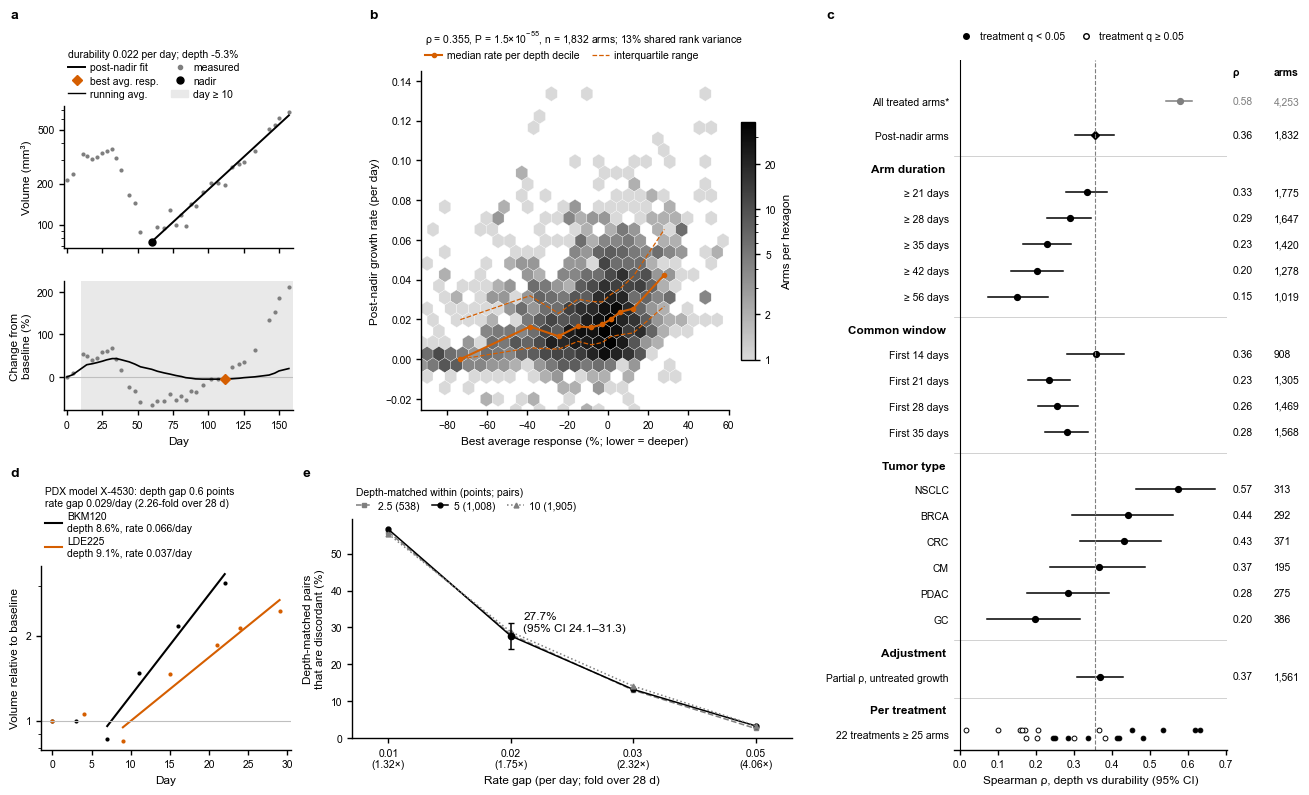

  saved outputs\figures\Figure_1.{pdf,eps,tiff}  (327 mm wide; smallest text 7.5 pt, 4.1 pt at 180 mm)   BELOW THE MINIMUM


In [5]:
# ==========================================================================
# Figure 1: depth and durability
# a  Both endpoints defined on one real arm: the post-nadir arm with at least
#    eight measurements closest to the median of both endpoints in rank space.
# b  The two endpoints across all post-nadir arms (central 98% of each axis),
#    with the median rate in each depth decile and its interquartile range.
# c  Sensitivity of the correlation (the rows of depth_durability_sensitivity).
#    Intervals resample PDX models and appear only in the figure.
# d  One real pair within a PDX model: equal depth, different durability.
# e  Share of depth-matched pairs that are discordant, against both thresholds,
#    with the interval of 4.4 redrawn with the analysis seed.
# ==========================================================================

def draw_figure_1():
    print("FIG. 1")
    sensitivity = FROZEN["depth_durability_sensitivity"]
    pair_sweep = FROZEN["pair_threshold_sweep"]

    # ---- a: choose the arm ------------------------------------------------------
    # Percentile ranks are taken over all post-nadir arms. The arm must also show
    # what durability measures: at least eight measurements, three after the
    # nadir and a positive post-nadir slope. The drawing recomputes best average
    # response from the canonical table, so an arm is used only when the
    # recomputed value matches the saved one within 0.1 points (and its
    # post-nadir rate matches within 0.1%); the next-closest arm is taken otherwise.
    endpoint_ranks = post_nadir_arms[[DEPTH, DURABILITY]].rank(pct=True)
    example_candidates = (post_nadir_arms.assign(rank_distance=((endpoint_ranks - 0.5) ** 2).sum(axis=1))
                          .loc[lambda frame: (frame.n_measurements >= 8) & (frame.n_after_nadir >= 3)
                               & (frame.post_nadir_growth_rate > 0)]
                          .sort_values("rank_distance"))

    def example_drawing(arm_row):
        """Everything panel a draws for one arm, recomputed from the canonical table."""
        day, volume = arm_curve(observations, arm_row.arm_id)
        change = 100.0 * (volume / volume[0] - 1.0)                                  # ΔVol, %
        running = np.cumsum(change) / np.arange(1, len(change) + 1)
        window = day >= MIN_DAY_FOR_BEST_AVERAGE_RESPONSE
        response_gap = (abs(running[window].min() - arm_row.best_average_response) if window.any() else np.inf)
        rate = summarize_regrowth(day, np.log(volume))["post_nadir_growth_rate"]
        rate_gap = abs(rate - arm_row.post_nadir_growth_rate) / max(abs(arm_row.post_nadir_growth_rate), 1e-9)
        return {"day": day, "volume": volume, "change": change, "running": running, "window": window,
                "response_gap": response_gap, "rate_gap": rate_gap, "floored": volume.min() <= VOLUME_FLOOR}

    # Take the closest arm whose drawing reproduces both saved endpoints. If none
    # of the closest 40 does, take the one that comes nearest and say so.
    example, drawing, skipped_examples, fallback = None, None, 0, None
    for position, row in enumerate(example_candidates.itertuples()):
        candidate = example_drawing(row)
        if candidate["floored"]:
            skipped_examples += 1
            continue
        if candidate["response_gap"] <= 0.1 and candidate["rate_gap"] <= 1e-3:
            example, drawing = row, candidate
            break
        score = candidate["response_gap"] + 100 * candidate["rate_gap"]
        if position < 40 and (fallback is None or score < fallback[0]):
            fallback = (score, row, candidate)
        skipped_examples += 1
    if example is None:
        if fallback is None:
            raise RuntimeError("no post-nadir arm with >= 8 measurements, >= 3 after the nadir, a positive "
                               "post-nadir rate and no reading at the volume floor")
        _, example, drawing = fallback
        print(f"  a  WARNING: no candidate reproduced both saved endpoints exactly; using {example.arm_id}, "
              f"whose recomputed best average response differs by {drawing['response_gap']:.2f} points and "
              f"post-nadir rate by {100 * drawing['rate_gap']:.2f}%. The legend shows the saved values.")
    example_day, example_volume = drawing["day"], drawing["volume"]
    example_change, example_running = drawing["change"], drawing["running"]
    in_response_window = drawing["window"]
    example_nadir, example_slope, example_intercept = post_nadir_line(example_day, np.log(example_volume))
    best_index = int(np.flatnonzero(in_response_window)[np.argmin(example_running[in_response_window])])
    print(f"  a  {example.arm_id}: {example.n_measurements} measurements; percentile ranks "
          f"{endpoint_ranks.loc[example.Index, DEPTH]:.2f} (depth), "
          f"{endpoint_ranks.loc[example.Index, DURABILITY]:.2f} (durability); "
          f"{skipped_examples} closer arm(s) skipped (a reading at the volume floor, or the recomputed "
          f"response differed from the saved one)")

    # ---- d: choose the pair -----------------------------------------------------
    # treatment_pairs (Section 1.4) holds the pairs of 4.4 with their arm
    # identifiers, already checked against the saved pairs.
    discordant_pairs = treatment_pairs.loc[treatment_pairs.discordant]
    median_rate_gap = float(discordant_pairs.growth_rate_gap.median())
    example_pair = (discordant_pairs.assign(distance=(discordant_pairs.growth_rate_gap - median_rate_gap).abs())
                    .sort_values(["distance", "response_gap"]).iloc[0])
    print(f"  d  {example_pair.arm_a}  vs  {example_pair.arm_b}: depth gap {example_pair.response_gap:.1f} points, "
          f"rate gap {example_pair.growth_rate_gap:.4f} per day (median rate gap of the "
          f"{len(discordant_pairs)} discordant pairs {median_rate_gap:.4f})")

    # ---- e: the discordant share and its interval -------------------------------
    # The register holds the share but not its interval, so the interval of 4.4
    # is redrawn: same statistic, same pairs in the same order, same seed and
    # replicate count, which gives the analysis interval exactly.
    matched_values = treatment_pairs.depth_matched.to_numpy()
    discordant_values = treatment_pairs.discordant.to_numpy()
    discordant_share = discordant_values.sum() / matched_values.sum()
    assert np.isclose(discordant_share, RESULTS["discordant_share"])
    pair_draws = cluster_bootstrap(
        rows_by_cluster(treatment_pairs.model_id),
        lambda rows: discordant_values[rows].sum() / max(matched_values[rows].sum(), 1),
        N_BOOTSTRAP, np.random.default_rng(ANALYSIS_SEEDS["pair_bootstrap"]))
    pair_low, pair_high = np.percentile(pair_draws, [2.5, 97.5])
    print(f"  e  discordant share {100 * discordant_share:.1f}% (95% CI {100 * pair_low:.1f} to "
          f"{100 * pair_high:.1f}), the interval of 4.4")

    # ---- c: rows of the forest plot and their intervals --------------------------
    # Window rows are recomputed here (4.3 keeps only the two endpoints), with
    # the PDX model kept so that the interval can resample models; each is
    # checked against the saved sensitivity table.
    window_frames = {}
    for window_days in (14, 21, 28, 35):
        window_rows = []
        for arm_id, block in arm_series(observations.loc[~observations.is_control.astype(bool)]):
            block = block.loc[block.day <= window_days]
            summary = summarize_regrowth(block.day.to_numpy(float), block.log_volume.to_numpy(float))
            if (summary is None or summary["nadir_index"] == 0
                    or summary["n_after_nadir"] < MIN_POINTS_AFTER_NADIR):
                continue
            response = utils.best_average_response(block.day.to_numpy(float), block.volume.to_numpy(float),
                                                   min_day=MIN_DAY_FOR_BEST_AVERAGE_RESPONSE)
            if np.isfinite(response):
                window_rows.append((block.model_id.iloc[0], response, summary["post_nadir_growth_rate"]))
        window_frames[window_days] = pd.DataFrame(window_rows, columns=["model_id", DEPTH, DURABILITY])
        table_row = sensitivity.loc[(sensitivity.analysis == "common observation window")
                                    & (sensitivity.subset == f"first {window_days} days")].iloc[0]
        assert len(window_frames[window_days]) == table_row.n_arms
        assert np.isclose(spearman(window_frames[window_days][DEPTH], window_frames[window_days][DURABILITY])[0],
                          table_row.spearman_rho)

    adjusted_arms = post_nadir_arms.assign(untreated_growth=post_nadir_arms.model_id.map(untreated_growth)
                                           ).dropna(subset=["untreated_growth"])
    assert np.isclose(partial_rank_correlation(adjusted_arms), RESULTS["partial_rho_untreated_growth"])
    tumor_table = sensitivity.loc[sensitivity.analysis == "tumor type"].sort_values("spearman_rho", ascending=False)
    treatment_table = sensitivity.loc[sensitivity.analysis.str.startswith("treatment")]
    forest_rows = [
        {"group": "reference", "label": "All treated arms", "frame": treated_with_endpoints},
        {"group": "primary", "label": "Post-nadir arms (primary)", "frame": post_nadir_arms},
        *[{"group": "duration", "label": f"Followed ≥ {days} days",
           "frame": post_nadir_arms.loc[post_nadir_arms.duration_days >= days]} for days in (21, 28, 35, 42, 56)],
        *[{"group": "window", "label": f"First {days} days only", "frame": window_frames[days]}
          for days in (14, 21, 28, 35)],
        *[{"group": "tumor type", "label": row.subset,
           "frame": post_nadir_arms.loc[post_nadir_arms.tumor_type == row.subset]} for row in tumor_table.itertuples()],
        {"group": "partial", "label": "Partial, adjusted for untreated growth", "frame": adjusted_arms},
    ]
    correlation_rng = np.random.default_rng(FIGURE_SEEDS["figure_1_correlation_bootstrap"])
    for row in forest_rows:
        frame = row["frame"].reset_index(drop=True)
        if row["group"] == "partial":
            row["estimate"] = partial_rank_correlation(frame)
            statistic = lambda rows, frame=frame: partial_rank_correlation(frame.iloc[rows])
        else:
            depth_values, rate_values = frame[DEPTH].to_numpy(float), frame[DURABILITY].to_numpy(float)
            row["estimate"] = spearman(depth_values, rate_values)[0]
            statistic = lambda rows, x=depth_values, y=rate_values: spearman(x[rows], y[rows])[0]
        draws = cluster_bootstrap(rows_by_cluster(frame.model_id.astype(str)), statistic, N_BOOTSTRAP,
                                  correlation_rng)
        row["low"], row["high"] = np.percentile(draws, [2.5, 97.5])
        row["n"] = len(frame)
    assert np.isclose(forest_rows[1]["estimate"], RESULTS["depth_durability_rho"])
    print("  c  ρ with 95% intervals resampling PDX models (figure only):")
    for row in forest_rows:
        print(f"       {row['label']:<42} {row['estimate']:.3f} ({row['low']:.3f} to {row['high']:.3f}), "
              f"n = {row['n']:,}")

    # ---- the figure ---------------------------------------------------------------
    figure = main_figure(200, wspace=0.09, width_mm=330)
    outer = figure.add_gridspec(1, 2, width_ratios=[2.9, 1.0])
    left = outer[0].subgridspec(2, 2, width_ratios=[1.0, 1.05], wspace=0.22)
    grid_a = left[0, 0].subgridspec(2, 1, height_ratios=[1.1, 1.0])
    axis_a_top = figure.add_subplot(grid_a[0])
    axis_a_bottom = figure.add_subplot(grid_a[1], sharex=axis_a_top)
    axis_b = figure.add_subplot(left[0, 1])
    axis_c = figure.add_subplot(outer[1])
    axis_d = figure.add_subplot(own_cell(left[1, 0]))
    axis_e = figure.add_subplot(own_cell(left[1, 1]))
    shade = tint(COLORS["light"], 0.35)

    # a, top: volume, nadir and the post-nadir line
    nadir_day = example_day[example_nadir]
    fitted_days = example_day[example_nadir:]
    axis_a_top.plot(example_day, example_volume, "o", color=COLORS["reference"], markersize=3, markeredgewidth=0)
    axis_a_top.plot(fitted_days, np.exp(example_intercept + example_slope * (fitted_days - nadir_day)),
                    color=COLORS["ink"], linewidth=1.4)
    axis_a_top.plot(nadir_day, example_volume[example_nadir], "o", color=COLORS["ink"], markersize=5)
    axis_a_top.set_yscale("log")
    plain_log_axis(axis_a_top)
    axis_a_top.set_ylabel("Volume (mm³)")
    axis_a_top.tick_params(labelbottom=False)

    # a, bottom: percent change, its running average and the best average response
    axis_a_bottom.axvspan(MIN_DAY_FOR_BEST_AVERAGE_RESPONSE, example_day.max() + 3, color=shade, linewidth=0, zorder=0)
    axis_a_bottom.axhline(0, color=COLORS["light"], linewidth=0.8)
    axis_a_bottom.plot(example_day, example_change, "o", color=COLORS["reference"], markersize=3, markeredgewidth=0)
    axis_a_bottom.plot(example_day, example_running, color=COLORS["ink"], linewidth=1.2)
    axis_a_bottom.plot(example_day[best_index], example_running[best_index], "D", color=COLORS["fourth"],
                       markersize=5, zorder=4)
    axis_a_bottom.set_xlim(example_day.min() - 2, example_day.max() + 3)
    axis_a_bottom.set_xlabel("Day")
    axis_a_bottom.set_ylabel("Change from\nbaseline (%)")
    legend_above(axis_a_top, ncols=2, title=f"durability {example.post_nadir_growth_rate:.3f} per day; "
                 f"depth {example.best_average_response:.1f}%", handles=[
        Line2D([], [], color=COLORS["ink"], linewidth=1.4, label="post-nadir fit"),
        Line2D([], [], marker="D", linestyle="", color=COLORS["fourth"], markersize=5, label="best avg. resp."),
        Line2D([], [], color=COLORS["ink"], linewidth=1.0, label="running avg."),
        Line2D([], [], marker="o", linestyle="", color=COLORS["reference"], markersize=3, label="measured"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=5, label="nadir"),
        Patch(color=shade, label=f"day ≥ {MIN_DAY_FOR_BEST_AVERAGE_RESPONSE}")])

    # b: hexbin of the two endpoints, central 98% of each axis
    depth_values = post_nadir_arms[DEPTH].to_numpy(float)
    rate_values = post_nadir_arms[DURABILITY].to_numpy(float)
    depth_low, depth_high = np.percentile(depth_values, [1, 99])
    rate_low, rate_high = np.percentile(rate_values, [1, 99])
    on_scale = ((depth_values >= depth_low) & (depth_values <= depth_high)
                & (rate_values >= rate_low) & (rate_values <= rate_high))
    hexes = axis_b.hexbin(depth_values[on_scale], rate_values[on_scale], gridsize=26,
                          extent=(depth_low, depth_high, rate_low, rate_high), cmap=gray_ramp(),
                          mincnt=1, bins="log", linewidths=0.2, edgecolors="white")
    # Deciles of depth over all arms (ties broken by order, so the bins are
    # always ten and never fail on repeated values).
    decile = pd.qcut(pd.Series(depth_values).rank(method="first"), 10, labels=False)
    decile_summary = pd.DataFrame({"decile": decile, "depth": depth_values, "rate": rate_values}).groupby(
        "decile").agg(depth=("depth", "median"), median=("rate", "median"),
                      q25=("rate", lambda v: v.quantile(0.25)), q75=("rate", lambda v: v.quantile(0.75)))
    axis_b.plot(decile_summary.depth, decile_summary.q25, color=COLORS["fourth"], linewidth=0.9, linestyle="--")
    axis_b.plot(decile_summary.depth, decile_summary.q75, color=COLORS["fourth"], linewidth=0.9, linestyle="--")
    axis_b.plot(decile_summary.depth, decile_summary["median"], "-o", color=COLORS["fourth"], markersize=3,
                linewidth=1.5)
    rho_b, p_b = spearman(depth_values, rate_values)
    axis_b.set_xlim(depth_low, depth_high)
    axis_b.set_ylim(rate_low, rate_high)
    axis_b.set_xlabel("Best average response (%; lower = deeper)")
    axis_b.set_ylabel("Post-nadir growth rate (per day)")
    legend_above(axis_b, title=f"ρ = {rho_b:.3f}, P = {figure_p(p_b)}, n = {len(depth_values):,} arms; "
                 f"{100 * rho_b ** 2:.0f}% shared rank variance", handles=[
                     Line2D([], [], color=COLORS["fourth"], marker="o", markersize=3, linewidth=1.5,
                            label="median rate per depth decile"),
                     Line2D([], [], color=COLORS["fourth"], linewidth=0.9, linestyle="--", label="interquartile range")],
                 ncols=2)
    colorbar = figure.colorbar(hexes, ax=axis_b, location="right", shrink=0.7, aspect=16, pad=0.02)
    colorbar.set_label("Arms per hexagon")
    colorbar.ax.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    colorbar.ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{value:g}"))
    colorbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    print(f"  b  {int((~on_scale).sum())} of {len(depth_values):,} arms lie outside the 1st–99th percentile "
          f"view of either axis (not drawn; included in ρ and in the decile medians)")

    # c: forest plot
    group_order = ["reference", "primary", "duration", "window", "tumor type", "partial", "treatment"]
    group_titles = {"duration": "Arm duration", "window": "Common window", "tumor type": "Tumor type",
                    "partial": "Adjustment", "treatment": "Per treatment"}
    short_labels = {"All treated arms": "All treated arms*", "Post-nadir arms (primary)": "Post-nadir arms",
                    "Partial, adjusted for untreated growth": "Partial ρ, untreated growth"}
    position, positions, separators, headers = 0.0, [], [], []
    for group in group_order:
        if group != "reference":
            separators.append(position - 0.2)
            position += 0.3
        if group in group_titles:
            headers.append((position, group_titles[group]))
            position += 0.9
        if group == "treatment":
            positions.append(("treatment", position))
            position += 1.0
            continue
        for row in forest_rows:
            if row["group"] == group:
                positions.append((row, position))
                position += 1.0
    labels, label_positions = [], []
    for row, y in positions:
        if row == "treatment":
            q_values = treatment_table.q_value.to_numpy(float)
            rho_values = treatment_table.spearman_rho.to_numpy(float)
            offsets = np.where(np.arange(len(rho_values)) % 2 == 0, -0.17, 0.17)
            significant = q_values < 0.05
            axis_c.scatter(rho_values[significant], y + offsets[significant], s=12, color=COLORS["ink"],
                           linewidth=0.6, zorder=3)
            axis_c.scatter(rho_values[~significant], y + offsets[~significant], s=12, facecolor="white",
                           edgecolor=COLORS["ink"], linewidth=0.7, zorder=3)
            labels.append(f"{len(rho_values)} treatments ≥ 25 arms")
            label_positions.append(y)
            continue
        color = COLORS["reference"] if row["group"] == "reference" else COLORS["ink"]
        marker = "D" if row["group"] == "primary" else "o"
        axis_c.plot([row["low"], row["high"]], [y, y], color=color, linewidth=1.1)
        axis_c.plot(row["estimate"], y, marker, color=color, markersize=4.2)
        axis_c.text(1.02, y, f"{row['estimate']:.2f}", transform=axis_c.get_yaxis_transform(), ha="left",
                    va="center", fontsize=7.5, color=color)
        axis_c.text(1.17, y, f"{row['n']:,}", transform=axis_c.get_yaxis_transform(), ha="left", va="center",
                    fontsize=7.5, color=color)
        labels.append(short_labels.get(row["label"], row["label"].replace("Followed ", "").replace(" only", "")))
        label_positions.append(y)
    for y, title in headers:
        axis_c.text(-0.03, y, title, transform=axis_c.get_yaxis_transform(), ha="right", va="center",
                    fontweight="bold")
    axis_c.text(1.02, -1.1, "ρ", transform=axis_c.get_yaxis_transform(), ha="left", va="center", fontsize=7.5,
                fontweight="bold")
    axis_c.text(1.17, -1.1, "arms", transform=axis_c.get_yaxis_transform(), ha="left", va="center", fontsize=7.5,
                fontweight="bold")
    for y in separators[1:]:
        axis_c.axhline(y, color=COLORS["light"], linewidth=0.5)
    axis_c.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_c.axvline(forest_rows[1]["estimate"], color=COLORS["reference"], linewidth=0.8, linestyle="--")
    axis_c.set_yticks(label_positions, labels)
    axis_c.tick_params(axis="y", length=0)
    axis_c.set_ylim(position - 0.4, -1.6)
    axis_c.set_xlabel("Spearman ρ, depth vs durability (95% CI)")
    axis_c.spines["left"].set_visible(False)
    legend_above(axis_c, ncols=2, handles=[
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=4, label="treatment q < 0.05"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["ink"],
               markersize=4, label="treatment q ≥ 0.05")])

    # d: one depth-matched, durability-discordant pair. Each line is fitted to
    # the canonical table; a drawn slope that differs from the saved rate is
    # reported (the legend shows the saved values).
    pair_table = post_nadir_arms.set_index("arm_id")
    for arm_id, color in ((example_pair.arm_a, COLORS["ink"]), (example_pair.arm_b, COLORS["fourth"])):
        arm_row = pair_table.loc[arm_id]
        pair_day, pair_volume = arm_curve(observations, arm_id)
        relative_volume = pair_volume / pair_volume[0]
        pair_nadir, pair_slope, pair_intercept = post_nadir_line(pair_day, np.log(relative_volume))
        if not np.isclose(pair_slope, arm_row.post_nadir_growth_rate, rtol=1e-3, atol=1e-6):
            print(f"  d  note: drawn slope of {arm_id} is {pair_slope:.4f}, saved rate "
                  f"{arm_row.post_nadir_growth_rate:.4f}")
        axis_d.plot(pair_day, relative_volume, "o", color=color, markersize=3, markeredgewidth=0)
        line_days = pair_day[pair_nadir:]
        axis_d.plot(line_days, np.exp(pair_intercept + pair_slope * (line_days - pair_day[pair_nadir])),
                    color=color, linewidth=1.5,
                    label=f"{arm_row.treatment}\ndepth {arm_row.best_average_response:.1f}%, "
                          f"rate {arm_row.post_nadir_growth_rate:.3f}/day")
    axis_d.axhline(1, color=COLORS["light"], linewidth=0.8)
    axis_d.set_yscale("log")
    plain_log_axis(axis_d)
    axis_d.set_xlabel("Day")
    axis_d.set_ylabel("Volume relative to baseline")
    legend_above(axis_d, ncols=1, title=f"PDX model {example_pair.model_id}: depth gap "
                 f"{example_pair.response_gap:.1f} points\nrate gap {example_pair.growth_rate_gap:.3f}/day "
                 f"({np.exp(example_pair.growth_rate_gap * PAIR_HORIZON_DAYS):.2f}-fold over {PAIR_HORIZON_DAYS} d)")

    # e: discordant share against both thresholds (thresholds evenly spaced)
    rate_ticks = sorted(pair_sweep["rate gap (per day)"].unique())
    rate_position = {gap: index for index, gap in enumerate(rate_ticks)}
    for tolerance, color, marker, style in ((2.5, COLORS["reference"], "s", "--"), (5.0, COLORS["ink"], "o", "-"),
                                            (10.0, COLORS["reference"], "^", ":")):
        subset = pair_sweep.loc[pair_sweep["response tolerance (points)"] == tolerance]
        label = f"{tolerance:g} ({int(subset['depth-matched pairs'].iloc[0]):,})"
        axis_e.plot(subset["rate gap (per day)"].map(rate_position), 100 * subset["share of depth-matched"],
                    linestyle=style, marker=marker, markersize=3.5, color=color, linewidth=1.1, label=label)
    axis_e.errorbar([rate_position[GROWTH_RATE_GAP]], [100 * discordant_share],
                    yerr=100 * interval_errors(discordant_share, pair_low, pair_high),
                    fmt="o", color=COLORS["ink"], markersize=4.5, capsize=2.5, linewidth=1.1, zorder=4)
    axis_e.set_xticks([rate_position[gap] for gap in rate_ticks],
                      [f"{gap:g}\n({np.exp(gap * PAIR_HORIZON_DAYS):.2f}×)" for gap in rate_ticks])
    axis_e.set_xlim(-0.3, len(rate_ticks) - 0.7)
    axis_e.set_xlabel(f"Rate gap (per day; fold over {PAIR_HORIZON_DAYS} d)")
    axis_e.set_ylabel("Depth-matched pairs\nthat are discordant (%)")
    axis_e.set_ylim(0, None)
    legend_above(axis_e, ncols=3, title="Depth-matched within (points; pairs)")
    axis_e.annotate(f"{100 * discordant_share:.1f}%\n(95% CI {100 * pair_low:.1f}–{100 * pair_high:.1f})",
                    (rate_position[GROWTH_RATE_GAP], 100 * discordant_share), xytext=(9, 2),
                    textcoords="offset points", ha="left", va="bottom").set_in_layout(False)

    add_panel_letters(figure, [[([axis_a_top, axis_a_bottom], "a"), (axis_b, "b"), (axis_c, "c")],
                               [(axis_d, "d"), (axis_e, "e")]])
    save_figure(figure, "depth_durability")


if 1 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 1", draw_figure_1, requires=("arm_endpoints", "observations_canonical", "treatment_pairs",
                                              "depth_durability_sensitivity", "pair_threshold_sweep"),
         style=MAIN_FIGURE_STYLE)

FIG. 2
  a  X-129 || HDM201: |trajectory-set error| 0.268 log units (median 0.268)
  e  trajectory set lower regret in 35 models, depth set lower in 31, equal in 64 (same arm chosen in 64); the 10 largest differences sum to 88% of the net reduction in summed regret
  f  X-1270 (trajectory better): regret depth 0.611, trajectory 0.000; median difference in this group 0.611, 35 models
  g  X-1586 (depth better): regret depth 0.536, trajectory 0.764; median difference in this group -0.229, 31 models
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_2.png, .tiff and .eps


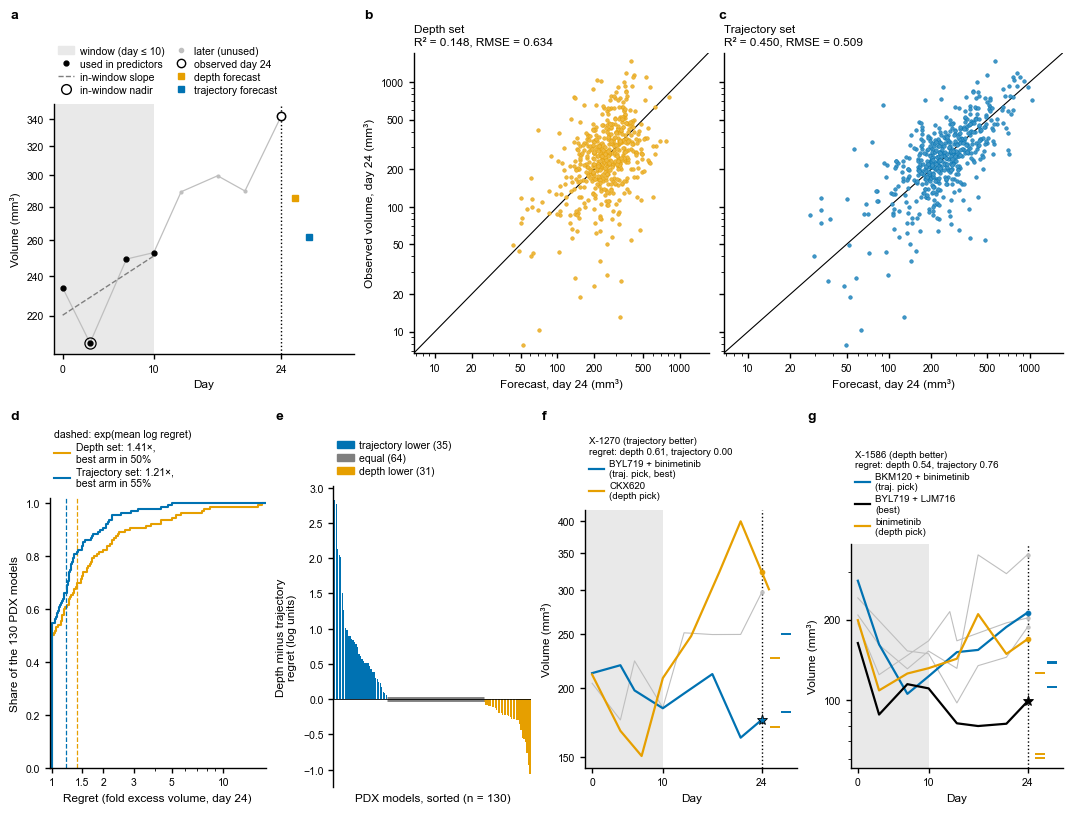

  saved outputs\figures\Figure_2.{pdf,eps,tiff}  (267 mm wide; smallest text 7.0 pt, 4.7 pt at 180 mm)   BELOW THE MINIMUM


In [6]:
# ==========================================================================
# Figure 2: forecasting and treatment selection
# a  The forecasting design on one arm (the arm whose absolute trajectory-set
#    error is closest to the median absolute error).
# b, c  Observed against out-of-fold predicted day-24 volume, depth set (b)
#    and trajectory set (c), on shared axes.
# d  Regret across PDX models as cumulative distributions.
# e  Per-model regret difference (depth minus trajectory), sorted.
# f, g  Two worked examples among the models where the sets chose
#    differently: the median model where the trajectory set did better (f)
#    and the median model where the depth set did better (g).
# ==========================================================================

def draw_figure_2():
    print("FIG. 2")
    SET_COLORS = {"depth": COLORS["depth"], "trajectory": COLORS["trajectory"]}
    SET_NAMES = {"depth": "Depth set", "trajectory": "Trajectory set"}
    selection = FROZEN["forecast_predictions"]            # the arms of 7.2 with both predictions
    regret = FROZEN["treatment_selection_regret"]
    outcome = selection.outcome_log_volume.to_numpy(float)
    depth_prediction = selection.depth_prediction.to_numpy(float)
    trajectory_prediction = selection.trajectory_prediction.to_numpy(float)
    predictions_by_set = {"depth": depth_prediction, "trajectory": trajectory_prediction}
    assert np.isclose(rmse(outcome, depth_prediction), RESULTS["depth_rmse"])
    assert np.isclose(rmse(outcome, trajectory_prediction), RESULTS["trajectory_rmse"])

    # ---- a: choose the arm ------------------------------------------------------------
    absolute_error = np.abs(trajectory_prediction - outcome)
    design_index = int(np.argmin(np.abs(absolute_error - np.median(absolute_error))))
    design_arm = selection.iloc[design_index]
    print(f"  a  {design_arm.arm_id}: |trajectory-set error| {absolute_error[design_index]:.3f} log units "
          f"(median {np.median(absolute_error):.3f})")

    # ---- e: per-model regret difference -------------------------------------------------
    regret_difference = (regret.depth_prediction_regret - regret.trajectory_prediction_regret).to_numpy(float)
    trajectory_better = regret_difference > 0
    depth_better = regret_difference < 0
    tied = ~trajectory_better & ~depth_better
    total_gain = regret_difference.sum()
    top_ten_share = np.sort(regret_difference)[::-1][:10].sum() / total_gain if total_gain > 0 else np.nan
    different_choice = regret.different_choice.astype(bool)
    print(f"  e  trajectory set lower regret in {int(trajectory_better.sum())} models, depth set lower in "
          f"{int(depth_better.sum())}, equal in {int(tied.sum())} (same arm chosen in "
          f"{int((~different_choice).sum())}); the 10 largest differences sum to "
          f"{100 * top_ten_share:.0f}% of the net reduction in summed regret")

    # ---- f, g: choose the worked examples ------------------------------------------------
    # The regret table does not keep which arm each set chose, so the choices
    # are recomputed with the same rule as selection_by_model (idxmin of each
    # prediction) and checked against the saved regret.
    def model_choices(model_id):
        """Eligible arms of one PDX model with each set's choice and the best arm."""
        block = selection.loc[selection.model_id == model_id].copy()
        choices = {"depth": block.loc[block.depth_prediction.idxmin(), "arm_id"],
                   "trajectory": block.loc[block.trajectory_prediction.idxmin(), "arm_id"],
                   "best": block.loc[block.outcome_log_volume.idxmin(), "arm_id"]}
        return block, choices

    differing = regret.assign(difference=regret_difference).loc[different_choice]
    example_models = {}                                    # panel key -> (label, model row)
    for panel, label, subset in (("f", "trajectory better", differing.loc[differing.difference > 0]),
                                 ("g", "depth better", differing.loc[differing.difference < 0])):
        if subset.empty:
            print(f"  {panel}  no model where the {label.split(' better')[0]} set did better; that panel is left empty")
            continue
        median_difference = subset.difference.median()
        chosen_model = subset.iloc[int(np.argmin(np.abs(subset.difference.to_numpy() - median_difference)))]
        example_models[panel] = (label, chosen_model)
        print(f"  {panel}  {chosen_model.model_id} ({label}): regret depth "
              f"{chosen_model.depth_prediction_regret:.3f}, trajectory {chosen_model.trajectory_prediction_regret:.3f}; "
              f"median difference in this group {median_difference:.3f}, {len(subset)} models")

    # ---- the figure -------------------------------------------------------------------------
    figure = main_figure(205)
    outer = figure.add_gridspec(2, 1, height_ratios=[1.0, 1.05])
    row_1 = outer[0].subgridspec(1, 3)
    row_2 = outer[1].subgridspec(1, 4)
    axis_a = figure.add_subplot(own_cell(row_1[0]))
    axis_b = figure.add_subplot(own_cell(row_1[1]))
    axis_c = figure.add_subplot(own_cell(row_1[2]), sharex=axis_b, sharey=axis_b)
    axis_d = figure.add_subplot(own_cell(row_2[0]))
    axis_e = figure.add_subplot(own_cell(row_2[1]))
    axis_f = figure.add_subplot(own_cell(row_2[2]))
    axis_g = figure.add_subplot(own_cell(row_2[3]))
    window_color = tint(COLORS["light"], 0.35)

    # a: the design on one arm
    design_day, design_volume = arm_curve(observations, design_arm.arm_id)
    in_window = design_day <= FORECAST_ORIGIN_DAY
    axis_a.axvspan(design_day.min() - 1, FORECAST_ORIGIN_DAY, color=window_color, linewidth=0, zorder=0)
    axis_a.plot(design_day, design_volume, "-", color=COLORS["light"], linewidth=0.9, zorder=1)
    axis_a.plot(design_day[~in_window], design_volume[~in_window], "o", color=COLORS["light"], markersize=3,
                markeredgewidth=0, zorder=2)
    axis_a.plot(design_day[in_window], design_volume[in_window], "o", color=COLORS["ink"], markersize=3.5, zorder=3)
    window_day, window_log = design_day[in_window], np.log(design_volume[in_window])
    window_slope, window_intercept = np.polyfit(window_day, window_log, 1)
    axis_a.plot(window_day, np.exp(window_intercept + window_slope * window_day), color=COLORS["reference"],
                linewidth=1.0, linestyle="--", zorder=3)
    window_nadir = int(np.argmin(window_log))
    axis_a.plot(window_day[window_nadir], np.exp(window_log[window_nadir]), "o", markersize=8,
                markerfacecolor="none", markeredgecolor=COLORS["ink"], markeredgewidth=0.9, zorder=4)
    axis_a.axvline(FORECAST_HORIZON_DAY, color=COLORS["ink"], linestyle=":", linewidth=1.0)
    axis_a.plot(FORECAST_HORIZON_DAY, np.exp(design_arm.outcome_log_volume), "o", markersize=6,
                markerfacecolor="white", markeredgecolor=COLORS["ink"], markeredgewidth=1.1, zorder=5)
    for offset, key in ((1.5, "depth"), (3.0, "trajectory")):
        axis_a.plot(FORECAST_HORIZON_DAY + offset, np.exp(predictions_by_set[key][design_index]), "s",
                    color=SET_COLORS[key], markersize=5, zorder=5)
    axis_a.set_yscale("log")
    plain_log_axis(axis_a)
    axis_a.set_xlim(design_day.min() - 1, FORECAST_HORIZON_DAY + 8)
    axis_a.set_xticks([0, FORECAST_ORIGIN_DAY, FORECAST_HORIZON_DAY])
    axis_a.set_xlabel("Day")
    axis_a.set_ylabel("Volume (mm³)")
    legend_above(axis_a, ncols=2, columnspacing=0.8, handles=[
        Patch(color=window_color, label=f"window (day ≤ {FORECAST_ORIGIN_DAY})"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=3.5, label="used in predictors"),
        Line2D([], [], color=COLORS["reference"], linestyle="--", label="in-window slope"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=COLORS["ink"],
               markersize=7, label="in-window nadir"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["light"], markersize=3, label="later (unused)"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["ink"],
               markersize=6, label=f"observed day {FORECAST_HORIZON_DAY}"),
        Line2D([], [], marker="s", linestyle="", color=SET_COLORS["depth"], markersize=5, label="depth forecast"),
        Line2D([], [], marker="s", linestyle="", color=SET_COLORS["trajectory"], markersize=5,
               label="trajectory forecast")])

    # b, c: observed against predicted, shared axes
    volume_limits = np.exp([min(outcome.min(), depth_prediction.min(), trajectory_prediction.min()) - 0.15,
                            max(outcome.max(), depth_prediction.max(), trajectory_prediction.max()) + 0.15])
    for axis, key in ((axis_b, "depth"), (axis_c, "trajectory")):
        predicted = predictions_by_set[key]
        axis.plot(volume_limits, volume_limits, color=COLORS["ink"], linewidth=0.8, zorder=1)
        axis.scatter(np.exp(predicted), np.exp(outcome), s=7, color=tint(SET_COLORS[key], 0.75),
                     edgecolor=SET_COLORS[key], linewidth=0.3, zorder=2)
        axis.set_title(f"{SET_NAMES[key]}\nR² = {r2_score(outcome, predicted):.3f}, "
                       f"RMSE = {rmse(outcome, predicted):.3f}", loc="left")
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.set_xlabel(f"Forecast, day {FORECAST_HORIZON_DAY} (mm³)")
    axis_b.set_xlim(volume_limits)
    axis_b.set_ylim(volume_limits)
    plain_log_axis(axis_b, "x")
    plain_log_axis(axis_b, "y")
    axis_b.set_ylabel(f"Observed volume, day {FORECAST_HORIZON_DAY} (mm³)")
    axis_c.tick_params(labelleft=False)

    # d: regret as cumulative distributions, in fold excess volume. The dashed
    # line is exp(mean log regret), the fold change the register reports.
    largest_fold = float(np.exp(max(regret.depth_prediction_regret.max(), regret.trajectory_prediction_regret.max())))
    for key in ("depth", "trajectory"):
        values = np.sort(regret[f"{key}_prediction_regret"].to_numpy(float))
        shares = np.arange(1, len(values) + 1) / len(values)
        best_share = float(np.mean(values <= 1e-12))
        axis_d.step(np.exp(np.r_[0.0, values, np.log(largest_fold * 1.05)]), np.r_[0.0, shares, 1.0], where="post",
                    color=SET_COLORS[key], linewidth=1.5,
                    label=f"{SET_NAMES[key]}: {np.exp(values.mean()):.2f}×,\nbest arm in {100 * best_share:.0f}%")
        axis_d.axvline(np.exp(values.mean()), color=SET_COLORS[key], linewidth=0.9, linestyle="--")
    axis_d.set_xscale("log")
    axis_d.set_xlim(0.97, largest_fold * 1.05)
    fold_ticks = [fold for fold in (1, 1.5, 2, 3, 5, 10, 20) if fold <= largest_fold * 1.05]
    axis_d.set_xticks(fold_ticks, [f"{fold:g}" for fold in fold_ticks])
    axis_d.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    axis_d.set_ylim(0, 1.02)
    axis_d.set_xlabel(f"Regret (fold excess volume, day {FORECAST_HORIZON_DAY})")
    axis_d.set_ylabel(f"Share of the {len(regret)} PDX models")
    legend_above(axis_d, title="dashed: exp(mean log regret)")

    # e: per-model regret difference, sorted
    order = np.argsort(-regret_difference, kind="stable")
    sorted_difference = regret_difference[order]
    bar_colors = np.where(sorted_difference > 0, SET_COLORS["trajectory"],
                          np.where(sorted_difference < 0, SET_COLORS["depth"], COLORS["light"]))
    positions = np.arange(len(sorted_difference))
    axis_e.bar(positions, sorted_difference, width=0.85, color=bar_colors, linewidth=0)
    zero_run = positions[sorted_difference == 0]
    if len(zero_run):
        axis_e.plot([zero_run.min() - 0.4, zero_run.max() + 0.4], [0, 0], color=COLORS["reference"], linewidth=3.5,
                    solid_capstyle="butt")
    axis_e.axhline(0, color=COLORS["ink"], linewidth=0.6)
    axis_e.set_xlim(-1, len(sorted_difference))
    axis_e.set_xticks([])
    axis_e.spines["bottom"].set_visible(False)
    axis_e.set_xlabel(f"PDX models, sorted (n = {len(regret)})")
    axis_e.set_ylabel("Depth minus trajectory\nregret (log units)")
    legend_above(axis_e, ncols=1, handles=[
        Patch(color=SET_COLORS["trajectory"], label=f"trajectory lower ({int(trajectory_better.sum())})"),
        Patch(color=COLORS["reference"], label=f"equal ({int(tied.sum())})"),
        Patch(color=SET_COLORS["depth"], label=f"depth lower ({int(depth_better.sum())})")])

    # f, g: worked examples, each in its own panel (an absent group leaves
    # its own panel empty with a note, whichever group it is)
    for panel, axis in (("f", axis_f), ("g", axis_g)):
        if panel not in example_models:
            axis.set_axis_off()
            group = "trajectory" if panel == "f" else "depth"
            axis.text(0.5, 0.5, f"No PDX model in which the {group}\nset's choice had lower regret",
                      transform=axis.transAxes, ha="center", va="center")
            continue
        label, chosen_model = example_models[panel]
        block, choices = model_choices(chosen_model.model_id)
        assert choices["depth"] != choices["trajectory"]
        best_outcome = block.outcome_log_volume.min()
        assert np.isclose(block.set_index("arm_id").outcome_log_volume[choices["depth"]] - best_outcome,
                          chosen_model.depth_prediction_regret)
        axis.axvspan(-1, FORECAST_ORIGIN_DAY, color=window_color, linewidth=0, zorder=0)
        axis.axvline(FORECAST_HORIZON_DAY, color=COLORS["ink"], linestyle=":", linewidth=1.0)
        handles = []
        for arm in sorted(block.itertuples(), key=lambda arm: arm.arm_id in choices.values()):
            is_depth, is_trajectory = arm.arm_id == choices["depth"], arm.arm_id == choices["trajectory"]
            is_best = arm.arm_id == choices["best"]
            color = (SET_COLORS["depth"] if is_depth else SET_COLORS["trajectory"] if is_trajectory
                     else COLORS["ink"] if is_best else COLORS["light"])
            highlighted = is_depth or is_trajectory or is_best
            arm_day, arm_volume = arm_curve(observations, arm.arm_id)
            visible = arm_day <= FORECAST_HORIZON_DAY + 2
            axis.plot(arm_day[visible], arm_volume[visible], "-", color=color, linewidth=1.6 if highlighted else 0.8,
                      zorder=3 if highlighted else 1)
            axis.plot(FORECAST_HORIZON_DAY, np.exp(arm.outcome_log_volume), "*" if is_best else "o", color=color,
                      markersize=8 if is_best else 3.5 if highlighted else 2.5,
                      markeredgecolor=COLORS["ink"] if is_best else color, markeredgewidth=0.6, zorder=5)
            if highlighted:
                axis.plot(FORECAST_HORIZON_DAY + 1.8, np.exp(arm.depth_prediction), marker="_",
                          color=SET_COLORS["depth"], markersize=7, markeredgewidth=1.4, zorder=4)
                axis.plot(FORECAST_HORIZON_DAY + 3.4, np.exp(arm.trajectory_prediction), marker="_",
                          color=SET_COLORS["trajectory"], markersize=7, markeredgewidth=1.4, zorder=4)
                role = ("depth pick" if is_depth else "traj. pick" if is_trajectory else "best")
                if is_best and (is_depth or is_trajectory):
                    role += ", best"
                handles.append(Line2D([], [], color=color, linewidth=1.6, label=f"{arm.treatment}\n({role})"))
        legend_above(axis, handles=handles, fontsize=7, title_fontsize=7,
                     title=f"{chosen_model.model_id} ({label})\nregret: depth {chosen_model.depth_prediction_regret:.2f}, "
                           f"trajectory {chosen_model.trajectory_prediction_regret:.2f}")
        axis.set_yscale("log")
        plain_log_axis(axis)
        axis.set_xlim(-1, FORECAST_HORIZON_DAY + 5)
        axis.set_xticks([0, FORECAST_ORIGIN_DAY, FORECAST_HORIZON_DAY])
        axis.set_xlabel("Day")
        axis.set_ylabel("Volume (mm³)")

    add_panel_letters(figure, [[(axis_a, "a"), (axis_b, "b"), (axis_c, "c")],
                               [(axis_d, "d"), (axis_e, "e"), (axis_f, "f"), (axis_g, "g")]])
    save_figure(figure, "forecasting")


if 2 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 2", draw_figure_2, requires=("forecast_predictions", "treatment_selection_regret",
                                              "observations_canonical"), style=MAIN_FIGURE_STYLE)

FIG. 3
  g  all pairs: depth 0.639, trajectory 0.706, difference 6.8 points (95% CI 1.7 to 11.7; figure only)
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_3.png, .tiff and .eps


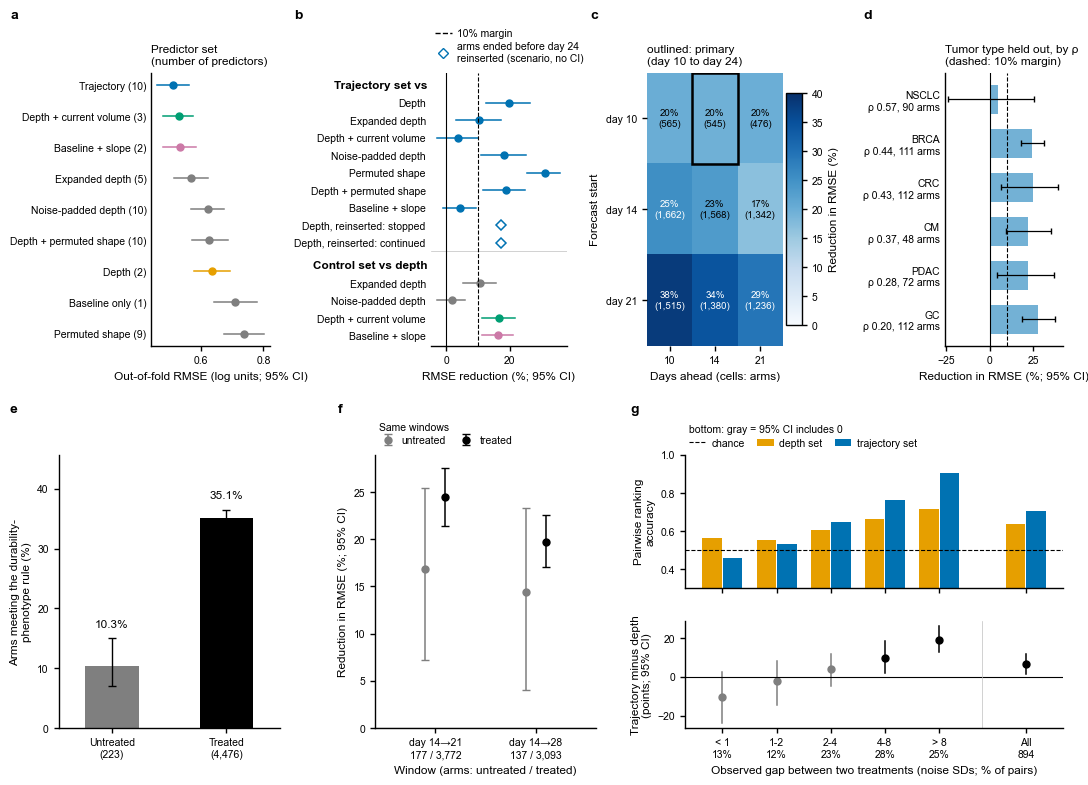

  saved outputs\figures\Figure_3.{pdf,eps,tiff}  (271 mm wide; smallest text 7.0 pt, 4.6 pt at 180 mm)   BELOW THE MINIMUM


In [7]:
# ==========================================================================
# Figure 3: controls
# a  Out-of-fold RMSE of every predictor set (95% CI resampling PDX models,
#    figure only).
# b  Relative RMSE reductions: trajectory set against each comparator, and
#    each control against depth; the two reinsertion scenarios as points.
#    The robustness sets of 8.1 (depth plus permuted shape, baseline plus
#    slope) are included when INCLUDE_ROBUSTNESS_CONTRASTS is set.
# c  Start day × days ahead (rolling_origins); each cell is its own set of arms.
# d  Each tumor type held out of training, ordered by its depth–durability ρ,
#    with the 95% interval of 8.1.
# e  Durability-phenotype rule in untreated against treated arms.
# f  Forecasting gain in untreated against treated arms over the same windows.
# g  Ranking accuracy by observed separation (top) and the trajectory-minus-
#    depth difference (bottom).
# ==========================================================================

INCLUDE_ROBUSTNESS_CONTRASTS = True


def draw_figure_3():
    print("FIG. 3")
    SET_COLORS = {"depth": COLORS["depth"], "trajectory": COLORS["trajectory"],
                  "depth plus current volume": COLORS["third"], "baseline plus slope": COLORS["fifth"]}
    SET_LABELS = {"depth": "Depth", "trajectory": "Trajectory", "baseline only": "Baseline only",
                  "expanded depth": "Expanded depth", "noise-padded depth": "Noise-padded depth",
                  "permuted shape": "Permuted shape", "depth plus current volume": "Depth + current volume",
                  "depth plus permuted shape": "Depth + permuted shape", "baseline plus slope": "Baseline + slope"}
    validation = FROZEN["forecast_predictions_all_sets"]
    predictor_set_performance = FROZEN["predictor_set_performance"]
    predictor_contrasts = FROZEN["predictor_contrasts"]
    censoring_scenarios = FROZEN["censoring_scenarios"]
    rolling_origins = FROZEN["rolling_origins"]
    tumor_type_holdout = FROZEN["tumor_type_holdout"]
    untreated_forecasting = FROZEN["untreated_forecasting"]
    untreated_controls = FROZEN["untreated_regrowth_summary"]
    regrowth = FROZEN["treated_regrowth_summary"]
    forecast_pairs = FROZEN["ranking_pairs"]
    separability = FROZEN["ranking_by_separation"]
    sensitivity = FROZEN["depth_durability_sensitivity"]
    set_outcome = validation.outcome_log_volume.to_numpy(float)
    set_predictions = {name: validation[f"prediction_{name.replace(' ', '_')}"].to_numpy(float)
                       for name in predictor_set_performance.predictor_set}
    for row in predictor_set_performance.itertuples():
        assert np.isclose(rmse(set_outcome, set_predictions[row.predictor_set]), row.rmse)

    # ---- a: RMSE of each set with an interval resampling PDX models --------------
    forecast_rows_by_model = rows_by_cluster(validation.model_id.astype(str))
    set_rng = np.random.default_rng(FIGURE_SEEDS["figure_3_set_bootstrap"])
    set_intervals = {}
    for name in predictor_set_performance.predictor_set:
        draws = cluster_bootstrap(forecast_rows_by_model,
                                  lambda rows, name=name: rmse(set_outcome[rows], set_predictions[name][rows]),
                                  N_BOOTSTRAP_CONTROLS, set_rng)
        set_intervals[name] = np.percentile(draws, [2.5, 97.5])

    # ---- e: phenotype shares, checked against 8.3(a) and 3.3 -------------------------
    untreated_hits, untreated_n = int(untreated_controls.durability_phenotype.astype(bool).sum()), len(untreated_controls)
    treated_hits, treated_n = int(regrowth.durability_phenotype.astype(bool).sum()), len(regrowth)
    assert np.isclose(untreated_hits / untreated_n, RESULTS["untreated_phenotype_share"])
    assert np.isclose(treated_hits / treated_n, RESULTS["treated_phenotype_share"])

    # ---- g: all-pairs accuracy difference with an interval ---------------------------
    all_depth = forecast_pairs.depth_prediction.to_numpy(float)
    all_trajectory = forecast_pairs.trajectory_prediction.to_numpy(float)
    assert np.isclose(all_depth.mean(), RESULTS["ranking_accuracy_depth"])
    all_draws = cluster_bootstrap(rows_by_cluster(forecast_pairs.model_id),
                                  lambda rows: all_trajectory[rows].mean() - all_depth[rows].mean(),
                                  N_BOOTSTRAP, np.random.default_rng(FIGURE_SEEDS["figure_3_ranking_bootstrap"]))
    all_low, all_high = np.percentile(all_draws, [2.5, 97.5])
    print(f"  g  all pairs: depth {all_depth.mean():.3f}, trajectory {all_trajectory.mean():.3f}, difference "
          f"{100 * (all_trajectory.mean() - all_depth.mean()):.1f} points (95% CI {100 * all_low:.1f} to "
          f"{100 * all_high:.1f}; figure only)")

    # ---- the figure -------------------------------------------------------------------
    figure = main_figure(200, wspace=0.09)
    outer = figure.add_gridspec(2, 1)
    row_1 = outer[0].subgridspec(1, 4, width_ratios=[1.0, 1.15, 1.15, 1.0])
    row_2 = outer[1].subgridspec(1, 4, wspace=0.22)
    axis_a = figure.add_subplot(row_1[0])
    axis_b = figure.add_subplot(row_1[1])
    axis_c = figure.add_subplot(row_1[2])
    axis_d = figure.add_subplot(row_1[3])
    axis_e = figure.add_subplot(row_2[0])
    axis_f = figure.add_subplot(row_2[1])
    grid_g = row_2[2:].subgridspec(2, 1, height_ratios=[1.25, 1.0])
    axis_g_top = figure.add_subplot(grid_g[0])
    axis_g_bottom = figure.add_subplot(grid_g[1], sharex=axis_g_top)

    # a: RMSE of every set, best at the top
    performance = predictor_set_performance.sort_values("rmse").reset_index(drop=True)
    for position, row in performance.iterrows():
        color = SET_COLORS.get(row.predictor_set, COLORS["reference"])
        low, high = set_intervals[row.predictor_set]
        axis_a.plot([low, high], [position, position], color=color, linewidth=1.1)
        axis_a.plot(row.rmse, position, "o", color=color, markersize=5)
    axis_a.set_yticks(range(len(performance)),
                      [f"{SET_LABELS.get(name, name)} ({count})" for name, count in
                       zip(performance.predictor_set, performance.predictors)])
    axis_a.invert_yaxis()
    axis_a.tick_params(axis="y", length=0)
    axis_a.set_xlabel("Out-of-fold RMSE (log units; 95% CI)")
    axis_a.set_title("Predictor set\n(number of predictors)", loc="left")

    # b: forest of relative reductions, plus the reinsertion scenarios
    contrast_table = predictor_contrasts.set_index(["baseline", "challenger"])
    trajectory_baselines = ["depth", "expanded depth", "depth plus current volume", "noise-padded depth",
                            "permuted shape"]
    control_challengers = ["expanded depth", "noise-padded depth", "depth plus current volume"]
    if INCLUDE_ROBUSTNESS_CONTRASTS:
        trajectory_baselines += ["depth plus permuted shape", "baseline plus slope"]
        control_challengers += ["baseline plus slope"]
    forest_entries = [("header", "Trajectory set vs")]
    forest_entries += [("contrast", baseline, "trajectory") for baseline in trajectory_baselines
                       if (baseline, "trajectory") in contrast_table.index]
    forest_entries += [("scenario", scenario) for scenario in censoring_scenarios.itertuples()]
    forest_entries.append(("header", "Control set vs depth"))
    forest_entries += [("contrast", "depth", challenger) for challenger in control_challengers
                       if ("depth", challenger) in contrast_table.index]
    labels, label_positions, y = [], [], 0.0
    for entry in forest_entries:
        if entry[0] == "header":
            if y > 0:
                axis_b.axhline(y - 0.5, color=COLORS["light"], linewidth=0.5)
                y += 0.3
            axis_b.text(-0.02, y, entry[1], transform=axis_b.get_yaxis_transform(), ha="right", va="center",
                        fontweight="bold")
            y += 1.0
            continue
        if entry[0] == "contrast":
            _, baseline, challenger = entry
            row = contrast_table.loc[(baseline, challenger)]
            color = SET_COLORS.get(challenger, COLORS["reference"])
            axis_b.plot([100 * row.low, 100 * row.high], [y, y], color=color, linewidth=1.1)
            axis_b.plot(100 * row.relative_reduction, y, "o", color=color, markersize=5)
            labels.append(SET_LABELS[baseline] if challenger == "trajectory" else SET_LABELS[challenger])
        else:
            scenario = entry[1]
            axis_b.plot(100 * scenario.relative_reduction, y, "D", markerfacecolor="white",
                        markeredgecolor=COLORS["trajectory"], markeredgewidth=1.1, markersize=5)
            labels.append(f"Depth, reinserted: {scenario.scenario.replace('growth ', '')}")
        label_positions.append(y)
        y += 1.0
    axis_b.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_b.axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linewidth=0.8, linestyle="--")
    axis_b.set_yticks(label_positions, labels)
    axis_b.tick_params(axis="y", length=0)
    axis_b.set_ylim(y - 0.4, -0.7)
    axis_b.spines["left"].set_visible(False)
    axis_b.set_xlabel("RMSE reduction (%; 95% CI)")
    legend_above(axis_b, ncols=1, handles=[
        Line2D([], [], color=COLORS["ink"], linestyle="--", label=f"{FORECAST_MARGIN:.0%} margin"),
        Line2D([], [], marker="D", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["trajectory"],
               markersize=5, label=f"arms ended before day {FORECAST_HORIZON_DAY}\nreinserted (scenario, no CI)")])

    # c: start day × days ahead. The color scale runs from 0 to the larger of
    # 40% and the largest reduction; a negative reduction switches the scale
    # to a diverging one centred on zero, so no cell is clipped silently.
    start_days = sorted(rolling_origins.start_day.unique())
    leads = sorted((rolling_origins.horizon_day - rolling_origins.start_day).unique())
    heat = np.full((len(start_days), len(leads)), np.nan)
    heat_arms = np.zeros_like(heat)
    for row in rolling_origins.itertuples():
        i, j = start_days.index(row.start_day), leads.index(row.horizon_day - row.start_day)
        heat[i, j], heat_arms[i, j] = row.relative_reduction, row.arms
    upper = max(40.0, 100 * np.nanmax(heat))
    if np.nanmin(heat) < 0:
        limit = max(upper, -100 * np.nanmin(heat))
        image = axis_c.imshow(100 * heat, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
        normalized = np.abs(heat * 100) / limit
    else:
        image = axis_c.imshow(100 * heat, cmap="Blues", vmin=0, vmax=upper, aspect="auto")
        normalized = heat * 100 / upper
    for i in range(len(start_days)):
        for j in range(len(leads)):
            if np.isfinite(heat[i, j]):
                axis_c.text(j, i, f"{100 * heat[i, j]:.0f}%\n({int(heat_arms[i, j]):,})", ha="center",
                            va="center", fontsize=7, color="white" if normalized[i, j] > 0.6 else COLORS["ink"])
    primary_lead = FORECAST_HORIZON_DAY - FORECAST_ORIGIN_DAY
    if FORECAST_ORIGIN_DAY in start_days and primary_lead in leads:
        primary_cell = (start_days.index(FORECAST_ORIGIN_DAY), leads.index(primary_lead))
        axis_c.add_patch(Rectangle((primary_cell[1] - 0.5, primary_cell[0] - 0.5), 1, 1, fill=False,
                                   edgecolor=COLORS["ink"], linewidth=1.8))
    axis_c.set_xticks(range(len(leads)), [f"{lead:g}" for lead in leads])
    axis_c.set_yticks(range(len(start_days)), [f"day {day:g}" for day in start_days])
    axis_c.set_xlabel("Days ahead (cells: arms)")
    axis_c.set_ylabel("Forecast start")
    axis_c.set_title(f"outlined: primary\n(day {FORECAST_ORIGIN_DAY} to day {FORECAST_HORIZON_DAY})", loc="left")
    for spine in axis_c.spines.values():
        spine.set_visible(False)
    colorbar = figure.colorbar(image, ax=axis_c, location="right", shrink=0.85, aspect=14, pad=0.02)
    colorbar.set_label("Reduction in RMSE (%)")

    # d: tumor types held out, ordered by depth–durability ρ (Fig. 1c), with
    # the interval of 8.1 (resampling held-out PDX models, predictions fixed)
    type_rho = sensitivity.loc[sensitivity.analysis == "tumor type"].set_index("subset").spearman_rho
    holdout = (tumor_type_holdout.assign(rho=tumor_type_holdout.held_out_tumor_type.map(type_rho))
               .sort_values("rho").reset_index(drop=True))
    axis_d.barh(range(len(holdout)), 100 * holdout.relative_reduction, color=tint(COLORS["trajectory"], 0.55),
                height=0.65)
    axis_d.errorbar(100 * holdout.relative_reduction, range(len(holdout)),
                    xerr=100 * interval_errors(holdout.relative_reduction, holdout.low, holdout.high),
                    fmt="none", ecolor=COLORS["ink"], capsize=2, linewidth=0.9)
    axis_d.axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linewidth=0.8, linestyle="--")
    axis_d.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_d.set_yticks(range(len(holdout)), [f"{row.held_out_tumor_type}\nρ {row.rho:.2f}, {int(row.test_arms)} arms"
                                            for row in holdout.itertuples()])
    axis_d.tick_params(axis="y", length=0)
    axis_d.set_xlim(min(0, 100 * holdout.low.min() - 2), 100 * holdout.high.max() + 3)
    axis_d.set_xlabel("Reduction in RMSE (%; 95% CI)")
    axis_d.set_title(f"Tumor type held out, by ρ\n(dashed: {FORECAST_MARGIN:.0%} margin)", loc="left")

    # e: durability-phenotype rule, untreated against treated
    for position, (label, hits, n, color) in enumerate((("Untreated", untreated_hits, untreated_n, COLORS["reference"]),
                                                        ("Treated", treated_hits, treated_n, COLORS["ink"]))):
        low, high = wilson_interval(hits, n)
        position = 1.5 * position
        axis_e.bar(position, 100 * hits / n, color=color, width=0.7)
        axis_e.errorbar(position, 100 * hits / n, yerr=100 * interval_errors(hits / n, low, high),
                        color=COLORS["ink"], capsize=3, linewidth=1.0)
        axis_e.text(position, 100 * high + 1.5, f"{100 * hits / n:.1f}%", ha="center", va="bottom")
    axis_e.set_xticks([0, 1.5], [f"Untreated\n({untreated_n:,})", f"Treated\n({treated_n:,})"])
    axis_e.set_xlim(-0.7, 2.2)
    axis_e.set_ylim(0, 100 * max(wilson_interval(treated_hits, treated_n)[1],
                                 wilson_interval(untreated_hits, untreated_n)[1]) * 1.25)
    axis_e.set_ylabel("Arms meeting the durability-\nphenotype rule (%)")

    # f: forecasting gain, untreated against treated, same windows
    windows = sorted({(row.start_day, row.horizon_day) for row in untreated_forecasting.itertuples()})
    arm_counts = {}
    for population, color, offset in (("untreated", COLORS["reference"], -0.1), ("treated", COLORS["ink"], 0.1)):
        rows = untreated_forecasting.loc[untreated_forecasting.population == population]
        x_positions = [windows.index((r.start_day, r.horizon_day)) + offset for r in rows.itertuples()]
        for r in rows.itertuples():
            arm_counts.setdefault((r.start_day, r.horizon_day), {})[population] = r.arms
        axis_f.errorbar(x_positions, 100 * rows.relative_reduction,
                        yerr=100 * interval_errors(rows.relative_reduction, rows.low, rows.high),
                        fmt="o", markersize=5, color=color, capsize=3, linewidth=1.1, label=population)
    axis_f.axhline(0, color=COLORS["ink"], linewidth=0.8)
    axis_f.set_xticks(range(len(windows)), [f"day {start}→{end}\n{arm_counts[(start, end)].get('untreated', 0):,} / "
                                            f"{arm_counts[(start, end)].get('treated', 0):,}" for start, end in windows])
    axis_f.set_xlabel("Window (arms: untreated / treated)")
    axis_f.set_xlim(-0.6, len(windows) - 0.4)
    axis_f.set_ylim(min(0, 100 * untreated_forecasting.low.min() - 3), None)
    axis_f.set_ylabel("Reduction in RMSE (%; 95% CI)")
    legend_above(axis_f, ncols=2, title="Same windows")

    # g: ranking accuracy by separation (top) and the difference (bottom)
    group_positions = list(range(len(separability))) + [len(separability) + 0.6]
    depth_accuracy = list(separability.depth_accuracy) + [all_depth.mean()]
    trajectory_accuracy = list(separability.trajectory_accuracy) + [all_trajectory.mean()]
    differences = list(separability.difference) + [all_trajectory.mean() - all_depth.mean()]
    lows = list(separability.low) + [all_low]
    highs = list(separability.high) + [all_high]
    axis_g_top.bar(np.array(group_positions) - 0.19, depth_accuracy, width=0.36, color=COLORS["depth"],
                   label="depth set")
    axis_g_top.bar(np.array(group_positions) + 0.19, trajectory_accuracy, width=0.36, color=COLORS["trajectory"],
                   label="trajectory set")
    axis_g_top.axhline(0.5, color=COLORS["ink"], linewidth=0.8, linestyle="--", label="chance")
    axis_g_top.set_ylim(min(0.3, np.nanmin(depth_accuracy + trajectory_accuracy) - 0.05), 1.0)
    axis_g_top.set_ylabel("Pairwise ranking\naccuracy")
    axis_g_top.tick_params(labelbottom=False)
    legend_above(axis_g_top, ncols=3, title="bottom: gray = 95% CI includes 0")
    for x, low, high, difference in zip(group_positions, lows, highs, differences):
        color = COLORS["ink"] if (low > 0 or high < 0) else COLORS["reference"]
        axis_g_bottom.plot([x, x], [100 * low, 100 * high], color=color, linewidth=1.1)
        axis_g_bottom.plot(x, 100 * difference, "o", color=color, markersize=5)
    axis_g_bottom.axhline(0, color=COLORS["ink"], linewidth=0.8)
    axis_g_bottom.axvline(len(separability) - 0.2, color=COLORS["light"], linewidth=0.5)
    axis_g_bottom.set_ylabel("Trajectory minus depth\n(points; 95% CI)")
    tick_labels = [f"{label}\n{100 * share:.0f}%" for label, share in
                   zip(separability.noise_sd_units, separability.share_of_pairs)] + [f"All\n{len(forecast_pairs):,}"]
    axis_g_bottom.set_xticks(group_positions, tick_labels)
    axis_g_bottom.set_xlabel("Observed gap between two treatments (noise SDs; % of pairs)")

    add_panel_letters(figure, [[(axis_a, "a"), (axis_b, "b"), (axis_c, "c"), (axis_d, "d")],
                               [(axis_e, "e"), (axis_f, "f"), ([axis_g_top, axis_g_bottom], "g")]])
    save_figure(figure, "controls")


if 3 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 3", draw_figure_3, requires=(
        "forecast_predictions_all_sets", "predictor_set_performance", "predictor_contrasts", "censoring_scenarios",
        "rolling_origins", "tumor_type_holdout", "untreated_forecasting", "untreated_regrowth_summary",
        "treated_regrowth_summary", "ranking_pairs", "ranking_by_separation"), style=MAIN_FIGURE_STYLE)

FIG. 4
  d  encorafenib + binimetinib in X-3211: depth gain 24.5 points, durability gain 0.0108 per day (combination medians 23.7, 0.0114)
  e  BYL719 + LEE011 in X-1468: depth gain 27.7 points, durability gain 0.0088 per day (combination medians 22.8, 0.0076)
  a  10 of 300 evaluations clipped to the panel edge (open markers)
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_4.png, .tiff and .eps


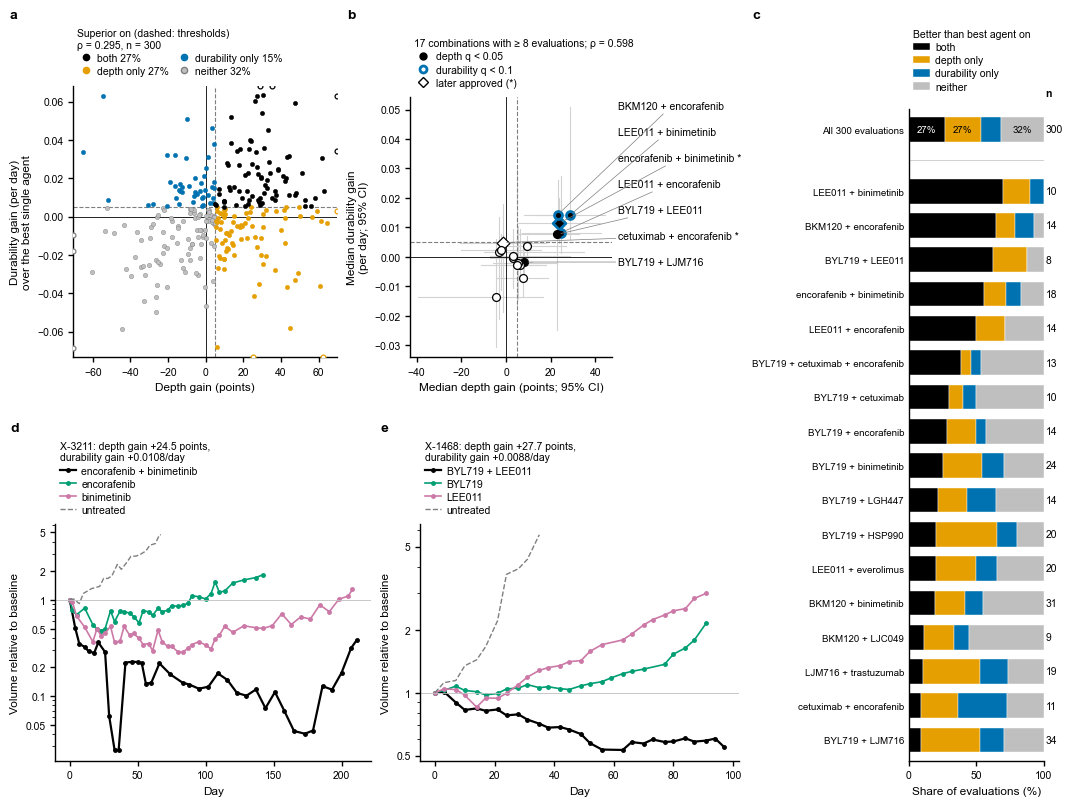

  saved outputs\figures\Figure_4.{pdf,eps,tiff}  (267 mm wide; smallest text 7.0 pt, 4.7 pt at 180 mm)   BELOW THE MINIMUM


In [8]:
# ==========================================================================
# Figure 4: combinations
# a  All evaluations: depth gain against durability gain, by category.
# b  Per-combination median gains (combinations with >= 8 evaluations), with
#    bootstrap intervals. Filled: depth q < 0.05. Heavy blue outline:
#    durability q < DURABILITY_Q_FOR_FIGURE (0.10, the rule the text uses for
#    "also inhibited regrowth"). Diamonds: later approved.
# c  Outcome mix per combination.
# d, e  Example trajectories: the evaluation of each example combination
#    closest to that combination's median gains (gains scaled by their SD over
#    all evaluations). A named example that is absent or untested is replaced
#    by the tested combination with the most evaluations, and the
#    replacement is printed.
# ==========================================================================

EXAMPLE_COMBINATIONS = ("encorafenib + binimetinib", "BYL719 + LEE011")


def draw_figure_4():
    print("FIG. 4")
    DURABILITY_Q_FOR_FIGURE = 0.10
    CATEGORY_ORDER = ["superior on both", "superior in depth only", "superior in durability only", "superior on neither"]
    CATEGORY_COLORS = {"superior on both": COLORS["ink"], "superior in depth only": COLORS["depth"],
                       "superior in durability only": COLORS["trajectory"], "superior on neither": COLORS["light"]}
    CATEGORY_LABELS = {"superior on both": "Both", "superior in depth only": "Depth only",
                       "superior in durability only": "Durability only", "superior on neither": "Neither"}
    combination_evaluations = FROZEN["combination_evaluations"]
    by_combination = FROZEN["combination_summary"]
    tested = by_combination.loc[by_combination.evaluations >= MIN_EVALUATIONS_TO_TEST]
    gain_rho, combination_rho = RESULTS["gain_rho"], RESULTS["combination_level_gain_rho"]

    # ---- d, e: choose the evaluations -----------------------------------------------
    examples = [name for name in EXAMPLE_COMBINATIONS if name in set(tested.combination)]
    for name in EXAMPLE_COMBINATIONS:
        if name not in examples:
            replacement = next(c for c in tested.sort_values("evaluations", ascending=False).combination
                               if c not in examples)
            examples.append(replacement)
            print(f"  d/e  {name} is not among the tested combinations; {replacement} is shown instead")
    depth_sd = combination_evaluations.depth_gain.std()
    durability_sd = combination_evaluations.durability_gain.std()
    example_evaluations = []
    for panel, combination in zip("de", examples):
        group = combination_evaluations.loc[combination_evaluations.combination == combination]
        centre = by_combination.set_index("combination").loc[combination]
        distance = np.hypot((group.depth_gain - centre.median_depth_gain) / depth_sd,
                            (group.durability_gain - centre.median_durability_gain) / durability_sd)
        chosen = group.loc[distance.idxmin()]
        example_evaluations.append(chosen)
        print(f"  {panel}  {combination} in {chosen.model_id}: "
              f"depth gain {chosen.depth_gain:.1f} points, durability gain {chosen.durability_gain:.4f} per day "
              f"(combination medians {centre.median_depth_gain:.1f}, {centre.median_durability_gain:.4f})")

    # ---- the figure -------------------------------------------------------------------
    figure = main_figure(205, wspace=0.08)
    outer = figure.add_gridspec(1, 2, width_ratios=[5.5, 1.0], wspace=0.02)
    left = outer[0].subgridspec(2, 1)
    left_top = left[0].subgridspec(1, 2, width_ratios=[1.0, 1.2], wspace=0.25)
    left_bottom = left[1].subgridspec(1, 2, wspace=0.3)
    axis_a = figure.add_subplot(own_cell(left_top[0]))
    axis_b = figure.add_subplot(own_cell(left_top[1]))
    axis_c = figure.add_subplot(outer[1])
    axis_d = figure.add_subplot(own_cell(left_bottom[0]))
    axis_e = figure.add_subplot(own_cell(left_bottom[1]))

    # a: every evaluation, extreme points clipped to the edge (open markers)
    depth_gain = combination_evaluations.depth_gain.to_numpy(float)
    durability_gain = combination_evaluations.durability_gain.to_numpy(float)
    x_low, x_high = np.percentile(depth_gain, [1, 99])
    y_low, y_high = np.percentile(durability_gain, [1, 99])
    x_pad, y_pad = 0.04 * (x_high - x_low), 0.04 * (y_high - y_low)
    x_low, x_high, y_low, y_high = x_low - x_pad, x_high + x_pad, y_low - y_pad, y_high + y_pad
    clipped = (depth_gain < x_low) | (depth_gain > x_high) | (durability_gain < y_low) | (durability_gain > y_high)
    shown_x, shown_y = np.clip(depth_gain, x_low, x_high), np.clip(durability_gain, y_low, y_high)
    category_share = combination_evaluations.category.value_counts(normalize=True)
    category_handles = []
    for category in CATEGORY_ORDER[::-1]:
        mask = (combination_evaluations.category == category).to_numpy()
        color = CATEGORY_COLORS[category]
        edge = COLORS["reference"] if category == "superior on neither" else color
        axis_a.scatter(shown_x[mask & ~clipped], shown_y[mask & ~clipped], s=10, color=color, edgecolor=edge,
                       linewidth=0.3, zorder=3)
        axis_a.scatter(shown_x[mask & clipped], shown_y[mask & clipped], s=12, facecolor="white", edgecolor=edge,
                       linewidth=0.9, zorder=3)
    for category in CATEGORY_ORDER:
        category_handles.append(Line2D([], [], marker="o", linestyle="", markersize=4.5,
                                       color=CATEGORY_COLORS[category],
                                       markeredgecolor=COLORS["reference"] if category == "superior on neither"
                                       else CATEGORY_COLORS[category],
                                       label=f"{CATEGORY_LABELS[category].lower()} "
                                             f"{100 * category_share.get(category, 0):.0f}%"))
    axis_a.axhline(0, color=COLORS["ink"], linewidth=0.6)
    axis_a.axvline(0, color=COLORS["ink"], linewidth=0.6)
    axis_a.axhline(DURABILITY_GAIN_THRESHOLD, color=COLORS["reference"], linewidth=0.8, linestyle="--")
    axis_a.axvline(DEPTH_GAIN_THRESHOLD, color=COLORS["reference"], linewidth=0.8, linestyle="--")
    axis_a.set_xlim(x_low, x_high)
    axis_a.set_ylim(y_low, y_high)
    axis_a.set_xlabel("Depth gain (points)")
    axis_a.set_ylabel("Durability gain (per day)\nover the best single agent")
    legend_above(axis_a, handles=category_handles, ncols=2, columnspacing=0.6, handletextpad=0.3,
                 title=f"Superior on (dashed: thresholds)\nρ = {gain_rho:.3f}, n = {len(combination_evaluations)}")
    print(f"  a  {int(clipped.sum())} of {len(combination_evaluations)} evaluations clipped to the panel edge "
          f"(open markers)")

    # b: per-combination medians with intervals
    tested_view = tested.reset_index(drop=True)
    depth_significant_mask = (tested_view.depth_q < 0.05).to_numpy()
    durability_significant_mask = (tested_view.durability_q < DURABILITY_Q_FOR_FIGURE).to_numpy()
    approved_mask = (tested_view.approval != "").to_numpy()
    for row in tested_view.itertuples():
        axis_b.plot([row.depth_low, row.depth_high], [row.median_durability_gain] * 2, color=tint(COLORS["light"], 0.7),
                    linewidth=0.8, zorder=1)
        axis_b.plot([row.median_depth_gain] * 2, [row.durability_low, row.durability_high],
                    color=tint(COLORS["light"], 0.7), linewidth=0.8, zorder=1)
    for index, row in tested_view.iterrows():
        axis_b.scatter(row.median_depth_gain, row.median_durability_gain, s=42 if approved_mask[index] else 32,
                       marker="D" if approved_mask[index] else "o",
                       facecolor=COLORS["ink"] if depth_significant_mask[index] else "white",
                       edgecolor=COLORS["trajectory"] if durability_significant_mask[index] else COLORS["ink"],
                       linewidth=2.0 if durability_significant_mask[index] else 0.9, zorder=3)
    axis_b.axhline(0, color=COLORS["ink"], linewidth=0.6)
    axis_b.axvline(0, color=COLORS["ink"], linewidth=0.6)
    axis_b.axhline(DURABILITY_GAIN_THRESHOLD, color=COLORS["reference"], linewidth=0.8, linestyle="--")
    axis_b.axvline(DEPTH_GAIN_THRESHOLD, color=COLORS["reference"], linewidth=0.8, linestyle="--")
    x_values = np.r_[tested_view.median_depth_gain, tested_view.depth_low, tested_view.depth_high]
    y_values = np.r_[tested_view.median_durability_gain, tested_view.durability_low, tested_view.durability_high]
    x_span, y_span = np.nanmax(x_values) - np.nanmin(x_values), np.nanmax(y_values) - np.nanmin(y_values)
    axis_b.set_xlim(np.nanmin(x_values) - 0.04 * x_span, np.nanmax(x_values) + 0.04 * x_span)
    axis_b.set_ylim(np.nanmin(y_values) - 0.04 * y_span, np.nanmax(y_values) + 0.04 * y_span)
    # Labels in a column to the right of the panel, spread so they never overlap.
    labelled = tested_view.loc[depth_significant_mask | approved_mask].copy()
    labelled["axes_y"] = [axis_b.transLimits.transform((x, y))[1] for x, y in
                          zip(labelled.median_depth_gain, labelled.median_durability_gain)]
    labelled = labelled.sort_values("axes_y")
    spread_y, minimum_gap = [], 0.1
    for value in labelled.axes_y:
        spread_y.append(max(value, spread_y[-1] + minimum_gap) if spread_y else max(value, 0.03))
    overflow = spread_y[-1] - 0.97 if spread_y else 0
    spread_y = [value - max(overflow, 0) for value in spread_y]
    for row, text_y in zip(labelled.itertuples(), spread_y):
        axis_b.annotate(row.combination + (" *" if row.approval else ""),
                        xy=(row.median_depth_gain, row.median_durability_gain), xycoords="data",
                        xytext=(1.03, text_y), textcoords="axes fraction", ha="left", va="center", fontsize=7.5,
                        arrowprops={"arrowstyle": "-", "color": COLORS["reference"], "linewidth": 0.5,
                                    "shrinkA": 0, "shrinkB": 3})
    axis_b.set_xlabel("Median depth gain (points; 95% CI)")
    axis_b.set_ylabel("Median durability gain\n(per day; 95% CI)")
    legend_above(axis_b, ncols=1, title=f"{len(tested_view)} combinations with ≥ {MIN_EVALUATIONS_TO_TEST} "
                 f"evaluations; ρ = {combination_rho:.3f}", handles=[
                     Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=5, label="depth q < 0.05"),
                     Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["trajectory"],
                            markeredgewidth=2.0, markersize=5, label=f"durability q < {DURABILITY_Q_FOR_FIGURE:g}"),
                     Line2D([], [], marker="D", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["ink"],
                            markersize=5, label="later approved (*)")])

    # c: outcome mix per combination, overall split on top
    mix = (combination_evaluations.loc[combination_evaluations.combination.isin(tested_view.combination)]
           .groupby("combination").category.value_counts(normalize=True).unstack(fill_value=0.0)
           .reindex(columns=CATEGORY_ORDER, fill_value=0.0))
    mix = mix.sort_values(["superior on both", "superior in depth only"], ascending=True)
    counts = tested_view.set_index("combination").evaluations
    overall = combination_evaluations.category.value_counts(normalize=True).reindex(CATEGORY_ORDER, fill_value=0.0)
    rows = [(name, mix.loc[name], int(counts[name])) for name in mix.index]
    positions = list(range(len(rows))) + [len(rows) + 0.8]
    rows.append((f"All {len(combination_evaluations)} evaluations", overall, len(combination_evaluations)))
    for position, (name, shares, n) in zip(positions, rows):
        left_edge = 0.0
        for category in CATEGORY_ORDER:
            axis_c.barh(position, 100 * shares[category], left=left_edge, color=CATEGORY_COLORS[category], height=0.72,
                        edgecolor="white", linewidth=0.3,
                        label=CATEGORY_LABELS[category].lower() if position == positions[0] else None)
            left_edge += 100 * shares[category]
        axis_c.text(101.5, position, f"{n}", va="center", ha="left", fontsize=7.5)
    for category, share, left_edge in zip(CATEGORY_ORDER, overall, np.r_[0, np.cumsum(overall)[:-1]]):
        if share > 0.18:
            axis_c.text(100 * (left_edge + share / 2), positions[-1], f"{100 * share:.0f}%", ha="center", va="center",
                        fontsize=7, color="white" if category in ("superior on both", "superior in durability only")
                        else COLORS["ink"])
    axis_c.set_yticks(positions, [name for name, _, _ in rows], fontsize=7)
    axis_c.axhline(positions[-2] + 0.9, color=COLORS["light"], linewidth=0.5)
    axis_c.set_xlim(0, 100)
    axis_c.set_xticks([0, 50, 100])
    axis_c.set_ylim(-0.6, positions[-1] + 0.6)
    axis_c.text(101.5, positions[-1] + 0.9, "n", fontsize=7.5, fontweight="bold", ha="left", va="bottom")
    axis_c.set_xlabel("Share of evaluations (%)")
    axis_c.tick_params(axis="y", length=0)
    legend_above(axis_c, ncols=1, title="Better than best agent on")

    # d, e: example trajectories (the arm identifier is "model || treatment")
    component_colors = [COLORS["third"], COLORS["fifth"], COLORS["sixth"]]
    for axis, evaluation in zip((axis_d, axis_e), example_evaluations):
        components = [part.strip() for part in evaluation.combination.split("+")]
        series = [(evaluation.combination, COLORS["ink"], "-", 1.6)]
        series += [(part, color, "-", 1.2) for part, color in zip(components, component_colors)]
        untreated_arm = f"{evaluation.model_id} || {CONTROL_LABEL}"
        if (observations.arm_id == untreated_arm).any():
            series.append((CONTROL_LABEL, COLORS["reference"], "--", 1.0))
        for treatment, color, style, width in series:
            arm_day, arm_volume = arm_curve(observations, f"{evaluation.model_id} || {treatment}")
            axis.plot(arm_day, arm_volume / arm_volume[0], style, color=color, linewidth=width, marker="o",
                      markersize=2.5 if treatment != CONTROL_LABEL else 0, label=treatment)
        axis.axhline(1, color=COLORS["light"], linewidth=0.6)
        axis.set_yscale("log")
        plain_log_axis(axis)
        axis.set_xlabel("Day")
        axis.set_ylabel("Volume relative to baseline")
        legend_above(axis, ncols=1, title=f"{evaluation.model_id}: depth gain {evaluation.depth_gain:+.1f} points,\n"
                     f"durability gain {evaluation.durability_gain:+.4f}/day")

    add_panel_letters(figure, [[(axis_a, "a"), (axis_b, "b"), (axis_c, "c")], [(axis_d, "d"), (axis_e, "e")]])
    save_figure(figure, "combinations")


if 4 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 4", draw_figure_4, requires=("combination_evaluations", "combination_summary",
                                              "observations_canonical"), style=MAIN_FIGURE_STYLE)

FIG. 5
  a  dot area ∝ PDX models (9–53)
  d  73.8% of assignments at or above the planned durability statistic use a developmental or hormonal comparator
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_5.png, .tiff and .eps


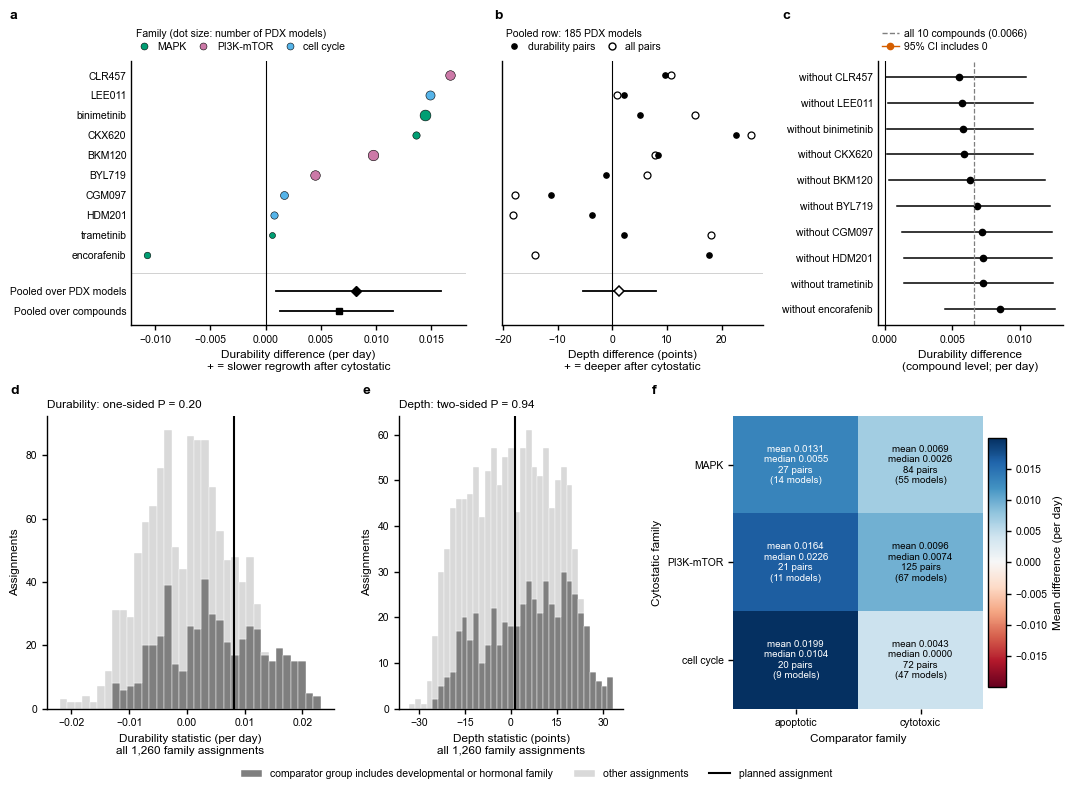

  saved outputs\figures\Figure_5.{pdf,eps,tiff}  (267 mm wide; smallest text 7.0 pt, 4.7 pt at 180 mm)   BELOW THE MINIMUM


In [9]:
# ==========================================================================
# Figure 5: mechanism class
# a  Durability effect of each cytostatic compound (compound_effects), dot
#    area ∝ PDX models, with the model-level and compound-level pooled rows.
# b  Depth effect of the same compounds, same rows. Filled: the durability
#    pairs (same aggregation as compound_effects). Open: all contrast pairs
#    (the population of the reported depth result). Positive = cytostatic
#    deeper.
# c  Leave-one-compound-out.
# d, e  Exact-test nulls over all family assignments, stacked by whether the
#    comparator group includes the developmental or hormonal family.
# f  Durability difference by family pair.
# ==========================================================================

def draw_figure_5():
    print("FIG. 5")
    compound_effects = FROZEN["mechanism_class_compound_effects"]
    contrast_pairs = FROZEN["mechanism_class_contrast_pairs"]
    durability_pairs = contrast_pairs.dropna(subset=["durability"])            # as in 11.1
    leave_one_out = FROZEN["mechanism_class_leave_one_out"]
    exact_splits = FROZEN["mechanism_class_exact_splits"]
    breakdown = TABLES["mechanism_class_by_family_pair"]
    results = FROZEN["mechanism_class_results"].set_index("analysis")
    durability_result = results.loc["bootstrap over PDX models, durability (planned)"]
    depth_result = results.loc["bootstrap over PDX models, depth (planned)"]
    compound_effect, compound_low, compound_high = (RESULTS["compound_effect"], RESULTS["compound_effect_low"],
                                                    RESULTS["compound_effect_high"])
    planned = exact_splits.loc[exact_splits.is_planned.astype(bool)].iloc[0]
    exact_p = {"durability": RESULTS["exact_p_durability_one_sided"], "depth": RESULTS["exact_p_depth_two_sided"]}
    assert np.isclose(durability_result.estimate, RESULTS["mechanism_durability"])
    assert len(durability_pairs) == RESULTS["n_contrast_pairs_durability"]
    # Families present among the cytostatic compounds; the three planned
    # families keep their colors, any other family takes the next free one.
    FAMILY_COLORS = {"MAPK": COLORS["third"], "PI3K-mTOR": COLORS["fifth"], "cell cycle": COLORS["sixth"]}
    spare_colors = iter([COLORS["fourth"], COLORS["trajectory"], COLORS["depth"], COLORS["reference"]])
    for family in sorted(set(compound_effects.family.dropna()) - set(FAMILY_COLORS)):
        FAMILY_COLORS[family] = next(spare_colors, COLORS["reference"])
        print(f"  a  family '{family}' has no planned color; drawn in {FAMILY_COLORS[family]}")
    FAMILY_COLORS = {family: color for family, color in FAMILY_COLORS.items()
                     if family in set(compound_effects.family)}

    # Rows: compounds from largest durability effect (top) to smallest.
    compound_order = compound_effects.sort_values("effect", ascending=False).reset_index(drop=True)
    row_of = {compound: index for index, compound in enumerate(compound_order.cytostatic_compound)}
    pooled_model_row, pooled_compound_row = len(compound_order) + 0.8, len(compound_order) + 1.8

    def compound_depth(pairs):
        """Depth effect per cytostatic compound, aggregated exactly as compound_effects
        (mean over comparator × PDX model cells of the mean pair difference)."""
        cells = pairs.groupby(["cytostatic_compound", "comparator_compound", "model_id"], as_index=False).depth.mean()
        return cells.groupby("cytostatic_compound").depth.mean()

    depth_on_durability_pairs = compound_depth(durability_pairs)
    depth_on_all_pairs = compound_depth(contrast_pairs)
    missing_from_rows = sorted(set(depth_on_all_pairs.index) - set(row_of))
    if missing_from_rows:
        print(f"  b  compounds with depth pairs but no durability pairs (not drawn): {missing_from_rows}")
    print(f"  a  dot area ∝ PDX models ({compound_order.pdx_models.min()}–{compound_order.pdx_models.max()})")

    # ---- the figure -------------------------------------------------------------------
    figure = main_figure(195, wspace=0.08)
    outer = figure.add_gridspec(2, 1)
    row_1 = outer[0].subgridspec(1, 3, width_ratios=[1.15, 0.9, 1.0])
    row_2 = outer[1].subgridspec(1, 3, width_ratios=[1.15, 0.9, 1.0])
    axis_a = figure.add_subplot(row_1[0])
    axis_b = figure.add_subplot(row_1[1], sharey=axis_a)
    axis_c = figure.add_subplot(own_cell(row_1[2]))
    axis_d = figure.add_subplot(row_2[0])
    axis_e = figure.add_subplot(row_2[1])
    axis_f = figure.add_subplot(row_2[2])
    row_labels = (list(compound_order.cytostatic_compound)
                  + ["Pooled over PDX models", "Pooled over compounds"])
    row_positions = list(range(len(compound_order))) + [pooled_model_row, pooled_compound_row]

    # a: durability per compound and pooled
    sizes = 10 + 50 * (compound_order.pdx_models / compound_order.pdx_models.max())
    for row, size in zip(compound_order.itertuples(), sizes):
        axis_a.scatter(row.effect, row_of[row.cytostatic_compound], s=size,
                       color=FAMILY_COLORS.get(row.family, COLORS["reference"]), edgecolor=COLORS["ink"],
                       linewidth=0.4, zorder=3)
    for y, estimate, low, high, marker in (
            (pooled_model_row, durability_result.estimate, durability_result.low, durability_result.high, "D"),
            (pooled_compound_row, compound_effect, compound_low, compound_high, "s")):
        axis_a.plot([low, high], [y, y], color=COLORS["ink"], linewidth=1.3)
        axis_a.plot(estimate, y, marker, color=COLORS["ink"], markersize=5)
    axis_a.axhline(len(compound_order) - 0.1, color=COLORS["light"], linewidth=0.5)
    axis_a.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_a.set_yticks(row_positions, row_labels)
    axis_a.set_ylim(pooled_compound_row + 0.7, -0.7)
    axis_a.tick_params(axis="y", length=0)
    axis_a.set_xlabel("Durability difference (per day)\n+ = slower regrowth after cytostatic")
    legend_above(axis_a, ncols=3, title="Family (dot size: number of PDX models)", columnspacing=0.8, handles=[
        Line2D([], [], marker="o", linestyle="", color=color, markeredgecolor=COLORS["ink"], markeredgewidth=0.4,
               markersize=5, label=family) for family, color in FAMILY_COLORS.items()])

    # b: depth per compound, same rows
    for compound, y in row_of.items():
        if compound in depth_on_all_pairs.index:
            axis_b.plot(depth_on_all_pairs[compound], y, "o", markerfacecolor="white", markeredgecolor=COLORS["ink"],
                        markeredgewidth=0.9, markersize=5, zorder=3)
        if compound in depth_on_durability_pairs.index:
            axis_b.plot(depth_on_durability_pairs[compound], y, "o", color=COLORS["ink"], markersize=3.8, zorder=4)
    axis_b.plot([depth_result.low, depth_result.high], [pooled_model_row] * 2, color=COLORS["ink"], linewidth=1.3)
    axis_b.plot(depth_result.estimate, pooled_model_row, "D", markerfacecolor="white", markeredgecolor=COLORS["ink"],
                markeredgewidth=1.1, markersize=5)
    axis_b.axhline(len(compound_order) - 0.1, color=COLORS["light"], linewidth=0.5)
    axis_b.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_b.tick_params(axis="y", labelleft=False, length=0)
    axis_b.set_xlabel("Depth difference (points)\n+ = deeper after cytostatic")
    legend_above(axis_b, ncols=2, columnspacing=0.8, title=f"Pooled row: {int(depth_result.n)} PDX models", handles=[
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=3.8, label="durability pairs"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["ink"],
               markersize=5, label="all pairs")])

    # c: leave one compound out, same order as a
    loco = leave_one_out.assign(row=leave_one_out.omitted.map(row_of)).sort_values("row").reset_index(drop=True)
    for position, row in loco.iterrows():
        color = COLORS["ink"] if row.low > 0 else COLORS["fourth"]
        axis_c.plot([row.low, row.high], [position, position], color=color, linewidth=1.1)
        axis_c.plot(row.estimate, position, "o", color=color, markersize=4.5)
    axis_c.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_c.axvline(compound_effect, color=COLORS["reference"], linewidth=0.9, linestyle="--")
    axis_c.set_yticks(range(len(loco)), [f"without {name}" for name in loco.omitted])
    axis_c.set_ylim(len(loco) - 0.4, -0.6)
    axis_c.tick_params(axis="y", length=0)
    axis_c.set_xlabel("Durability difference\n(compound level; per day)")
    legend_above(axis_c, handles=[
        Line2D([], [], color=COLORS["reference"], linestyle="--",
               label=f"all {len(compound_order)} compounds ({compound_effect:.4f})"),
        Line2D([], [], marker="o", color=COLORS["fourth"], markersize=4.5, label="95% CI includes 0")])

    # d, e: exact-test nulls, stacked by comparator group
    small_label = "comparator group includes developmental or hormonal family"
    small = exact_splits.small_family_comparator.astype(bool).to_numpy()
    for axis, endpoint, p_value, p_label, unit in (
            (axis_d, "durability", exact_p["durability"], "one-sided", "per day"),
            (axis_e, "depth", exact_p["depth"], "two-sided", "points")):
        values = exact_splits[endpoint].to_numpy(float)
        bins = np.linspace(np.nanmin(values), np.nanmax(values), 36)
        axis.hist([values[small], values[~small]], bins=bins, stacked=True,
                  color=[COLORS["reference"], tint(COLORS["light"], 0.6)], edgecolor="white", linewidth=0.3,
                  label=[small_label, "other assignments"])
        axis.axvline(planned[endpoint], color=COLORS["ink"], linewidth=1.5, label="planned assignment")
        axis.set_title(f"{endpoint.capitalize()}: {p_label} P = {p_value:.2f}", loc="left")
        axis.set_xlabel(f"{endpoint.capitalize()} statistic ({unit})\nall {len(exact_splits):,} family assignments")
        axis.set_ylabel("Assignments")
        axis.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    handles, labels = axis_d.get_legend_handles_labels()

    # f: family-pair heatmap (filled before the shared legend is placed, so the
    # legend sits below the final bottom row)
    cytostatic_rows = sorted(breakdown.cytostatic_family.unique())
    comparator_columns = sorted(breakdown.comparator_family.unique())
    cells = breakdown.set_index(["cytostatic_family", "comparator_family"])
    means = np.array([[cells.mean_difference.get((r, c), np.nan) for c in comparator_columns] for r in cytostatic_rows])
    limit = max(float(np.nanmax(np.abs(means))), 1e-12)
    image = axis_f.imshow(means, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    for i, family in enumerate(cytostatic_rows):
        for j, comparator in enumerate(comparator_columns):
            if (family, comparator) not in cells.index:
                continue
            cell = cells.loc[(family, comparator)]
            dark = abs(cell.mean_difference) > 0.6 * limit
            axis_f.text(j, i, f"mean {cell.mean_difference:.4f}\nmedian {cell.median_difference:.4f}\n"
                        f"{int(cell.pairs)} pairs\n({int(cell.pdx_models)} models)", ha="center", va="center",
                        fontsize=7, color="white" if dark else COLORS["ink"])
    axis_f.set_xticks(range(len(comparator_columns)), comparator_columns)
    axis_f.set_yticks(range(len(cytostatic_rows)), cytostatic_rows)
    axis_f.set_xlabel("Comparator family")
    axis_f.set_ylabel("Cytostatic family")
    for spine in axis_f.spines.values():
        spine.set_visible(False)
    colorbar = figure.colorbar(image, ax=axis_f, location="right", shrink=0.85, aspect=14, pad=0.02)
    colorbar.set_label("Mean difference (per day)")

    # The shared legend of d and e, placed after the layout is final just below
    # the bottom row's axis labels (an outside legend would get a wide bottom
    # margin). A legend outside the layout moves no panel, and saving with a
    # tight bounding box keeps it in the file although it sits below the canvas.
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    row_bottom = min(axis.get_tightbbox(renderer).y0 for axis in (axis_d, axis_e, axis_f)) / figure.bbox.height
    figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, row_bottom - 0.005),
                  bbox_transform=figure.transFigure, ncols=3, frameon=False)
    tail_share = exact_splits.loc[exact_splits.durability >= planned.durability, "small_family_comparator"].astype(bool).mean()
    print(f"  d  {100 * tail_share:.1f}% of assignments at or above the planned durability statistic use a "
          f"developmental or hormonal comparator")

    add_panel_letters(figure, [[(axis_a, "a"), (axis_b, "b"), (axis_c, "c")],
                               [(axis_d, "d"), (axis_e, "e"), (axis_f, "f")]])
    save_figure(figure, "mechanism_class")


if 5 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 5", draw_figure_5, requires=(
        "mechanism_class_compound_effects", "mechanism_class_contrast_pairs", "mechanism_class_leave_one_out",
        "mechanism_class_exact_splits", "mechanism_class_results", "mechanism_class_by_family_pair"),
        style=MAIN_FIGURE_STYLE)

FIG. 6
  a  largest gap on the drawn schedule 0.039 log units (0.35 × measurement noise)
  c  76 designs; best: every 4 d for 56 d, 5 animals, median |log error| 0.66; recovered in 0
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_6.png, .tiff and .eps


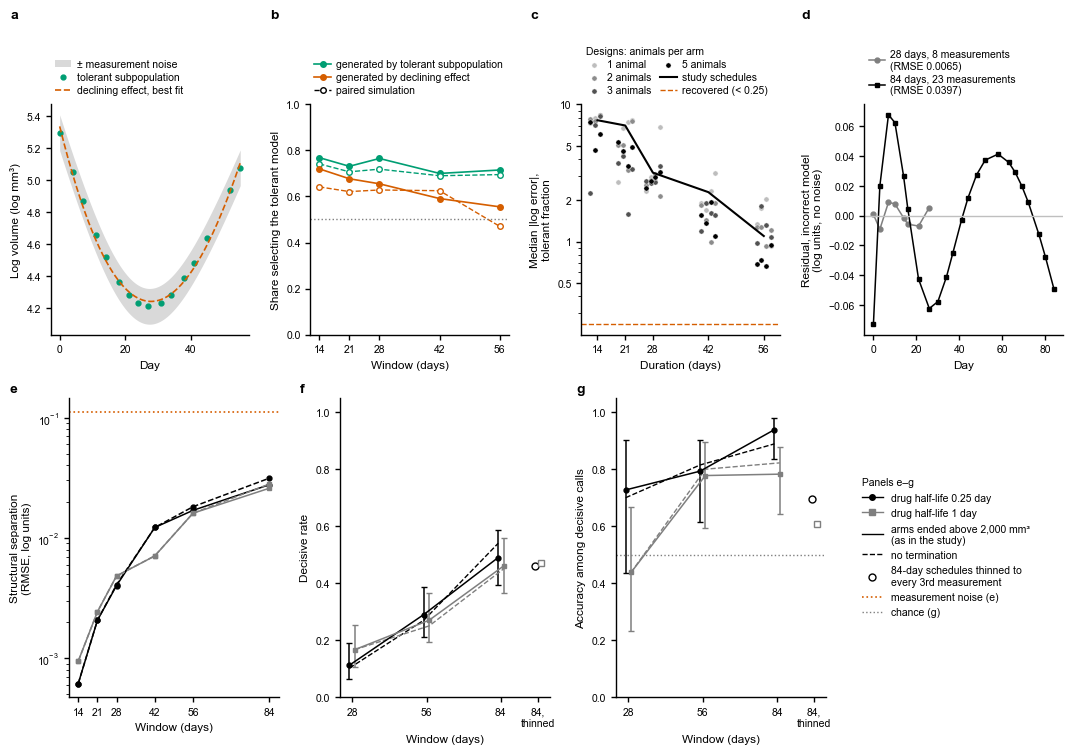

  saved outputs\figures\Figure_6.{pdf,eps,tiff}  (267 mm wide; smallest text 7.5 pt, 5.0 pt at 180 mm)


In [10]:
# ==========================================================================
# Figure 6: limits on recovering the mechanism
# a  Section 5.1: a tolerant-subpopulation curve (constant exposure) and the
#    best declining-effect fit, on a typical 56-day schedule of the study.
# b  Section 5.5: share of simulated arms for which the tolerant model was
#    selected, by window and generating model. Solid: the unpaired
#    simulation; dashed, open markers: the paired simulation (both models on
#    the same schedule and noise), shown when SHOW_PAIRED_DISCRIMINATION is set.
# c  Section 5.4: recovery error of the tolerant fraction in each of the
#    alternative designs, with the study's own schedules (Section 5.3). Extra
#    animals are repeated measurements of one trajectory with no
#    between-animal variation, so the design map is an upper bound.
# d  12.4: the incorrect model's residual on a noise-free arm over 28 and 84
#    days (typical schedule of the fixed pool; fixed parameters, 0.25-day
#    half-life).
# e  12.2: median structural separation against window, with the noise line.
# f, g  12.3 at the measured noise: decisive rate and accuracy among decisive
#    calls (Wilson 95% intervals), with 12.4's thinned 84-day schedules.
# ==========================================================================

SHOW_PAIRED_DISCRIMINATION = True


def draw_figure_6():
    print("FIG. 6")
    HALF_LIFE_STYLE = {0.25: (COLORS["ink"], "o"), 1.0: (COLORS["reference"], "s")}
    ANIMAL_COLORS = {1: "#BDBDBD", 2: "#8C8C8C", 3: "#525252", 5: "#000000"}
    INTERVAL_OFFSET = {2: -1.8, 3: -0.6, 4: 0.6, 7: 1.8}
    approximation_example = FROZEN["approximation_example"]
    mechanism_discrimination = FROZEN["mechanism_discrimination"]
    paired_discrimination = FROZEN.get("mechanism_discrimination_paired")
    design_map = FROZEN["design_map"]
    parameter_recovery = FROZEN["parameter_recovery"]
    residual_example = FROZEN["exposure_residual_example"]
    separation_by_window = FROZEN["exposure_separation_by_window"]
    verdicts = FROZEN["exposure_verdicts_by_window"]
    at_measured_noise = verdicts.loc[np.isclose(verdicts.noise_sd, MEASUREMENT_NOISE)]
    thinning = FROZEN["exposure_thinning_verdicts"]
    thinned = thinning.loc[(thinning.termination == "applied") & (thinning.keep_every == thinning.keep_every.max())]

    figure = main_figure(190, wspace=0.08)
    outer = figure.add_gridspec(2, 1)
    row_1 = outer[0].subgridspec(1, 4)
    row_2 = outer[1].subgridspec(1, 4)
    axis_a = figure.add_subplot(row_1[0])
    axis_b = figure.add_subplot(row_1[1])
    axis_c = figure.add_subplot(row_1[2])
    axis_d = figure.add_subplot(row_1[3])
    axis_e = figure.add_subplot(row_2[0])
    axis_f = figure.add_subplot(row_2[1])
    axis_g = figure.add_subplot(row_2[2], sharex=axis_f)
    axis_key = figure.add_subplot(row_2[3])
    axis_key.axis("off")

    # a: a tolerant curve and the closest declining-effect curve (5.1, saved)
    schedule = approximation_example.loc[approximation_example.grid == "schedule"]
    dense = approximation_example.loc[approximation_example.grid == "dense"]
    axis_a.fill_between(dense.day, dense.tolerant - MEASUREMENT_NOISE, dense.tolerant + MEASUREMENT_NOISE,
                        color=tint(COLORS["light"], 0.6), linewidth=0, label="± measurement noise")
    axis_a.plot(schedule.day, schedule.tolerant, "o", color=COLORS["third"], markersize=3.5,
                label="tolerant subpopulation")
    axis_a.plot(dense.day, dense.declining_fit, "--", color=COLORS["fourth"], linewidth=1.2,
                label="declining effect, best fit")
    axis_a.set_xlabel("Day")
    axis_a.set_ylabel("Log volume (log mm³)")
    legend_above(spacing="classic", axis=axis_a, ncols=1)
    largest_gap = float(np.max(np.abs(schedule.declining_fit - schedule.tolerant)))
    print(f"  a  largest gap on the drawn schedule {largest_gap:.3f} log units "
          f"({largest_gap / MEASUREMENT_NOISE:.2f} × measurement noise)")

    # b: share choosing the tolerant model
    for truth, color in (("tolerant subpopulation", COLORS["third"]), ("declining drug effect", COLORS["fourth"])):
        rows = mechanism_discrimination.loc[mechanism_discrimination.true_mechanism == truth].sort_values("window_days")
        axis_b.plot(rows.window_days, rows.chose_tolerant, "-o", color=color, markersize=4, linewidth=1.2,
                    label=f"generated by {truth.replace(' drug', '')}")
        if SHOW_PAIRED_DISCRIMINATION and paired_discrimination is not None:
            paired = paired_discrimination.loc[paired_discrimination.true_mechanism == truth].sort_values("window_days")
            axis_b.plot(paired.window_days, paired.chose_tolerant, "--o", color=color, markersize=4,
                        markerfacecolor="white", linewidth=1.0)
    if SHOW_PAIRED_DISCRIMINATION and paired_discrimination is not None:
        axis_b.plot([], [], "--o", color=COLORS["ink"], markerfacecolor="white", markersize=4, linewidth=1.0,
                    label="paired simulation")
    axis_b.axhline(0.5, color=COLORS["reference"], linestyle=":", linewidth=1.0)
    axis_b.set_ylim(0, 1)
    axis_b.set_xticks(sorted(mechanism_discrimination.window_days.unique()))
    axis_b.set_xlabel("Window (days)")
    axis_b.set_ylabel("Share selecting the tolerant model")
    legend_above(spacing="classic", axis=axis_b, ncols=1)

    # c: recovery error of the tolerant fraction, every design and the study's schedules
    fraction_map = design_map.loc[design_map.parameter == "tolerant_fraction"]
    for animals, color in ANIMAL_COLORS.items():
        rows = fraction_map.loc[fraction_map.animals_per_arm == animals]
        axis_c.scatter(rows.duration_days + rows.interval_days.map(INTERVAL_OFFSET), rows.median_abs_log_error, s=14,
                       color=color, edgecolor="white", linewidth=0.3, zorder=3,
                       label=f"{animals} animal{'s' if animals > 1 else ''}")
    study_rows = parameter_recovery.loc[parameter_recovery.parameter == "tolerant_fraction"].sort_values("window_days")
    axis_c.plot(study_rows.window_days, study_rows.median_abs_log_error, "-", color=COLORS["ink"], linewidth=1.5,
                zorder=4, label="study schedules")
    axis_c.axhline(RECOVERY_THRESHOLD, color=COLORS["fourth"], linestyle="--", linewidth=1.0,
                   label=f"recovered (< {RECOVERY_THRESHOLD})")
    best_design = fraction_map.loc[fraction_map.median_abs_log_error.idxmin()]
    axis_c.set_yscale("log")
    plain_log_axis(axis_c)
    axis_c.set_xticks(sorted(fraction_map.duration_days.unique()))
    axis_c.set_xlabel("Duration (days)")
    axis_c.set_ylabel("Median |log error|,\ntolerant fraction")
    legend_above(spacing="classic", axis=axis_c, ncols=2, title="Designs: animals per arm", columnspacing=0.8)
    print(f"  c  {len(fraction_map)} designs; best: every {best_design.interval_days:g} d for "
          f"{best_design.duration_days:g} d, {best_design.animals_per_arm:g} animals, median |log error| "
          f"{best_design.median_abs_log_error:.2f}; recovered in {int(fraction_map.recovered.astype(bool).sum())}")

    # d: residual of the incorrect model over 28 and 84 days (12.4, saved)
    for window_days, marker in ((28, "o"), (84, "s")):
        rows = residual_example.loc[residual_example.window_days == window_days].sort_values("day")
        axis_d.plot(rows.day, rows.residual, f"-{marker}", color=COLORS["ink"] if window_days == 84 else COLORS["reference"],
                    markersize=3.5, linewidth=1.1,
                    label=f"{window_days} days, {len(rows)} measurements\n(RMSE {rows.rmse_incorrect_model.iloc[0]:.4f})")
    axis_d.axhline(0, color=COLORS["light"], linewidth=1.0)
    axis_d.set_xlabel("Day")
    axis_d.set_ylabel("Residual, incorrect model\n(log units, no noise)")
    legend_above(spacing="classic", axis=axis_d)

    # e: structural separation against window
    for (rule, half_life), rows in separation_by_window.groupby(["termination", "half_life_days"]):
        color, marker = HALF_LIFE_STYLE[half_life]
        rows = rows.sort_values("window_days")
        axis_e.plot(rows.window_days, rows.median_separation, marker=marker, color=color, markersize=3.5,
                    linewidth=1.1, linestyle="-" if rule == "applied" else "--")
    axis_e.axhline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.2)
    axis_e.set_yscale("log")
    axis_e.set_xticks(sorted(separation_by_window.window_days.unique()))
    axis_e.set_xlabel("Window (days)")
    axis_e.set_ylabel("Structural separation\n(RMSE, log units)")

    # f, g: decisive rate and accuracy among decisive calls, with the saved
    # Wilson intervals of 12.3
    for axis, value, low_column, high_column, ylabel in (
            (axis_f, "decisive_rate", "decisive_low", "decisive_high", "Decisive rate"),
            (axis_g, "accuracy_when_decisive", "accuracy_low", "accuracy_high", "Accuracy among decisive calls")):
        for half_life in EXPOSURE_HALF_LIVES:
            color, marker = HALF_LIFE_STYLE[half_life]
            offset = -1.0 if half_life == 0.25 else 1.0
            for rule in TERMINATION_RULES:
                rows = at_measured_noise.loc[(at_measured_noise.half_life_days == half_life)
                                             & (at_measured_noise.termination == rule)].sort_values("window_days")
                if rule == "applied":
                    axis.errorbar(rows.window_days + offset, rows[value],
                                  yerr=interval_errors(rows[value], rows[low_column], rows[high_column]),
                                  fmt=f"-{marker}", color=color, markersize=3.5, capsize=2, linewidth=1.1)
                else:
                    axis.plot(rows.window_days + offset, rows[value], "--", color=color, linewidth=1.0)
            thinned_row = thinned.loc[thinned.half_life_days == half_life]
            axis.plot(np.full(len(thinned_row), THINNING_WINDOW_DAYS + 14 + offset), thinned_row[value], marker,
                      color=color, markerfacecolor="white", markersize=5, linestyle="")
        axis.set_xticks(list(CONFIRM_WINDOWS) + [THINNING_WINDOW_DAYS + 14],
                        [f"{w}" for w in CONFIRM_WINDOWS] + [f"{THINNING_WINDOW_DAYS},\nthinned"])
        axis.set_xlabel("Window (days)")
        axis.set_ylabel(ylabel)
        axis.set_ylim(0, 1.05)
    axis_g.axhline(0.5, color=COLORS["reference"], linestyle=":", linewidth=1.0)

    # one key for e–g, in the empty slot
    axis_key.legend(handles=[
        Line2D([], [], color=HALF_LIFE_STYLE[0.25][0], marker="o", markersize=4, label="drug half-life 0.25 day"),
        Line2D([], [], color=HALF_LIFE_STYLE[1.0][0], marker="s", markersize=4, label="drug half-life 1 day"),
        Line2D([], [], color=COLORS["ink"], linestyle="-",
               label=f"arms ended above {TERMINATION_VOLUME:,.0f} mm³\n(as in the study)"),
        Line2D([], [], color=COLORS["ink"], linestyle="--", label="no termination"),
        Line2D([], [], color=COLORS["ink"], marker="o", markerfacecolor="white", linestyle="", markersize=5,
               label=f"{THINNING_WINDOW_DAYS}-day schedules thinned to\nevery {int(thinning.keep_every.max())}"
                     f"{'rd' if int(thinning.keep_every.max()) == 3 else 'th'} measurement"),
        Line2D([], [], color=COLORS["fourth"], linestyle=":", linewidth=1.2, label="measurement noise (e)"),
        Line2D([], [], color=COLORS["reference"], linestyle=":", label="chance (g)")],
        loc="center left", frameon=False, title="Panels e–g", alignment="left", fontsize=7.5, title_fontsize=7.5)

    add_panel_letters(figure, skip_spacers=False, rows=[[(axis_a, "a"), (axis_b, "b"), (axis_c, "c"), (axis_d, "d")],
                                                        [(axis_e, "e"), (axis_f, "f"), (axis_g, "g")]])
    save_figure(figure, "identifiability")


if 6 in MANUSCRIPT_FIGURES_TO_DRAW:
    draw("Figure 6", draw_figure_6, requires=(
        "approximation_example", "mechanism_discrimination", "design_map", "parameter_recovery",
        "exposure_residual_example", "exposure_separation_by_window", "exposure_verdicts_by_window",
        "exposure_thinning_verdicts"), style=MAIN_FIGURE_STYLE)

FIG. 7
  d  events by route (time_to_progression gives a same-day tie to the new lesion in the primary
     definition and to the sum in the sum-only definition):
route     measured lesions only  both at the same assessment  new lesion first  total
study                                                                                
A6181087                     45                           16                37     98
CA031                        68                           27               128    223
  c  A6181087: 42.5% of patients have slope = log(1 − depth)/Δ exactly; burden rose in 28.4%; Spearman(depth, slope) -0.567
  c  CA031: 92.9% of patients have slope = log(1 − depth)/Δ exactly; burden rose in 5.4%; Spearman(depth, slope) -0.998
  copied to C:\Users\The_R\Downloads\pdxe_figures\Figure_7.png, .tiff and .eps


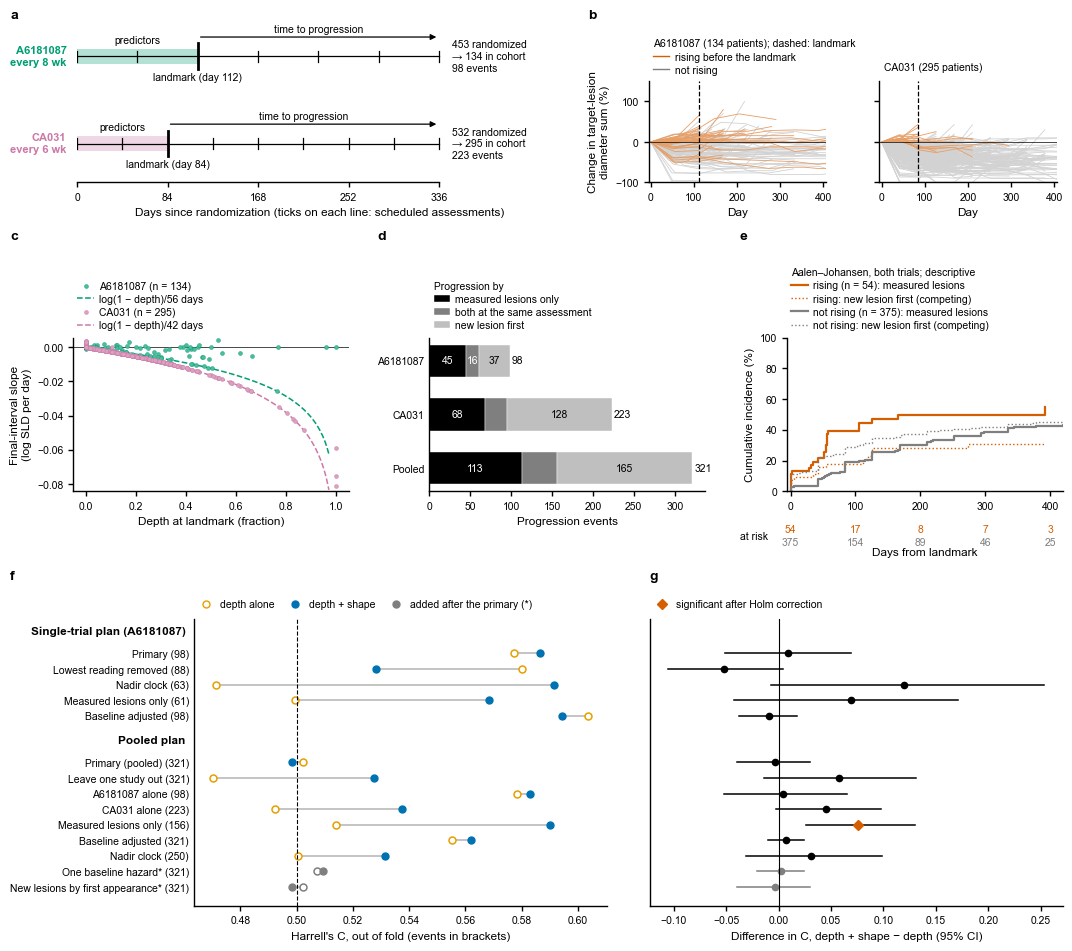

  saved outputs\figures\Figure_7.{pdf,eps,tiff}  (267 mm wide; smallest text 7.5 pt, 5.0 pt at 180 mm)


In [11]:
# ==========================================================================
# Figure 7: patients (restricted data; drawn locally, no value written)
# a  Design and attrition of each trial (shapes and text, no data).
# b  Tumor-burden trajectories of the landmark cohort, by trial, colored by
#    whether burden rose over the final pre-landmark interval (or, with
#    PLOT_INDIVIDUAL_PATIENTS False, medians and interquartile bands by
#    depth tertile).
# c  Slope against depth before the landmark, with slope = log(1 − depth)/Δ:
#    with only baseline and one assessment before the landmark, the slope is
#    fixed by depth for every patient whose burden fell.
# d  How the progression events arose.
# e  Cumulative incidence of progression in measured lesions from the
#    landmark, new-lesion-first progression as a competing event
#    (Aalen–Johansen; descriptive and in-sample).
# f  C-index of each model in each analysis (clinical_results).
# g  Difference in C-index with 95% CI; Holm rejections marked.
# ==========================================================================

def draw_figure_7():
    print("FIG. 7")
    TRIAL_COLORS = {"A6181087": COLORS["third"], "CA031": COLORS["fifth"]}
    RISING_COLORS = {1.0: COLORS["fourth"], 0.0: COLORS["reference"]}
    clinical_scored = FROZEN["clinical_patients"]
    clinical_panel = FROZEN["clinical_panel_restricted"]
    clinical_results = FROZEN["clinical_results"]
    # The landmark cohort, by the rule of 14.2.
    in_cohort = (clinical_scored.reached_landmark.astype(bool) & ~clinical_scored.progressed_before_landmark.astype(bool)
                 & clinical_scored.has_features.astype(bool))
    clinical_cohort = clinical_scored.loc[in_cohort].reset_index(drop=True)
    clinical_cohort["event"] = clinical_cohort.event.astype(bool)
    clinical_cohort["sld_only_event"] = clinical_cohort.sld_only_event.astype(bool)
    if len(clinical_cohort) != RESULTS.get("clinical_n_patients"):
        print(f"  note: landmark cohort {len(clinical_cohort)} patients; the pooled primary analysis used "
              f"{RESULTS.get('clinical_n_patients')} (patients with a missing predictor are left out of the Cox fits)")
    clinical_attrition = pd.DataFrame({
        "patients": clinical_scored.groupby("study").size(),
        "landmark_cohort": clinical_cohort.groupby("study").size(),
        "events": clinical_cohort.groupby("study").event.sum()}).fillna(0)

    # ---- d: how events arose; the tie rule is checked before labelling ----------
    events = clinical_cohort.loc[clinical_cohort.event].copy()
    events["route"] = np.where(events.source.eq("SLD"), "measured lesions only",
                               np.where(events.sld_only_event, "both at the same assessment", "new lesion first"))
    assert events.loc[events.source.eq("SLD"), "sld_only_event"].all()
    ties = events.loc[events.route.eq("both at the same assessment")]
    assert np.allclose(ties.sld_only_duration, ties.duration), \
        "a 'both' event has different sum and new-lesion days; the middle group is not a same-day tie"
    ROUTES = ["measured lesions only", "both at the same assessment", "new lesion first"]
    route_counts = events.groupby(["study", "route"]).size().unstack(fill_value=0).reindex(columns=ROUTES, fill_value=0)
    print("  d  events by route (time_to_progression gives a same-day tie to the new lesion in the primary\n"
          "     definition and to the sum in the sum-only definition):")
    print(route_counts.assign(total=route_counts.sum(axis=1)).to_string())

    # ---- e: competing-risk coding --------------------------------------------------
    # cause 1: progression in measured lesions (the sum-only event, on the
    # primary event day); cause 2: a new lesion first; 0: censored.
    competing = clinical_cohort.assign(
        time=np.maximum(clinical_cohort.duration.to_numpy(float), 0.0),
        cause=np.where(clinical_cohort.sld_only_event, 1, np.where(clinical_cohort.event, 2, 0)))
    assert np.allclose(competing.loc[competing.cause == 1, "sld_only_duration"],
                       competing.loc[competing.cause == 1, "duration"])

    # ---- c: patients whose slope is fixed by depth --------------------------------------
    expected_slope = (np.log(np.clip(1.0 - clinical_cohort.depth_at_landmark, 1e-9, None))
                      / clinical_cohort.slope_window_days)
    on_curve = np.isclose(clinical_cohort.slope_to_landmark, expected_slope, atol=1e-9)
    for study, part in clinical_cohort.assign(on_curve=on_curve).groupby("study"):
        print(f"  c  {study}: {100 * part.on_curve.mean():.1f}% of patients have slope = log(1 − depth)/Δ "
              f"exactly; burden rose in {100 * part.already_rising.mean():.1f}%; "
              f"Spearman(depth, slope) {spearman(part.depth_at_landmark, part.slope_to_landmark)[0]:.3f}")

    # ---- the figure ---------------------------------------------------------------------
    figure = main_figure(240, wspace=0.08)
    outer = figure.add_gridspec(3, 1, height_ratios=[0.75, 1.15, 1.3])
    row_1 = outer[0].subgridspec(1, 2)
    row_b = row_1[1].subgridspec(1, 2)
    row_2 = outer[1].subgridspec(1, 3)
    row_3 = outer[2].subgridspec(1, 2)
    axis_a = figure.add_subplot(row_1[0])
    axis_b1 = figure.add_subplot(row_b[0])
    axis_b2 = figure.add_subplot(row_b[1], sharey=axis_b1)
    axis_c = figure.add_subplot(row_2[0])
    axis_d = figure.add_subplot(row_2[1])
    axis_e = figure.add_subplot(row_2[2])
    axis_f = figure.add_subplot(row_3[0])
    axis_g = figure.add_subplot(row_3[1], sharey=axis_f)

    # a: design and attrition (drawn, not data)
    LANE_END = 336
    for lane, study in zip((1.35, 0.0), ("A6181087", "CA031")):
        interval = CLINICAL_STUDIES[study]["assessment_interval_days"]
        landmark = LANDMARK_DAYS[study]
        attrition = clinical_attrition.loc[study]
        axis_a.add_patch(Rectangle((0, lane - 0.12), landmark, 0.24,
                                   facecolor=tint(TRIAL_COLORS[study], 0.3), edgecolor="none"))
        axis_a.plot([0, LANE_END], [lane, lane], color=COLORS["ink"], linewidth=0.9)
        for day in np.arange(0, LANE_END + 1, interval):
            axis_a.plot([day, day], [lane - 0.08, lane + 0.08], color=COLORS["ink"], linewidth=0.9)
        axis_a.plot([landmark, landmark], [lane - 0.2, lane + 0.2], color=COLORS["ink"], linewidth=2.0)
        axis_a.annotate("", xy=(LANE_END, lane + 0.3), xytext=(landmark, lane + 0.3),
                        arrowprops={"arrowstyle": "-|>", "color": COLORS["ink"], "linewidth": 0.9})
        axis_a.text((landmark + LANE_END) / 2, lane + 0.34, "time to progression", ha="center", va="bottom",
                    fontsize=7.5)
        axis_a.text(landmark / 2, lane + 0.17, "predictors", ha="center", va="bottom", fontsize=7.5)
        axis_a.text(landmark, lane - 0.24, f"landmark (day {landmark:g})", ha="center", va="top", fontsize=7.5)
        axis_a.text(-10, lane, f"{study}\nevery {interval // 7:g} wk", ha="right", va="center", fontsize=8,
                    fontweight="bold", color=TRIAL_COLORS[study])
        axis_a.text(LANE_END + 12, lane, f"{int(attrition.patients)} randomized\n→ {int(attrition.landmark_cohort)} "
                    f"in cohort\n{int(attrition.events)} events", ha="left", va="center", fontsize=7.5)
    axis_a.set_xlim(0, 450)
    axis_a.set_ylim(-0.6, 1.85)
    axis_a.set_xticks(np.arange(0, LANE_END + 1, 84))
    axis_a.spines["bottom"].set_bounds(0, LANE_END)
    axis_a.set_xlabel("Days since randomization (ticks on each line: scheduled assessments)")
    axis_a.set_yticks([])
    for side in ("left", "top", "right"):
        axis_a.spines[side].set_visible(False)

    # b: burden trajectories, one small panel per trial. Patients are matched
    # on (study, patient), so an identifier repeated across trials cannot mix.
    cohort_flags = clinical_cohort.set_index(["study", "patient"])[["already_rising", "depth_at_landmark"]]
    burden = clinical_panel.loc[clinical_panel.complete.astype(bool)].copy()
    burden = burden.loc[pd.MultiIndex.from_frame(burden[["study", "patient"]]).isin(cohort_flags.index)]
    burden = burden.sort_values(["study", "patient", "day"])
    burden["baseline"] = burden.groupby(["study", "patient"]).sld.transform("first")
    burden = burden.loc[burden.baseline > 0]
    burden["percent_change"] = 100.0 * (burden.sld / burden.baseline - 1.0)
    burden = burden.join(cohort_flags, on=["study", "patient"])
    panel_titles = {}
    for axis, study in ((axis_b1, "A6181087"), (axis_b2, "CA031")):
        part = burden.loc[burden.study == study]
        if PLOT_INDIVIDUAL_PATIENTS:
            for rising in (0.0, 1.0):                      # rising patients drawn on top
                for _, patient_rows in part.loc[part.already_rising == rising].groupby("patient"):
                    axis.plot(patient_rows.day, patient_rows.percent_change.clip(-100, 150),
                              color=tint(RISING_COLORS[rising], 0.6 if rising else 0.35), linewidth=0.6)
        else:
            tertile = pd.qcut(part.depth_at_landmark.rank(method="first"), 3, labels=["shallow", "middle", "deep"])
            part = part.assign(tertile=tertile.to_numpy(),
                               visit=(part.day / CLINICAL_STUDIES[study]["assessment_interval_days"]).round())
            for (name, block), color in zip(part.groupby("tertile", observed=True),
                                            (COLORS["light"], COLORS["reference"], COLORS["ink"])):
                summary = block.groupby("visit").agg(day=("day", "median"), median=("percent_change", "median"),
                                                     q25=("percent_change", lambda v: v.quantile(0.25)),
                                                     q75=("percent_change", lambda v: v.quantile(0.75)),
                                                     n=("percent_change", "size"))
                summary = summary.loc[summary.n >= 10]
                axis.fill_between(summary.day, summary.q25, summary.q75, color=tint(color, 0.3), linewidth=0)
                axis.plot(summary.day, summary["median"], color=color, linewidth=1.3, label=f"{name} depth")
        axis.axvline(LANDMARK_DAYS[study], color=COLORS["ink"], linestyle="--", linewidth=0.9)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.5)
        axis.set_xlim(-5, min(part.day.max(), 400) + 5)
        axis.set_ylim(-100, 150)
        panel_titles[study] = f"{study} ({part.patient.nunique()} patients)"
        axis.set_xlabel("Day")
    axis_b1.set_ylabel("Change in target-lesion\ndiameter sum (%)")
    axis_b2.tick_params(labelleft=False)
    if PLOT_INDIVIDUAL_PATIENTS:
        trajectory_handles = [Line2D([], [], color=RISING_COLORS[1.0], label="rising before the landmark"),
                              Line2D([], [], color=RISING_COLORS[0.0], label="not rising")]
    else:
        trajectory_handles = axis_b2.get_legend_handles_labels()[0]
    legend_above(spacing="classic", axis=axis_b1, handles=trajectory_handles, ncols=1,
                 title=panel_titles["A6181087"] + "; dashed: landmark")
    legend_above(spacing="classic", axis=axis_b2, handles=[], title=panel_titles["CA031"])

    # c: slope against depth
    depth_grid = np.linspace(0.0, 0.97, 200)
    for study, part in clinical_cohort.groupby("study"):
        span = CLINICAL_STUDIES[study]["assessment_interval_days"]
        axis_c.scatter(part.depth_at_landmark, part.slope_to_landmark, s=8, color=tint(TRIAL_COLORS[study], 0.7),
                       edgecolor=TRIAL_COLORS[study], linewidth=0.3, zorder=3, label=f"{study} (n = {len(part)})")
        axis_c.plot(depth_grid, np.log(1.0 - depth_grid) / span, color=TRIAL_COLORS[study], linewidth=1.1,
                    linestyle="--", zorder=2, label=f"log(1 − depth)/{span:g} days")
    axis_c.axhline(0, color=COLORS["ink"], linewidth=0.5)
    slope_values = clinical_cohort.slope_to_landmark
    lower = min(slope_values.quantile(0.005), -1e-3) * 1.15
    axis_c.set_ylim(lower, max(slope_values.max(), 0.002) * 1.4)
    axis_c.set_xlabel("Depth at landmark (fraction)")
    axis_c.set_ylabel("Final-interval slope\n(log SLD per day)")
    legend_above(spacing="classic", axis=axis_c, ncols=1)

    # d: how events arose
    ROUTE_COLORS = {"measured lesions only": COLORS["ink"], "both at the same assessment": COLORS["reference"],
                    "new lesion first": COLORS["light"]}
    bar_rows = list(route_counts.index) + ["Pooled"]
    for position, study in enumerate(bar_rows):
        counts = route_counts.sum() if study == "Pooled" else route_counts.loc[study]
        total, left_edge = counts.sum(), 0
        for route in ROUTES:
            axis_d.barh(position, counts[route], left=left_edge, color=ROUTE_COLORS[route], height=0.6,
                        edgecolor="white", linewidth=0.3, label=route if position == 0 else None)
            if counts[route] / max(total, 1) > 0.15:
                axis_d.text(left_edge + counts[route] / 2, position, f"{counts[route]}", ha="center", va="center",
                            fontsize=7.5, color="white" if route != "new lesion first" else COLORS["ink"])
            left_edge += counts[route]
        axis_d.text(left_edge + 3, position, f"{total}", ha="left", va="center", fontsize=7.5)
    axis_d.set_yticks(range(len(bar_rows)), bar_rows)
    axis_d.invert_yaxis()
    axis_d.tick_params(axis="y", length=0)
    axis_d.set_xlabel("Progression events")
    legend_above(spacing="classic", axis=axis_d, title="Progression by")

    # e: cumulative incidence by rising indicator, with numbers at risk
    risk_times = np.arange(0, np.nanpercentile(competing.time, 95) + 1, 100.0)
    for rising, label in ((1.0, "rising"), (0.0, "not rising")):
        part = competing.loc[competing.already_rising == rising]
        color = RISING_COLORS[rising]
        step_t, step_cif = cumulative_incidence(part.time, part.cause, 1)
        axis_e.step(step_t, 100 * step_cif, where="post", color=color, linewidth=1.6,
                    label=f"{label} (n = {len(part)}): measured lesions")
        step_t2, step_cif2 = cumulative_incidence(part.time, part.cause, 2)
        axis_e.step(step_t2, 100 * step_cif2, where="post", color=color, linewidth=1.0, linestyle=":",
                    label=f"{label}: new lesion first (competing)")
        for t in risk_times:
            axis_e.text(t, -0.25 if rising else -0.33, f"{int(np.sum(part.time >= t))}",
                        transform=axis_e.get_xaxis_transform(), ha="center", va="center", fontsize=7.5, color=color)
    axis_e.text(-0.07, -0.29, "at risk", transform=axis_e.transAxes, ha="right", va="center", fontsize=7.5)
    axis_e.set_xticks(risk_times)
    axis_e.set_xlim(-5, risk_times.max() + 20)
    axis_e.set_ylim(0, 100)
    axis_e.set_xlabel("Days from landmark", labelpad=26)
    axis_e.set_ylabel("Cumulative incidence (%)")
    legend_above(spacing="classic", axis=axis_e, ncols=1, title="Aalen–Johansen, both trials; descriptive")

    # f, g: concordance per analysis
    ANALYSIS_LABELS = {"primary": "Primary", "lowest reading removed": "Lowest reading removed",
                       "nadir clock": "Nadir clock", "sum only": "Measured lesions only",
                       "baseline adjusted": "Baseline adjusted",
                       "primary (pooled, baseline hazard per study)": "Primary (pooled)",
                       "leave-one-study-out": "Leave one study out", "A6181087 alone": "A6181087 alone",
                       "CA031 alone": "CA031 alone", "sum only (censored at a new lesion)": "Measured lesions only",
                       "added: pooled, one baseline hazard, concordance across all pairs": "One baseline hazard*",
                       "added: new lesions by first appearance in both studies": "New lesions by first appearance*"}
    analysis_rows, y, headers = [], 0.0, []
    for family, title in (("single-trial plan", "Single-trial plan (A6181087)"), ("pooled plan", "Pooled plan")):
        headers.append((y, title))
        y += 1.4
        for result in clinical_results.loc[clinical_results.family == family].itertuples():
            analysis_rows.append((y, result))
            y += 1.0
        y += 0.6
    for y_position, result in analysis_rows:
        added = result.status == "added"
        axis_f.plot([result.c_depth, result.c_trajectory], [y_position] * 2, color=COLORS["light"], linewidth=1.3,
                    zorder=1)
        axis_f.plot(result.c_depth, y_position, "o", markerfacecolor="white",
                    markeredgecolor=COLORS["reference"] if added else COLORS["depth"], markeredgewidth=1.1,
                    markersize=5, zorder=2)
        axis_f.plot(result.c_trajectory, y_position, "o", color=COLORS["reference"] if added else COLORS["trajectory"],
                    markersize=5, zorder=3)
        color = COLORS["reference"] if added else COLORS["ink"]
        rejected = isinstance(result.holm_rejected, (bool, np.bool_)) and bool(result.holm_rejected)
        axis_g.plot([result.low, result.high], [y_position] * 2, color=color, linewidth=1.1)
        axis_g.plot(result.difference, y_position, "D" if rejected else "o",
                    color=COLORS["fourth"] if rejected else color, markersize=5.5 if rejected else 4.5)
    for y_position, title in headers:
        axis_f.text(-0.02, y_position, title, transform=axis_f.get_yaxis_transform(), ha="right", va="center",
                    fontweight="bold")
    axis_f.set_yticks([y_position for y_position, _ in analysis_rows],
                      [f"{ANALYSIS_LABELS.get(result.analysis, result.analysis)} ({int(result.events)})"
                       for _, result in analysis_rows])
    axis_f.set_ylim(y - 0.4, -0.8)
    axis_f.tick_params(axis="y", length=0)
    axis_f.axvline(0.5, color=COLORS["ink"], linewidth=0.8, linestyle="--")
    axis_f.set_xlabel("Harrell's C, out of fold (events in brackets)")
    legend_above(spacing="classic", axis=axis_f, ncols=3, handles=[
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["depth"],
               markersize=5, label="depth alone"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["trajectory"], markersize=5, label="depth + shape"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["reference"], markersize=5,
               label="added after the primary (*)")])
    axis_g.axvline(0, color=COLORS["ink"], linewidth=0.8)
    axis_g.tick_params(axis="y", labelleft=False, length=0)
    axis_g.set_xlabel("Difference in C, depth + shape − depth (95% CI)")
    legend_above(spacing="classic", axis=axis_g, handles=[
        Line2D([], [], marker="D", linestyle="", color=COLORS["fourth"], markersize=5.5,
               label="significant after Holm correction")])

    add_panel_letters(figure, skip_spacers=False, rows=[[(axis_a, "a"), ([axis_b1, axis_b2], "b")],
                                                        [(axis_c, "c"), (axis_d, "d"), (axis_e, "e")],
                                                        [(axis_f, "f"), (axis_g, "g")]])
    save_figure(figure, "clinical")


if 7 in MANUSCRIPT_FIGURES_TO_DRAW:
    if not CLINICAL_AVAILABLE:
        print("Figure 7 skipped: the restricted clinical files (or the pooled plan) are not present")
        FIGURE_LOG.append({"figure": "Figure 7", "status": "skipped", "detail": "restricted clinical files absent"})
    else:
        draw("Figure 7", draw_figure_7, requires=("clinical_patients", "clinical_panel_restricted",
                                                  "clinical_results"), style=MAIN_FIGURE_STYLE)

### Supplementary figures S1–S6

Drawn at double-column width (183 mm) with 6–7 pt text, so they print at full size.

| Figure | Content | Saved inputs |
|---|---|---|
| S1 | Design and termination: final volumes, duration against whole-arm growth rate, final volume by duration quartile | `arm_design`, `duration_quartiles` |
| S2 | Termination hazard: fitted probability of a last visit by volume, observed share by volume decile, day of the last measurement | `termination_hazard_curve`, `termination_hazard_points`, `termination_by_volume_decile`, `last_visits` |
| S3 | Bayesian model checks: prior predictive trajectories and simulation-based calibration ranks | `prior_predictive`, `calibration_ranks` |
| S4 | Kill rates: variance partition, distribution of log kill rates, residual SD of the fits | `kill_rate_partition`, `kinetic_estimates` |
| S5 | Molecular correlates: out-of-fold R² of each feature block against its shuffle null | `molecular_blocks` |
| S6 | External cohorts: PDXNet growth rates per animal, between-animal SD, measurement error by cohort | `pdxnet_*`, `external_noise` |

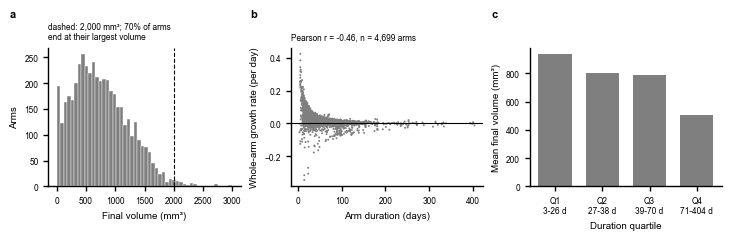

  saved outputs\figures\Supplementary_Figure_S1.{pdf,eps,tiff}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


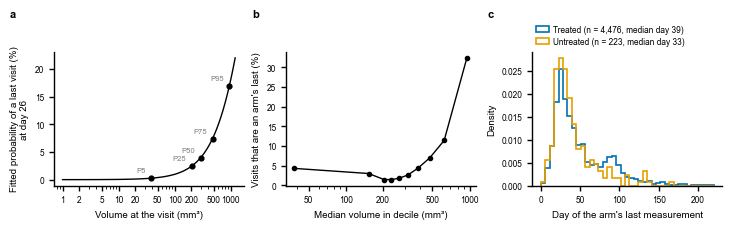

  saved outputs\figures\Supplementary_Figure_S2.{pdf,eps,tiff}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


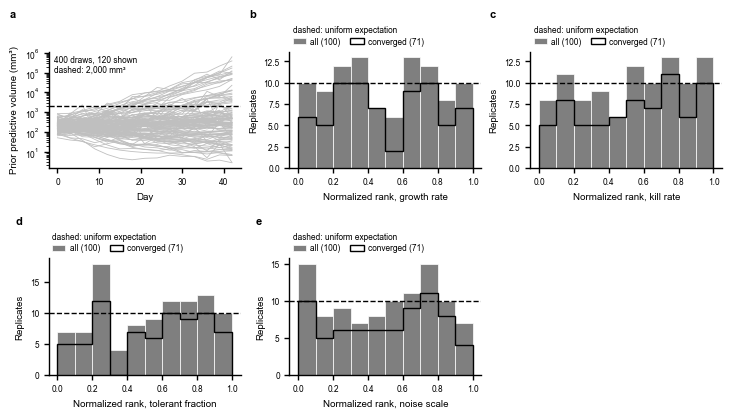

  saved outputs\figures\Supplementary_Figure_S3.{pdf,eps,tiff}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


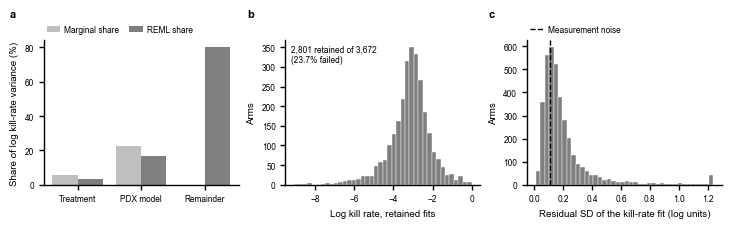

  saved outputs\figures\Supplementary_Figure_S4.{pdf,eps,tiff}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


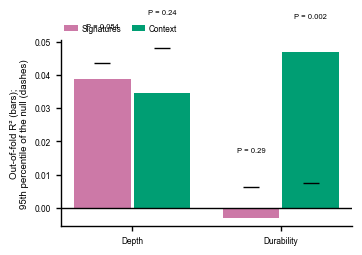

  saved outputs\figures\Supplementary_Figure_S5.{pdf,eps,tiff}  (87 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


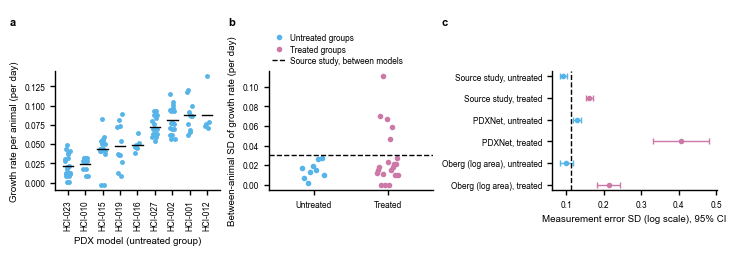

  saved outputs\figures\Supplementary_Figure_S6.{pdf,eps,tiff}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [12]:
# ==========================================================================
# Supplementary figures S1–S6
# ==========================================================================

def draw_s1_termination():
    # a  final volume of every arm; b  arm duration against the whole-arm
    # growth rate; c  mean final volume by duration quartile (3.4).
    quartiles = FROZEN["duration_quartiles"]
    complete = arm_design.dropna(subset=["overall_growth_rate"])
    figure, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH["double"], 55 * MM), layout="constrained")
    axes[0].hist(arm_design.last_volume, bins=50, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[0].axvline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_xlabel("Final volume (mm³)")
    axes[0].set_ylabel("Arms")
    axes[0].set_title(f"dashed: {TERMINATION_VOLUME:,.0f} mm³; "
                      f"{100 * (arm_design.last_volume >= arm_design.max_volume).mean():.0f}% of arms\n"
                      f"end at their largest volume", loc="left", fontsize=6)
    r = float(np.corrcoef(complete.duration_days, complete.overall_growth_rate)[0, 1])
    axes[1].scatter(complete.duration_days, complete.overall_growth_rate, s=2, color=COLORS["reference"],
                    edgecolor="none", rasterized=True)
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.8)
    axes[1].set_xlabel("Arm duration (days)")
    axes[1].set_ylabel("Whole-arm growth rate (per day)")
    axes[1].set_title(f"Pearson r = {r:.2f}, n = {len(complete):,} arms", loc="left", fontsize=6)
    axes[2].bar(range(len(quartiles)), quartiles.mean_last_volume, color=COLORS["reference"], width=0.7)
    axes[2].set_xticks(range(len(quartiles)), [f"{label}\n{days} d" for label, days in
                                               zip(quartiles.duration_quartile, quartiles.days)])
    axes[2].set_xlabel("Duration quartile")
    axes[2].set_ylabel("Mean final volume (mm³)")
    label_panels(axes)
    save_figure(figure, "termination")


def draw_s2_termination_hazard():
    # a  fitted probability that a visit is the arm's last, by volume, at the
    # median elapsed day, with the five volume percentiles of 6.3; b  the
    # observed share by volume decile; c  day of the last measurement in
    # treated and untreated arms.
    curve, points = FROZEN["termination_hazard_curve"], FROZEN["termination_hazard_points"]
    deciles, last_visits = FROZEN["termination_by_volume_decile"], FROZEN["last_visits"]
    figure, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH["double"], 55 * MM), layout="constrained")
    axes[0].plot(curve.volume, 100 * curve.probability_last_visit, color=COLORS["ink"])
    axes[0].scatter(points.volume, 100 * points.probability_last_visit, s=12, color=COLORS["ink"], zorder=3)
    for row in points.itertuples():
        axes[0].annotate(f"P{row.percentile}", (row.volume, 100 * row.probability_last_visit), xytext=(-4, 4),
                         textcoords="offset points", ha="right", fontsize=5.5, color=COLORS["reference"])
    axes[0].set_xscale("log")
    plain_log_axis(axes[0], "x")
    axes[0].set_xlabel("Volume at the visit (mm³)")
    axes[0].set_ylabel(f"Fitted probability of a last visit (%)\nat day {curve.day.iloc[0]:.0f}")
    axes[1].plot(deciles.volume, 100 * deciles.end_rate, marker="o", markersize=3, color=COLORS["ink"])
    axes[1].set_xscale("log")
    plain_log_axis(axes[1], "x")
    axes[1].set_xlabel("Median volume in decile (mm³)")
    axes[1].set_ylabel("Visits that are an arm's last (%)")
    bins = np.linspace(0, last_visits.day.quantile(0.99), 40)
    for is_control, label, color in ((False, "Treated", COLORS["trajectory"]), (True, "Untreated", COLORS["depth"])):
        days = last_visits.loc[last_visits.is_control.astype(bool) == is_control, "day"]
        axes[2].hist(days, bins=bins, density=True, histtype="step", linewidth=1.2, color=color,
                     label=f"{label} (n = {len(days):,}, median day {days.median():.0f})")
    axes[2].set_xlabel("Day of the arm's last measurement")
    axes[2].set_ylabel("Density")
    legend_above(axes[2])
    label_panels(axes)
    save_figure(figure, "termination_hazard")


def draw_s3_bayesian_checks():
    # a  prior predictive trajectories (120 draws) with the termination volume;
    # b–e  normalized SBC ranks of each calibrated parameter against the
    # uniform expectation (dashed), all replicates (bars) and converged
    # replicates only (black outline; split R̂ <= 1.05 and no divergence).
    prior = FROZEN["prior_predictive"]
    ranks = FROZEN["calibration_ranks"]
    by_replicate = ranks.groupby("replicate").agg(max_rhat=("split_rhat", "max"), divergences=("divergences", "first"))
    converged = by_replicate.index[(by_replicate.max_rhat <= 1.05) & (by_replicate.divergences == 0)]
    assert len(converged) == RESULTS["calibration_converged_replicates"]
    parameters = list(dict.fromkeys(ranks.parameter))
    figure, axes = plt.subplots(2, 3, figsize=(FIGURE_WIDTH["double"], 105 * MM), layout="constrained")
    figure.get_layout_engine().set(h_pad=0.08)
    axes = axes.ravel()
    for draw_id, block in list(prior.groupby("draw"))[:120]:
        axes[0].plot(block.day, block.volume, color=COLORS["light"], linewidth=0.6)
    axes[0].axhline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=1.0)
    axes[0].set_yscale("log")
    axes[0].set_xlabel("Day")
    axes[0].set_ylabel("Prior predictive volume (mm³)")
    corner_text(axes[0], f"{prior.draw.nunique():,} draws, 120 shown\ndashed: {TERMINATION_VOLUME:,.0f} mm³", "upper left")
    n_replicates = ranks.replicate.nunique()
    for axis, name in zip(axes[1:5], parameters):
        values = ranks.loc[ranks.parameter == name, "normalized_rank"]
        kept = ranks.loc[(ranks.parameter == name) & ranks.replicate.isin(converged), "normalized_rank"]
        axis.hist(values, bins=np.linspace(0, 1, 11), color=COLORS["reference"], edgecolor="white", linewidth=0.5,
                  label=f"all ({len(values)})")
        axis.hist(kept, bins=np.linspace(0, 1, 11), histtype="step", color=COLORS["ink"], linewidth=1.0,
                  label=f"converged ({len(kept)})")
        axis.axhline(n_replicates / 10, color=COLORS["ink"], linestyle="--", linewidth=1.0)
        axis.set_xlabel(f"Normalized rank, {name.replace('_', ' ')}")
        axis.set_ylabel("Replicates")
        legend_above(axis, ncols=2, title="dashed: uniform expectation")
    axes[5].axis("off")
    label_panels(axes[:1 + len(parameters[:4])])
    save_figure(figure, "bayesian_checks")


def draw_s4_kill_rate_partition():
    # a  variance shares of the log kill rate (marginal and REML); b  log kill
    # rates of retained fits; c  residual SD of every kill-rate fit against the
    # measurement noise.
    partition, kinetic = FROZEN["kill_rate_partition"], FROZEN["kinetic_estimates"]
    retained = kinetic.loc[~kinetic.failed_fit.astype(bool)]
    figure, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH["double"], 55 * MM), layout="constrained")
    positions = np.arange(len(partition))
    axes[0].bar(positions - 0.2, 100 * partition.marginal_share.fillna(0), 0.4, color=COLORS["light"],
                label="Marginal share")
    axes[0].bar(positions + 0.2, 100 * partition.reml_share, 0.4, color=COLORS["reference"], label="REML share")
    axes[0].set_xticks(positions, [str(name).split(" (")[0][:1].upper() + str(name).split(" (")[0][1:]
                                   for name in partition.component])
    axes[0].set_ylabel("Share of log kill-rate variance (%)")
    legend_above(axes[0], ncols=2)
    axes[1].hist(retained.log_kill_rate, bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[1].set_xlabel("Log kill rate, retained fits")
    axes[1].set_ylabel("Arms")
    corner_text(axes[1], f"{len(retained):,} retained of {len(kinetic):,}\n"
                         f"({100 * RESULTS['failed_kill_fit_share']:.1f}% failed)", "upper left")
    residual_spread = kinetic.residual_sd.clip(upper=kinetic.residual_sd.quantile(0.99))
    axes[2].hist(residual_spread, bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[2].axvline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=1.0, label="Measurement noise")
    axes[2].set_xlabel("Residual SD of the kill-rate fit (log units)")
    axes[2].set_ylabel("Arms")
    legend_above(axes[2])
    label_panels(axes)
    save_figure(figure, "kill_rate_partition")


def draw_s5_molecular():
    # Out-of-fold R² of the signature and context blocks for each endpoint, with
    # the 95th percentile of each block's shuffle null (dashes) and the
    # permutation P value above each bar.
    blocks = FROZEN["molecular_blocks"]
    outcomes = list(dict.fromkeys(blocks.outcome))
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"], 62 * MM), layout="constrained")
    for offset, (block_name, color) in zip((-0.2, 0.2), (("signatures", COLORS["fifth"]), ("context", COLORS["third"]))):
        rows = blocks.loc[blocks.block == block_name].set_index("outcome").reindex(outcomes)
        positions = np.arange(len(outcomes)) + offset
        axis.bar(positions, rows.r2, 0.38, color=color, label=block_name.capitalize())
        axis.scatter(positions, rows.null_95th, marker="_", s=120, color=COLORS["ink"], zorder=3)
        for x, r2, null, p in zip(positions, rows.r2, rows.null_95th, rows.permutation_p):
            axis.text(x, max(r2, null, 0) + 0.01, f"P = {figure_p(p)}", ha="center", va="bottom", fontsize=5.5)
    axis.axhline(0, color=COLORS["ink"], linewidth=1.0)
    axis.set_xticks(range(len(outcomes)), [label.capitalize() for label in outcomes])
    axis.set_ylabel("Out-of-fold R² (bars);\n95th percentile of the null (dashes)")
    legend_above(axis, ncols=2)
    save_figure(figure, "molecular")


def draw_s6_between_animal():
    # a  growth rate of each PDXNet animal in the untreated groups, by group;
    # b  corrected between-animal SD per group against the source study's
    #    between-model SD; c  measurement error estimates with 95% intervals.
    noise = FROZEN["external_noise"]
    animals, groups = FROZEN.get("pdxnet_animal_growth_rates"), FROZEN.get("pdxnet_between_animal_groups")
    has_pdxnet = groups is not None and len(groups) > 0
    n_panels = 3 if has_pdxnet else 1
    figure, axes = plt.subplots(1, n_panels, squeeze=False, layout="constrained", figsize=(
        FIGURE_WIDTH["double"] if n_panels == 3 else FIGURE_WIDTH["single"], 62 * MM))
    axes = axes.ravel()
    if has_pdxnet:
        untreated_groups = groups.loc[groups.is_control.astype(bool)].sort_values("mean_growth_rate")
        for position, group in enumerate(untreated_groups.itertuples()):
            rates = animals.loc[(animals.model_id == group.model_id) & (animals.arm == group.arm), "growth_rate"]
            axes[0].plot(position + jitter(len(rates), 0.3), rates, "o", color=COLORS["sixth"], markersize=2.5,
                         rasterized=True)
            axes[0].plot([position - 0.3, position + 0.3], [group.mean_growth_rate] * 2, color=COLORS["ink"])
        axes[0].set_xticks(range(len(untreated_groups)), untreated_groups.model_id, rotation=90)
        axes[0].set_xlabel("PDX model (untreated group)")
        axes[0].set_ylabel("Growth rate per animal (per day)")
        for offset, (label, color) in enumerate((("untreated", COLORS["sixth"]), ("treated", COLORS["fifth"]))):
            values = groups.loc[groups.is_control.astype(bool) == (label == "untreated"), "sd_corrected"]
            axes[1].plot(np.full(len(values), offset) + jitter(len(values), 0.3), values, "o", color=color,
                         markersize=3, label=f"{label.capitalize()} groups")
        axes[1].axhline(RESULTS["pdxe_between_model_sd"], color=COLORS["ink"], linestyle="--", linewidth=1.0,
                        label="Source study, between models")
        axes[1].set_xticks([0, 1], ["Untreated", "Treated"])
        axes[1].set_xlim(-0.6, 1.6)
        axes[1].set_ylabel("Between-animal SD of growth rate (per day)")
        legend_above(axes[1])
    shown = noise.loc[noise.triples == "all triples"].reset_index(drop=True)
    for position, row in shown.iterrows():
        color = COLORS["sixth"] if row.arm_type == "untreated" else COLORS["fifth"]
        axes[-1].errorbar(row.sigma, position, xerr=interval_errors(row.sigma, row.low, row.high), fmt="o",
                          color=color, markersize=3, capsize=2)
    axes[-1].axvline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=1.0)
    axes[-1].set_yticks(range(len(shown)), [f"{r.cohort}, {r.arm_type}" for r in shown.itertuples()])
    axes[-1].invert_yaxis()
    axes[-1].set_xlabel("Measurement error SD (log scale), 95% CI")
    label_panels(axes)
    save_figure(figure, "between_animal")


if DRAW_SUPPLEMENTARY_FIGURES:
    draw("Supplementary Figure S1", draw_s1_termination, requires=("arm_design", "duration_quartiles"))
    draw("Supplementary Figure S2", draw_s2_termination_hazard, requires=(
        "termination_hazard_curve", "termination_hazard_points", "termination_by_volume_decile", "last_visits"))
    draw("Supplementary Figure S3", draw_s3_bayesian_checks, requires=("prior_predictive", "calibration_ranks"))
    draw("Supplementary Figure S4", draw_s4_kill_rate_partition, requires=("kill_rate_partition", "kinetic_estimates"))
    draw("Supplementary Figure S5", draw_s5_molecular, requires=("molecular_blocks",))
    draw("Supplementary Figure S6", draw_s6_between_animal, requires=("external_noise",))

## 3 · Atlas of additional figures

Figures beyond the manuscript set, grouped by the analysis-notebook section whose saved results they draw, and within each section stratified where the data allow (by tumor type, treatment, compound family, trial, window or noise level). Each file name in `outputs/figures/atlas/` starts with the number of that analysis section (`04_rank_scatter` draws results of analysis Section 4), and each subsection lists its files. The atlas is exploratory: every number on these figures is either in the saved results or computed here for display only (intervals that appear only in the atlas use the figure seeds of Section 1.1 and `N_FIGURE_BOOTSTRAP` replicates). Atlas figures are drawn at journal width with 6–7 pt text and saved as PDF and PNG; switch `ATLAS_FORMATS` in Section 1.1 to the manuscript formats for any figure that is chosen for publication.

### 3.1 Data, design and attrition (analysis Sections 2 and 3)

| File | Content |
|---|---|
| `03_design_overview` | Arms per tumor type, PDX models per tumor type, treatments per PDX model, arms per treatment |
| `03_design_matrix` | Which treatments were given to which PDX models |
| `03_tumor_type_by_treatment` | Treated arms by tumor type and treatment |
| `03_schedules` | Measurements per arm, duration, spacing, and the share of arms still observed by day |
| `03_measurement_days` | Days on which volumes were measured, and the gaps between consecutive measurements |
| `03_volumes` | Baseline volume, baseline volume by tumor type, largest against final volume |
| `03_untreated_curves` | Untreated growth curves by tumor type |
| `03_treated_curves` | Volume relative to baseline for the most common treatments, with untreated arms for reference |
| `03_regrowth_phenotype` | Nadir ratio, regrowth multiple, phenotype share by tumor type and across thresholds |
| `03_untreated_growth_noise` | Untreated growth rate and measurement noise by tumor type |

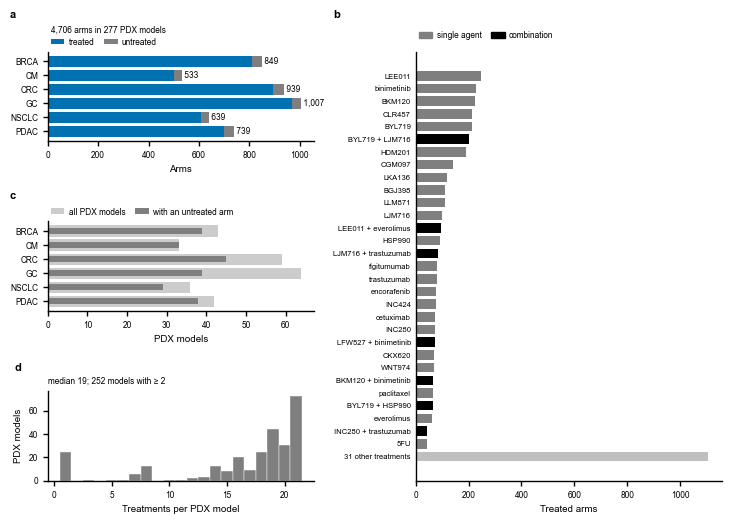

  saved outputs\figures\atlas\03_design_overview.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


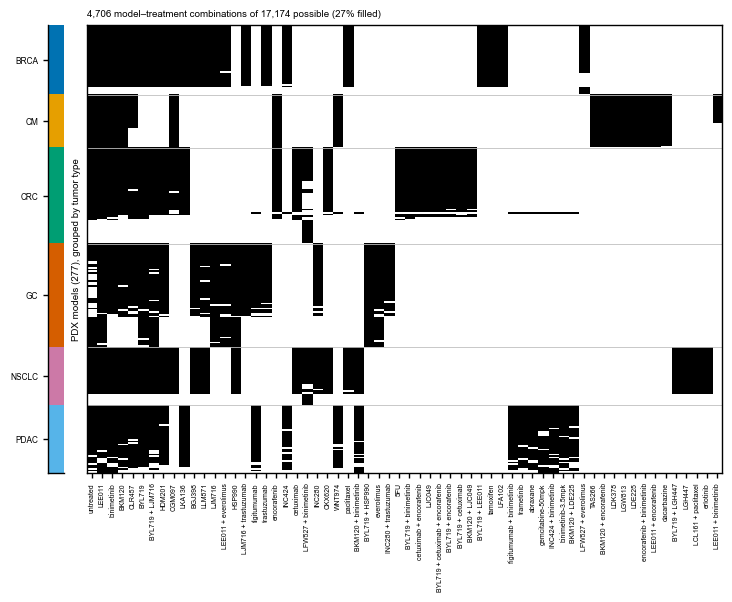

  saved outputs\figures\atlas\03_design_matrix.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


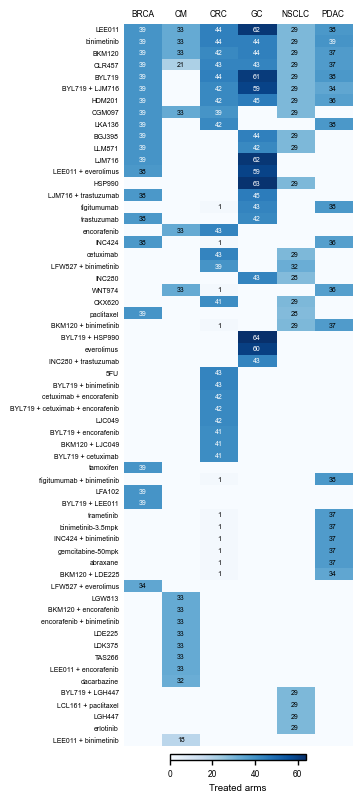

  saved outputs\figures\atlas\03_tumor_type_by_treatment.{pdf,png}  (87 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


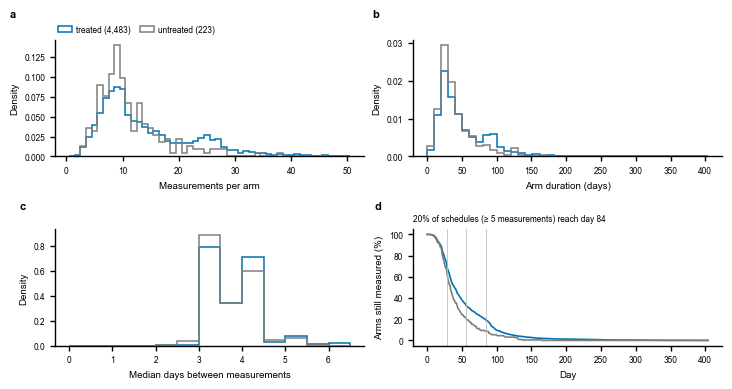

  saved outputs\figures\atlas\03_schedules.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


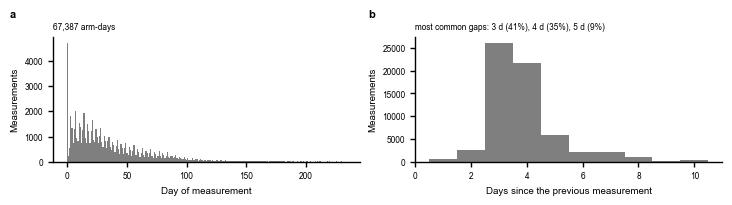

  saved outputs\figures\atlas\03_measurement_days.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


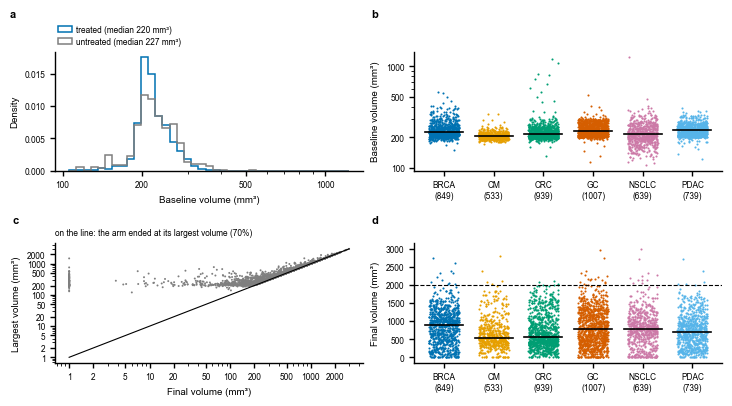

  saved outputs\figures\atlas\03_volumes.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


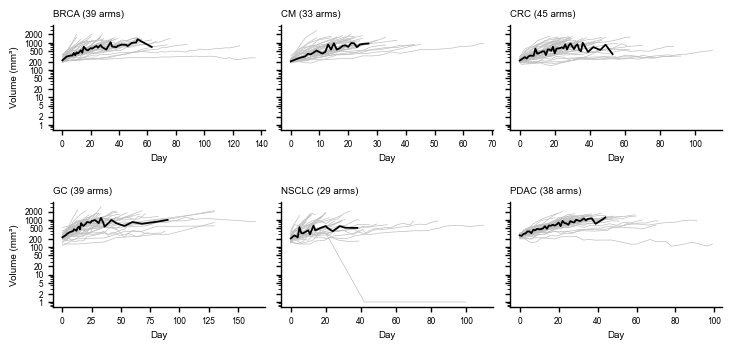

  saved outputs\figures\atlas\03_untreated_curves.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


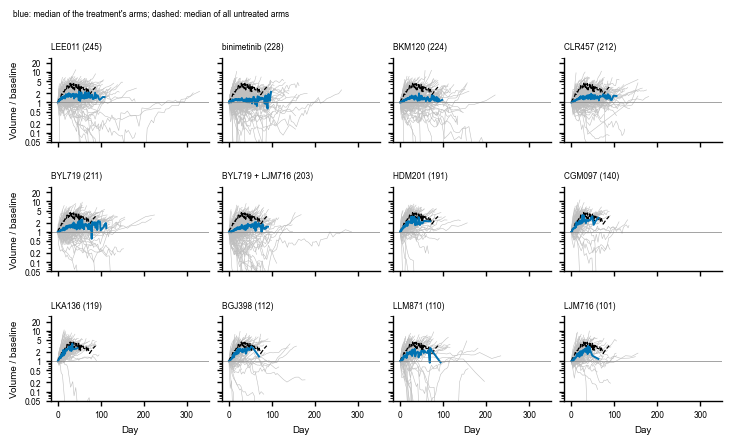

  saved outputs\figures\atlas\03_treated_curves.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


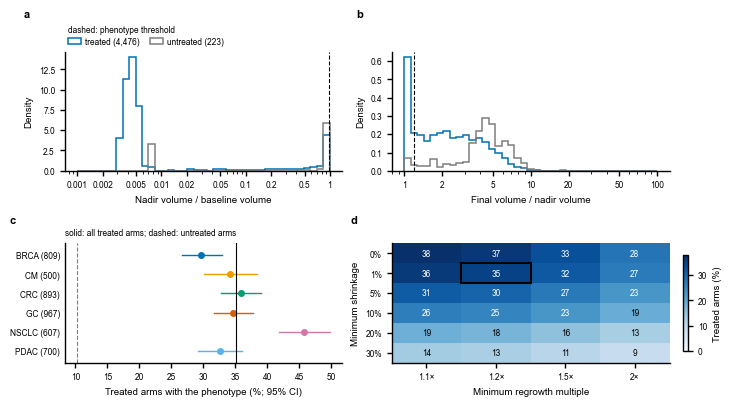

  saved outputs\figures\atlas\03_regrowth_phenotype.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


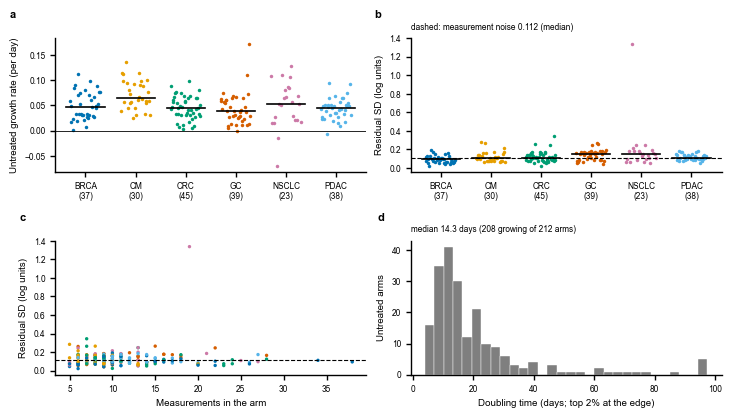

  saved outputs\figures\atlas\03_untreated_growth_noise.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [13]:
# ==========================================================================
# 3.1 Atlas: data, design and attrition (analysis Sections 2 and 3)
# ==========================================================================

def atlas_design_overview():
    # a  arms per tumor type (treated and untreated); b  arms per treatment
    # (the 30 most common; single agents and combinations); c  PDX models per
    # tumor type and those with an untreated arm; d  treatments per PDX model.
    figure, axes = plt.subplot_mosaic([["a", "b"], ["c", "b"], ["d", "b"]], figsize=(FIGURE_WIDTH["double"], 130 * MM),
                                      layout="constrained", width_ratios=[1.0, 1.15])
    # Arms per tumor type, split into treated (False) and untreated (True).
    counts = design.groupby(["tumor_type", "is_control"]).size().unstack(fill_value=0).reindex(TUMOR_TYPES)
    axes["a"].barh(TUMOR_TYPES, counts.get(False, 0), color=POPULATION_COLORS["treated"], label="treated")
    axes["a"].barh(TUMOR_TYPES, counts.get(True, 0), left=counts.get(False, 0), color=POPULATION_COLORS["untreated"],
                   label="untreated")
    for y, total in enumerate(counts.sum(axis=1)):
        axes["a"].text(total, y, f" {total:,}", va="center", fontsize=6)
    axes["a"].invert_yaxis()
    axes["a"].set_xlabel("Arms")
    legend_above(axes["a"], ncols=2, title=f"{len(design):,} arms in {design.model_id.nunique()} PDX models")
    models = design.groupby("tumor_type").model_id.nunique().reindex(TUMOR_TYPES)
    with_untreated = design.loc[design.is_control].groupby("tumor_type").model_id.nunique().reindex(TUMOR_TYPES).fillna(0)
    axes["c"].barh(TUMOR_TYPES, models, color=tint(COLORS["reference"], 0.4), label="all PDX models")
    axes["c"].barh(TUMOR_TYPES, with_untreated, color=COLORS["reference"], height=0.45, label="with an untreated arm")
    axes["c"].invert_yaxis()
    axes["c"].set_xlabel("PDX models")
    legend_above(axes["c"], ncols=2)
    per_model = treated_design.groupby("model_id").treatment.nunique()
    axes["d"].hist(per_model, bins=np.arange(0.5, per_model.max() + 1.5), color=COLORS["reference"],
                   edgecolor="white", linewidth=0.3)
    axes["d"].set_xlabel("Treatments per PDX model")
    axes["d"].set_ylabel("PDX models")
    axes["d"].set_title(f"median {per_model.median():.0f}; {int((per_model >= 2).sum())} models with ≥ 2", loc="left",
                        fontsize=6)
    # The 30 most common treatments; the rest are pooled into one bar so that
    # the panel stays legible with the full set of treatments.
    per_treatment = treated_design.treatment.value_counts()
    shown = per_treatment.head(30)
    rest = per_treatment.iloc[30:]
    labels = list(shown.index) + ([f"{len(rest)} other treatments"] if len(rest) else [])
    values = list(shown.values) + ([int(rest.sum())] if len(rest) else [])
    colors = [COLORS["ink"] if "+" in label else COLORS["reference"] for label in shown.index] + \
             ([COLORS["light"]] if len(rest) else [])
    axes["b"].barh(range(len(labels)), values, color=colors, height=0.75)
    axes["b"].set_yticks(range(len(labels)), labels, fontsize=5.5)
    axes["b"].invert_yaxis()
    axes["b"].tick_params(axis="y", length=0)
    axes["b"].set_xlabel("Treated arms")
    legend_above(axes["b"], ncols=2, handles=[Patch(color=COLORS["reference"], label="single agent"),
                                              Patch(color=COLORS["ink"], label="combination")])
    label_panels([axes[key] for key in "abcd"])
    save_atlas(figure, "03_design_overview")


def atlas_design_matrix():
    # Which treatments each PDX model received: one row per PDX model (grouped
    # by tumor type, most-treated first), one column per treatment (most
    # common first, untreated arms in the first column).
    # 1 where the PDX model has an arm of the treatment (replicate arms count once).
    present = pd.crosstab(design.model_id, design.treatment).clip(upper=1)
    treatment_order = [CONTROL_LABEL] + [t for t in present.sum().sort_values(ascending=False).index if t != CONTROL_LABEL]
    treatment_order = [t for t in treatment_order if t in present.columns]
    model_type = design.groupby("model_id").tumor_type.first()
    model_order = (pd.DataFrame({"type": model_type, "n": present.sum(axis=1)})
                   .sort_values(["type", "n"], ascending=[True, False]).index)
    matrix = present.loc[model_order, treatment_order].to_numpy(float)
    figure = plt.figure(figsize=(FIGURE_WIDTH["double"], 150 * MM), layout="constrained")
    grid = figure.add_gridspec(1, 2, width_ratios=[0.025, 1.0], wspace=0.01)
    strip, axis = figure.add_subplot(grid[0]), figure.add_subplot(grid[1])
    axis.imshow(matrix, aspect="auto", cmap=mpl.colors.ListedColormap(["white", COLORS["ink"]]), interpolation="nearest")
    axis.set_xticks(range(len(treatment_order)), treatment_order, rotation=90, fontsize=5)
    axis.set_yticks([])
    axis.set_ylabel(f"PDX models ({len(model_order)}), grouped by tumor type")
    for spine in axis.spines.values():
        spine.set_visible(True)
    type_codes = model_type.loc[model_order].map({t: i for i, t in enumerate(TUMOR_TYPES)}).to_numpy()[:, None]
    strip.imshow(type_codes, aspect="auto", interpolation="nearest",
                 cmap=mpl.colors.ListedColormap([TUMOR_TYPE_COLORS[t] for t in TUMOR_TYPES]),
                 vmin=-0.5, vmax=len(TUMOR_TYPES) - 0.5)
    strip.set_xticks([])
    edges = np.r_[0, np.cumsum(model_type.loc[model_order].value_counts().reindex(TUMOR_TYPES).fillna(0).to_numpy())]
    strip.set_yticks((edges[:-1] + edges[1:]) / 2 - 0.5, TUMOR_TYPES, fontsize=6)
    for edge in edges[1:-1]:
        axis.axhline(edge - 0.5, color=COLORS["light"], linewidth=0.6)
    axis.set_title(f"{int(matrix.sum()):,} model–treatment combinations of {matrix.size:,} possible "
                   f"({100 * matrix.mean():.0f}% filled)", loc="left")
    save_atlas(figure, "03_design_matrix")


def atlas_tumor_type_by_treatment():
    # Treated arms by treatment (rows, most common first) and tumor type
    # (columns), with the count in each cell.
    table = FROZEN["tumor_type_by_treatment"].set_index("tumor_type").T
    table = table.loc[table.sum(axis=1).sort_values(ascending=False).index]
    height = max(70, 2.8 * len(table) + 30)
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"], height * MM), layout="constrained")
    image = axis.imshow(table.to_numpy(float), aspect="auto", cmap="Blues", vmin=0)
    limit = table.to_numpy(float).max()
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = int(table.iat[i, j])
            if value:
                axis.text(j, i, f"{value}", ha="center", va="center", fontsize=5,
                          color="white" if value > 0.6 * limit else COLORS["ink"])
    axis.set_xticks(range(table.shape[1]), table.columns)
    axis.set_yticks(range(table.shape[0]), table.index, fontsize=5)
    axis.xaxis.tick_top()
    axis.tick_params(length=0)
    for spine in axis.spines.values():
        spine.set_visible(False)
    figure.colorbar(image, ax=axis, location="bottom", shrink=0.6, aspect=25, pad=0.01).set_label("Treated arms")
    save_atlas(figure, "03_tumor_type_by_treatment")


def atlas_schedules():
    # a  measurements per arm; b  arm duration; c  median spacing of
    # measurements; d  share of arms still under observation on each day.
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=50)
    for population, frame in (("treated", design.loc[~design.is_control]), ("untreated", design.loc[design.is_control])):
        color = POPULATION_COLORS[population]
        label = f"{population} ({len(frame):,})"
        axes[0].hist(frame.n_measurements, bins=np.arange(0.5, design.n_measurements.quantile(0.995) + 1.5),
                     density=True, histtype="step", color=color, linewidth=1.1, label=label)
        axes[1].hist(frame.duration_days, bins=40, range=(0, design.duration_days.max()), density=True,
                     histtype="step", color=color, linewidth=1.1)
        axes[2].hist(frame.median_gap_days.dropna(), bins=np.arange(0, design.median_gap_days.quantile(0.99) + 1, 0.5),
                     density=True, histtype="step", color=color, linewidth=1.1)
        days = np.arange(0, design.last_day.max() + 1)
        axes[3].plot(days, [100 * np.mean(frame.last_day >= day) for day in days], color=color, linewidth=1.2)
    axes[0].set_xlabel("Measurements per arm")
    axes[1].set_xlabel("Arm duration (days)")
    axes[2].set_xlabel("Median days between measurements")
    for axis in axes[:3]:
        axis.set_ylabel("Density")
    for day in (28, 56, 84):
        axes[3].axvline(day, color=COLORS["light"], linewidth=0.6)
    axes[3].set_xlabel("Day")
    axes[3].set_ylabel("Arms still measured (%)")
    axes[3].set_title(f"{100 * RESULTS['share_schedules_to_day_84']:.0f}% of schedules (≥ {MIN_MEASUREMENTS_PER_ARM} "
                      f"measurements) reach day 84", loc="left", fontsize=6)
    legend_above(axes[0], ncols=2)
    label_panels(axes)
    save_atlas(figure, "03_schedules")


def atlas_measurement_days():
    # a  every measurement day of every arm; b  gaps between consecutive
    # measurements of the same arm (both in one-day bins).
    # Days between consecutive measurements of the same arm (the first
    # measurement of each arm has no gap and is dropped).
    gaps = observations.sort_values(["arm_id", "day"]).groupby("arm_id").day.diff().dropna()
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=50)
    axes[0].hist(observations.day, bins=np.arange(-0.5, observations.day.quantile(0.995) + 1.5), color=COLORS["reference"],
                 linewidth=0)
    axes[0].set_xlabel("Day of measurement")
    axes[0].set_ylabel("Measurements")
    axes[0].set_title(f"{len(observations):,} arm-days", loc="left", fontsize=6)
    axes[1].hist(gaps, bins=np.arange(0.5, gaps.quantile(0.99) + 1.5), color=COLORS["reference"], linewidth=0)
    axes[1].set_xlabel("Days since the previous measurement")
    axes[1].set_ylabel("Measurements")
    shares = gaps.value_counts(normalize=True).head(3)
    axes[1].set_title("most common gaps: " + ", ".join(f"{int(day)} d ({100 * share:.0f}%)" for day, share in shares.items()),
                      loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "03_measurement_days")


def atlas_volumes():
    # a  baseline (first) volume of every arm; b  baseline volume by tumor
    # type; c  largest against final volume; d  final volume by tumor type.
    baseline = design.assign(baseline=design.arm_id.map(first_volumes))
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    bins = np.logspace(np.log10(max(baseline.baseline.min(), VOLUME_FLOOR)), np.log10(baseline.baseline.max()), 40)
    for population, frame in (("treated", baseline.loc[~baseline.is_control]), ("untreated", baseline.loc[baseline.is_control])):
        axes[0].hist(frame.baseline, bins=bins, density=True, histtype="step", color=POPULATION_COLORS[population],
                     linewidth=1.1, label=f"{population} (median {frame.baseline.median():.0f} mm³)")
    axes[0].set_xscale("log")
    plain_log_axis(axes[0], "x")
    axes[0].set_xlabel("Baseline volume (mm³)")
    axes[0].set_ylabel("Density")
    legend_above(axes[0])
    strip_plot(axes[1], {t: baseline.loc[baseline.tumor_type == t, "baseline"] for t in TUMOR_TYPES},
               colors=TUMOR_TYPE_COLORS, size=1.5, rasterized=True)
    axes[1].set_yscale("log")
    plain_log_axis(axes[1])
    axes[1].set_ylabel("Baseline volume (mm³)")
    axes[2].scatter(design.last_volume, design.max_volume, s=2, color=COLORS["reference"], edgecolor="none",
                    rasterized=True)
    limits = [max(design.last_volume.min(), VOLUME_FLOOR), design.max_volume.max()]
    axes[2].plot(limits, limits, color=COLORS["ink"], linewidth=0.8)
    axes[2].set_xscale("log")
    axes[2].set_yscale("log")
    plain_log_axis(axes[2], "x")
    plain_log_axis(axes[2], "y")
    axes[2].set_xlabel("Final volume (mm³)")
    axes[2].set_ylabel("Largest volume (mm³)")
    axes[2].set_title(f"on the line: the arm ended at its largest volume "
                      f"({100 * (design.last_volume >= design.max_volume).mean():.0f}%)", loc="left", fontsize=6)
    strip_plot(axes[3], {t: design.loc[design.tumor_type == t, "last_volume"] for t in TUMOR_TYPES},
               colors=TUMOR_TYPE_COLORS, size=1.5, rasterized=True)
    axes[3].axhline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[3].set_ylabel("Final volume (mm³)")
    label_panels(axes)
    save_atlas(figure, "03_volumes")


def atlas_untreated_curves():
    # Untreated arms of each tumor type: every arm (gray) and the median log
    # volume on each day with at least five arms (black).
    untreated = observations.loc[observations.is_control.astype(bool)]
    types = [t for t in TUMOR_TYPES if (untreated.tumor_type == t).any()]
    figure, axes = atlas_figure(len(types), ncols=3, panel_height_mm=45, sharey=True)
    for axis, tumor_type in zip(axes, types):
        part = untreated.loc[untreated.tumor_type == tumor_type]
        for _, block in part.groupby("arm_id"):
            axis.plot(block.day, block.volume, color=COLORS["light"], linewidth=0.5, rasterized=True)
        summary = median_by_day(part, "volume", min_arms=5)
        axis.plot(summary.index, summary["median"], color=COLORS["ink"], linewidth=1.3)
        axis.set_yscale("log")
        plain_log_axis(axis)
        axis.set_title(f"{tumor_type} ({part.arm_id.nunique()} arms)", loc="left")
        axis.set_xlabel("Day")
    for axis in axes[::3]:
        axis.set_ylabel("Volume (mm³)")
    save_atlas(figure, "03_untreated_curves")


def atlas_treated_curves():
    # Volume relative to baseline for the 12 most common treatments: every arm
    # (gray), the median on each day with at least ten arms (blue), and the
    # median of all untreated arms (dashed), on a shared scale.
    # Volume relative to the arm's first measurement; lines are clipped to
    # 0.01–100 so that a floored reading does not stretch the shared axis.
    relative = observations.assign(relative=observations.volume / observations.arm_id.map(first_volumes))
    untreated_median = median_by_day(relative.loc[relative.is_control.astype(bool)], "relative", min_arms=10)
    common = treated_design.treatment.value_counts().head(12).index
    figure, axes = atlas_figure(len(common), ncols=4, panel_height_mm=38, sharex=True, sharey=True)
    for axis, treatment in zip(axes, common):
        part = relative.loc[relative.treatment == treatment]
        for _, block in part.groupby("arm_id"):
            axis.plot(block.day, block.relative.clip(0.01, 100), color=COLORS["light"], linewidth=0.4, rasterized=True)
        summary = median_by_day(part, "relative", min_arms=10)
        axis.plot(untreated_median.index, untreated_median["median"], color=COLORS["ink"], linestyle="--", linewidth=0.9)
        axis.plot(summary.index, summary["median"], color=COLORS["trajectory"], linewidth=1.4)
        axis.axhline(1, color=COLORS["reference"], linewidth=0.5)
        axis.set_yscale("log")
        axis.set_ylim(0.05, 30)
        plain_log_axis(axis)
        axis.set_title(f"{treatment} ({part.arm_id.nunique()})", loc="left", fontsize=6)
    for axis in axes[-4:]:
        axis.set_xlabel("Day")
    for axis in axes[::4]:
        axis.set_ylabel("Volume / baseline")
    figure.suptitle("blue: median of the treatment's arms; dashed: median of all untreated arms", x=0.01, ha="left",
                    fontsize=6)
    save_atlas(figure, "03_treated_curves")


def atlas_regrowth_phenotype():
    # a  nadir-to-baseline ratio; b  regrowth multiple (last over nadir volume);
    # c  share of treated arms with the durability phenotype by tumor type
    # (Wilson 95% intervals; dashed: untreated arms); d  share of treated arms
    # with the phenotype across the two thresholds (outlined: the thresholds
    # used, REGRESSION_FRACTION and REGROWTH_MULTIPLE).
    treated_summary = FROZEN["treated_regrowth_summary"]
    untreated_summary = FROZEN["untreated_regrowth_summary"]
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    for population, frame in (("treated", treated_summary), ("untreated", untreated_summary)):
        color = POPULATION_COLORS[population]
        axes[0].hist(frame.nadir_ratio.clip(lower=1e-3), bins=np.logspace(-3, 0, 40), density=True, histtype="step",
                     color=color, linewidth=1.1, label=f"{population} ({len(frame):,})")
        axes[1].hist(frame.regrowth_multiple.clip(1, 100), bins=np.logspace(0, 2, 40), density=True, histtype="step",
                     color=color, linewidth=1.1)
    axes[0].axvline(1 - REGRESSION_FRACTION, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].axvline(REGROWTH_MULTIPLE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    for axis, label in ((axes[0], "Nadir volume / baseline volume"), (axes[1], "Final volume / nadir volume")):
        axis.set_xscale("log")
        plain_log_axis(axis, "x")
        axis.set_xlabel(label)
        axis.set_ylabel("Density")
    legend_above(axes[0], ncols=2, title="dashed: phenotype threshold")
    shares = [share_with_interval(part.durability_phenotype.astype(bool).sum(), len(part))
              for t, part in ((t, treated_summary.loc[treated_summary.tumor_type == t]) for t in TUMOR_TYPES)]
    forest_rows(axes[2], [f"{t} ({int((treated_summary.tumor_type == t).sum())})" for t in TUMOR_TYPES],
                [100 * s[0] for s in shares], [100 * s[1] for s in shares], [100 * s[2] for s in shares],
                colors=[TUMOR_TYPE_COLORS[t] for t in TUMOR_TYPES])
    axes[2].axvline(100 * RESULTS["untreated_phenotype_share"], color=COLORS["reference"], linestyle="--", linewidth=0.8)
    axes[2].axvline(100 * RESULTS["treated_phenotype_share"], color=COLORS["ink"], linewidth=0.8)
    axes[2].set_xlabel("Treated arms with the phenotype (%; 95% CI)")
    axes[2].set_title("solid: all treated arms; dashed: untreated arms", loc="left", fontsize=6)
    # The interior-nadir condition is fixed; the shrinkage and regrowth
    # thresholds vary over the grid (the phenotype rule of 3.3).
    interior = (treated_summary.nadir_index > 0) & (treated_summary.n_after_nadir >= MIN_POINTS_AFTER_NADIR)
    regressions, multiples = (0.0, 0.01, 0.05, 0.10, 0.20, 0.30), (1.10, 1.20, 1.50, 2.00)
    grid = np.array([[100 * ((treated_summary.nadir_ratio <= 1 - r) & interior
                             & (treated_summary.regrowth_multiple >= m)).mean() for m in multiples] for r in regressions])
    image = axes[3].imshow(grid, cmap="Blues", vmin=0, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            axes[3].text(j, i, f"{grid[i, j]:.0f}", ha="center", va="center", fontsize=6,
                         color="white" if grid[i, j] > 0.6 * grid.max() else COLORS["ink"])
    axes[3].add_patch(Rectangle((multiples.index(REGROWTH_MULTIPLE) - 0.5, regressions.index(REGRESSION_FRACTION) - 0.5),
                                1, 1, fill=False, edgecolor=COLORS["ink"], linewidth=1.5))
    axes[3].set_xticks(range(len(multiples)), [f"{m:g}×" for m in multiples])
    axes[3].set_yticks(range(len(regressions)), [f"{100 * r:g}%" for r in regressions])
    axes[3].set_xlabel("Minimum regrowth multiple")
    axes[3].set_ylabel("Minimum shrinkage")
    figure.colorbar(image, ax=axes[3], shrink=0.8).set_label("Treated arms (%)")
    label_panels(axes)
    save_atlas(figure, "03_regrowth_phenotype")


def atlas_untreated_growth_noise():
    # Line fits of the untreated arms (Section 1.4, as in 3.6): a  growth rate
    # by tumor type; b  residual SD (the measurement noise) by tumor type,
    # dashed at the median; c  residual SD against the number of
    # measurements; d  doubling time of the growing arms.
    fits = untreated_fits
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    strip_plot(axes[0], {t: fits.loc[fits.tumor_type == t, "growth_rate"] for t in TUMOR_TYPES}, colors=TUMOR_TYPE_COLORS)
    axes[0].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[0].set_ylabel("Untreated growth rate (per day)")
    strip_plot(axes[1], {t: fits.loc[fits.tumor_type == t, "residual_sd"] for t in TUMOR_TYPES}, colors=TUMOR_TYPE_COLORS)
    axes[1].axhline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].set_ylabel("Residual SD (log units)")
    axes[1].set_title(f"dashed: measurement noise {MEASUREMENT_NOISE:.3f} (median)", loc="left", fontsize=6)
    axes[2].scatter(fits.n_measurements, fits.residual_sd, s=6, color=[TUMOR_TYPE_COLORS[t] for t in fits.tumor_type],
                    edgecolor="none")
    axes[2].axhline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[2].set_xlabel("Measurements in the arm")
    axes[2].set_ylabel("Residual SD (log units)")
    doubling = np.log(2) / fits.loc[fits.growth_rate > 0, "growth_rate"]
    axes[3].hist(doubling.clip(upper=doubling.quantile(0.98)), bins=30, color=COLORS["reference"], edgecolor="white",
                 linewidth=0.3)
    axes[3].set_xlabel("Doubling time (days; top 2% at the edge)")
    axes[3].set_ylabel("Untreated arms")
    axes[3].set_title(f"median {doubling.median():.1f} days ({len(doubling)} growing of {len(fits)} arms)", loc="left",
                      fontsize=6)
    label_panels(axes)
    save_atlas(figure, "03_untreated_growth_noise")


if DRAW_ATLAS:
    draw("03_design_overview", atlas_design_overview, requires=("arm_design",))
    draw("03_design_matrix", atlas_design_matrix, requires=("arm_design",))
    draw("03_tumor_type_by_treatment", atlas_tumor_type_by_treatment, requires=("tumor_type_by_treatment",))
    draw("03_schedules", atlas_schedules, requires=("arm_design",))
    draw("03_measurement_days", atlas_measurement_days, requires=("observations_canonical",))
    draw("03_volumes", atlas_volumes, requires=("arm_design", "observations_canonical"))
    draw("03_untreated_curves", atlas_untreated_curves, requires=("observations_canonical",))
    draw("03_treated_curves", atlas_treated_curves, requires=("observations_canonical",))
    draw("03_regrowth_phenotype", atlas_regrowth_phenotype, requires=("treated_regrowth_summary",
                                                                      "untreated_regrowth_summary"))
    draw("03_untreated_growth_noise", atlas_untreated_growth_noise, requires=("observations_canonical",))

### 3.2 Endpoints: depth and durability (analysis Section 4)

| File | Content |
|---|---|
| `04_endpoint_distributions` | Best average response, post-nadir growth rate, response category and nadir day |
| `04_endpoints_by_stratum` | Both endpoints by tumor type and by treatment |
| `04_depth_durability_by_tumor_type` | The two endpoints within each tumor type, with ρ and a 95% interval resampling PDX models |
| `04_depth_durability_by_treatment` | The same within each treatment with at least 25 post-nadir arms |
| `04_rank_scatter` | Rank against rank, and the quintile-by-quintile table against independence |
| `04_sensitivity_all` | Every row of the sensitivity table, with its P (or q) value |
| `04_pair_gaps` | Within-model pairs: depth gap against rate gap, rate gaps of depth-matched pairs, the threshold grid, discordant share by tumor type |
| `04_endpoint_agreement` | Best average response recomputed against the published value, and the published doubling time against the post-nadir rate |
| `04_durability_precision` | Post-nadir rate against the number of points after the nadir, against duration, and both endpoints against baseline volume |
| `04_example_gallery` | Twelve arms spanning depth tertiles and durability quartiles |

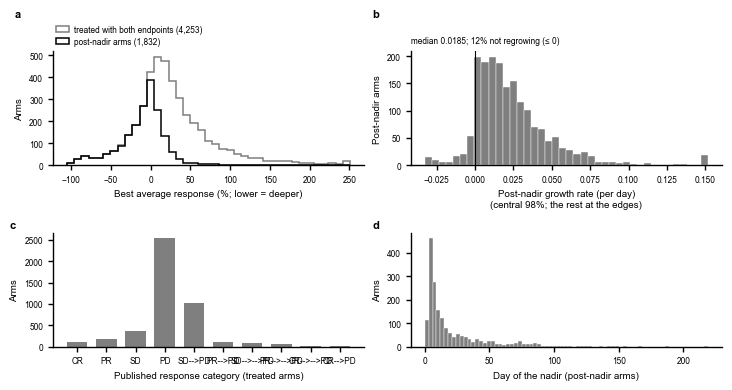

  saved outputs\figures\atlas\04_endpoint_distributions.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


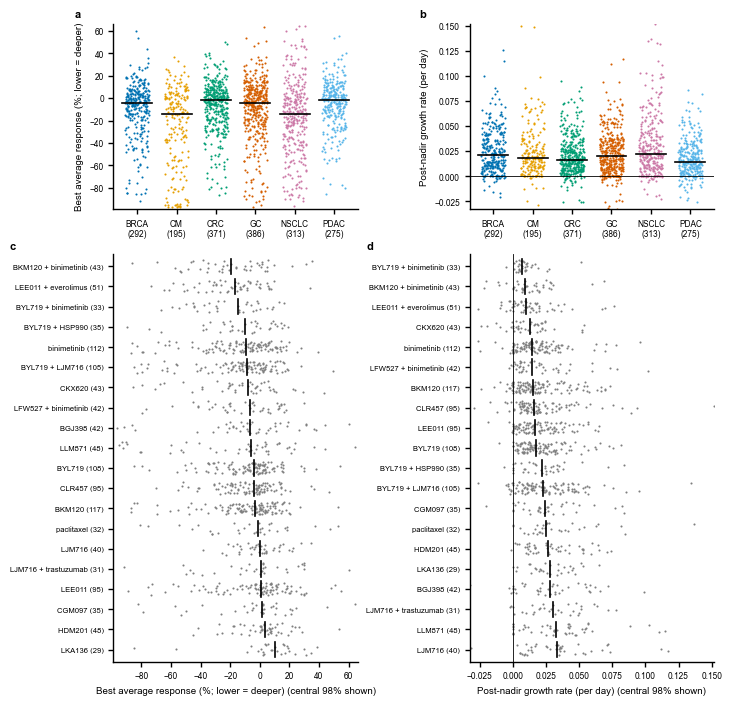

  saved outputs\figures\atlas\04_endpoints_by_stratum.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


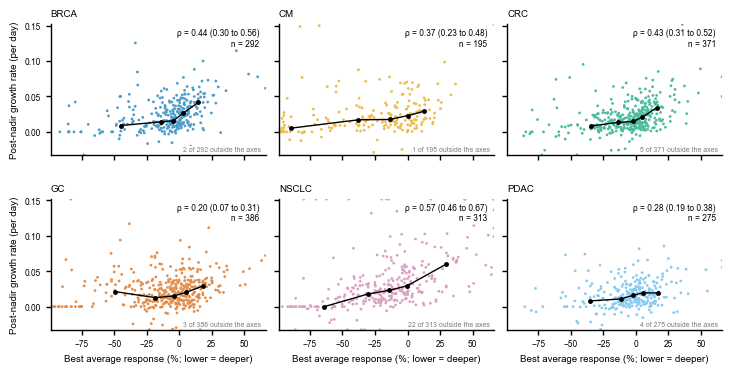

  saved outputs\figures\atlas\04_depth_durability_by_tumor_type.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


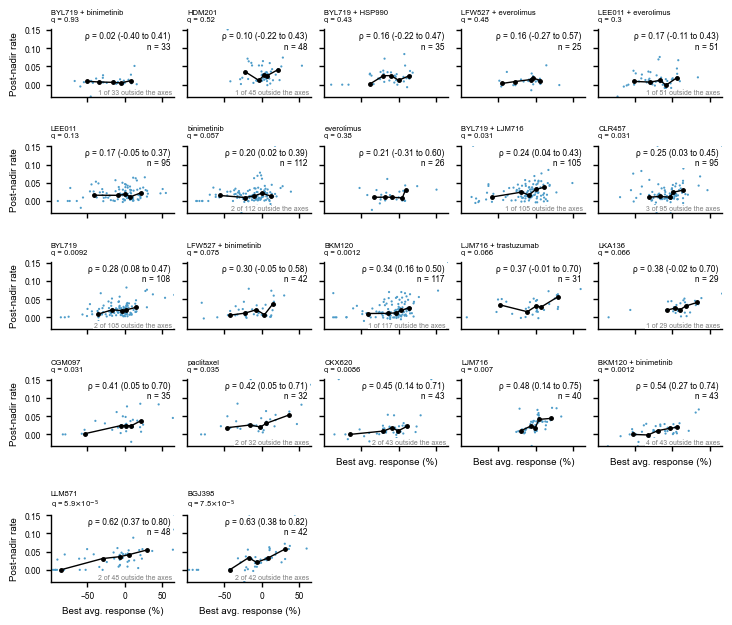

  saved outputs\figures\atlas\04_depth_durability_by_treatment.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


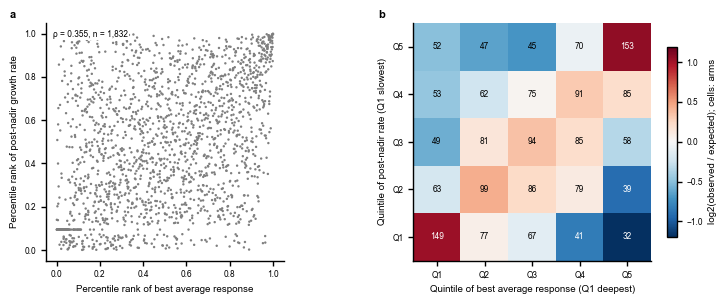

  saved outputs\figures\atlas\04_rank_scatter.{pdf,png}  (180 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


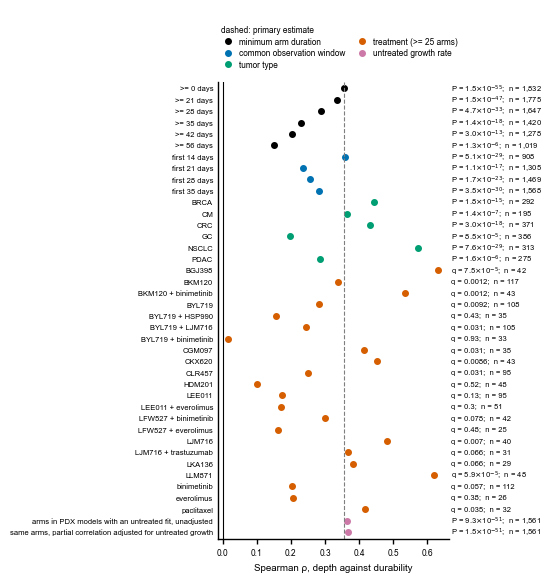

  saved outputs\figures\atlas\04_sensitivity_all.{pdf,png}  (135 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


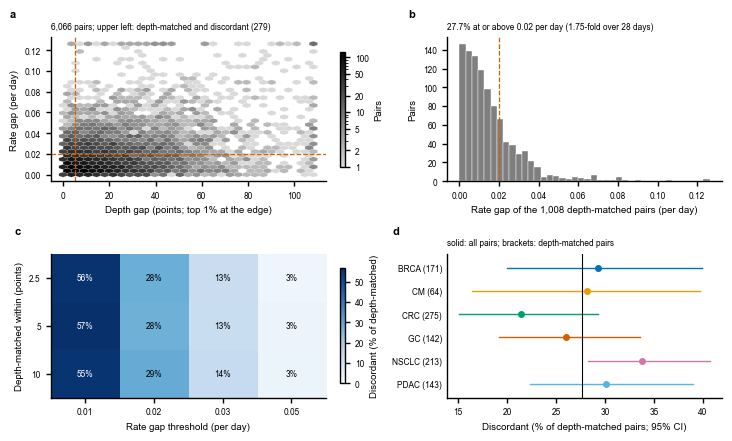

  saved outputs\figures\atlas\04_pair_gaps.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


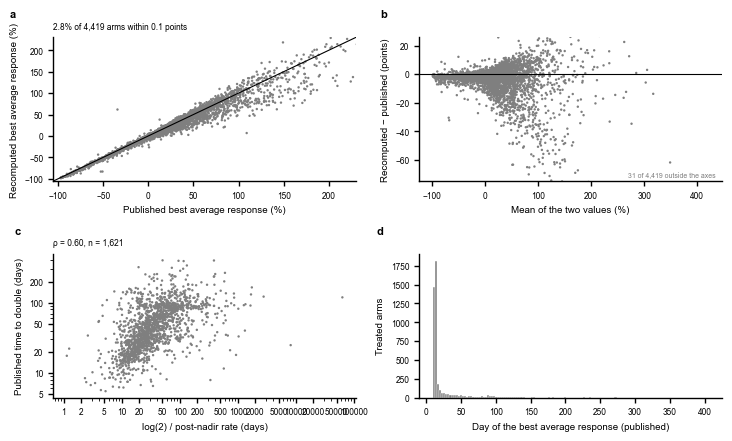

  saved outputs\figures\atlas\04_endpoint_agreement.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


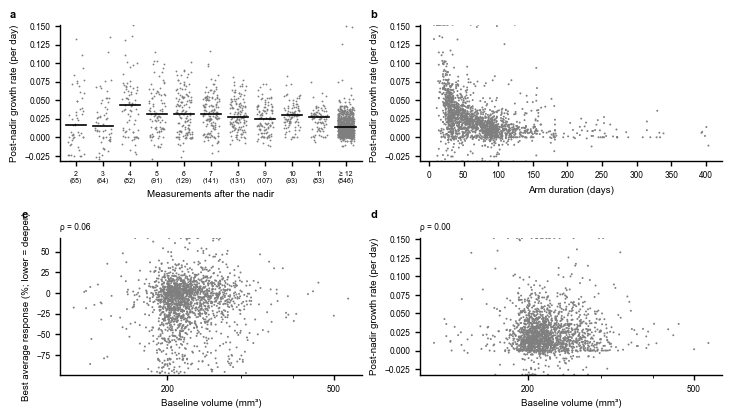

  saved outputs\figures\atlas\04_durability_precision.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


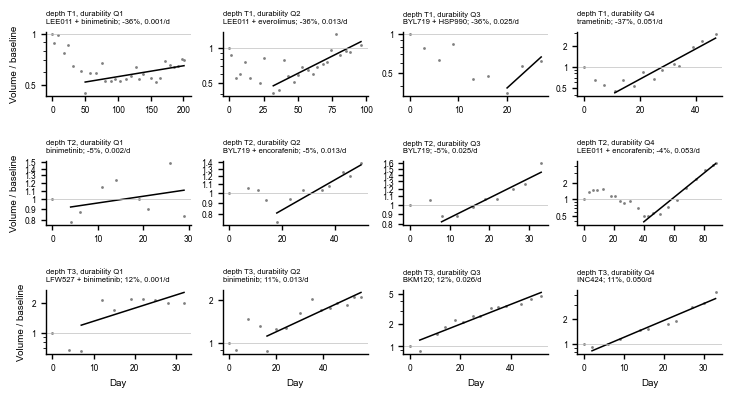

  saved outputs\figures\atlas\04_example_gallery.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [14]:
# ==========================================================================
# 3.2 Atlas: endpoints (analysis Section 4)
# ==========================================================================

def endpoint_scatter(axis, frame, color, rho_interval=None, size=4):
    """Depth against durability for the arms of `frame` on the shared limits,
    with the median rate in depth quintiles and ρ (interval when given)."""
    x, y = frame[DEPTH].to_numpy(float), frame[DURABILITY].to_numpy(float)
    axis.scatter(np.clip(x, *DEPTH_LIMITS), np.clip(y, *DURABILITY_LIMITS), s=size, color=tint(color, 0.7),
                 edgecolor="none", rasterized=True)
    if len(frame) >= 15:
        summary = binned_summary(x, y, n_bins=5)
        axis.plot(summary.x, summary["median"], "-o", color=COLORS["ink"], markersize=2.5, linewidth=1.0)
    axis.set_xlim(DEPTH_LIMITS)
    axis.set_ylim(DURABILITY_LIMITS)
    rho = spearman(x, y)[0]
    text = f"ρ = {rho:.2f}" + (f" ({rho_interval[0]:.2f} to {rho_interval[1]:.2f})" if rho_interval else "")
    corner_text(axis, f"{text}\nn = {len(frame):,}", "upper right",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.3})
    note_outside(axis, count_outside(x, y, DEPTH_LIMITS, DURABILITY_LIMITS), len(frame), location=(0.98, 0.02))


def atlas_endpoint_distributions():
    # a  best average response, all treated arms with both endpoints and the
    # post-nadir arms; b  post-nadir growth rate (post-nadir arms; central 98%);
    # c  published response category of treated arms; d  day of the nadir.
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=50)
    bins = np.linspace(*percentile_limits(treated_with_endpoints[DEPTH], 0.5, 99.5), 40)
    for frame, label, color in ((treated_with_endpoints, "treated with both endpoints", COLORS["reference"]),
                                (post_nadir_arms, "post-nadir arms", COLORS["ink"])):
        axes[0].hist(frame[DEPTH].clip(bins[0], bins[-1]), bins=bins, histtype="step", color=color, linewidth=1.1,
                     label=f"{label} ({len(frame):,})")
    axes[0].set_xlabel(DEPTH_LABEL)
    axes[0].set_ylabel("Arms")
    legend_above(axes[0])
    rates = post_nadir_arms[DURABILITY]
    axes[1].hist(rates.clip(*DURABILITY_LIMITS), bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[1].axvline(0, color=COLORS["ink"], linewidth=0.8)
    axes[1].set_xlabel(DURABILITY_LABEL + "\n(central 98%; the rest at the edges)")
    axes[1].set_ylabel("Post-nadir arms")
    axes[1].set_title(f"median {rates.median():.4f}; {100 * (rates <= 0).mean():.0f}% not regrowing (≤ 0)", loc="left",
                      fontsize=6)
    categories = arms.loc[~arms.is_control.astype(bool), "response_category"].fillna("missing").value_counts()
    order = [c for c in ("CR", "PR", "SD", "PD") if c in categories.index] + \
            [c for c in categories.index if c not in ("CR", "PR", "SD", "PD")]
    axes[2].bar(range(len(order)), categories.reindex(order), color=COLORS["reference"], width=0.7)
    axes[2].set_xticks(range(len(order)), order)
    axes[2].set_xlabel("Published response category (treated arms)")
    axes[2].set_ylabel("Arms")
    axes[3].hist(post_nadir_arms.nadir_day, bins=np.arange(0, post_nadir_arms.nadir_day.max() + 4, 3),
                 color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[3].set_xlabel("Day of the nadir (post-nadir arms)")
    axes[3].set_ylabel("Arms")
    label_panels(axes)
    save_atlas(figure, "04_endpoint_distributions")


def atlas_endpoints_by_stratum():
    # a, b  depth and durability of the post-nadir arms by tumor type;
    # c, d  the same by treatment (the 20 treatments with most post-nadir arms).
    figure, axes = plt.subplot_mosaic([["a", "b"], ["c", "d"]], figsize=(FIGURE_WIDTH["double"], 175 * MM),
                                      layout="constrained", height_ratios=[1.0, 2.2])
    figure.get_layout_engine().set(h_pad=0.08)
    for key, column, label in (("a", DEPTH, DEPTH_LABEL), ("b", DURABILITY, DURABILITY_LABEL)):
        strip_plot(axes[key], {t: post_nadir_arms.loc[post_nadir_arms.tumor_type == t, column] for t in TUMOR_TYPES},
                   colors=TUMOR_TYPE_COLORS, size=1.5, rasterized=True)
        axes[key].set_ylim(DEPTH_LIMITS if column == DEPTH else DURABILITY_LIMITS)
        axes[key].set_ylabel(label)
    common = post_nadir_arms.treatment.value_counts().head(20).index
    for key, column, label in (("c", DEPTH, DEPTH_LABEL), ("d", DURABILITY, DURABILITY_LABEL)):
        order = post_nadir_arms.loc[post_nadir_arms.treatment.isin(common)].groupby("treatment")[column].median()
        order = order.sort_values().index
        strip_plot(axes[key], {t: post_nadir_arms.loc[post_nadir_arms.treatment == t, column] for t in order},
                   size=1.5, vertical=False, rasterized=True)
        axes[key].set_xlim(DEPTH_LIMITS if column == DEPTH else DURABILITY_LIMITS)
        axes[key].tick_params(axis="y", labelsize=5.5)
        axes[key].set_xlabel(label + " (central 98% shown)")
    axes["b"].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes["d"].axvline(0, color=COLORS["ink"], linewidth=0.6)
    label_panels([axes[key] for key in "abcd"])
    save_atlas(figure, "04_endpoints_by_stratum")


def stratum_rho_intervals(frames):
    """{label: (low, high)} 95% interval of ρ for each frame, resampling PDX models."""
    rng = np.random.default_rng(FIGURE_SEEDS["atlas_rho_strata"])
    intervals = {}
    for label, frame in frames.items():
        x, y = frame[DEPTH].to_numpy(float), frame[DURABILITY].to_numpy(float)
        intervals[label] = bootstrap_interval(frame.model_id, lambda rows: spearman(x[rows], y[rows])[0],
                                              N_FIGURE_BOOTSTRAP, rng)
    return intervals


def atlas_depth_durability_by_tumor_type():
    # Depth against durability within each tumor type, on shared axes, with
    # the median rate in depth quintiles and ρ with a 95% interval resampling
    # PDX models (atlas only).
    frames = {t: post_nadir_arms.loc[post_nadir_arms.tumor_type == t] for t in TUMOR_TYPES}
    intervals = stratum_rho_intervals(frames)
    figure, axes = atlas_figure(len(frames), ncols=3, panel_height_mm=48, sharex=True, sharey=True)
    for axis, (label, frame) in zip(axes, frames.items()):
        endpoint_scatter(axis, frame, TUMOR_TYPE_COLORS[label], intervals[label])
        axis.set_title(label, loc="left")
    for axis in axes[-3:]:
        axis.set_xlabel(DEPTH_LABEL)
    for axis in axes[::3]:
        axis.set_ylabel(DURABILITY_LABEL)
    save_atlas(figure, "04_depth_durability_by_tumor_type")


def atlas_depth_durability_by_treatment():
    # The same within each treatment with at least 25 post-nadir arms (the
    # treatments of 4.3), ordered by ρ; q is the Benjamini–Hochberg value of 4.3.
    table = FROZEN["depth_durability_sensitivity"]
    rows = table.loc[table.analysis.str.startswith("treatment")].sort_values("spearman_rho")
    frames = {row.subset: post_nadir_arms.loc[post_nadir_arms.treatment == row.subset] for row in rows.itertuples()}
    q_values = dict(zip(rows.subset, rows.q_value))
    intervals = stratum_rho_intervals(frames)
    figure, axes = atlas_figure(len(frames), ncols=5, panel_height_mm=32, sharex=True, sharey=True)
    for axis, (label, frame) in zip(axes, frames.items()):
        endpoint_scatter(axis, frame, COLORS["trajectory"], intervals[label], size=2.5)
        axis.set_title(f"{label}\nq = {figure_p(q_values[label])}", loc="left", fontsize=5.5)
    for axis in axes[-5:]:
        axis.set_xlabel("Best avg. response (%)")
    for axis in axes[::5]:
        axis.set_ylabel("Post-nadir rate")
    save_atlas(figure, "04_depth_durability_by_treatment")


def atlas_rank_scatter():
    # a  percentile rank of depth against percentile rank of durability (deeper
    # and slower regrowth to the left and bottom); b  arms in each quintile
    # pair relative to the count expected if the ranks were independent
    # (log2 scale: 0 = as expected).
    # Percentile ranks over the post-nadir arms; independent endpoints fill
    # the unit square evenly.
    ranks = post_nadir_arms[[DEPTH, DURABILITY]].rank(pct=True)
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=75)
    axes[0].scatter(ranks[DEPTH], ranks[DURABILITY], s=3, color=COLORS["reference"], edgecolor="none", rasterized=True)
    axes[0].set_xlabel("Percentile rank of best average response")
    axes[0].set_ylabel("Percentile rank of post-nadir growth rate")
    axes[0].set_aspect("equal")
    corner_text(axes[0], f"ρ = {RESULTS['depth_durability_rho']:.3f}, n = {len(ranks):,}", "upper left",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5})
    # Quintile (0–4) of each endpoint, and the count expected in each cell from
    # the row and column totals if the two were independent.
    quintiles = (np.minimum((ranks * 5).apply(np.ceil), 5) - 1).astype(int)
    observed = pd.crosstab(quintiles[DURABILITY], quintiles[DEPTH]).reindex(index=range(5), columns=range(5), fill_value=0)
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.to_numpy().sum()
    ratio = np.log2(np.clip(observed.to_numpy() / expected, 1e-3, None))
    limit = max(np.abs(ratio).max(), 0.1)
    image = axes[1].imshow(ratio, cmap="RdBu_r", vmin=-limit, vmax=limit, origin="lower")
    for i in range(5):
        for j in range(5):
            axes[1].text(j, i, f"{observed.iat[i, j]}", ha="center", va="center", fontsize=6,
                         color="white" if abs(ratio[i, j]) > 0.6 * limit else COLORS["ink"])
    axes[1].set_xticks(range(5), [f"Q{k}" for k in range(1, 6)])
    axes[1].set_yticks(range(5), [f"Q{k}" for k in range(1, 6)])
    axes[1].set_xlabel("Quintile of best average response (Q1 deepest)")
    axes[1].set_ylabel("Quintile of post-nadir rate (Q1 slowest)")
    figure.colorbar(image, ax=axes[1], shrink=0.8).set_label("log2(observed / expected); cells: arms")
    label_panels(axes)
    save_atlas(figure, "04_rank_scatter")


def atlas_sensitivity_all():
    # Every row of the sensitivity table of 4.3: ρ with its P value (q for the
    # treatment rows) and the number of arms, grouped by analysis.
    table = FROZEN["depth_durability_sensitivity"].reset_index(drop=True)
    groups = list(dict.fromkeys(table.analysis))
    group_colors = dict(zip(groups, [COLORS["ink"], COLORS["trajectory"], COLORS["third"], COLORS["fourth"],
                                     COLORS["fifth"], COLORS["sixth"]] + [COLORS["reference"]] * 10))
    height = max(80, 3.0 * len(table) + 25)
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"] * 0.75, height * MM), layout="constrained")
    labels = [f"{row.subset}" for row in table.itertuples()]
    forest_rows(axis, labels, table.spearman_rho, [np.nan] * len(table), [np.nan] * len(table),
                colors=[group_colors[a] for a in table.analysis], reference=0)
    for y, row in enumerate(table.itertuples()):
        p_text = f"q = {figure_p(row.q_value)}" if pd.notna(row.q_value) else f"P = {figure_p(row.p_value)}"
        axis.text(1.01, y, f"{p_text};  n = {int(row.n_arms):,}", transform=axis.get_yaxis_transform(), va="center",
                  fontsize=5.5)
    axis.axvline(RESULTS["depth_durability_rho"], color=COLORS["reference"], linestyle="--", linewidth=0.8)
    axis.tick_params(axis="y", labelsize=5.5)
    axis.set_xlabel("Spearman ρ, depth against durability")
    legend_above(axis, ncols=2, handles=[Line2D([], [], marker="o", linestyle="", color=group_colors[g], markersize=4,
                                                label=g) for g in groups], title="dashed: primary estimate")
    save_atlas(figure, "04_sensitivity_all")


def atlas_pair_gaps():
    # Within-model treatment pairs of 4.4. a  depth gap against rate gap
    # (dashed: the two thresholds; pairs left of the vertical line are
    # depth-matched, and those also above the horizontal line are
    # discordant); b  rate gaps of the depth-matched pairs; c  share of depth-matched pairs that are discordant
    # across both thresholds; d  that share by tumor type, with a 95% interval
    # resampling PDX models (atlas only).
    # Each pair takes its PDX model's tumor type (both arms share the model).
    pairs = treatment_pairs.assign(tumor_type=treatment_pairs.model_id.map(arms.groupby("model_id").tumor_type.first()))
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=55)
    x_limit = pairs.response_gap.quantile(0.99)
    y_limit = pairs.growth_rate_gap.quantile(0.99)
    hexes = axes[0].hexbin(pairs.response_gap.clip(upper=x_limit), pairs.growth_rate_gap.clip(upper=y_limit), gridsize=30,
                           cmap=gray_ramp(), mincnt=1, bins="log", linewidths=0.1, edgecolors="white")
    axes[0].axvline(RESPONSE_TOLERANCE, color=COLORS["fourth"], linestyle="--", linewidth=0.9)
    axes[0].axhline(GROWTH_RATE_GAP, color=COLORS["fourth"], linestyle="--", linewidth=0.9)
    axes[0].set_xlabel("Depth gap (points; top 1% at the edge)")
    axes[0].set_ylabel("Rate gap (per day)")
    axes[0].set_title(f"{len(pairs):,} pairs; upper left: depth-matched and discordant "
                      f"({int(pairs.discordant.sum()):,})", loc="left", fontsize=6)
    plain_log_colorbar(figure.colorbar(hexes, ax=axes[0], shrink=0.8)).set_label("Pairs")
    matched = pairs.loc[pairs.depth_matched]
    axes[1].hist(matched.growth_rate_gap.clip(upper=y_limit), bins=40, color=COLORS["reference"], edgecolor="white",
                 linewidth=0.3)
    axes[1].axvline(GROWTH_RATE_GAP, color=COLORS["fourth"], linestyle="--", linewidth=0.9)
    axes[1].set_xlabel(f"Rate gap of the {len(matched):,} depth-matched pairs (per day)")
    axes[1].set_ylabel("Pairs")
    axes[1].set_title(f"{100 * RESULTS['discordant_share']:.1f}% at or above {GROWTH_RATE_GAP} per day "
                      f"({RESULTS['fold_change_28_days']:.2f}-fold over {PAIR_HORIZON_DAYS} days)", loc="left", fontsize=6)
    sweep = FROZEN["pair_threshold_sweep"]
    grid = sweep.pivot(index="response tolerance (points)", columns="rate gap (per day)", values="share of depth-matched")
    image = axes[2].imshow(100 * grid.to_numpy(float), cmap="Blues", vmin=0, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            value = 100 * grid.iat[i, j]
            axes[2].text(j, i, f"{value:.0f}%", ha="center", va="center", fontsize=6,
                         color="white" if value > 0.6 * 100 * grid.to_numpy().max() else COLORS["ink"])
    axes[2].set_xticks(range(grid.shape[1]), [f"{gap:g}" for gap in grid.columns])
    axes[2].set_yticks(range(grid.shape[0]), [f"{tolerance:g}" for tolerance in grid.index])
    axes[2].set_xlabel("Rate gap threshold (per day)")
    axes[2].set_ylabel("Depth-matched within (points)")
    figure.colorbar(image, ax=axes[2], shrink=0.8).set_label("Discordant (% of depth-matched)")
    rng = np.random.default_rng(FIGURE_SEEDS["atlas_pair_strata"])
    rows = []
    for tumor_type in TUMOR_TYPES:
        part = pairs.loc[pairs.tumor_type == tumor_type].reset_index(drop=True)
        hits, matches = part.discordant.to_numpy(), part.depth_matched.to_numpy()
        if matches.sum() == 0:
            continue
        low, high = bootstrap_interval(part.model_id, lambda r: hits[r].sum() / max(matches[r].sum(), 1),
                                       N_FIGURE_BOOTSTRAP, rng)
        rows.append((f"{tumor_type} ({int(matches.sum())})", 100 * hits.sum() / matches.sum(), 100 * low, 100 * high,
                     TUMOR_TYPE_COLORS[tumor_type]))
    forest_rows(axes[3], [r[0] for r in rows], [r[1] for r in rows], [r[2] for r in rows], [r[3] for r in rows],
                colors=[r[4] for r in rows])
    axes[3].axvline(100 * RESULTS["discordant_share"], color=COLORS["ink"], linewidth=0.8)
    axes[3].set_xlabel("Discordant (% of depth-matched pairs; 95% CI)")
    axes[3].set_title("solid: all pairs; brackets: depth-matched pairs", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "04_pair_gaps")


def atlas_endpoint_agreement():
    # a  best average response recomputed from the canonical table (pdxe_utils)
    # against the published value; b  their difference against their mean;
    # c  published time to double against log(2) / post-nadir rate (arms with
    # a positive rate and a published value); d  day of the best average response.
    frame = arms.loc[~arms.is_control.astype(bool)].dropna(subset=["response_reimplemented", "best_average_response"])
    difference = frame.response_reimplemented - frame.best_average_response
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=55)
    limits = percentile_limits(np.r_[frame.best_average_response, frame.response_reimplemented], 0.5, 99.5)
    axes[0].scatter(frame.best_average_response, frame.response_reimplemented, s=3, color=COLORS["reference"],
                    edgecolor="none", rasterized=True)
    axes[0].plot(limits, limits, color=COLORS["ink"], linewidth=0.8)
    axes[0].set_xlim(limits)
    axes[0].set_ylim(limits)
    axes[0].set_xlabel("Published best average response (%)")
    axes[0].set_ylabel("Recomputed best average response (%)")
    axes[0].set_title(f"{100 * (difference.abs() <= 0.1).mean():.1f}% of {len(frame):,} arms within 0.1 points",
                      loc="left", fontsize=6)
    mean = (frame.response_reimplemented + frame.best_average_response) / 2
    axes[1].scatter(mean, difference, s=3, color=COLORS["reference"], edgecolor="none", rasterized=True)
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.8)
    axes[1].set_xlabel("Mean of the two values (%)")
    axes[1].set_ylabel("Recomputed − published (points)")
    difference_limits = percentile_limits(difference, 0.5, 99.5)
    if difference_limits[1] - difference_limits[0] < 0.2:          # identical values: show ± 0.5 points
        difference_limits = (-0.5, 0.5)
    axes[1].set_ylim(*difference_limits)
    note_outside(axes[1], count_outside(mean, difference, axes[1].get_xlim(), axes[1].get_ylim()), len(frame))
    doubling = post_nadir_arms.loc[(post_nadir_arms[DURABILITY] > 0) & post_nadir_arms.time_to_double_published.notna()
                                   & (post_nadir_arms.time_to_double_published > 0)]
    if len(doubling) >= 10:
        implied = np.log(2) / doubling[DURABILITY]
        axes[2].scatter(implied, doubling.time_to_double_published, s=3, color=COLORS["reference"], edgecolor="none",
                        rasterized=True)
        axes[2].set_xscale("log")
        axes[2].set_yscale("log")
        plain_log_axis(axes[2], "x")
        plain_log_axis(axes[2], "y")
        rho = spearman(implied, doubling.time_to_double_published)[0]
        axes[2].set_title((f"ρ = {rho:.2f}" if np.isfinite(rho) else "ρ not defined (a constant value)")
                          + f", n = {len(doubling):,}", loc="left", fontsize=6)
    else:
        axes[2].text(0.5, 0.5, "fewer than 10 arms with a published\ntime to double", transform=axes[2].transAxes,
                     ha="center", va="center")
    axes[2].set_xlabel("log(2) / post-nadir rate (days)")
    axes[2].set_ylabel("Published time to double (days)")
    days = frame.day_best_average_response.dropna()
    axes[3].hist(days, bins=np.arange(MIN_DAY_FOR_BEST_AVERAGE_RESPONSE - 0.5, days.max() + 3, 3),
                 color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[3].set_xlabel("Day of the best average response (published)")
    axes[3].set_ylabel("Treated arms")
    label_panels(axes)
    save_atlas(figure, "04_endpoint_agreement")


def atlas_durability_precision():
    # a  post-nadir rate by the number of measurements after the nadir; b  the
    # rate against arm duration; c, d  depth and durability against baseline
    # volume (log scale).
    frame = post_nadir_arms
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    counts = frame.n_after_nadir.clip(upper=12)
    strip_plot(axes[0], {f"{k}" if k < 12 else "≥ 12": frame.loc[counts == k, DURABILITY] for k in sorted(counts.unique())},
               size=1.3, rasterized=True)
    axes[0].set_ylim(DURABILITY_LIMITS)
    axes[0].set_xlabel("Measurements after the nadir")
    axes[0].set_ylabel(DURABILITY_LABEL)
    axes[0].tick_params(axis="x", labelsize=5)
    axes[1].scatter(frame.duration_days, frame[DURABILITY].clip(*DURABILITY_LIMITS), s=2, color=COLORS["reference"],
                    edgecolor="none", rasterized=True)
    axes[1].set_ylim(DURABILITY_LIMITS)
    axes[1].set_xlabel("Arm duration (days)")
    axes[1].set_ylabel(DURABILITY_LABEL)
    for axis, column, limits, label in ((axes[2], DEPTH, DEPTH_LIMITS, DEPTH_LABEL),
                                        (axes[3], DURABILITY, DURABILITY_LIMITS, DURABILITY_LABEL)):
        axis.scatter(frame.baseline_volume, frame[column].clip(*limits), s=2, color=COLORS["reference"],
                     edgecolor="none", rasterized=True)
        axis.set_xscale("log")
        plain_log_axis(axis, "x")
        axis.set_ylim(limits)
        axis.set_xlabel("Baseline volume (mm³)")
        axis.set_ylabel(label)
        axis.set_title(f"ρ = {spearman(frame.baseline_volume, frame[column])[0]:.2f}", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "04_durability_precision")


def atlas_example_gallery():
    # Twelve post-nadir arms (at least eight measurements): for each depth
    # tertile (rows) and durability quartile (columns), the arm closest to the
    # centre of that cell in rank space. Volume relative to baseline with the
    # post-nadir line.
    # Ranks are taken over all post-nadir arms, so the cells are tertiles and
    # quartiles of the full set, not of the arms with eight measurements.
    candidates = post_nadir_arms.loc[post_nadir_arms.n_measurements >= 8].copy()
    ranks = post_nadir_arms[[DEPTH, DURABILITY]].rank(pct=True).loc[candidates.index]
    figure, axes = atlas_figure(12, ncols=4, panel_height_mm=34)
    for row in range(3):
        for column in range(4):
            axis = axes[4 * row + column]
            centre = ((row + 0.5) / 3, (column + 0.5) / 4)
            distance = (ranks[DEPTH] - centre[0]) ** 2 + (ranks[DURABILITY] - centre[1]) ** 2
            arm = candidates.loc[distance.idxmin()]
            day, volume = arm_curve(observations, arm.arm_id)
            relative_volume = volume / volume[0]
            nadir, slope, intercept = post_nadir_line(day, np.log(relative_volume))
            axis.plot(day, relative_volume, "o", color=COLORS["reference"], markersize=2, markeredgewidth=0)
            axis.plot(day[nadir:], np.exp(intercept + slope * (day[nadir:] - day[nadir])), color=COLORS["ink"],
                      linewidth=1.1)
            axis.axhline(1, color=COLORS["light"], linewidth=0.5)
            axis.set_yscale("log")
            plain_log_axis(axis)
            axis.set_title(f"depth T{row + 1}, durability Q{column + 1}\n{arm.treatment}; "
                           f"{arm[DEPTH]:.0f}%, {arm[DURABILITY]:.3f}/d", loc="left", fontsize=5.5)
    for axis in axes[-4:]:
        axis.set_xlabel("Day")
    for axis in axes[::4]:
        axis.set_ylabel("Volume / baseline")
    save_atlas(figure, "04_example_gallery")


if DRAW_ATLAS:
    draw("04_endpoint_distributions", atlas_endpoint_distributions, requires=("arm_endpoints",))
    draw("04_endpoints_by_stratum", atlas_endpoints_by_stratum, requires=("arm_endpoints",))
    draw("04_depth_durability_by_tumor_type", atlas_depth_durability_by_tumor_type, requires=("arm_endpoints",))
    draw("04_depth_durability_by_treatment", atlas_depth_durability_by_treatment,
         requires=("arm_endpoints", "depth_durability_sensitivity"))
    draw("04_rank_scatter", atlas_rank_scatter, requires=("arm_endpoints",))
    draw("04_sensitivity_all", atlas_sensitivity_all, requires=("depth_durability_sensitivity",))
    draw("04_pair_gaps", atlas_pair_gaps, requires=("treatment_pairs", "pair_threshold_sweep"))
    draw("04_endpoint_agreement", atlas_endpoint_agreement, requires=("arm_endpoints",))
    draw("04_durability_precision", atlas_durability_precision, requires=("arm_endpoints",))
    draw("04_example_gallery", atlas_example_gallery, requires=("arm_endpoints", "observations_canonical"))

### 3.3 Mechanistic models and identifiability (analysis Section 5)

| File | Content |
|---|---|
| `05_approximation` | The tolerant-subpopulation curve and its best declining-effect fit, their difference against the measurement noise, and the largest difference in every approximation setting |
| `05_parameter_recovery` | Recovery error, bias, error-to-prior ratio and terminated share of each parameter, by window |
| `05_design_map_heatmaps` | Recovery error of each parameter for every design (interval × duration), by animals per arm |
| `05_design_map_tradeoffs` | Recovery error against the number of measurements per arm, by duration |
| `05_mechanism_discrimination` | Share selecting the tolerant model, accuracy, AIC gap and decisive rate, unpaired and paired |
| `05_prior_predictive` | Prior predictive bands, volume at the last day and the share above the termination volume |
| `05_sbc_diagnostics` | Simulation-based calibration: rank ECDFs against the uniform, effective sample size, split R̂, uniformity tests |

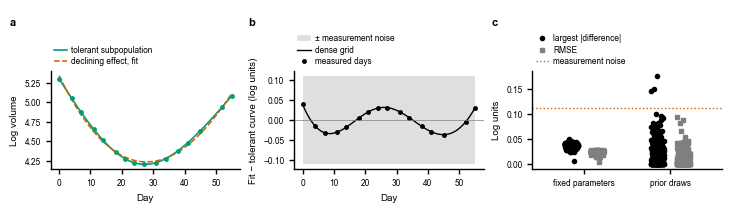

  saved outputs\figures\atlas\05_approximation.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


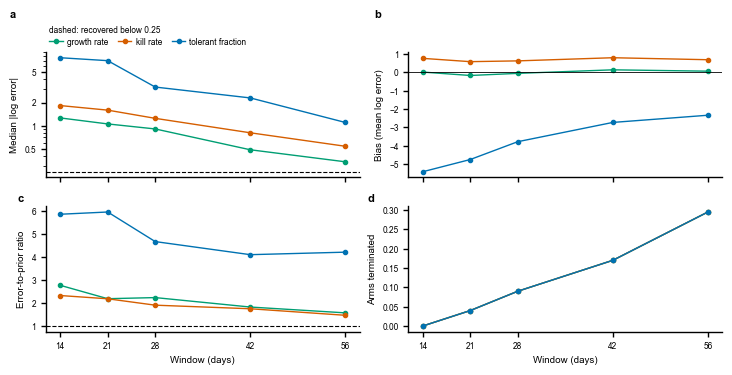

  saved outputs\figures\atlas\05_parameter_recovery.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


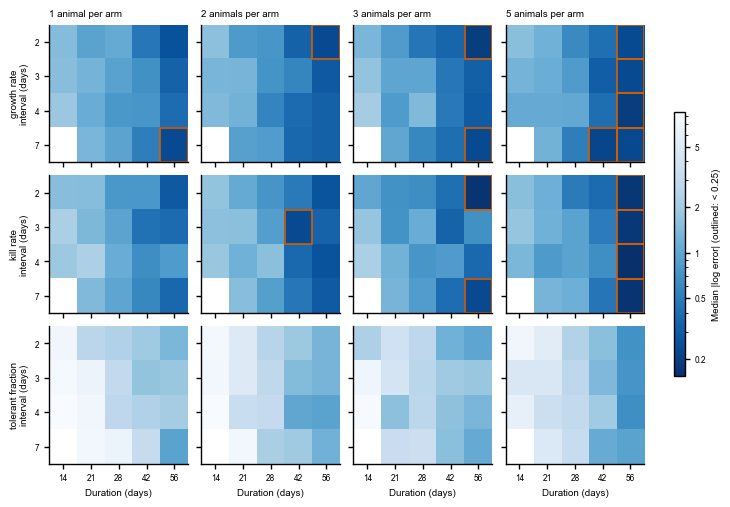

  saved outputs\figures\atlas\05_design_map_heatmaps.{pdf,png}  (180 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


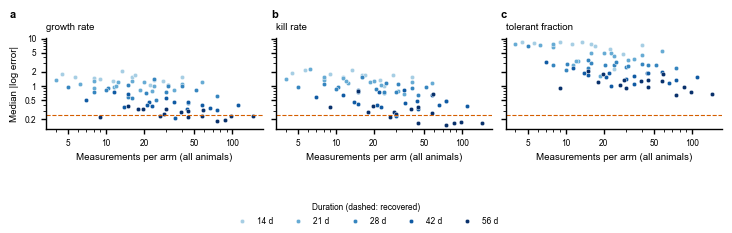

  saved outputs\figures\atlas\05_design_map_tradeoffs.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


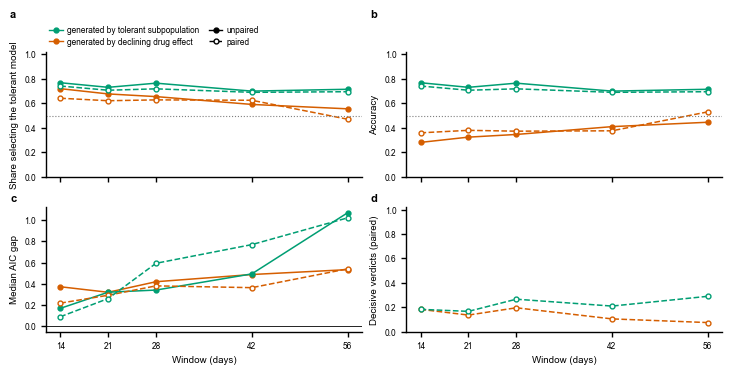

  saved outputs\figures\atlas\05_mechanism_discrimination.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


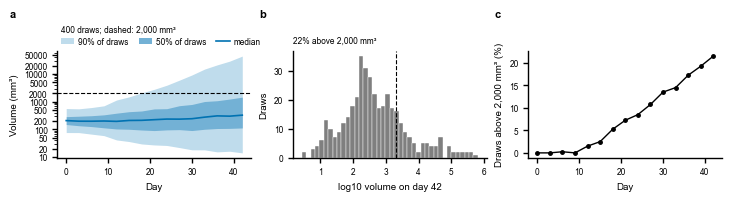

  saved outputs\figures\atlas\05_prior_predictive.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


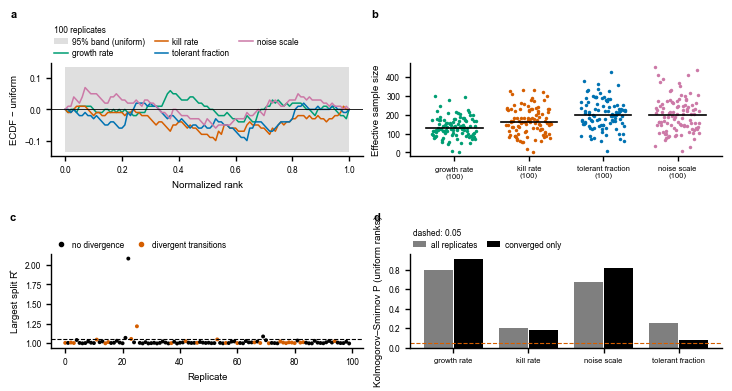

  saved outputs\figures\atlas\05_sbc_diagnostics.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [15]:
# ==========================================================================
# 3.3 Atlas: mechanistic models and identifiability (analysis Section 5)
# ==========================================================================

PARAMETER_COLORS = {"growth_rate": COLORS["third"], "kill_rate": COLORS["fourth"], "tolerant_fraction": COLORS["trajectory"],
                    "noise_scale": COLORS["fifth"]}
TRUTH_COLORS = {"tolerant subpopulation": COLORS["third"], "declining drug effect": COLORS["fourth"]}


def atlas_approximation():
    # a  the tolerant-subpopulation curve (points: the typical 56-day schedule)
    # and its best declining-effect fit (5.1); b  their difference on the
    # dense grid and on the schedule, against ± the measurement noise;
    # c  the largest difference and the RMSE in every approximation setting.
    example = FROZEN["approximation_example"]
    settings = FROZEN["declining_effect_approximation"]
    schedule, dense = example.loc[example.grid == "schedule"], example.loc[example.grid == "dense"]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=55)
    axes[0].plot(dense.day, dense.tolerant, color=COLORS["third"], linewidth=1.2, label="tolerant subpopulation")
    axes[0].plot(dense.day, dense.declining_fit, "--", color=COLORS["fourth"], linewidth=1.1, label="declining effect, fit")
    axes[0].plot(schedule.day, schedule.tolerant, "o", color=COLORS["third"], markersize=2.5)
    axes[0].set_xlabel("Day")
    axes[0].set_ylabel("Log volume")
    legend_above(axes[0])
    axes[1].fill_between(dense.day, -MEASUREMENT_NOISE, MEASUREMENT_NOISE, color=tint(COLORS["light"], 0.5), linewidth=0,
                         label="± measurement noise")
    axes[1].plot(dense.day, dense.declining_fit - dense.tolerant, color=COLORS["ink"], linewidth=1.0, label="dense grid")
    axes[1].plot(schedule.day, schedule.declining_fit - schedule.tolerant, "o", color=COLORS["ink"], markersize=2.5,
                 label="measured days")
    axes[1].axhline(0, color=COLORS["reference"], linewidth=0.5)
    axes[1].set_xlabel("Day")
    axes[1].set_ylabel("Fit − tolerant curve (log units)")
    legend_above(axes[1])
    groups = list(dict.fromkeys(settings.setting))
    for offset, (column, marker, label) in enumerate((("max_abs_residual", "o", "largest |difference|"),
                                                       ("rmse", "s", "RMSE"))):
        for position, group in enumerate(groups):
            values = settings.loc[settings.setting == group, column]
            axes[2].plot(position + (offset - 0.5) * 0.3 + jitter(len(values), 0.15), values, marker,
                         color=COLORS["ink"] if offset == 0 else COLORS["reference"], markersize=3, linestyle="",
                         label=label if position == 0 else None)
    axes[2].axhline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.0, label="measurement noise")
    axes[2].set_xticks(range(len(groups)), groups)
    axes[2].set_xlim(-0.6, len(groups) - 0.4)
    axes[2].set_ylabel("Log units")
    axes[2].set_title(f"largest |difference| / noise = {RESULTS['approximation_to_noise_ratio']:.2f}", loc="left",
                      fontsize=6)
    legend_above(axes[2])
    label_panels(axes)
    save_atlas(figure, "05_approximation")


def atlas_parameter_recovery():
    # Recovery on the study's own schedules (5.3), by window: a  median
    # absolute log error (dashed: the recovery threshold); b  bias (mean log
    # error); c  error-to-prior ratio (1: no better than the prior);
    # d  share of simulated arms ended by the termination rule.
    recovery = FROZEN["parameter_recovery"]
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=48, sharex=True)
    for parameter, rows in recovery.groupby("parameter"):
        rows = rows.sort_values("window_days")
        color = PARAMETER_COLORS.get(parameter, COLORS["reference"])
        for axis, column in zip(axes, ("median_abs_log_error", "bias_log", "error_to_prior_ratio", "terminated_share")):
            axis.plot(rows.window_days, rows[column], "-o", color=color, markersize=3, label=pretty(parameter))
    axes[0].axhline(RECOVERY_THRESHOLD, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_yscale("log")
    plain_log_axis(axes[0])
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[2].axhline(1, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    for axis, label in zip(axes, ("Median |log error|", "Bias (mean log error)", "Error-to-prior ratio",
                                  "Arms terminated")):
        axis.set_ylabel(label)
    for axis in axes[2:]:
        axis.set_xlabel("Window (days)")
    axes[0].set_xticks(sorted(recovery.window_days.unique()))
    legend_above(axes[0], ncols=3, title=f"dashed: recovered below {RECOVERY_THRESHOLD}")
    label_panels(axes)
    save_atlas(figure, "05_parameter_recovery")


def atlas_design_map_heatmaps():
    # The design map of 5.4: median absolute log error of each parameter
    # (rows of panels) for every measurement interval × duration, one column
    # of panels per number of animals per arm; one log color scale for all
    # panels; outlined cells are recovered (error below the threshold).
    design_map = FROZEN["design_map"]
    parameters = [p for p in ("growth_rate", "kill_rate", "tolerant_fraction") if p in set(design_map.parameter)]
    animals = sorted(design_map.animals_per_arm.unique())
    intervals, durations = sorted(design_map.interval_days.unique()), sorted(design_map.duration_days.unique())
    norm = mpl.colors.LogNorm(vmin=max(design_map.median_abs_log_error.min(), 1e-3),
                              vmax=design_map.median_abs_log_error.max())
    figure, axes = plt.subplots(len(parameters), len(animals), figsize=(FIGURE_WIDTH["double"], 42 * len(parameters) * MM),
                                layout="constrained", squeeze=False, sharex=True, sharey=True)
    for i, parameter in enumerate(parameters):
        for j, count in enumerate(animals):
            axis = axes[i, j]
            cells = design_map.loc[(design_map.parameter == parameter) & (design_map.animals_per_arm == count)]
            grid = cells.pivot(index="interval_days", columns="duration_days", values="median_abs_log_error") \
                .reindex(index=intervals, columns=durations)
            image = axis.imshow(grid.to_numpy(float), cmap="Blues_r", norm=norm, aspect="auto")
            for row in cells.loc[cells.recovered.astype(bool)].itertuples():
                axis.add_patch(Rectangle((durations.index(row.duration_days) - 0.5, intervals.index(row.interval_days) - 0.5),
                                         1, 1, fill=False, edgecolor=COLORS["fourth"], linewidth=1.2))
            axis.set_xticks(range(len(durations)), [f"{d:g}" for d in durations])
            axis.set_yticks(range(len(intervals)), [f"{d:g}" for d in intervals])
            if i == 0:
                axis.set_title(f"{count:g} animal{'s' if count > 1 else ''} per arm", loc="left")
            if j == 0:
                axis.set_ylabel(f"{pretty(parameter)}\ninterval (days)")
            if i == len(parameters) - 1:
                axis.set_xlabel("Duration (days)")
    colorbar = plain_log_colorbar(figure.colorbar(image, ax=axes, shrink=0.6, aspect=25))
    colorbar.set_label(f"Median |log error| (outlined: < {RECOVERY_THRESHOLD})")
    save_atlas(figure, "05_design_map_heatmaps")


def atlas_design_map_tradeoffs():
    # Recovery error against the number of measurements a design takes per arm
    # (duration / interval + 1, times the animals per arm), one panel per
    # parameter, color by duration (light to dark: short to long).
    design_map = FROZEN["design_map"].copy()
    design_map["measurements"] = (design_map.duration_days / design_map.interval_days + 1) * design_map.animals_per_arm
    durations = sorted(design_map.duration_days.unique())
    duration_colors = dict(zip(durations, mpl.colormaps["Blues"](np.linspace(0.35, 1.0, len(durations)))))
    parameters = [p for p in ("growth_rate", "kill_rate", "tolerant_fraction") if p in set(design_map.parameter)]
    figure, axes = atlas_figure(len(parameters), ncols=3, panel_height_mm=55, sharey=True)
    for axis, parameter in zip(axes, parameters):
        rows = design_map.loc[design_map.parameter == parameter]
        for duration in durations:
            part = rows.loc[rows.duration_days == duration]
            axis.scatter(part.measurements, part.median_abs_log_error, s=10, color=duration_colors[duration],
                         edgecolor="white", linewidth=0.3, label=f"{duration:g} d")
        axis.axhline(RECOVERY_THRESHOLD, color=COLORS["fourth"], linestyle="--", linewidth=0.8)
        axis.set_xscale("log")
        axis.set_yscale("log")
        plain_log_axis(axis, "x")
        plain_log_axis(axis)
        axis.set_xlabel("Measurements per arm (all animals)")
        axis.set_title(pretty(parameter), loc="left")
    axes[0].set_ylabel("Median |log error|")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside lower center", ncols=len(durations), title="Duration (dashed: recovered)",
                  frameon=False)
    label_panels(axes)
    save_atlas(figure, "05_design_map_tradeoffs")


def atlas_mechanism_discrimination():
    # Simulated arms from each model fitted with both (5.5): a  share selecting
    # the tolerant model; b  accuracy; c  median AIC gap; d  share of paired
    # arms with a decisive verdict. Solid: unpaired simulation; dashed, open:
    # paired (both models on the same schedule and noise).
    unpaired, paired = FROZEN["mechanism_discrimination"], FROZEN.get("mechanism_discrimination_paired")
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=48, sharex=True)
    for frame, style, face in ((unpaired, "-o", None), (paired, "--o", "white")):
        if frame is None:
            continue
        for truth, rows in frame.groupby("true_mechanism"):
            rows = rows.sort_values("window_days")
            color = TRUTH_COLORS.get(truth, COLORS["reference"])
            options = {"color": color, "markersize": 3.5, "markerfacecolor": face or color, "linewidth": 1.1}
            axes[0].plot(rows.window_days, rows.chose_tolerant, style, **options)
            axes[1].plot(rows.window_days, rows.accuracy, style, **options)
            axes[2].plot(rows.window_days, rows.median_criterion_gap, style, **options)
            if "decisive_rate" in rows:
                axes[3].plot(rows.window_days, rows.decisive_rate, style, **options)
    for axis in (axes[0], axes[1]):
        axis.axhline(0.5, color=COLORS["reference"], linestyle=":", linewidth=0.8)
        axis.set_ylim(0, 1.02)
    axes[2].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[3].set_ylim(0, 1.02)
    for axis, label in zip(axes, ("Share selecting the tolerant model", "Accuracy", "Median AIC gap",
                                  "Decisive verdicts (paired)")):
        axis.set_ylabel(label)
    for axis in axes[2:]:
        axis.set_xlabel("Window (days)")
    axes[0].set_xticks(sorted(unpaired.window_days.unique()))
    legend_above(axes[0], ncols=2, handles=[
        Line2D([], [], color=color, marker="o", markersize=3.5, label=f"generated by {truth}")
        for truth, color in TRUTH_COLORS.items()] + [
        Line2D([], [], color=COLORS["ink"], marker="o", markersize=3.5, label="unpaired"),
        Line2D([], [], color=COLORS["ink"], marker="o", markerfacecolor="white", linestyle="--", markersize=3.5,
               label="paired")])
    label_panels(axes)
    save_atlas(figure, "05_mechanism_discrimination")


def atlas_prior_predictive():
    # Prior predictive trajectories of the Bayesian model (5.6): a  median,
    # 50% and 90% bands of volume by day; b  volume on the last simulated day;
    # c  share of draws above the termination volume by day.
    prior = FROZEN["prior_predictive"]
    by_day = prior.groupby("day").volume
    quantiles = by_day.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).unstack()
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=52)
    axes[0].fill_between(quantiles.index, quantiles[0.05], quantiles[0.95], color=tint(COLORS["trajectory"], 0.25),
                         linewidth=0, label="90% of draws")
    axes[0].fill_between(quantiles.index, quantiles[0.25], quantiles[0.75], color=tint(COLORS["trajectory"], 0.55),
                         linewidth=0, label="50% of draws")
    axes[0].plot(quantiles.index, quantiles[0.5], color=COLORS["trajectory"], linewidth=1.2, label="median")
    axes[0].axhline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_yscale("log")
    plain_log_axis(axes[0])
    axes[0].set_xlabel("Day")
    axes[0].set_ylabel("Volume (mm³)")
    legend_above(axes[0], ncols=3, title=f"{prior.draw.nunique():,} draws; dashed: {TERMINATION_VOLUME:,.0f} mm³")
    last = prior.loc[prior.day == prior.day.max(), "volume"]
    axes[1].hist(np.log10(last), bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[1].axvline(np.log10(TERMINATION_VOLUME), color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].set_xlabel(f"log10 volume on day {prior.day.max():g}")
    axes[1].set_ylabel("Draws")
    axes[1].set_title(f"{100 * (last > TERMINATION_VOLUME).mean():.0f}% above {TERMINATION_VOLUME:,.0f} mm³", loc="left",
                      fontsize=6)
    above = prior.assign(above=prior.volume > TERMINATION_VOLUME).groupby("day").above.mean()
    axes[2].plot(above.index, 100 * above, "-o", color=COLORS["ink"], markersize=2.5)
    axes[2].set_xlabel("Day")
    axes[2].set_ylabel(f"Draws above {TERMINATION_VOLUME:,.0f} mm³ (%)")
    label_panels(axes)
    save_atlas(figure, "05_prior_predictive")


def atlas_sbc_diagnostics():
    # Simulation-based calibration (5.6): a  empirical distribution of the
    # normalized ranks minus the uniform, with the 95% Kolmogorov–Smirnov band;
    # b  effective sample size; c  largest split R̂ of each replicate (dashed:
    # 1.05); d  uniformity P value of each parameter, all and converged replicates.
    ranks = FROZEN["calibration_ranks"]
    parameters = list(dict.fromkeys(ranks.parameter))
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=50)
    grid = np.linspace(0, 1, 101)
    n = ranks.replicate.nunique()
    band = 1.36 / np.sqrt(n)
    axes[0].fill_between(grid, -band, band, color=tint(COLORS["light"], 0.5), linewidth=0, label="95% band (uniform)")
    for parameter in parameters:
        values = np.sort(ranks.loc[ranks.parameter == parameter, "normalized_rank"].to_numpy(float))
        ecdf = np.searchsorted(values, grid, side="right") / max(len(values), 1)
        axes[0].plot(grid, ecdf - grid, color=PARAMETER_COLORS.get(parameter, COLORS["reference"]), linewidth=1.1,
                     label=pretty(parameter))
    axes[0].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[0].set_xlabel("Normalized rank")
    axes[0].set_ylabel("ECDF − uniform")
    legend_above(axes[0], ncols=3, title=f"{n} replicates")
    strip_plot(axes[1], {pretty(p): ranks.loc[ranks.parameter == p, "ess"] for p in parameters},
               colors={pretty(p): PARAMETER_COLORS.get(p, COLORS["reference"]) for p in parameters})
    axes[1].set_ylabel("Effective sample size")
    axes[1].tick_params(axis="x", labelsize=5.5)
    worst = ranks.groupby("replicate").agg(max_rhat=("split_rhat", "max"), divergences=("divergences", "first"))
    colors = np.where(worst.divergences > 0, COLORS["fourth"], COLORS["ink"])
    axes[2].scatter(worst.index, worst.max_rhat, s=8, color=colors, edgecolor="none")
    axes[2].axhline(1.05, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[2].set_xlabel("Replicate")
    axes[2].set_ylabel("Largest split R̂")
    legend_above(axes[2], ncols=2, handles=[
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=3, label="no divergence"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["fourth"], markersize=3, label="divergent transitions")])
    summary = TABLES.get("simulation_based_calibration")
    converged = TABLES.get("simulation_based_calibration_converged")
    if summary is not None:
        positions = np.arange(len(summary))
        axes[3].bar(positions - 0.2, summary.ks_p_value, 0.38, color=COLORS["reference"], label="all replicates")
        if converged is not None and len(converged):
            values = converged.set_index("parameter").reindex(summary.parameter).ks_p_value
            axes[3].bar(positions + 0.2, values, 0.38, color=COLORS["ink"], label="converged only")
        axes[3].axhline(0.05, color=COLORS["fourth"], linestyle="--", linewidth=0.8)
        axes[3].set_xticks(positions, [pretty(p) for p in summary.parameter], fontsize=5.5)
        axes[3].set_ylabel("Kolmogorov–Smirnov P (uniform ranks)")
        legend_above(axes[3], ncols=2, title="dashed: 0.05")
    label_panels(axes)
    save_atlas(figure, "05_sbc_diagnostics")


if DRAW_ATLAS:
    draw("05_approximation", atlas_approximation, requires=("approximation_example", "declining_effect_approximation"))
    draw("05_parameter_recovery", atlas_parameter_recovery, requires=("parameter_recovery",))
    draw("05_design_map_heatmaps", atlas_design_map_heatmaps, requires=("design_map",))
    draw("05_design_map_tradeoffs", atlas_design_map_tradeoffs, requires=("design_map",))
    draw("05_mechanism_discrimination", atlas_mechanism_discrimination, requires=("mechanism_discrimination",))
    draw("05_prior_predictive", atlas_prior_predictive, requires=("prior_predictive",))
    draw("05_sbc_diagnostics", atlas_sbc_diagnostics, requires=("calibration_ranks",))

### 3.4 Measurement noise, kinetic estimates and termination (analysis Section 6)

| File | Content |
|---|---|
| `06_kill_rates_by_stratum` | Log kill rate and tolerant fraction by tumor type, and log kill rate by treatment |
| `06_kill_rate_matrix` | Log kill rate of every PDX model × treatment |
| `06_kill_rate_spread` | Mean log kill rate of each treatment, and the spread across models against the spread across treatments |
| `06_kill_rate_vs_endpoints` | Kill rate and tolerant fraction against depth, durability and untreated growth |
| `06_kinetic_fit_quality` | Residual SD of the kinetic fits, failed fits by tumor type, tolerant fractions |
| `06_termination_detail` | Probability of a last visit by volume, the day and volume at which arms ended |
| `06_censoring_weights` | Inverse-probability-of-censoring weights and their effect on the durability distribution |

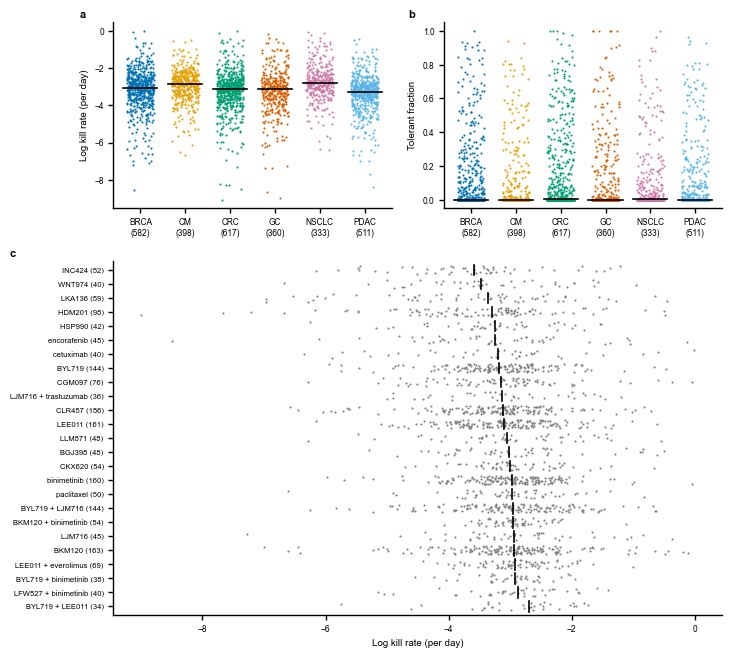

  saved outputs\figures\atlas\06_kill_rates_by_stratum.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


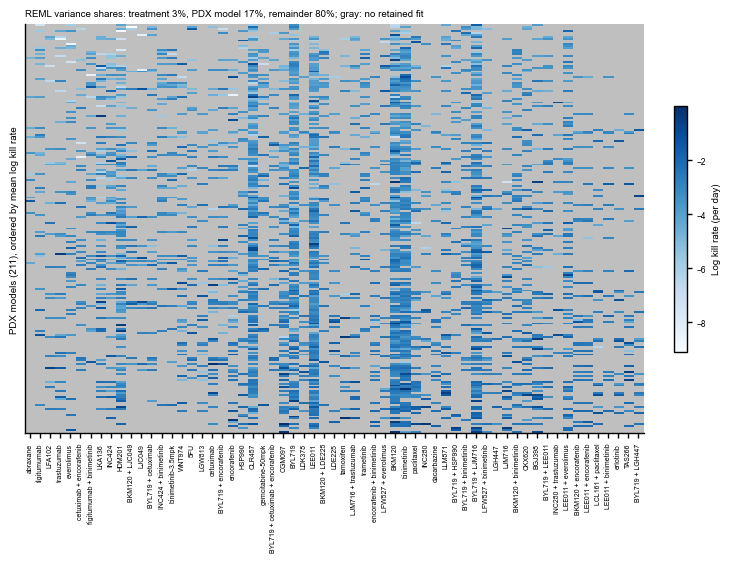

  saved outputs\figures\atlas\06_kill_rate_matrix.{pdf,png}  (180 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


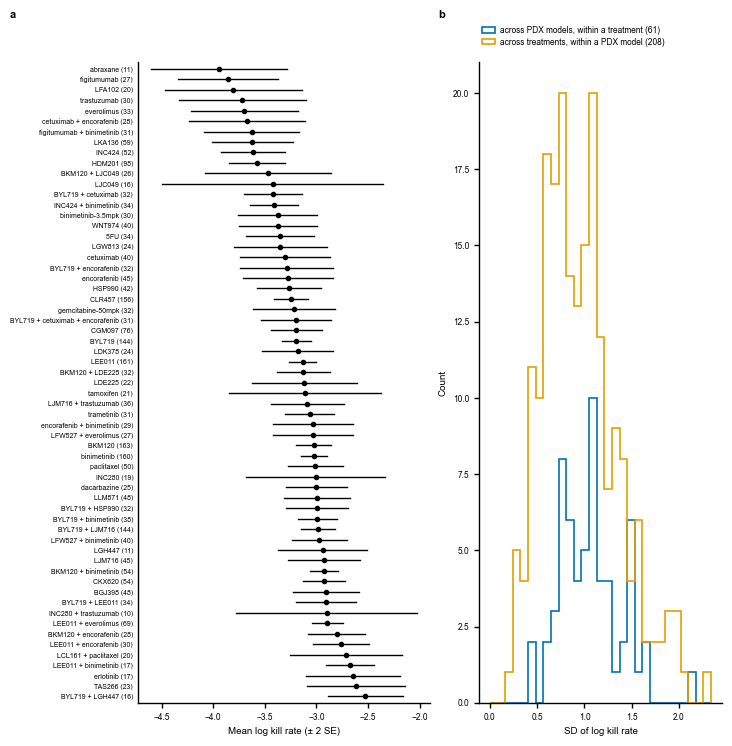

  saved outputs\figures\atlas\06_kill_rate_spread.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


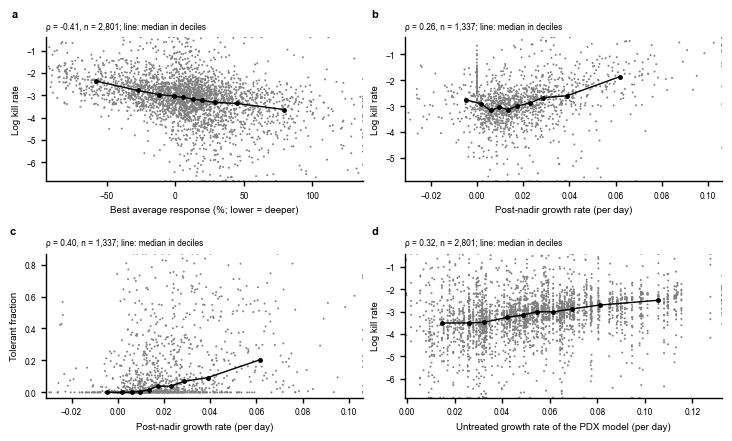

  saved outputs\figures\atlas\06_kill_rate_vs_endpoints.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


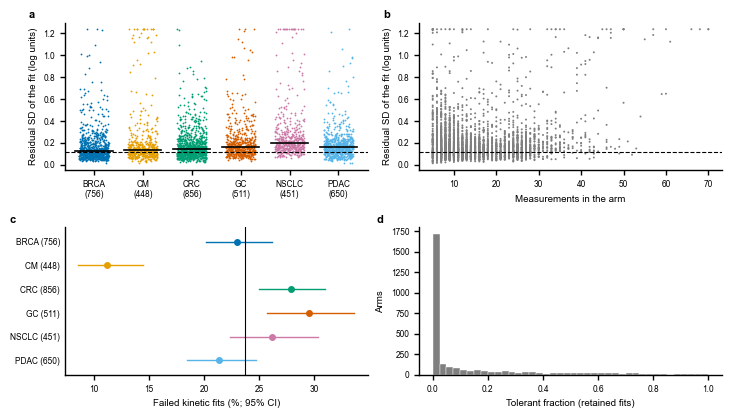

  saved outputs\figures\atlas\06_kinetic_fit_quality.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


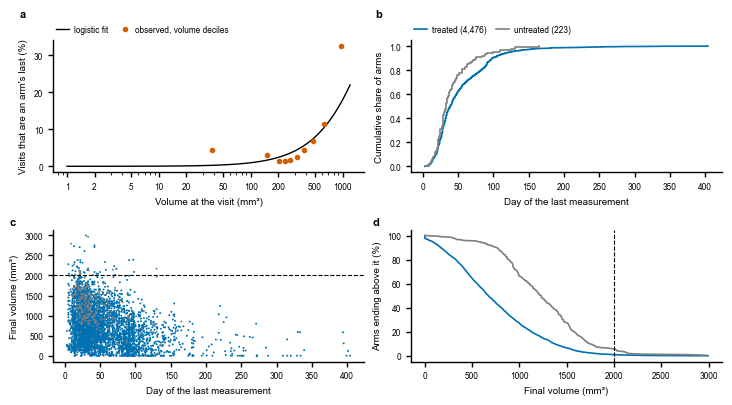

  saved outputs\figures\atlas\06_termination_detail.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


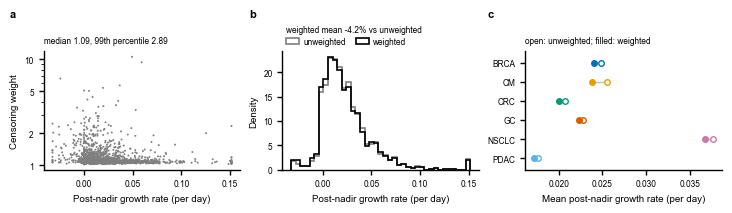

  saved outputs\figures\atlas\06_censoring_weights.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [16]:
# ==========================================================================
# 3.4 Atlas: noise, kinetic estimates and termination (analysis Section 6)
# ==========================================================================

def retained_kinetics():
    """Kinetic fits inside KILL_RATE_RANGE (6.2), with the arm's endpoints."""
    kinetic = FROZEN["kinetic_estimates"]
    retained = kinetic.loc[~kinetic.failed_fit.astype(bool)]
    return retained.merge(arms[["arm_id", DEPTH, DURABILITY, "post_nadir", "n_measurements"]], on="arm_id", how="left")


def atlas_kill_rates_by_stratum():
    # a  log kill rate of the retained fits by tumor type; b  tolerant
    # fraction by tumor type; c  log kill rate by treatment (the 25 treatments
    # with most fits, ordered by median).
    kinetics = retained_kinetics()
    figure, axes = plt.subplot_mosaic([["a", "b"], ["c", "c"]], figsize=(FIGURE_WIDTH["double"], 165 * MM),
                                      layout="constrained", height_ratios=[1.0, 1.9])
    figure.get_layout_engine().set(h_pad=0.12)
    strip_plot(axes["a"], {t: kinetics.loc[kinetics.tumor_type == t, "log_kill_rate"] for t in TUMOR_TYPES},
               colors=TUMOR_TYPE_COLORS, size=1.5, rasterized=True)
    axes["a"].set_ylabel("Log kill rate (per day)")
    strip_plot(axes["b"], {t: kinetics.loc[kinetics.tumor_type == t, "tolerant_fraction"] for t in TUMOR_TYPES},
               colors=TUMOR_TYPE_COLORS, size=1.5, rasterized=True)
    axes["b"].set_ylabel("Tolerant fraction")
    common = kinetics.treatment.value_counts().head(25).index
    order = kinetics.loc[kinetics.treatment.isin(common)].groupby("treatment").log_kill_rate.median().sort_values().index
    strip_plot(axes["c"], {t: kinetics.loc[kinetics.treatment == t, "log_kill_rate"] for t in order}, size=1.5,
               vertical=False, rasterized=True)
    axes["c"].tick_params(axis="y", labelsize=5.5)
    axes["c"].set_xlabel("Log kill rate (per day)")
    label_panels([axes[key] for key in "abc"])
    save_atlas(figure, "06_kill_rates_by_stratum")


def atlas_kill_rate_matrix():
    # Log kill rate of every PDX model (rows, ordered by their mean) and
    # treatment (columns, ordered by their mean); gray: no retained fit.
    kinetics = retained_kinetics()
    # One value per PDX model × treatment (replicate arms averaged).
    matrix = kinetics.pivot_table(index="model_id", columns="treatment", values="log_kill_rate", aggfunc="mean")
    matrix = matrix.loc[matrix.mean(axis=1).sort_values().index, matrix.mean(axis=0).sort_values().index]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"], 140 * MM), layout="constrained")
    cmap = mpl.colormaps["Blues"].copy()
    cmap.set_bad(COLORS["light"])
    image = axis.imshow(np.ma.masked_invalid(matrix.to_numpy(float)), aspect="auto", cmap=cmap, interpolation="nearest")
    axis.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=90, fontsize=5)
    axis.set_yticks([])
    axis.set_ylabel(f"PDX models ({matrix.shape[0]}), ordered by mean log kill rate")
    partition = FROZEN["kill_rate_partition"].set_index("component")
    shares = ", ".join(f"{str(name).split(' (')[0]} {100 * row.reml_share:.0f}%" for name, row in partition.iterrows())
    axis.set_title(f"REML variance shares: {shares}; gray: no retained fit", loc="left")
    figure.colorbar(image, ax=axis, shrink=0.6).set_label("Log kill rate (per day)")
    save_atlas(figure, "06_kill_rate_matrix")


def atlas_kill_rate_spread():
    # a  mean log kill rate of each treatment with ± 2 standard errors across
    # its PDX models (treatments with at least five fits); b  SD of log kill
    # rate across PDX models within each treatment, and across treatments
    # within each PDX model (at least five fits each).
    kinetics = retained_kinetics()
    # Spread across PDX models within a treatment, and across treatments
    # within a PDX model: the two sources the variance partition separates.
    by_treatment = kinetics.groupby("treatment").log_kill_rate.agg(["mean", "std", "size"])
    by_treatment = by_treatment.loc[by_treatment["size"] >= 5].sort_values("mean")
    by_model = kinetics.groupby("model_id").log_kill_rate.agg(["std", "size"])
    by_model = by_model.loc[by_model["size"] >= 5]
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(70, 2.6 * len(by_treatment) + 25) * MM),
                                      layout="constrained", width_ratios=[1.2, 1.0])
    se = by_treatment["std"] / np.sqrt(by_treatment["size"])
    forest_rows(axes["a"], [f"{t} ({int(n)})" for t, n in zip(by_treatment.index, by_treatment["size"])],
                by_treatment["mean"], by_treatment["mean"] - 2 * se, by_treatment["mean"] + 2 * se, size=3)
    axes["a"].tick_params(axis="y", labelsize=5)
    axes["a"].set_xlabel("Mean log kill rate (± 2 SE)")
    bins = np.linspace(0, max(by_treatment["std"].max(), by_model["std"].max()), 30)
    axes["b"].hist(by_treatment["std"], bins=bins, histtype="step", color=COLORS["trajectory"], linewidth=1.2,
                   label=f"across PDX models, within a treatment ({len(by_treatment)})")
    axes["b"].hist(by_model["std"], bins=bins, histtype="step", color=COLORS["depth"], linewidth=1.2,
                   label=f"across treatments, within a PDX model ({len(by_model)})")
    axes["b"].set_xlabel("SD of log kill rate")
    axes["b"].set_ylabel("Count")
    legend_above(axes["b"])
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "06_kill_rate_spread")


def atlas_kill_rate_vs_endpoints():
    # a  log kill rate against best average response; b  against the
    # post-nadir growth rate (post-nadir arms); c  tolerant fraction against
    # the post-nadir growth rate; d  log kill rate against the PDX model's
    # untreated growth rate.
    kinetics = retained_kinetics()
    with_durability = kinetics.loc[kinetics.post_nadir.astype(bool)]
    kinetics = kinetics.assign(untreated_growth=kinetics.model_id.map(untreated_growth))
    panels = [(kinetics, DEPTH, "log_kill_rate", DEPTH_LABEL, "Log kill rate"),
              (with_durability, DURABILITY, "log_kill_rate", DURABILITY_LABEL, "Log kill rate"),
              (with_durability, DURABILITY, "tolerant_fraction", DURABILITY_LABEL, "Tolerant fraction"),
              (kinetics.dropna(subset=["untreated_growth"]), "untreated_growth", "log_kill_rate",
               "Untreated growth rate of the PDX model (per day)", "Log kill rate")]
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=55)
    for axis, (frame, x_column, y_column, x_label, y_label) in zip(axes, panels):
        frame = frame.dropna(subset=[x_column, y_column])
        xlim, ylim = percentile_limits(frame[x_column]), percentile_limits(frame[y_column])
        axis.scatter(frame[x_column].clip(*xlim), frame[y_column].clip(*ylim), s=2, color=COLORS["reference"],
                     edgecolor="none", rasterized=True)
        if len(frame) >= 20:
            summary = binned_summary(frame[x_column], frame[y_column], n_bins=10)
            axis.plot(summary.x, summary["median"], "-o", color=COLORS["ink"], markersize=2.5, linewidth=1.0)
        axis.set_xlim(xlim)
        axis.set_ylim(ylim)
        axis.set_xlabel(x_label)
        axis.set_ylabel(y_label)
        axis.set_title(f"ρ = {spearman(frame[x_column], frame[y_column])[0]:.2f}, n = {len(frame):,}; "
                       f"line: median in deciles", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "06_kill_rate_vs_endpoints")


def atlas_kinetic_fit_quality():
    # a  residual SD of each kinetic fit by tumor type (dashed: measurement
    # noise); b  residual SD against the number of measurements; c  failed fits
    # (kill rate outside KILL_RATE_RANGE) by tumor type, Wilson 95% intervals;
    # d  tolerant fraction of the retained fits.
    kinetic = FROZEN["kinetic_estimates"].merge(arms[["arm_id", "n_measurements"]], on="arm_id", how="left")
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    clipped = kinetic.residual_sd.clip(upper=kinetic.residual_sd.quantile(0.99))
    strip_plot(axes[0], {t: clipped[kinetic.tumor_type == t] for t in TUMOR_TYPES}, colors=TUMOR_TYPE_COLORS, size=1.3,
               rasterized=True)
    axes[0].axhline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_ylabel("Residual SD of the fit (log units)")
    axes[1].scatter(kinetic.n_measurements, clipped, s=2, color=COLORS["reference"], edgecolor="none", rasterized=True)
    axes[1].axhline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].set_xlabel("Measurements in the arm")
    axes[1].set_ylabel("Residual SD of the fit (log units)")
    shares = [share_with_interval(kinetic.loc[kinetic.tumor_type == t, "failed_fit"].astype(bool).sum(),
                                  (kinetic.tumor_type == t).sum()) for t in TUMOR_TYPES]
    forest_rows(axes[2], [f"{t} ({int((kinetic.tumor_type == t).sum())})" for t in TUMOR_TYPES],
                [100 * s[0] for s in shares], [100 * s[1] for s in shares], [100 * s[2] for s in shares],
                colors=[TUMOR_TYPE_COLORS[t] for t in TUMOR_TYPES])
    axes[2].axvline(100 * RESULTS["failed_kill_fit_share"], color=COLORS["ink"], linewidth=0.8)
    axes[2].set_xlabel("Failed kinetic fits (%; 95% CI)")
    retained = kinetic.loc[~kinetic.failed_fit.astype(bool)]
    axes[3].hist(retained.tolerant_fraction, bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[3].set_xlabel("Tolerant fraction (retained fits)")
    axes[3].set_ylabel("Arms")
    label_panels(axes)
    save_atlas(figure, "06_kinetic_fit_quality")


def atlas_termination_detail():
    # a  fitted probability of a last visit (line, at the median elapsed day)
    # and the observed share by volume decile (points); b  day of the last
    # measurement, treated and untreated; c  final volume against the day of
    # the last measurement; d  share of arms ending above each volume.
    curve, deciles = FROZEN["termination_hazard_curve"], FROZEN["termination_by_volume_decile"]
    last_visits = FROZEN["last_visits"].assign(is_control=lambda f: f.is_control.astype(bool))
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    axes[0].plot(curve.volume, 100 * curve.probability_last_visit, color=COLORS["ink"], label="logistic fit")
    axes[0].plot(deciles.volume, 100 * deciles.end_rate, "o", color=COLORS["fourth"], markersize=3,
                 label="observed, volume deciles")
    axes[0].set_xscale("log")
    plain_log_axis(axes[0], "x")
    axes[0].set_xlabel("Volume at the visit (mm³)")
    axes[0].set_ylabel("Visits that are an arm's last (%)")
    legend_above(axes[0], ncols=2)
    for population, is_control in (("treated", False), ("untreated", True)):
        part = last_visits.loc[last_visits.is_control == is_control]
        ecdf_step(axes[1], part.day, color=POPULATION_COLORS[population], linewidth=1.2,
                  label=f"{population} ({len(part):,})")
        frame = design.loc[design.is_control == is_control]
        axes[2].scatter(frame.last_day, frame.last_volume, s=2, color=POPULATION_COLORS[population], edgecolor="none",
                        rasterized=True)
        volumes = np.sort(frame.last_volume.to_numpy(float))
        axes[3].plot(volumes, 100 * (1 - np.arange(len(volumes)) / len(volumes)), color=POPULATION_COLORS[population],
                     linewidth=1.2)
    axes[1].set_xlabel("Day of the last measurement")
    axes[1].set_ylabel("Cumulative share of arms")
    legend_above(axes[1], ncols=2)
    axes[2].axhline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[2].set_xlabel("Day of the last measurement")
    axes[2].set_ylabel("Final volume (mm³)")
    axes[3].axvline(TERMINATION_VOLUME, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[3].set_xlabel("Final volume (mm³)")
    axes[3].set_ylabel("Arms ending above it (%)")
    label_panels(axes)
    save_atlas(figure, "06_termination_detail")


def atlas_censoring_weights():
    # a  inverse-probability-of-censoring weight of each post-nadir arm against
    # its post-nadir growth rate (log scale; weights are capped at 20); b  the
    # rate distribution unweighted and weighted; c  mean rate by tumor type,
    # unweighted (open) and weighted (filled).
    # Weights of 6.3: one over the probability of remaining under observation
    # until the arm entered the analysis set.
    weights = FROZEN["censoring_weights"].merge(arms[["arm_id", "tumor_type"]], on="arm_id", how="left")
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=55)
    axes[0].scatter(weights.post_nadir_growth_rate.clip(*DURABILITY_LIMITS), weights.ipc_weight, s=2,
                    color=COLORS["reference"], edgecolor="none", rasterized=True)
    axes[0].set_yscale("log")
    plain_log_axis(axes[0])
    axes[0].set_xlabel(DURABILITY_LABEL)
    axes[0].set_ylabel("Censoring weight")
    axes[0].set_title(f"median {weights.ipc_weight.median():.2f}, 99th percentile {weights.ipc_weight.quantile(.99):.2f}",
                      loc="left", fontsize=6)
    bins = np.linspace(*DURABILITY_LIMITS, 40)
    clipped = weights.post_nadir_growth_rate.clip(*DURABILITY_LIMITS)
    axes[1].hist(clipped, bins=bins, density=True, histtype="step", color=COLORS["reference"], linewidth=1.2,
                 label="unweighted")
    axes[1].hist(clipped, bins=bins, weights=weights.ipc_weight, density=True, histtype="step", color=COLORS["ink"],
                 linewidth=1.2, label="weighted")
    axes[1].set_xlabel(DURABILITY_LABEL)
    axes[1].set_ylabel("Density")
    legend_above(axes[1], ncols=2, title=f"weighted mean {100 * RESULTS['ipcw_relative_change']:+.1f}% vs unweighted")
    rows = []
    for tumor_type in TUMOR_TYPES:
        part = weights.loc[weights.tumor_type == tumor_type]
        rows.append((tumor_type, part.post_nadir_growth_rate.mean(),
                     np.average(part.post_nadir_growth_rate, weights=part.ipc_weight)))
    for y, (tumor_type, plain_mean, weighted_mean) in enumerate(rows):
        axes[2].plot([plain_mean, weighted_mean], [y, y], color=COLORS["light"], linewidth=1.0)
        axes[2].plot(plain_mean, y, "o", markerfacecolor="white", markeredgecolor=TUMOR_TYPE_COLORS[tumor_type], markersize=4)
        axes[2].plot(weighted_mean, y, "o", color=TUMOR_TYPE_COLORS[tumor_type], markersize=4)
    axes[2].set_yticks(range(len(rows)), [r[0] for r in rows])
    axes[2].set_ylim(len(rows) - 0.4, -0.6)
    axes[2].set_xlabel("Mean post-nadir growth rate (per day)")
    axes[2].set_title("open: unweighted; filled: weighted", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "06_censoring_weights")


if DRAW_ATLAS:
    draw("06_kill_rates_by_stratum", atlas_kill_rates_by_stratum, requires=("kinetic_estimates",))
    draw("06_kill_rate_matrix", atlas_kill_rate_matrix, requires=("kinetic_estimates", "kill_rate_partition"))
    draw("06_kill_rate_spread", atlas_kill_rate_spread, requires=("kinetic_estimates",))
    draw("06_kill_rate_vs_endpoints", atlas_kill_rate_vs_endpoints, requires=("kinetic_estimates",))
    draw("06_kinetic_fit_quality", atlas_kinetic_fit_quality, requires=("kinetic_estimates",))
    draw("06_termination_detail", atlas_termination_detail, requires=(
        "termination_hazard_curve", "termination_by_volume_decile", "last_visits"))
    draw("06_censoring_weights", atlas_censoring_weights, requires=("censoring_weights",))

### 3.5 Forecasting and treatment selection (analysis Section 7)

| File | Content |
|---|---|
| `07_forecast_calibration` | Residuals against prediction for each set, calibration by prediction decile, residual distributions |
| `07_forecast_bootstrap` | Bootstrap distribution of the forecasting endpoint, and both endpoints for the two sets |
| `07_forecast_by_tumor_type` | RMSE of each set and the relative reduction within each tumor type (95% intervals resampling PDX models) |
| `07_forecast_by_treatment` | The same within each treatment with at least eight arms |
| `07_forecast_error_difference` | Where the trajectory set gains: per-arm error difference against outcome, depth and durability |
| `07_regret_detail` | Regret of the two sets per PDX model, by the number of eligible arms |
| `07_ranking_detail` | Pairwise ranking accuracy against the observed gap, the gaps, and how often each set ranks a pair correctly |

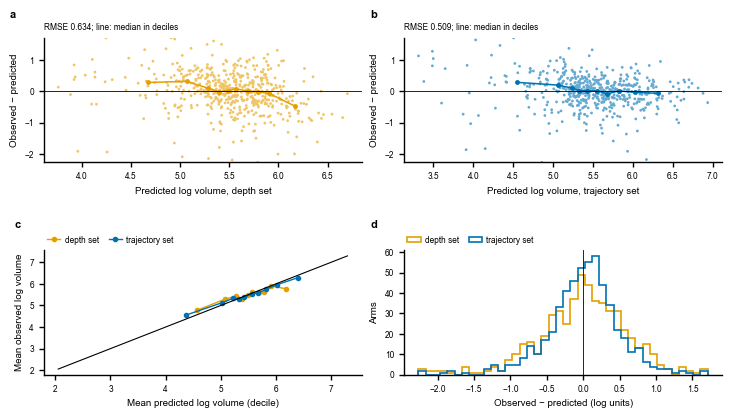

  saved outputs\figures\atlas\07_forecast_calibration.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


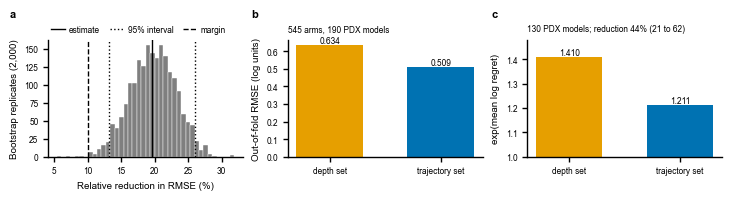

  saved outputs\figures\atlas\07_forecast_bootstrap.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


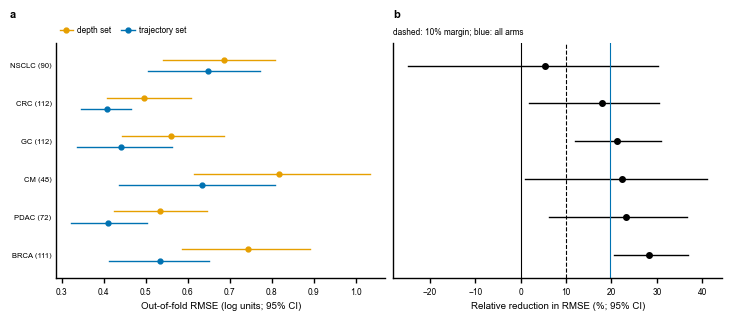

  saved outputs\figures\atlas\07_forecast_by_tumor_type.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


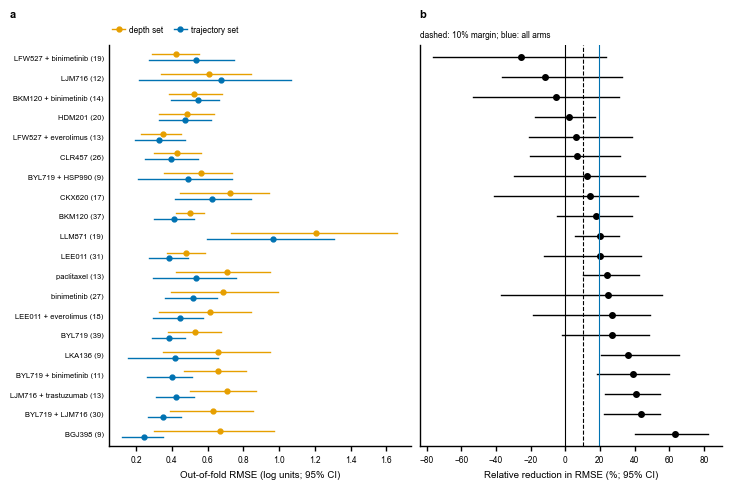

  saved outputs\figures\atlas\07_forecast_by_treatment.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


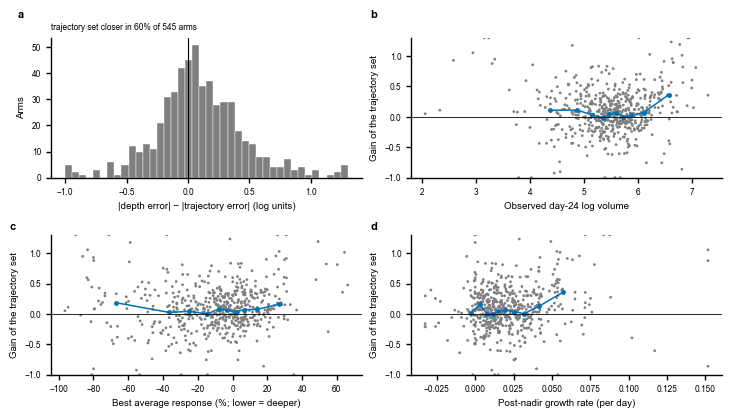

  saved outputs\figures\atlas\07_forecast_error_difference.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


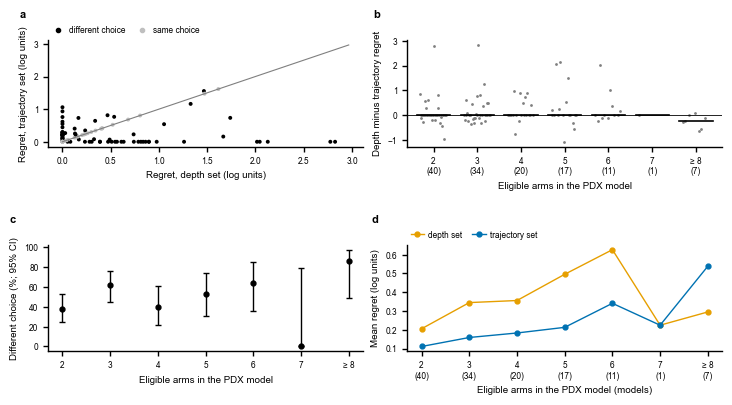

  saved outputs\figures\atlas\07_regret_detail.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


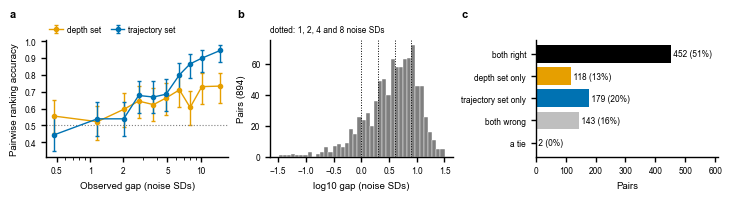

  saved outputs\figures\atlas\07_ranking_detail.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [17]:
# ==========================================================================
# 3.5 Atlas: forecasting and treatment selection (analysis Section 7)
# ==========================================================================

def forecast_frame():
    """The arms of 7.2 with both predictions, their errors and their endpoints."""
    frame = FROZEN["forecast_predictions"].merge(arms[["arm_id", DEPTH, DURABILITY]], on="arm_id", how="left")
    for key in ("depth", "trajectory"):
        frame[f"{key}_error"] = frame.outcome_log_volume - frame[f"{key}_prediction"]
    frame["error_gain"] = frame.depth_error.abs() - frame.trajectory_error.abs()   # > 0: trajectory closer
    return frame


def atlas_forecast_calibration():
    # a, b  residual (observed − predicted day-24 log volume) against the
    # prediction, with the median residual in prediction deciles; c  mean
    # observed against mean predicted in prediction deciles; d  residuals.
    frame = forecast_frame()
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    residual_limits = percentile_limits(np.r_[frame.depth_error, frame.trajectory_error], 0.5, 99.5)
    for axis, key in zip(axes[:2], ("depth", "trajectory")):
        axis.scatter(frame[f"{key}_prediction"], frame[f"{key}_error"].clip(*residual_limits), s=4,
                     color=tint(SET_COLORS[key], 0.6), edgecolor="none", rasterized=True)
        summary = binned_summary(frame[f"{key}_prediction"], frame[f"{key}_error"])
        axis.plot(summary.x, summary["median"], "-o", color=SET_COLORS[key], markersize=2.5, linewidth=1.1)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
        axis.set_ylim(residual_limits)
        axis.set_xlabel(f"Predicted log volume, {SET_NAMES[key]}")
        axis.set_ylabel("Observed − predicted")
        axis.set_title(f"RMSE {rmse(frame.outcome_log_volume, frame[f'{key}_prediction']):.3f}; line: median in deciles",
                       loc="left", fontsize=6)
    for key in ("depth", "trajectory"):
        # Deciles of each set's own prediction; a calibrated set lies on the line.
        bins = pd.qcut(frame[f"{key}_prediction"].rank(method="first"), 10, labels=False)
        calibration = frame.groupby(bins).agg(predicted=(f"{key}_prediction", "mean"), observed=("outcome_log_volume", "mean"))
        axes[2].plot(calibration.predicted, calibration.observed, "-o", color=SET_COLORS[key], markersize=3,
                     label=SET_NAMES[key])
        axes[3].hist(frame[f"{key}_error"].clip(*residual_limits), bins=40, histtype="step", color=SET_COLORS[key],
                     linewidth=1.2, label=SET_NAMES[key])
    limits = [frame.outcome_log_volume.min(), frame.outcome_log_volume.max()]
    axes[2].plot(limits, limits, color=COLORS["ink"], linewidth=0.8)
    axes[2].set_xlabel("Mean predicted log volume (decile)")
    axes[2].set_ylabel("Mean observed log volume")
    legend_above(axes[2], ncols=2)
    axes[3].axvline(0, color=COLORS["ink"], linewidth=0.6)
    axes[3].set_xlabel("Observed − predicted (log units)")
    axes[3].set_ylabel("Arms")
    legend_above(axes[3], ncols=2)
    label_panels(axes)
    save_atlas(figure, "07_forecast_calibration")


def atlas_forecast_bootstrap():
    # a  bootstrap distribution of the relative RMSE reduction (resampling PDX
    # models), with the estimate, its 95% interval and the margin; b  RMSE of
    # the two sets; c  mean regret of the two sets (as fold excess volume).
    draws = FROZEN["forecast_bootstrap_draws"].relative_reduction
    endpoints = FROZEN["forecasting_endpoints"].iloc[0]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=52)
    axes[0].hist(100 * draws, bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    for value, style, label in ((RESULTS["forecast_reduction"], "-", "estimate"),
                                (RESULTS["forecast_reduction_low"], ":", "95% interval"),
                                (RESULTS["forecast_reduction_high"], ":", None),
                                (FORECAST_MARGIN, "--", "margin")):
        axes[0].axvline(100 * value, color=COLORS["ink"], linestyle=style, linewidth=1.0, label=label)
    axes[0].set_xlabel("Relative reduction in RMSE (%)")
    axes[0].set_ylabel(f"Bootstrap replicates ({len(draws):,})")
    legend_above(axes[0], ncols=3)
    for axis, keys, values, label in (
            (axes[1], ("depth", "trajectory"), (endpoints.depth_rmse, endpoints.trajectory_rmse), "Out-of-fold RMSE (log units)"),
            (axes[2], ("depth", "trajectory"), (np.exp(endpoints.depth_regret), np.exp(endpoints.trajectory_regret)),
             "exp(mean log regret)")):
        axis.bar(range(2), values, color=[SET_COLORS[k] for k in keys], width=0.6)
        for x, value in enumerate(values):
            axis.text(x, value, f"{value:.3f}", ha="center", va="bottom", fontsize=6)
        axis.set_xticks(range(2), [SET_NAMES[k] for k in keys])
        axis.set_ylabel(label)
    axes[1].set_title(f"{int(endpoints.n_arms)} arms, {int(endpoints.n_models)} PDX models", loc="left", fontsize=6)
    axes[2].set_ylim(1, None)
    axes[2].set_title(f"{int(endpoints.regret_models)} PDX models; reduction {100 * endpoints.regret_reduction:.0f}% "
                      f"({100 * endpoints.regret_low:.0f} to {100 * endpoints.regret_high:.0f})", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "07_forecast_bootstrap")


def forecast_strata(column, minimum_arms):
    """RMSE of both sets and the relative reduction within each level of
    `column` with at least `minimum_arms` arms, with 95% intervals resampling
    PDX models (predictions held fixed; atlas only)."""
    frame = forecast_frame()
    rng = np.random.default_rng(FIGURE_SEEDS["atlas_forecast_strata"])
    rows = []
    for level, part in frame.groupby(column):
        if len(part) < minimum_arms:
            continue
        observed = part.outcome_log_volume.to_numpy(float)
        depth, trajectory = part.depth_prediction.to_numpy(float), part.trajectory_prediction.to_numpy(float)
        row = {"level": level, "arms": len(part)}
        for key, predicted in (("depth", depth), ("trajectory", trajectory)):
            row[key] = rmse(observed, predicted)
            row[f"{key}_low"], row[f"{key}_high"] = bootstrap_interval(
                part.model_id, lambda r, p=predicted: rmse(observed[r], p[r]), N_FIGURE_BOOTSTRAP, rng)
        row["reduction"] = relative_rmse_reduction(observed, depth, trajectory)
        row["reduction_low"], row["reduction_high"] = bootstrap_interval(
            part.model_id, lambda r: relative_rmse_reduction(observed[r], depth[r], trajectory[r]), N_FIGURE_BOOTSTRAP, rng)
        rows.append(row)
    return pd.DataFrame(rows).sort_values("reduction").reset_index(drop=True)


def draw_forecast_strata(strata, file_name, height_per_row=4.5):
    # a  RMSE of both sets in each stratum (95% CI); b  relative reduction
    # (95% CI), dashed at the margin and solid at the overall estimate.
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(60, height_per_row * len(strata) + 30) * MM),
                                      layout="constrained", sharey=True)
    labels = [f"{row.level} ({row.arms})" for row in strata.itertuples()]
    for offset, key in ((-0.15, "depth"), (0.15, "trajectory")):
        for y, row in enumerate(strata.itertuples()):
            axes["a"].plot([getattr(row, f"{key}_low"), getattr(row, f"{key}_high")], [y + offset] * 2,
                           color=SET_COLORS[key], linewidth=1.0)
            axes["a"].plot(getattr(row, key), y + offset, "o", color=SET_COLORS[key], markersize=3.5)
    axes["a"].set_yticks(range(len(strata)), labels)
    axes["a"].set_ylim(len(strata) - 0.4, -0.6)
    axes["a"].tick_params(axis="y", length=0, labelsize=5.5)
    axes["a"].set_xlabel("Out-of-fold RMSE (log units; 95% CI)")
    legend_above(axes["a"], ncols=2, handles=[Line2D([], [], marker="o", color=SET_COLORS[k], markersize=3.5,
                                                     label=SET_NAMES[k]) for k in ("depth", "trajectory")])
    forest_rows(axes["b"], labels, 100 * strata.reduction, 100 * strata.reduction_low, 100 * strata.reduction_high,
                reference=0)
    axes["b"].axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes["b"].axvline(100 * RESULTS["forecast_reduction"], color=COLORS["trajectory"], linewidth=0.8)
    axes["b"].set_xlabel("Relative reduction in RMSE (%; 95% CI)")
    axes["b"].set_title(f"dashed: {FORECAST_MARGIN:.0%} margin; blue: all arms", loc="left", fontsize=6)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, file_name)


def atlas_forecast_by_tumor_type():
    draw_forecast_strata(forecast_strata("tumor_type", 10), "07_forecast_by_tumor_type", height_per_row=8)


def atlas_forecast_by_treatment():
    draw_forecast_strata(forecast_strata("treatment", 8), "07_forecast_by_treatment")


def atlas_forecast_error_difference():
    # Per-arm gain of the trajectory set: |depth-set error| − |trajectory-set
    # error| (> 0: the trajectory set came closer). a  distribution; b–d  the
    # gain against the observed day-24 log volume, the arm's best average
    # response and its post-nadir growth rate, with the median gain in deciles.
    frame = forecast_frame()
    gain_limits = percentile_limits(frame.error_gain, 1, 99)
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52, sharey=False)
    axes[0].hist(frame.error_gain.clip(*gain_limits), bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    axes[0].axvline(0, color=COLORS["ink"], linewidth=0.8)
    axes[0].set_xlabel("|depth error| − |trajectory error| (log units)")
    axes[0].set_ylabel("Arms")
    axes[0].set_title(f"trajectory set closer in {100 * (frame.error_gain > 0).mean():.0f}% of {len(frame)} arms",
                      loc="left", fontsize=6)
    for axis, column, label, limits in ((axes[1], "outcome_log_volume", "Observed day-24 log volume", None),
                                        (axes[2], DEPTH, DEPTH_LABEL, DEPTH_LIMITS),
                                        (axes[3], DURABILITY, DURABILITY_LABEL, DURABILITY_LIMITS)):
        part = frame.dropna(subset=[column])
        x = part[column] if limits is None else part[column].clip(*limits)
        axis.scatter(x, part.error_gain.clip(*gain_limits), s=4, color=COLORS["reference"], edgecolor="none",
                     rasterized=True)
        summary = binned_summary(part[column], part.error_gain)
        axis.plot(summary.x, summary["median"], "-o", color=COLORS["trajectory"], markersize=2.5, linewidth=1.1)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
        axis.set_ylim(gain_limits)
        axis.set_xlabel(label)
        axis.set_ylabel("Gain of the trajectory set")
    label_panels(axes)
    save_atlas(figure, "07_forecast_error_difference")


def atlas_regret_detail():
    # a  regret of the depth set against regret of the trajectory set in each
    # PDX model (log units; on the diagonal: equal); b  their difference by the
    # number of eligible arms; c  share of PDX models where the two sets chose
    # different arms, by the number of eligible arms (Wilson 95% intervals);
    # d  mean regret of each set by the number of eligible arms.
    regret = FROZEN["treatment_selection_regret"].assign(different_choice=lambda f: f.different_choice.astype(bool))
    # Models with eight or more eligible arms are pooled into one group.
    regret["n_group"] = regret.n_treatments.clip(upper=8)
    groups = sorted(regret.n_group.unique())
    group_label = {g: (f"{g}" if g < 8 else "≥ 8") for g in groups}
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    limit = max(regret.depth_prediction_regret.max(), regret.trajectory_prediction_regret.max()) * 1.05
    colors = np.where(regret.different_choice, COLORS["ink"], COLORS["light"])
    axes[0].scatter(regret.depth_prediction_regret, regret.trajectory_prediction_regret, s=8, color=colors, edgecolor="none")
    axes[0].plot([0, limit], [0, limit], color=COLORS["reference"], linewidth=0.8)
    axes[0].set_xlabel("Regret, depth set (log units)")
    axes[0].set_ylabel("Regret, trajectory set (log units)")
    legend_above(axes[0], ncols=2, handles=[
        Line2D([], [], marker="o", linestyle="", color=COLORS["ink"], markersize=3, label="different choice"),
        Line2D([], [], marker="o", linestyle="", color=COLORS["light"], markersize=3, label="same choice")])
    strip_plot(axes[1], {group_label[g]: (regret.depth_prediction_regret - regret.trajectory_prediction_regret)[regret.n_group == g]
                         for g in groups}, size=2)
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[1].set_xlabel("Eligible arms in the PDX model")
    axes[1].set_ylabel("Depth minus trajectory regret")
    shares = [share_with_interval(regret.loc[regret.n_group == g, "different_choice"].sum(), (regret.n_group == g).sum())
              for g in groups]
    axes[2].errorbar(range(len(groups)), [100 * s[0] for s in shares],
                     yerr=100 * interval_errors([s[0] for s in shares], [s[1] for s in shares], [s[2] for s in shares]),
                     fmt="o", color=COLORS["ink"], capsize=2, markersize=3.5)
    axes[2].set_xticks(range(len(groups)), [group_label[g] for g in groups])
    axes[2].set_xlabel("Eligible arms in the PDX model")
    axes[2].set_ylabel("Different choice (%; 95% CI)")
    for key in ("depth", "trajectory"):
        means = regret.groupby("n_group")[f"{key}_prediction_regret"].mean().reindex(groups)
        axes[3].plot(range(len(groups)), means, "-o", color=SET_COLORS[key], markersize=3.5, label=SET_NAMES[key])
    axes[3].set_xticks(range(len(groups)), [f"{group_label[g]}\n({int((regret.n_group == g).sum())})" for g in groups])
    axes[3].set_xlabel("Eligible arms in the PDX model (models)")
    axes[3].set_ylabel("Mean regret (log units)")
    legend_above(axes[3], ncols=2)
    label_panels(axes)
    save_atlas(figure, "07_regret_detail")


def atlas_ranking_detail():
    # a  pairwise ranking accuracy against the observed gap between the two
    # arms (quantile bins; Wilson 95% intervals); b  observed gaps in units of
    # the measurement noise; c  pairs ranked correctly by both sets, by one or
    # by neither (ties count as half and are shown separately).
    pairs = FROZEN["ranking_pairs"]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=52)
    # Deciles of the observed gap; a pair scores 1 when ranked correctly,
    # 0.5 when tied, and the Wilson interval treats pairs as independent.
    bins = pd.qcut(pairs.observed_gap.rank(method="first"), 10, labels=False)
    for offset, key in ((-0.004, "depth"), (0.004, "trajectory")):
        grouped = pairs.groupby(bins).agg(gap=("observed_gap", "median"), hits=(f"{key}_prediction", "sum"),
                                          n=(f"{key}_prediction", "size"))
        intervals = np.array([wilson_interval(h, n) for h, n in zip(grouped.hits.round(), grouped.n)])
        accuracy = grouped.hits / grouped.n
        axes[0].errorbar(grouped.gap / MEASUREMENT_NOISE, accuracy,
                         yerr=interval_errors(accuracy, intervals[:, 0], intervals[:, 1]), fmt="-o", markersize=3,
                         capsize=1.5, color=SET_COLORS[key], label=SET_NAMES[key], linewidth=1.0)
    axes[0].axhline(0.5, color=COLORS["reference"], linestyle=":", linewidth=0.8)
    axes[0].set_xscale("log")
    plain_log_axis(axes[0], "x")
    axes[0].set_xlabel("Observed gap (noise SDs)")
    axes[0].set_ylabel("Pairwise ranking accuracy")
    legend_above(axes[0], ncols=2)
    gaps = pairs.observed_gap / MEASUREMENT_NOISE
    axes[1].hist(np.log10(gaps.clip(lower=1e-2)), bins=40, color=COLORS["reference"], edgecolor="white", linewidth=0.3)
    for edge in (1, 2, 4, 8):
        axes[1].axvline(np.log10(edge), color=COLORS["ink"], linestyle=":", linewidth=0.7)
    axes[1].set_xlabel("log10 gap (noise SDs)")
    axes[1].set_ylabel(f"Pairs ({len(pairs):,})")
    axes[1].set_title("dotted: 1, 2, 4 and 8 noise SDs", loc="left", fontsize=6)
    outcome = np.select([(pairs.depth_prediction == 1) & (pairs.trajectory_prediction == 1),
                         (pairs.depth_prediction == 1) & (pairs.trajectory_prediction == 0),
                         (pairs.depth_prediction == 0) & (pairs.trajectory_prediction == 1),
                         (pairs.depth_prediction == 0) & (pairs.trajectory_prediction == 0)],
                        ["both right", "depth set only", "trajectory set only", "both wrong"], "a tie")
    counts = pd.Series(outcome).value_counts().reindex(["both right", "depth set only", "trajectory set only",
                                                        "both wrong", "a tie"], fill_value=0)
    colors = [COLORS["ink"], COLORS["depth"], COLORS["trajectory"], COLORS["light"], COLORS["reference"]]
    axes[2].barh(range(len(counts)), counts, color=colors)
    for y, value in enumerate(counts):
        axes[2].text(value, y, f" {value} ({100 * value / len(pairs):.0f}%)", va="center", fontsize=6)
    axes[2].set_yticks(range(len(counts)), counts.index)
    axes[2].invert_yaxis()
    axes[2].set_xlabel("Pairs")
    axes[2].set_xlim(0, counts.max() * 1.35)
    label_panels(axes)
    save_atlas(figure, "07_ranking_detail")


if DRAW_ATLAS:
    draw("07_forecast_calibration", atlas_forecast_calibration, requires=("forecast_predictions",))
    draw("07_forecast_bootstrap", atlas_forecast_bootstrap, requires=("forecast_bootstrap_draws", "forecasting_endpoints"))
    draw("07_forecast_by_tumor_type", atlas_forecast_by_tumor_type, requires=("forecast_predictions",))
    draw("07_forecast_by_treatment", atlas_forecast_by_treatment, requires=("forecast_predictions",))
    draw("07_forecast_error_difference", atlas_forecast_error_difference, requires=("forecast_predictions",))
    draw("07_regret_detail", atlas_regret_detail, requires=("treatment_selection_regret",))
    draw("07_ranking_detail", atlas_ranking_detail, requires=("ranking_pairs",))

### 3.6 Controls and robustness (analysis Section 8)

| File | Content |
|---|---|
| `08_predictor_set_scatter` | Observed against predicted day-24 volume for every predictor set |
| `08_predictor_set_metrics` | RMSE and R² of every predictor set (95% intervals resampling PDX models) |
| `08_contrasts_all` | Every relative-RMSE contrast of 8.1 |
| `08_rolling_origins_detail` | RMSE of both sets, the relative reduction and the arms in each start-day and horizon window |
| `08_holdout_detail` | RMSE, R² and the relative reduction with each tumor type held out |
| `08_censoring_scenarios` | Both sets with arms that ended before day 24 reinserted under two scenarios |
| `08_negative_controls` | Untreated against treated arms: nadir ratio, regrowth, phenotype rates and growth-free apparent kill rates |
| `08_positive_control` | Best average response by BRAF V600 status under MAPK-pathway agents |
| `08_baseline_slope` | Baseline plus slope against the trajectory set: ranking accuracy by separation and regret |

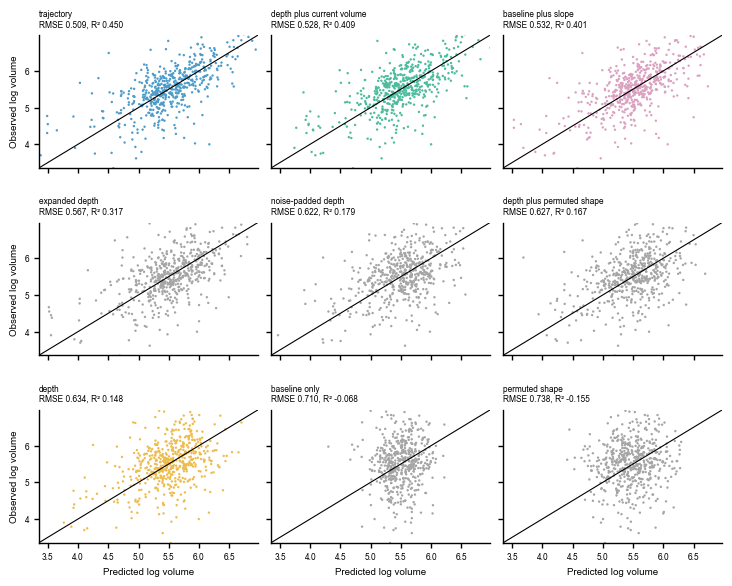

  saved outputs\figures\atlas\08_predictor_set_scatter.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


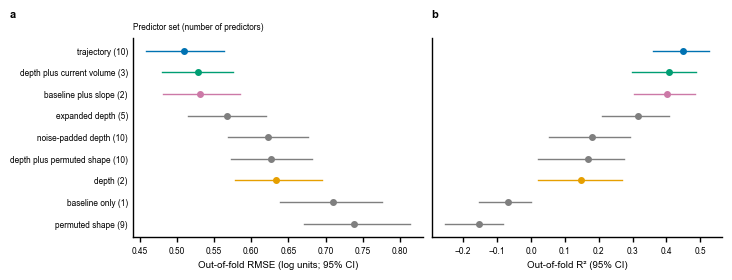

  saved outputs\figures\atlas\08_predictor_set_metrics.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


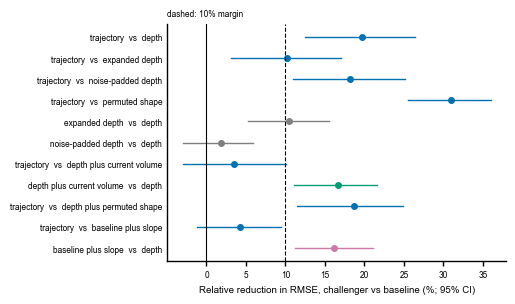

  saved outputs\figures\atlas\08_contrasts_all.{pdf,png}  (126 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


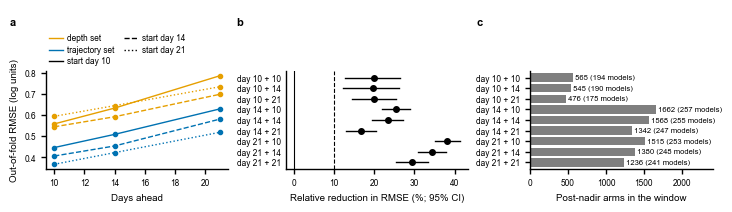

  saved outputs\figures\atlas\08_rolling_origins_detail.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


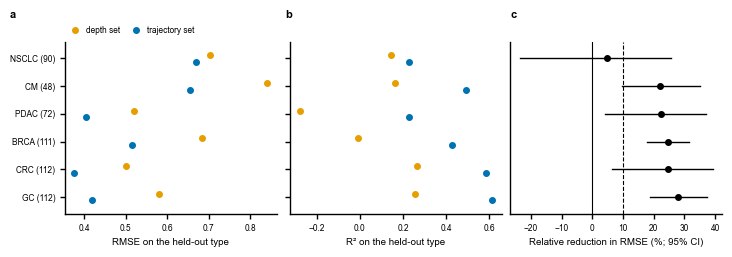

  saved outputs\figures\atlas\08_holdout_detail.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


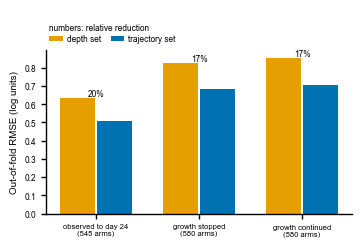

  saved outputs\figures\atlas\08_censoring_scenarios.{pdf,png}  (87 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


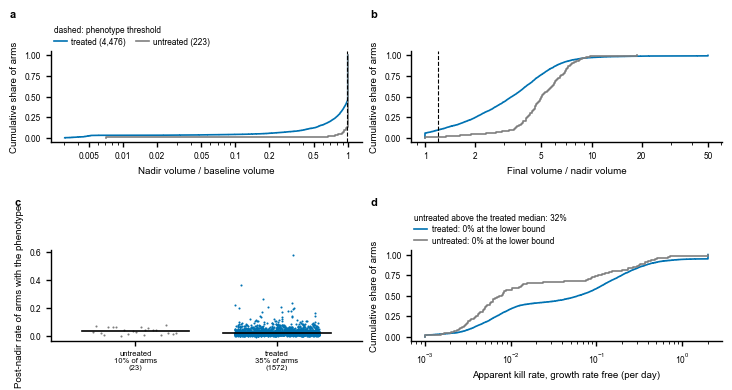

  saved outputs\figures\atlas\08_negative_controls.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


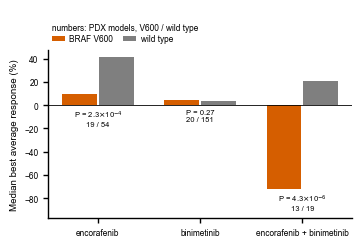

  saved outputs\figures\atlas\08_positive_control.{pdf,png}  (87 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


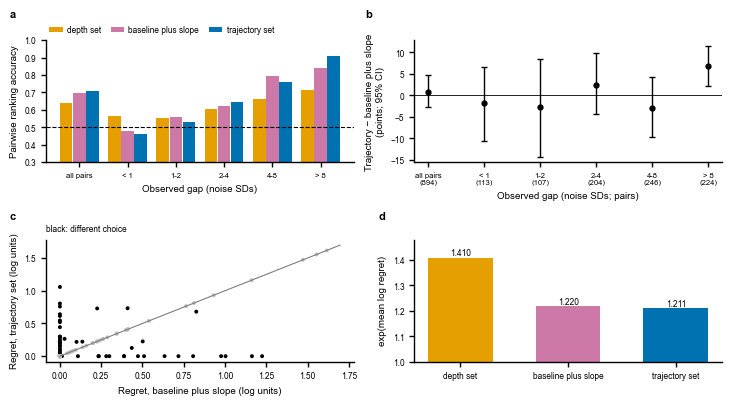

  saved outputs\figures\atlas\08_baseline_slope.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [18]:
# ==========================================================================
# 3.6 Atlas: controls and robustness (analysis Section 8)
# ==========================================================================

def all_set_predictions():
    """Observed outcome and the out-of-fold predictions of every predictor set (8.1)."""
    frame = FROZEN["forecast_predictions_all_sets"]
    sets = list(FROZEN["predictor_set_performance"].sort_values("rmse").predictor_set)
    return frame, sets, {name: frame[f"prediction_{name.replace(' ', '_')}"].to_numpy(float) for name in sets}


def atlas_predictor_set_scatter():
    # Observed against predicted day-24 log volume for every predictor set
    # (best RMSE first), on shared axes.
    frame, sets, predictions = all_set_predictions()
    observed = frame.outcome_log_volume.to_numpy(float)
    limits = percentile_limits(np.r_[observed, *predictions.values()], 0.2, 99.8)
    figure, axes = atlas_figure(len(sets), ncols=3, panel_height_mm=50, sharex=True, sharey=True)
    for axis, name in zip(axes, sets):
        color = SET_COLORS.get(name, COLORS["reference"])
        axis.scatter(predictions[name], observed, s=3, color=tint(color, 0.7), edgecolor="none", rasterized=True)
        axis.plot(limits, limits, color=COLORS["ink"], linewidth=0.8)
        axis.set_xlim(limits)
        axis.set_ylim(limits)
        axis.set_title(f"{name}\nRMSE {rmse(observed, predictions[name]):.3f}, R² {r2_score(observed, predictions[name]):.3f}",
                       loc="left", fontsize=6)
    for axis in axes[-3:]:
        axis.set_xlabel("Predicted log volume")
    for axis in axes[::3]:
        axis.set_ylabel("Observed log volume")
    save_atlas(figure, "08_predictor_set_scatter")


def atlas_predictor_set_metrics():
    # a  out-of-fold RMSE and b  R² of every predictor set, with 95% intervals
    # resampling PDX models (predictions held fixed; atlas only).
    frame, sets, predictions = all_set_predictions()
    observed = frame.outcome_log_volume.to_numpy(float)
    # One generator for all sets; each set's two intervals use consecutive
    # stretches of its stream.
    rng = np.random.default_rng(FIGURE_SEEDS["atlas_set_r2"])
    rows = []
    for name in sets:
        predicted = predictions[name]
        rows.append((name, rmse(observed, predicted),
                     *bootstrap_interval(frame.model_id, lambda r, p=predicted: rmse(observed[r], p[r]), N_FIGURE_BOOTSTRAP, rng),
                     r2_score(observed, predicted),
                     *bootstrap_interval(frame.model_id, lambda r, p=predicted: r2_score(observed[r], p[r]),
                                         N_FIGURE_BOOTSTRAP, rng)))
    table = pd.DataFrame(rows, columns=["set", "rmse", "rmse_low", "rmse_high", "r2", "r2_low", "r2_high"])
    count = FROZEN["predictor_set_performance"].set_index("predictor_set").predictors
    labels = [f"{name} ({int(count[name])})" for name in table.set]
    colors = [SET_COLORS.get(name, COLORS["reference"]) for name in table.set]
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], 65 * MM), layout="constrained",
                                      sharey=True)
    forest_rows(axes["a"], labels, table.rmse, table.rmse_low, table.rmse_high, colors=colors)
    axes["a"].set_xlabel("Out-of-fold RMSE (log units; 95% CI)")
    forest_rows(axes["b"], labels, table.r2, table.r2_low, table.r2_high, colors=colors)
    axes["b"].set_xlabel("Out-of-fold R² (95% CI)")
    axes["a"].set_title("Predictor set (number of predictors)", loc="left", fontsize=6)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "08_predictor_set_metrics")


def atlas_contrasts_all():
    # Every contrast of 8.1: relative reduction in RMSE of the challenger
    # against the baseline set, with the 95% interval of the analysis.
    contrasts = FROZEN["predictor_contrasts"]
    labels = [f"{row.challenger}  vs  {row.baseline}" for row in contrasts.itertuples()]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"] * 0.7, (4.5 * len(contrasts) + 25) * MM),
                                layout="constrained")
    forest_rows(axis, labels, 100 * contrasts.relative_reduction, 100 * contrasts.low, 100 * contrasts.high,
                colors=[SET_COLORS.get(row.challenger, COLORS["reference"]) for row in contrasts.itertuples()], reference=0)
    axis.axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axis.set_xlabel("Relative reduction in RMSE, challenger vs baseline (%; 95% CI)")
    axis.set_title(f"dashed: {FORECAST_MARGIN:.0%} margin", loc="left", fontsize=6)
    save_atlas(figure, "08_contrasts_all")


def atlas_rolling_origins_detail():
    # Each start day and horizon (8.1): a  RMSE of both sets by days ahead,
    # one line pair per start day; b  relative reduction with its 95% interval;
    # c  arms in each window.
    # Days ahead = horizon day − start day; each window is its own set of arms.
    rolling = FROZEN["rolling_origins"].assign(lead=lambda f: f.horizon_day - f.start_day)
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=55)
    start_styles = dict(zip(sorted(rolling.start_day.unique()), ["-", "--", ":"]))
    for start, rows in rolling.groupby("start_day"):
        rows = rows.sort_values("lead")
        for key in ("depth", "trajectory"):
            axes[0].plot(rows.lead, rows[f"{key}_rmse"], marker="o", markersize=3, linestyle=start_styles[start],
                         color=SET_COLORS[key])
    axes[0].set_xlabel("Days ahead")
    axes[0].set_ylabel("Out-of-fold RMSE (log units)")
    legend_above(axes[0], ncols=2, handles=[Line2D([], [], color=SET_COLORS[k], label=SET_NAMES[k]) for k in ("depth", "trajectory")]
                 + [Line2D([], [], color=COLORS["ink"], linestyle=style, label=f"start day {start}")
                    for start, style in start_styles.items()])
    labels = [f"day {row.start_day} + {row.lead}" for row in rolling.itertuples()]
    forest_rows(axes[1], labels, 100 * rolling.relative_reduction, 100 * rolling.low, 100 * rolling.high, reference=0)
    axes[1].axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].set_xlabel("Relative reduction in RMSE (%; 95% CI)")
    axes[2].barh(range(len(rolling)), rolling.arms, color=COLORS["reference"])
    for y, row in enumerate(rolling.itertuples()):
        axes[2].text(row.arms, y, f" {row.arms} ({row.pdx_models} models)", va="center", fontsize=5.5)
    axes[2].set_yticks(range(len(rolling)), labels)
    axes[2].set_ylim(len(rolling) - 0.4, -0.6)
    axes[2].set_xlim(0, rolling.arms.max() * 1.45)
    axes[2].set_xlabel("Post-nadir arms in the window")
    label_panels(axes)
    save_atlas(figure, "08_rolling_origins_detail")


def atlas_holdout_detail():
    # Each tumor type held out of training (8.1): a  RMSE and b  R² of both
    # sets on the held-out type; c  relative reduction with its 95% interval.
    holdout = FROZEN["tumor_type_holdout"].sort_values("relative_reduction").reset_index(drop=True)
    labels = [f"{row.held_out_tumor_type} ({row.test_arms})" for row in holdout.itertuples()]
    figure, axes = plt.subplot_mosaic([["a", "b", "c"]], figsize=(FIGURE_WIDTH["double"], 62 * MM), layout="constrained",
                                      sharey=True)
    for key_axis, metric, label in (("a", "rmse", "RMSE on the held-out type"), ("b", "r2", "R² on the held-out type")):
        for offset, key in ((-0.12, "depth"), (0.12, "trajectory")):
            axes[key_axis].plot(holdout[f"{key}_{metric}"], np.arange(len(holdout)) + offset, "o", color=SET_COLORS[key],
                                markersize=4, label=SET_NAMES[key])
        axes[key_axis].set_xlabel(label)
    axes["a"].set_yticks(range(len(holdout)), labels)
    axes["a"].set_ylim(len(holdout) - 0.4, -0.6)
    legend_above(axes["a"], ncols=2)
    forest_rows(axes["c"], labels, 100 * holdout.relative_reduction, 100 * holdout.low, 100 * holdout.high, reference=0)
    axes["c"].axvline(100 * FORECAST_MARGIN, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes["c"].set_xlabel("Relative reduction in RMSE (%; 95% CI)")
    label_panels([axes[k] for k in "abc"])
    save_atlas(figure, "08_holdout_detail")


def atlas_censoring_scenarios():
    # RMSE of both sets on the arms observed to day 24 (7.2) and with the arms
    # that ended earlier reinserted: growth stopped at the last volume, or
    # continued at the arm's own non-negative slope (scenarios, not bounds).
    scenarios = FROZEN["censoring_scenarios"]
    endpoints = FROZEN["forecasting_endpoints"].iloc[0]
    # The observed-only row is the primary endpoint of 7.2, for reference.
    rows = [("observed to day 24", int(endpoints.n_arms), endpoints.depth_rmse, endpoints.trajectory_rmse)]
    rows += [(row.scenario, int(row.arms), row.depth_rmse, row.trajectory_rmse) for row in scenarios.itertuples()]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"], 60 * MM), layout="constrained")
    for offset, key, index in ((-0.18, "depth", 2), (0.18, "trajectory", 3)):
        axis.bar(np.arange(len(rows)) + offset, [r[index] for r in rows], 0.34, color=SET_COLORS[key], label=SET_NAMES[key])
    for x, row in enumerate(rows):
        axis.text(x, max(row[2], row[3]), f"{100 * (row[2] - row[3]) / row[2]:.0f}%", ha="center", va="bottom", fontsize=6)
    axis.set_xticks(range(len(rows)), [f"{r[0]}\n({r[1]} arms)" for r in rows], fontsize=5.5)
    axis.set_ylabel("Out-of-fold RMSE (log units)")
    legend_above(axis, ncols=2, title="numbers: relative reduction")
    save_atlas(figure, "08_censoring_scenarios")


def atlas_negative_controls():
    # Untreated arms as negative controls (8.3): a  nadir-to-baseline ratio and
    # b  regrowth multiple (cumulative distributions); c  post-nadir growth rate
    # of the arms meeting the phenotype rule; d  apparent kill rate of the
    # tolerant model fitted with the growth rate free (log scale).
    untreated, treated = FROZEN["untreated_regrowth_summary"], FROZEN["treated_regrowth_summary"]
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=50)
    for population, frame in (("treated", treated), ("untreated", untreated)):
        color = POPULATION_COLORS[population]
        ecdf_step(axes[0], frame.nadir_ratio, color=color, linewidth=1.2, label=f"{population} ({len(frame):,})")
        ecdf_step(axes[1], frame.regrowth_multiple.clip(upper=50), color=color, linewidth=1.2)
    axes[0].axvline(1 - REGRESSION_FRACTION, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Nadir volume / baseline volume")
    axes[1].axvline(REGROWTH_MULTIPLE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[1].set_xscale("log")
    axes[1].set_xlabel("Final volume / nadir volume")
    for axis in axes[:2]:
        plain_log_axis(axis, "x")
        axis.set_ylabel("Cumulative share of arms")
    legend_above(axes[0], ncols=2, title="dashed: phenotype threshold")
    groups = {f"untreated\n{100 * RESULTS['untreated_phenotype_share']:.0f}% of arms":
              untreated.loc[untreated.durability_phenotype.astype(bool), "post_nadir_growth_rate"],
              f"treated\n{100 * RESULTS['treated_phenotype_share']:.0f}% of arms":
              treated.loc[treated.durability_phenotype.astype(bool), "post_nadir_growth_rate"]}
    strip_plot(axes[2], groups, colors=dict(zip(groups, [POPULATION_COLORS["untreated"], POPULATION_COLORS["treated"]])),
               size=1.5, rasterized=True)
    axes[2].set_ylabel("Post-nadir rate of arms with the phenotype")
    axes[2].tick_params(axis="x", labelsize=5.5)
    free = FROZEN.get("growth_free_kill_rates")
    if free is not None:
        free = free.assign(is_control=free.is_control.astype(bool),
                           pinned_low=free.pinned.fillna("").astype(str).str.contains("log_kill@low"))
        for population, is_control in (("treated", False), ("untreated", True)):
            part = free.loc[free.is_control == is_control]
            ecdf_step(axes[3], part.kill_rate.clip(lower=1e-4), color=POPULATION_COLORS[population], linewidth=1.2,
                      label=f"{population}: {100 * part.pinned_low.mean():.0f}% at the lower bound")
        axes[3].set_xscale("log")
        axes[3].set_xlabel("Apparent kill rate, growth rate free (per day)")
        axes[3].set_ylabel("Cumulative share of arms")
        legend_above(axes[3], title=f"untreated above the treated median: "
                                    f"{100 * RESULTS['untreated_kill_above_treated_median']:.0f}%")
    label_panels(axes)
    save_atlas(figure, "08_negative_controls")


def atlas_positive_control():
    # Median best average response of BRAF V600-mutant and wild-type PDX
    # models under each MAPK-pathway agent (8.3), with the one-sided
    # Mann–Whitney P value and the PDX models in each group.
    control = FROZEN["positive_control_braf"]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"], 60 * MM), layout="constrained")
    positions = np.arange(len(control))
    axis.bar(positions - 0.18, control.median_response_v600, 0.34, color=COLORS["fourth"], label="BRAF V600")
    axis.bar(positions + 0.18, control.median_response_wild_type, 0.34, color=COLORS["reference"], label="wild type")
    for x, row in zip(positions, control.itertuples()):
        axis.text(x, min(row.median_response_v600, row.median_response_wild_type, 0) - 3,
                  f"P = {figure_p(row.one_sided_p)}\n{row.braf_v600_models} / {row.wild_type_models}", ha="center",
                  va="top", fontsize=5.5)
    axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
    axis.set_xticks(positions, control.agent, fontsize=6)
    axis.set_ylabel("Median best average response (%)")
    axis.set_ylim(min(control.median_response_v600.min(), control.median_response_wild_type.min(), 0) - 25, None)
    legend_above(axis, ncols=2, title="numbers: PDX models, V600 / wild type")
    save_atlas(figure, "08_positive_control")


def atlas_baseline_slope():
    # Baseline plus slope, the simplest trajectory summary (8.5): a  pairwise
    # ranking accuracy of three sets by observed separation; b  trajectory
    # minus baseline-plus-slope accuracy with its 95% interval; c  regret of
    # baseline plus slope against the trajectory set in each PDX model;
    # d  mean regret of the three sets.
    ranking = FROZEN["baseline_slope_ranking"]
    slope_regret = FROZEN.get("baseline_slope_regret")
    regret = FROZEN["treatment_selection_regret"]
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=52)
    positions = np.arange(len(ranking))
    for offset, column, key in ((-0.27, "depth_accuracy", "depth"), (0.0, "baseline_slope_accuracy", "baseline plus slope"),
                                (0.27, "trajectory_accuracy", "trajectory")):
        axes[0].bar(positions + offset, ranking[column], 0.26, color=SET_COLORS[key], label=SET_NAMES[key])
    axes[0].axhline(0.5, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[0].set_xticks(positions, [str(p).replace(" noise SDs", "") for p in ranking.pairs], fontsize=5.5)
    axes[0].set_ylim(min(0.3, ranking[["depth_accuracy", "baseline_slope_accuracy", "trajectory_accuracy"]].min().min() - 0.05), 1)
    axes[0].set_xlabel("Observed gap (noise SDs)")
    axes[0].set_ylabel("Pairwise ranking accuracy")
    legend_above(axes[0], ncols=3)
    axes[1].errorbar(positions, 100 * ranking.trajectory_minus_baseline_slope,
                     yerr=100 * interval_errors(ranking.trajectory_minus_baseline_slope, ranking.low, ranking.high),
                     fmt="o", color=COLORS["ink"], capsize=2, markersize=3.5)
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[1].set_xticks(positions, [f"{str(p).replace(' noise SDs', '')}\n({n})" for p, n in zip(ranking.pairs, ranking.n_pairs)],
                       fontsize=5.5)
    axes[1].set_xlabel("Observed gap (noise SDs; pairs)")
    axes[1].set_ylabel("Trajectory − baseline plus slope\n(points; 95% CI)")
    if slope_regret is not None:
        axes[2].scatter(slope_regret.slope_prediction_regret, slope_regret.trajectory_prediction_regret, s=8,
                        color=np.where(slope_regret.different_choice.astype(bool), COLORS["ink"], COLORS["light"]),
                        edgecolor="none")
        limit = max(slope_regret.slope_prediction_regret.max(), slope_regret.trajectory_prediction_regret.max()) * 1.05
        axes[2].plot([0, limit], [0, limit], color=COLORS["reference"], linewidth=0.8)
        axes[2].set_xlabel("Regret, baseline plus slope (log units)")
        axes[2].set_ylabel("Regret, trajectory set (log units)")
        axes[2].set_title("black: different choice", loc="left", fontsize=6)
        means = [("depth", regret.depth_prediction_regret.mean()),
                 ("baseline plus slope", slope_regret.slope_prediction_regret.mean()),
                 ("trajectory", regret.trajectory_prediction_regret.mean())]
        axes[3].bar(range(3), [np.exp(m) for _, m in means], color=[SET_COLORS[k] for k, _ in means], width=0.6)
        for x, (_, m) in enumerate(means):
            axes[3].text(x, np.exp(m), f"{np.exp(m):.3f}", ha="center", va="bottom", fontsize=6)
        axes[3].set_xticks(range(3), [SET_NAMES[k] for k, _ in means], fontsize=6)
        axes[3].set_ylim(1, None)
        axes[3].set_ylabel("exp(mean log regret)")
    label_panels(axes)
    save_atlas(figure, "08_baseline_slope")


if DRAW_ATLAS:
    draw("08_predictor_set_scatter", atlas_predictor_set_scatter, requires=("forecast_predictions_all_sets",
                                                                          "predictor_set_performance"))
    draw("08_predictor_set_metrics", atlas_predictor_set_metrics, requires=("forecast_predictions_all_sets",
                                                                          "predictor_set_performance"))
    draw("08_contrasts_all", atlas_contrasts_all, requires=("predictor_contrasts",))
    draw("08_rolling_origins_detail", atlas_rolling_origins_detail, requires=("rolling_origins",))
    draw("08_holdout_detail", atlas_holdout_detail, requires=("tumor_type_holdout",))
    draw("08_censoring_scenarios", atlas_censoring_scenarios, requires=("censoring_scenarios", "forecasting_endpoints"))
    draw("08_negative_controls", atlas_negative_controls, requires=("untreated_regrowth_summary",
                                                                    "treated_regrowth_summary"))
    draw("08_positive_control", atlas_positive_control, requires=("positive_control_braf",))
    draw("08_baseline_slope", atlas_baseline_slope, requires=("baseline_slope_ranking", "treatment_selection_regret"))

### 3.7 Molecular correlates (analysis Section 9)

| File | Content |
|---|---|
| `09_blocks_detail` | Out-of-fold R² of each feature block against its shuffle null, curated against hallmark signatures, and the dissociation statistic |
| `09_feature_scatter` | Each signature and context feature against depth and against durability |
| `09_feature_correlations` | Spearman correlations among the features and the two endpoints |
| `09_signatures_by_tumor_type` | Each model-level signature score by tumor type |
| `09_gene_set_coverage` | Genes of each curated and hallmark set found in the expression data |

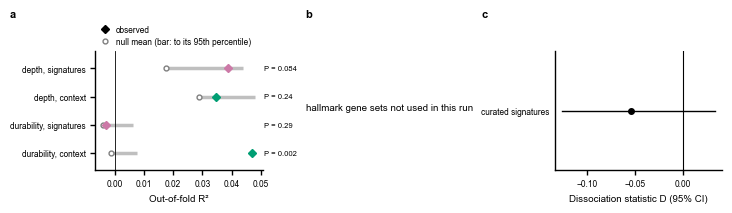

  saved outputs\figures\atlas\09_blocks_detail.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


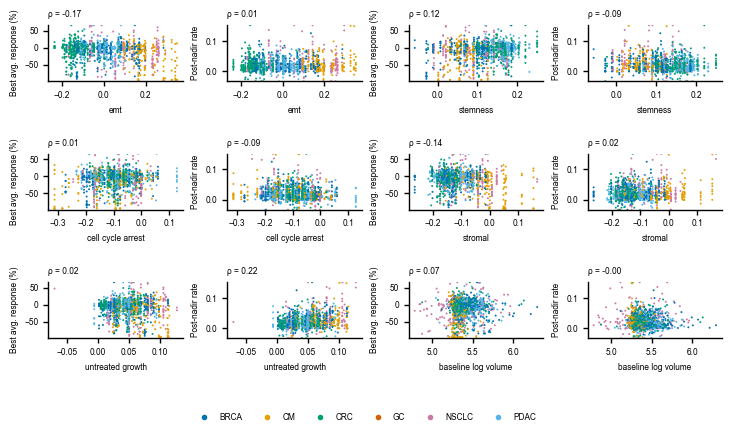

  saved outputs\figures\atlas\09_feature_scatter.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


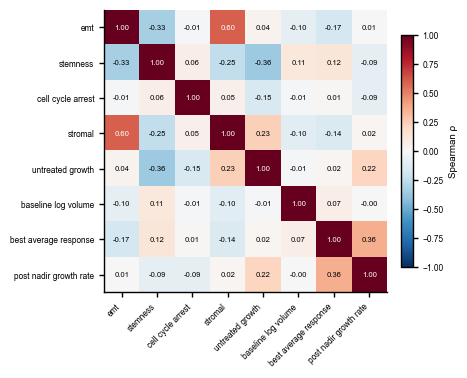

  saved outputs\figures\atlas\09_feature_correlations.{pdf,png}  (114 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


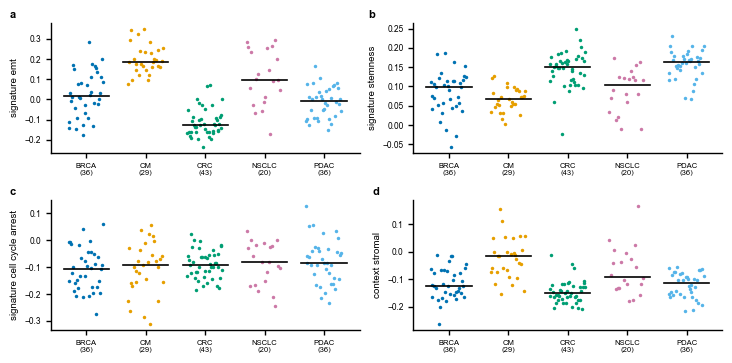

  saved outputs\figures\atlas\09_signatures_by_tumor_type.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


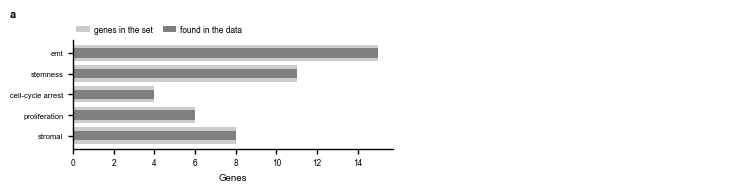

  saved outputs\figures\atlas\09_gene_set_coverage.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [19]:
# ==========================================================================
# 3.7 Atlas: molecular correlates (analysis Section 9)
# ==========================================================================

MOLECULAR_FEATURES = ["signature_emt", "signature_stemness", "signature_cell_cycle_arrest", "context_stromal",
                      "context_untreated_growth", "context_baseline_log_volume"]
BLOCK_COLORS = {"signatures": COLORS["fifth"], "context": COLORS["third"], "hallmark": COLORS["sixth"]}


def atlas_blocks_detail():
    # a  out-of-fold R² of each block (points) with the mean (open) and 95th
    # percentile (bar end) of its within-tumor-type shuffle null; b  curated
    # against hallmark signatures; c  the dissociation statistic D with its
    # 95% interval (curated and hallmark signatures).
    blocks = FROZEN["molecular_blocks"]
    hallmark = FROZEN.get("molecular_blocks_hallmark")
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=55)
    rows = list(blocks.itertuples())
    for y, row in enumerate(rows):
        color = BLOCK_COLORS.get(row.block, COLORS["reference"])
        axes[0].plot([row.null_mean, row.null_95th], [y, y], color=COLORS["light"], linewidth=2.5, solid_capstyle="butt")
        axes[0].plot(row.null_mean, y, "o", markerfacecolor="white", markeredgecolor=COLORS["reference"], markersize=3.5)
        axes[0].plot(row.r2, y, "D", color=color, markersize=4)
        axes[0].text(1.01, y, f"P = {figure_p(row.permutation_p)}", transform=axes[0].get_yaxis_transform(),
                     va="center", fontsize=5.5)
    axes[0].set_yticks(range(len(rows)), [f"{row.outcome}, {row.block}" for row in rows])
    axes[0].set_ylim(len(rows) - 0.4, -0.6)
    axes[0].axvline(0, color=COLORS["ink"], linewidth=0.6)
    axes[0].set_xlabel("Out-of-fold R²")
    legend_above(axes[0], handles=[
        Line2D([], [], marker="D", linestyle="", color=COLORS["ink"], markersize=4, label="observed"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["reference"],
               markersize=3.5, label="null mean (bar: to its 95th percentile)")])
    if hallmark is not None and len(hallmark):
        positions = np.arange(len(hallmark))
        axes[1].bar(positions - 0.18, hallmark.r2_curated, 0.34, color=BLOCK_COLORS["signatures"], label="curated signatures")
        axes[1].bar(positions + 0.18, hallmark.r2_hallmark, 0.34, color=BLOCK_COLORS["hallmark"], label="hallmark signatures")
        axes[1].scatter(positions + 0.18, hallmark.null_95th, marker="_", s=80, color=COLORS["ink"], zorder=3)
        axes[1].axhline(0, color=COLORS["ink"], linewidth=0.6)
        axes[1].set_xticks(positions, hallmark.outcome)
        axes[1].set_ylabel("Out-of-fold R² (dash: hallmark null 95th)")
        legend_above(axes[1])
    else:
        axes[1].text(0.5, 0.5, "hallmark gene sets not used in this run", transform=axes[1].transAxes, ha="center")
        axes[1].set_axis_off()
    labels, estimates, lows, highs = [], [], [], []
    for key, label in (("dissociation", "curated signatures"), ("dissociation_hallmark", "hallmark signatures")):
        if key in RESULTS and isinstance(RESULTS[key], (int, float)):
            labels.append(label)
            estimates.append(RESULTS[key])
            lows.append(RESULTS.get(f"{key}_low", np.nan))
            highs.append(RESULTS.get(f"{key}_high", np.nan))
    forest_rows(axes[2], labels, estimates, lows, highs, reference=0)
    axes[2].set_xlabel("Dissociation statistic D (95% CI)")
    label_panels(axes)
    save_atlas(figure, "09_blocks_detail")


def atlas_feature_scatter():
    # Each molecular or context feature (rows of two panels) against best
    # average response (left) and the post-nadir growth rate (right), arms of
    # the molecular analysis set, colored by tumor type, with ρ.
    frame = FROZEN["molecular_frame"]
    features = [f for f in MOLECULAR_FEATURES if f in frame.columns]
    figure, axes = atlas_figure(2 * len(features), ncols=4, panel_height_mm=36)
    colors = frame.tumor_type.map(TUMOR_TYPE_COLORS).fillna(COLORS["reference"])
    for index, feature in enumerate(features):
        for offset, (column, limits, label) in enumerate(((DEPTH, DEPTH_LIMITS, "Best avg. response (%)"),
                                                          (DURABILITY, DURABILITY_LIMITS, "Post-nadir rate"))):
            axis = axes[2 * index + offset]
            axis.scatter(frame[feature], frame[column].clip(*limits), s=2, c=list(colors), edgecolor="none", rasterized=True)
            axis.set_ylim(limits)
            axis.set_xlabel(pretty(feature).replace("signature ", "").replace("context ", ""), fontsize=6)
            axis.set_ylabel(label, fontsize=6)
            axis.set_title(f"ρ = {spearman(frame[feature], frame[column])[0]:.2f}", loc="left", fontsize=6)
    figure.legend(handles=[Line2D([], [], marker="o", linestyle="", color=TUMOR_TYPE_COLORS[t], markersize=3, label=t)
                           for t in TUMOR_TYPES], loc="outside lower center", ncols=len(TUMOR_TYPES), frameon=False)
    save_atlas(figure, "09_feature_scatter")


def atlas_feature_correlations():
    # Spearman correlation among the molecular and context features and the
    # two endpoints (arms of the molecular analysis set).
    frame = FROZEN["molecular_frame"]
    columns = [f for f in MOLECULAR_FEATURES if f in frame.columns] + [DEPTH, DURABILITY]
    matrix = frame[columns].rank().corr().to_numpy()
    labels = [pretty(c).replace("signature ", "").replace("context ", "") for c in columns]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"] * 1.3, 95 * MM), layout="constrained")
    image = axis.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(len(columns)):
        for j in range(len(columns)):
            axis.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=5.5,
                      color="white" if abs(matrix[i, j]) > 0.6 else COLORS["ink"])
    axis.set_xticks(range(len(columns)), labels, rotation=45, ha="right")
    axis.set_yticks(range(len(columns)), labels)
    figure.colorbar(image, ax=axis, shrink=0.8).set_label("Spearman ρ")
    save_atlas(figure, "09_feature_correlations")


def atlas_signatures_by_tumor_type():
    # Model-level scores (one value per PDX model) by tumor type.
    frame = FROZEN["molecular_frame"].drop_duplicates("model_id")
    features = [f for f in MOLECULAR_FEATURES[:4] if f in frame.columns]
    figure, axes = atlas_figure(len(features), ncols=2, panel_height_mm=45)
    for axis, feature in zip(axes, features):
        strip_plot(axis, {t: frame.loc[frame.tumor_type == t, feature] for t in TUMOR_TYPES if (frame.tumor_type == t).any()},
                   colors=TUMOR_TYPE_COLORS)
        axis.set_ylabel(pretty(feature))
        axis.tick_params(axis="x", labelsize=5.5)
    label_panels(axes)
    save_atlas(figure, "09_signatures_by_tumor_type")


def atlas_gene_set_coverage():
    # Genes of each set found in the expression data: a  curated sets of 9.1;
    # b  hallmark sets of 9.3 (when used).
    curated = TABLES.get("gene_sets")
    hallmark = FROZEN.get("hallmark_sets")
    panels = [frame for frame in (curated, hallmark) if frame is not None and len(frame)]
    figure, axes = atlas_figure(len(panels), ncols=2, panel_height_mm=50)
    for axis, frame in zip(axes, panels):
        name_column = "gene_set" if "gene_set" in frame.columns else "hallmark_set"
        positions = np.arange(len(frame))
        axis.barh(positions, frame.genes_in_set, color=tint(COLORS["reference"], 0.4), label="genes in the set")
        axis.barh(positions, frame.genes_in_data, color=COLORS["reference"], height=0.45, label="found in the data")
        axis.set_yticks(positions, [str(name).replace("HALLMARK_", "").replace("_", " ").lower() for name in frame[name_column]],
                        fontsize=5.5)
        axis.invert_yaxis()
        axis.set_xlabel("Genes")
        legend_above(axis, ncols=2)
    label_panels(axes)
    save_atlas(figure, "09_gene_set_coverage")


if DRAW_ATLAS:
    draw("09_blocks_detail", atlas_blocks_detail, requires=("molecular_blocks",))
    draw("09_feature_scatter", atlas_feature_scatter, requires=("molecular_frame",))
    draw("09_feature_correlations", atlas_feature_correlations, requires=("molecular_frame",))
    draw("09_signatures_by_tumor_type", atlas_signatures_by_tumor_type, requires=("molecular_frame",))
    draw("09_gene_set_coverage", atlas_gene_set_coverage, requires=("gene_sets",))

### 3.8 Combinations (analysis Section 10)

| File | Content |
|---|---|
| `10_gains_by_combination` | Depth and durability gain of every evaluation, by combination, with the median and its interval |
| `10_gain_scatter_by_combination` | Depth gain against durability gain within each combination |
| `10_gains_by_tumor_type` | Category mix and both gains by tumor type |
| `10_gain_vs_best_component` | Each gain against the best single component's own value |
| `10_combination_gallery` | For each combination, the evaluation closest to its median gains, with its components and the untreated arm |

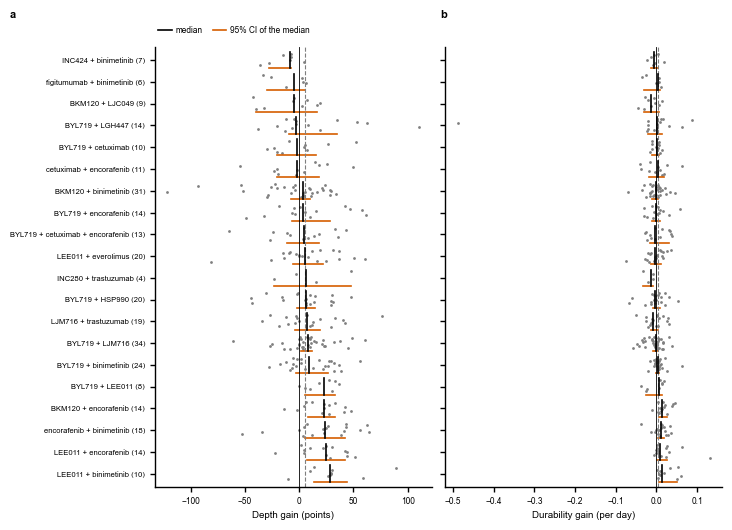

  saved outputs\figures\atlas\10_gains_by_combination.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


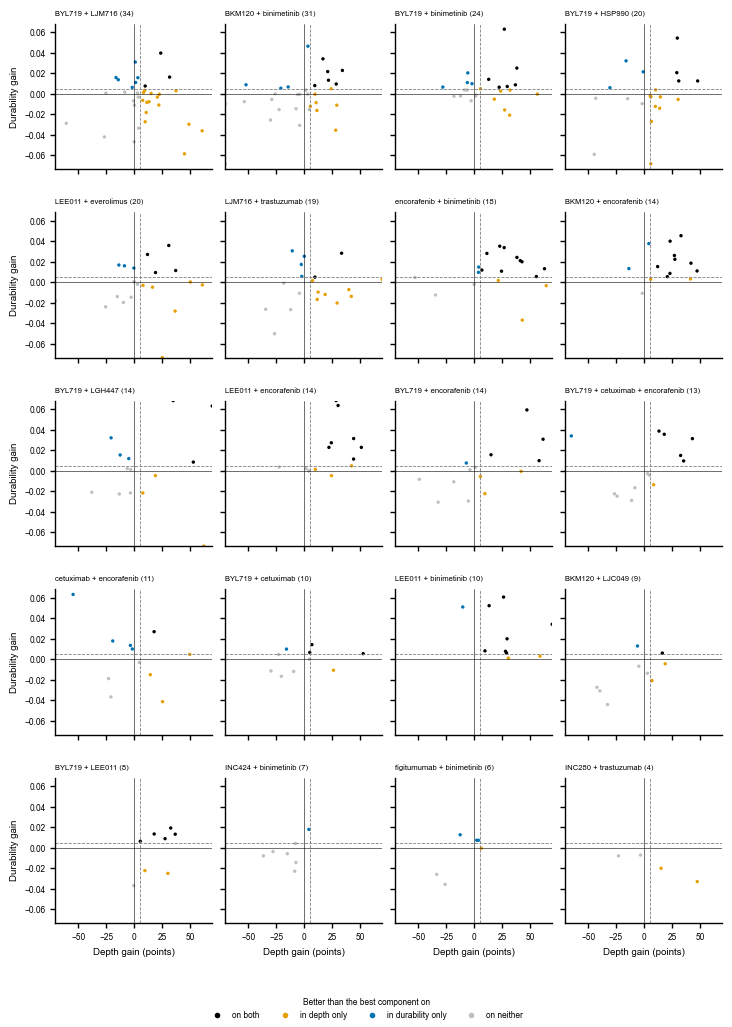

  saved outputs\figures\atlas\10_gain_scatter_by_combination.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


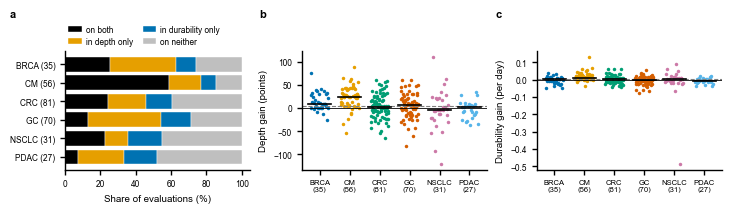

  saved outputs\figures\atlas\10_gains_by_tumor_type.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


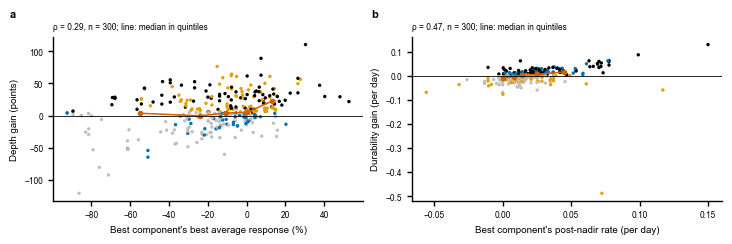

  saved outputs\figures\atlas\10_gain_vs_best_component.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


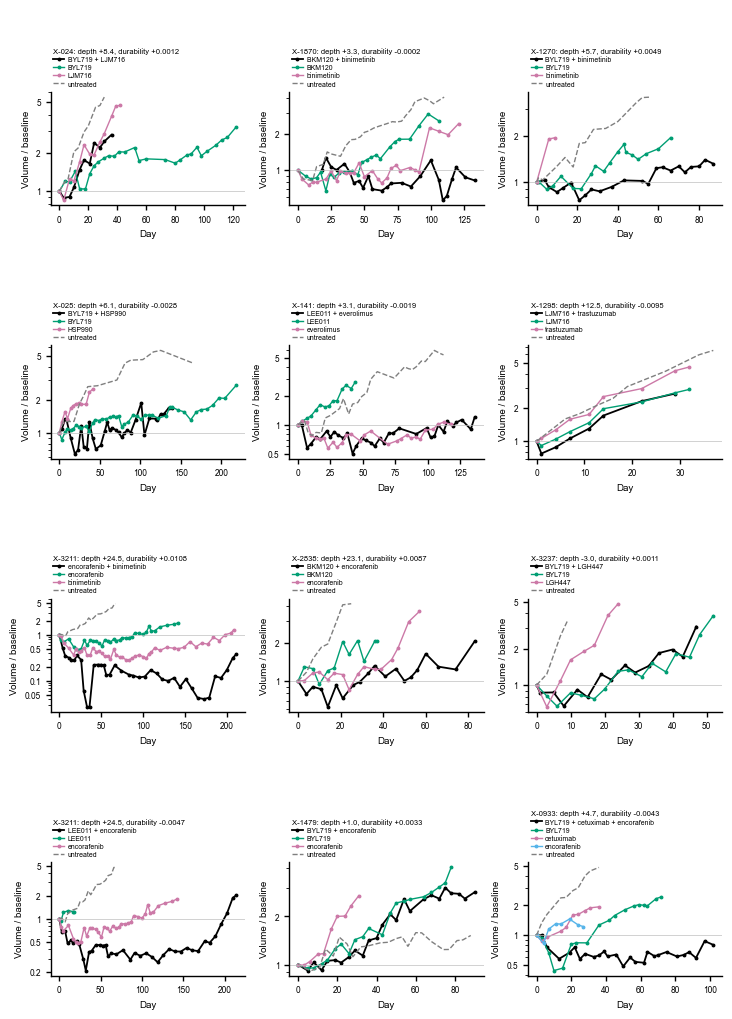

  saved outputs\figures\atlas\10_combination_gallery.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


In [20]:
# ==========================================================================
# 3.8 Atlas: combinations (analysis Section 10)
# ==========================================================================

CATEGORY_ORDER = ["superior on both", "superior in depth only", "superior in durability only", "superior on neither"]
CATEGORY_COLORS = {"superior on both": COLORS["ink"], "superior in depth only": COLORS["depth"],
                   "superior in durability only": COLORS["trajectory"], "superior on neither": COLORS["light"]}


def combination_frame():
    """Every evaluation of 10.1 with its PDX model's tumor type and the best
    single component's own depth and durability (as in 10.1: the deepest
    component by mean best average response, the slowest-regrowing component
    by mean post-nadir rate, within the PDX model)."""
    evaluations = FROZEN["combination_evaluations"].copy()
    evaluations["tumor_type"] = evaluations.model_id.map(arms.groupby("model_id").tumor_type.first())
    depth_lookup = treated_with_endpoints.groupby(["model_id", "treatment"])[DEPTH].mean()
    durability_lookup = post_nadir_arms.groupby(["model_id", "treatment"])[DURABILITY].mean()
    best_depth, best_durability = [], []
    for row in evaluations.itertuples():
        parts = [part.strip() for part in row.combination.split("+")]
        best_depth.append(min(depth_lookup.get((row.model_id, part), np.nan) for part in parts))
        best_durability.append(np.nanmin([durability_lookup.get((row.model_id, part), np.nan) for part in parts]))
    evaluations["best_component_depth"], evaluations["best_component_durability"] = best_depth, best_durability
    # The rebuilt components must reproduce the saved gains.
    combination_depth = [depth_lookup[(row.model_id, row.combination)] for row in evaluations.itertuples()]
    combination_durability = [durability_lookup[(row.model_id, row.combination)] for row in evaluations.itertuples()]
    assert np.allclose(evaluations.best_component_depth - combination_depth, evaluations.depth_gain)
    assert np.allclose(evaluations.best_component_durability - combination_durability, evaluations.durability_gain)
    return evaluations


def atlas_gains_by_combination():
    # a  depth gain and b  durability gain of every evaluation (points) by
    # combination, with the median and its bootstrap interval of 10.2 (black);
    # dashed: the thresholds of 10.1.
    evaluations = FROZEN["combination_evaluations"]
    summary = FROZEN["combination_summary"].set_index("combination")
    order = summary.sort_values("median_depth_gain").index
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(60, 5 * len(order) + 30) * MM),
                                      layout="constrained", sharey=True)
    for key, column, prefix, threshold, label in (("a", "depth_gain", "depth", DEPTH_GAIN_THRESHOLD, "Depth gain (points)"),
                                                  ("b", "durability_gain", "durability", DURABILITY_GAIN_THRESHOLD,
                                                   "Durability gain (per day)")):
        groups = {name: evaluations.loc[evaluations.combination == name, column] for name in order}
        strip_plot(axes[key], groups, size=2, vertical=False)
        for y, name in enumerate(order):
            row = summary.loc[name]
            axes[key].plot([row[f"{prefix}_low"], row[f"{prefix}_high"]], [y + 0.38] * 2, color=COLORS["fourth"], linewidth=1.2)
        axes[key].axvline(0, color=COLORS["ink"], linewidth=0.6)
        axes[key].axvline(threshold, color=COLORS["reference"], linestyle="--", linewidth=0.8)
        axes[key].set_xlabel(label)
    axes["a"].tick_params(axis="y", labelsize=5.5)
    legend_above(axes["a"], ncols=2, handles=[
        Line2D([], [], color=COLORS["ink"], linewidth=1.2, label="median"),
        Line2D([], [], color=COLORS["fourth"], linewidth=1.2, label="95% CI of the median")])
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "10_gains_by_combination")


def atlas_gain_scatter_by_combination():
    # Depth gain against durability gain within each combination (category
    # colors as in Figure 4; dashed: thresholds), shared axes.
    evaluations = FROZEN["combination_evaluations"]
    order = evaluations.combination.value_counts().index
    x_limits = percentile_limits(evaluations.depth_gain)
    y_limits = percentile_limits(evaluations.durability_gain)
    figure, axes = atlas_figure(len(order), ncols=4, panel_height_mm=52, sharex=True, sharey=True)
    for axis, name in zip(axes, order):
        part = evaluations.loc[evaluations.combination == name]
        axis.scatter(part.depth_gain.clip(*x_limits), part.durability_gain.clip(*y_limits), s=6,
                     c=list(part.category.map(CATEGORY_COLORS)), edgecolor="none")
        axis.axhline(DURABILITY_GAIN_THRESHOLD, color=COLORS["reference"], linestyle="--", linewidth=0.6)
        axis.axvline(DEPTH_GAIN_THRESHOLD, color=COLORS["reference"], linestyle="--", linewidth=0.6)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.4)
        axis.axvline(0, color=COLORS["ink"], linewidth=0.4)
        axis.set_xlim(x_limits)
        axis.set_ylim(y_limits)
        axis.set_title(f"{name} ({len(part)})", loc="left", fontsize=5.5)
    for axis in axes[-4:]:
        axis.set_xlabel("Depth gain (points)")
    for axis in axes[::4]:
        axis.set_ylabel("Durability gain")
    figure.legend(handles=[Line2D([], [], marker="o", linestyle="", color=CATEGORY_COLORS[c], markersize=3,
                                  label=c.replace("superior ", "")) for c in CATEGORY_ORDER],
                  loc="outside lower center", ncols=4, frameon=False, title="Better than the best component on")
    save_atlas(figure, "10_gain_scatter_by_combination")


def atlas_gains_by_tumor_type():
    # a  category mix of the evaluations by tumor type; b  depth gain and
    # c  durability gain by tumor type.
    evaluations = combination_frame()
    types = [t for t in TUMOR_TYPES if (evaluations.tumor_type == t).any()]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=55)
    # Share of each category within each tumor type (rows sum to 100%).
    mix = (evaluations.groupby("tumor_type").category.value_counts(normalize=True).unstack(fill_value=0)
           .reindex(index=types, columns=CATEGORY_ORDER, fill_value=0))
    left = np.zeros(len(types))
    for category in CATEGORY_ORDER:
        axes[0].barh(range(len(types)), 100 * mix[category], left=left, color=CATEGORY_COLORS[category],
                     edgecolor="white", linewidth=0.3, label=category.replace("superior ", ""))
        left += 100 * mix[category].to_numpy()
    counts = evaluations.tumor_type.value_counts()
    axes[0].set_yticks(range(len(types)), [f"{t} ({counts.get(t, 0)})" for t in types])
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Share of evaluations (%)")
    legend_above(axes[0], ncols=2)
    for axis, column, threshold, label in ((axes[1], "depth_gain", DEPTH_GAIN_THRESHOLD, "Depth gain (points)"),
                                           (axes[2], "durability_gain", DURABILITY_GAIN_THRESHOLD, "Durability gain (per day)")):
        strip_plot(axis, {t: evaluations.loc[evaluations.tumor_type == t, column] for t in types}, colors=TUMOR_TYPE_COLORS)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
        axis.axhline(threshold, color=COLORS["reference"], linestyle="--", linewidth=0.8)
        axis.set_ylabel(label)
        axis.tick_params(axis="x", labelsize=5.5)
    label_panels(axes)
    save_atlas(figure, "10_gains_by_tumor_type")


def atlas_gain_vs_best_component():
    # a  depth gain against the best component's own best average response
    # (a deep component leaves less room); b  durability gain against the
    # best component's own post-nadir rate; median gain in quintiles.
    evaluations = combination_frame()
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=60)
    for axis, x_column, y_column, x_label, y_label in (
            (axes[0], "best_component_depth", "depth_gain", "Best component's best average response (%)", "Depth gain (points)"),
            (axes[1], "best_component_durability", "durability_gain", "Best component's post-nadir rate (per day)",
             "Durability gain (per day)")):
        part = evaluations.dropna(subset=[x_column, y_column])
        axis.scatter(part[x_column], part[y_column], s=6, c=list(part.category.map(CATEGORY_COLORS)), edgecolor="none")
        if len(part) >= 20:
            summary = binned_summary(part[x_column], part[y_column], n_bins=5)
            axis.plot(summary.x, summary["median"], "-o", color=COLORS["fourth"], markersize=3, linewidth=1.1)
        axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
        axis.set_xlabel(x_label)
        axis.set_ylabel(y_label)
        axis.set_title(f"ρ = {spearman(part[x_column], part[y_column])[0]:.2f}, n = {len(part)}; "
                       f"line: median in quintiles", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "10_gain_vs_best_component")


def atlas_combination_gallery():
    # For each combination (most evaluations first, up to 12), the evaluation
    # closest to the combination's median gains (gains scaled by their SD over
    # all evaluations): volume relative to baseline of the combination
    # (black), its components (colors) and the PDX model's untreated arm
    # (dashed), as in Figure 4d, e.
    evaluations = FROZEN["combination_evaluations"]
    summary = FROZEN["combination_summary"].set_index("combination")
    order = evaluations.combination.value_counts().index[:12]
    # Distances to the combination's median gains use each gain in units of
    # its SD over all evaluations, as in Figure 4d, e.
    depth_sd, durability_sd = evaluations.depth_gain.std(), evaluations.durability_gain.std()
    component_colors = [COLORS["third"], COLORS["fifth"], COLORS["sixth"]]
    figure, axes = atlas_figure(len(order), ncols=3, panel_height_mm=65)
    for axis, name in zip(axes, order):
        group = evaluations.loc[evaluations.combination == name]
        centre = summary.loc[name]
        distance = np.hypot((group.depth_gain - centre.median_depth_gain) / depth_sd,
                            (group.durability_gain - centre.median_durability_gain) / durability_sd)
        chosen = group.loc[distance.idxmin()]
        parts = [part.strip() for part in name.split("+")]
        series = [(name, COLORS["ink"], "-")] + [(part, color, "-") for part, color in zip(parts, component_colors)]
        if (observations.arm_id == f"{chosen.model_id} || {CONTROL_LABEL}").any():
            series.append((CONTROL_LABEL, COLORS["reference"], "--"))
        for treatment, color, style in series:
            day, volume = arm_curve(observations, f"{chosen.model_id} || {treatment}")
            axis.plot(day, volume / volume[0], style, color=color, linewidth=1.3 if treatment == name else 1.0,
                      marker="o" if treatment != CONTROL_LABEL else None, markersize=1.8, label=treatment)
        axis.axhline(1, color=COLORS["light"], linewidth=0.5)
        axis.set_yscale("log")
        plain_log_axis(axis)
        axis.set_xlabel("Day")
        axis.set_ylabel("Volume / baseline")
        legend_above(axis, ncols=1, fontsize=5, title_fontsize=5.5,
                     title=f"{chosen.model_id}: depth {chosen.depth_gain:+.1f}, durability {chosen.durability_gain:+.4f}")
    save_atlas(figure, "10_combination_gallery")


if DRAW_ATLAS:
    draw("10_gains_by_combination", atlas_gains_by_combination, requires=("combination_evaluations", "combination_summary"))
    draw("10_gain_scatter_by_combination", atlas_gain_scatter_by_combination, requires=("combination_evaluations",))
    draw("10_gains_by_tumor_type", atlas_gains_by_tumor_type, requires=("combination_evaluations",))
    draw("10_gain_vs_best_component", atlas_gain_vs_best_component, requires=("combination_evaluations",))
    draw("10_combination_gallery", atlas_combination_gallery, requires=("combination_evaluations", "combination_summary",
                                                                        "observations_canonical"))

### 3.9 Mechanism class (analysis Section 11)

| File | Content |
|---|---|
| `11_compound_atlas` | Arms, PDX models and post-nadir arms of every single-agent compound, by family |
| `11_model_level_effects` | Cytostatic-minus-comparator difference of each PDX model (durability and depth) |
| `11_pairs_by_family_pair` | Every cytostatic–comparator pair, by family pair (durability and depth) |
| `11_compound_pair_matrix` | Mean durability difference of each cytostatic compound against each comparator compound |
| `11_exact_null_scatter` | Every family assignment of the exact test: durability against depth statistic |
| `11_mixed_models` | Intercept and variance components of the three random-effect structures |
| `11_results_forest` | Every mechanism-class analysis with its estimate, interval and P value |

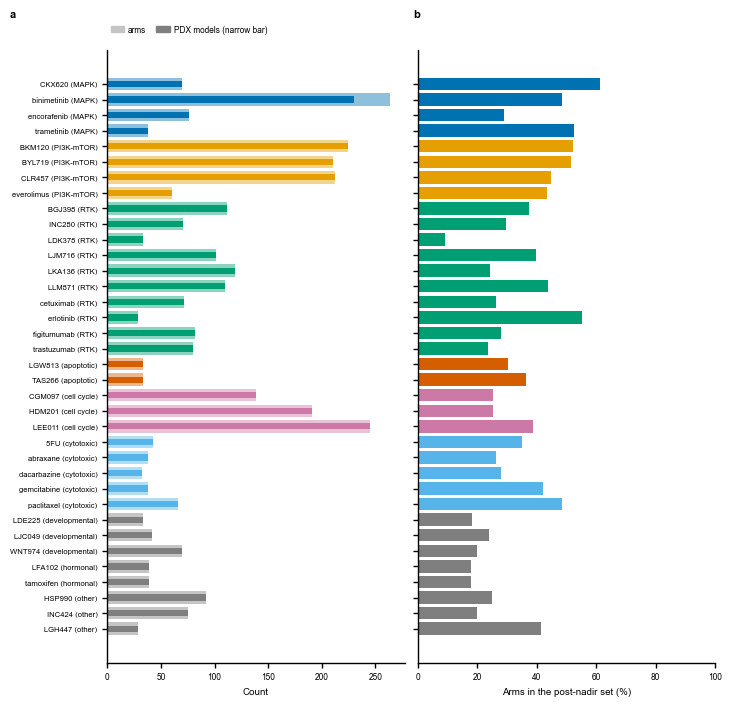

  saved outputs\figures\atlas\11_compound_atlas.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


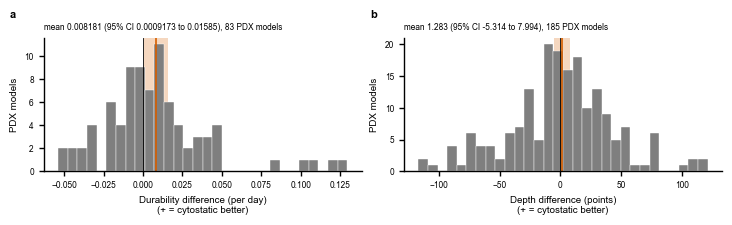

  saved outputs\figures\atlas\11_model_level_effects.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


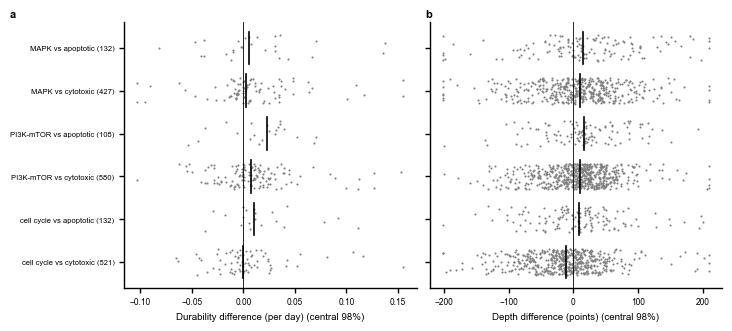

  saved outputs\figures\atlas\11_pairs_by_family_pair.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


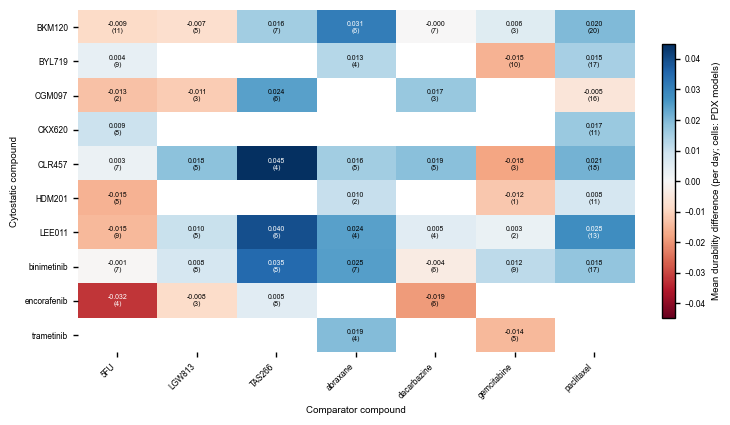

  saved outputs\figures\atlas\11_compound_pair_matrix.{pdf,png}  (180 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


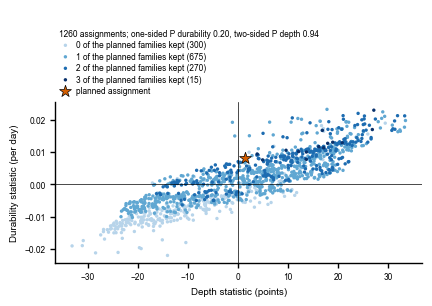

  saved outputs\figures\atlas\11_exact_null_scatter.{pdf,png}  (105 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


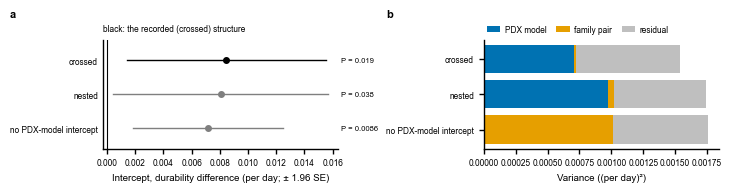

  saved outputs\figures\atlas\11_mixed_models.{pdf,png}  (181 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


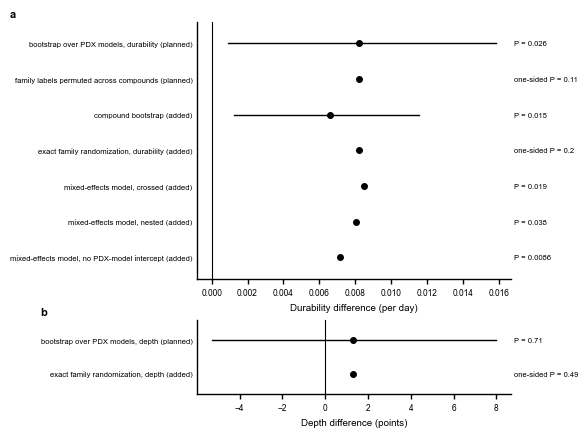

  saved outputs\figures\atlas\11_results_forest.{pdf,png}  (144 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [21]:
# ==========================================================================
# 3.9 Atlas: mechanism class (analysis Section 11)
# ==========================================================================

def family_colors(families):
    """{family: color} for the compound families, palette hues in sorted order."""
    return category_colors(families)


def atlas_compound_atlas():
    # Every single-agent compound with a family in the plan: a  arms and PDX
    # models; b  share of arms in the post-nadir set (the arms that carry
    # durability). Rows grouped by family.
    compounds = FROZEN["compound_families"].sort_values(["family", "compound"]).reset_index(drop=True)
    colors = family_colors(compounds.family.unique())
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(60, 4 * len(compounds) + 30) * MM),
                                      layout="constrained", sharey=True)
    positions = np.arange(len(compounds))
    axes["a"].barh(positions, compounds.arms, color=[tint(colors[f], 0.45) for f in compounds.family], label="arms")
    axes["a"].barh(positions, compounds.pdx_models, height=0.4, color=[colors[f] for f in compounds.family],
                   label="PDX models")
    axes["a"].set_yticks(positions, [f"{row.compound} ({row.family})" for row in compounds.itertuples()], fontsize=5.5)
    axes["a"].invert_yaxis()
    axes["a"].set_xlabel("Count")
    legend_above(axes["a"], ncols=2, handles=[Patch(color=tint(COLORS["reference"], 0.45), label="arms"),
                                              Patch(color=COLORS["reference"], label="PDX models (narrow bar)")])
    share = compounds.durability_values / compounds.arms
    axes["b"].barh(positions, 100 * share, color=[colors[f] for f in compounds.family])
    axes["b"].set_xlabel("Arms in the post-nadir set (%)")
    axes["b"].set_xlim(0, 100)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "11_compound_atlas")


def atlas_model_level_effects():
    # Mean cytostatic-minus-comparator difference of each PDX model (the unit
    # of the planned bootstrap): a  durability (pairs with durability on both
    # members); b  depth (all contrast pairs); with the planned estimate and
    # its 95% interval.
    pairs = FROZEN["mechanism_class_contrast_pairs"]
    results = FROZEN["mechanism_class_results"].set_index("analysis")
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=55)
    for axis, column, analysis, label in (
            (axes[0], "durability", "bootstrap over PDX models, durability (planned)", "Durability difference (per day)"),
            (axes[1], "depth", "bootstrap over PDX models, depth (planned)", "Depth difference (points)")):
        model_means = pairs.dropna(subset=[column]).groupby("model_id")[column].mean()
        row = results.loc[analysis]
        axis.hist(model_means.clip(*percentile_limits(model_means, 1, 99)), bins=30, color=COLORS["reference"],
                  edgecolor="white", linewidth=0.3)
        axis.axvline(0, color=COLORS["ink"], linewidth=0.6)
        axis.axvline(row.estimate, color=COLORS["fourth"], linewidth=1.2)
        axis.axvspan(row.low, row.high, color=tint(COLORS["fourth"], 0.25), linewidth=0, zorder=0)
        assert np.isclose(model_means.mean(), row.estimate)
        axis.set_xlabel(label + "\n(+ = cytostatic better)")
        axis.set_ylabel("PDX models")
        axis.set_title(f"mean {row.estimate:.4g} (95% CI {row.low:.4g} to {row.high:.4g}), "
                       f"{len(model_means)} PDX models", loc="left", fontsize=6)
    label_panels(axes)
    save_atlas(figure, "11_model_level_effects")


def atlas_pairs_by_family_pair():
    # Every cytostatic–comparator pair (within a PDX model), by family pair:
    # a  durability difference; b  depth difference (positive: the cytostatic
    # compound regrew more slowly, or went deeper).
    pairs = FROZEN["mechanism_class_contrast_pairs"].assign(
        family_pair=lambda f: f.cytostatic_family + " vs " + f.comparator_family)
    order = sorted(pairs.family_pair.unique())
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(60, 8 * len(order) + 30) * MM),
                                      layout="constrained", sharey=True)
    for key, column, label in (("a", "durability", "Durability difference (per day)"), ("b", "depth", "Depth difference (points)")):
        values = pairs.dropna(subset=[column])
        limits = percentile_limits(values[column], 1, 99)
        strip_plot(axes[key], {name: values.loc[values.family_pair == name, column].clip(*limits) for name in order},
                   size=1.5, vertical=False, rasterized=True)
        axes[key].axvline(0, color=COLORS["ink"], linewidth=0.6)
        axes[key].set_xlabel(label + " (central 98%)")
    axes["a"].tick_params(axis="y", labelsize=5.5)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "11_pairs_by_family_pair")


def atlas_compound_pair_matrix():
    # Mean durability difference of each cytostatic compound (rows) against
    # each comparator compound (columns), over the PDX models with both, with
    # the number of PDX models; diverging scale centred on zero.
    pairs = FROZEN["mechanism_class_contrast_pairs"].dropna(subset=["durability"])
    # Mean over all pairs of the two compounds (pairs from one PDX model are
    # one value each, as saved in the contrast pairs of 11.1).
    means = pairs.pivot_table(index="cytostatic_compound", columns="comparator_compound", values="durability", aggfunc="mean")
    counts = pairs.pivot_table(index="cytostatic_compound", columns="comparator_compound", values="model_id", aggfunc="nunique")
    limit = max(float(np.nanmax(np.abs(means.to_numpy(float)))), 1e-9)
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"], max(55, 7 * len(means) + 35) * MM), layout="constrained")
    image = axis.imshow(means.to_numpy(float), cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    for i in range(means.shape[0]):
        for j in range(means.shape[1]):
            if np.isfinite(means.iat[i, j]):
                axis.text(j, i, f"{means.iat[i, j]:.3f}\n({int(counts.iat[i, j])})", ha="center", va="center", fontsize=5,
                          color="white" if abs(means.iat[i, j]) > 0.6 * limit else COLORS["ink"])
    axis.set_xticks(range(means.shape[1]), means.columns, rotation=45, ha="right", fontsize=6)
    axis.set_yticks(range(means.shape[0]), means.index, fontsize=6)
    axis.set_xlabel("Comparator compound")
    axis.set_ylabel("Cytostatic compound")
    for spine in axis.spines.values():
        spine.set_visible(False)
    figure.colorbar(image, ax=axis, shrink=0.8).set_label("Mean durability difference (per day; cells: PDX models)")
    save_atlas(figure, "11_compound_pair_matrix")


def atlas_exact_null_scatter():
    # Every assignment of three families against two in the exact test
    # (11.3b): durability statistic against depth statistic, shade by how many
    # planned cytostatic families the first group keeps; star: the planned
    # assignment.
    splits = FROZEN["mechanism_class_exact_splits"]
    planned = splits.loc[splits.is_planned.astype(bool)].iloc[0]
    kept = sorted(splits.cytostatic_families_kept.unique())
    shades = dict(zip(kept, mpl.colormaps["Blues"](np.linspace(0.3, 1.0, len(kept)))))
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"] * 1.2, 75 * MM), layout="constrained")
    for value in kept:
        part = splits.loc[splits.cytostatic_families_kept == value]
        axis.scatter(part.depth, part.durability, s=6, color=shades[value], edgecolor="none",
                     label=f"{value} of the planned families kept ({len(part)})")
    axis.scatter(planned.depth, planned.durability, s=80, marker="*", color=COLORS["fourth"], edgecolor=COLORS["ink"],
                 linewidth=0.5, zorder=4, label="planned assignment")
    axis.axhline(0, color=COLORS["ink"], linewidth=0.5)
    axis.axvline(0, color=COLORS["ink"], linewidth=0.5)
    axis.set_xlabel("Depth statistic (points)")
    axis.set_ylabel("Durability statistic (per day)")
    legend_above(axis, title=f"{len(splits)} assignments; one-sided P durability "
                             f"{RESULTS['exact_p_durability_one_sided']:.2f}, two-sided P depth "
                             f"{RESULTS['exact_p_depth_two_sided']:.2f}")
    save_atlas(figure, "11_exact_null_scatter")


def atlas_mixed_models():
    # The three random-effect structures of 11.3c: a  intercept (the
    # cytostatic-minus-comparator durability difference) ± 1.96 SE, with P;
    # b  variance components.
    models = TABLES["mechanism_class_mixed_models"]
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=50)
    forest_rows(axes[0], list(models.structure), models.intercept, models.intercept - 1.96 * models.se,
                models.intercept + 1.96 * models.se, reference=0,
                colors=[COLORS["ink"] if s == "crossed" else COLORS["reference"] for s in models.structure])
    for y, row in enumerate(models.itertuples()):
        axes[0].text(1.01, y, f"P = {figure_p(row.p_value)}", transform=axes[0].get_yaxis_transform(), va="center",
                     fontsize=5.5)
    axes[0].set_xlabel("Intercept, durability difference (per day; ± 1.96 SE)")
    axes[0].set_title("black: the recorded (crossed) structure", loc="left", fontsize=6)
    components = models[["pdx_model_variance", "family_pair_variance", "residual_variance"]].fillna(0)
    left = np.zeros(len(models))
    component_labels = {"pdx_model_variance": "PDX model", "family_pair_variance": "family pair",
                        "residual_variance": "residual"}
    for column, color in zip(components.columns, (COLORS["trajectory"], COLORS["depth"], COLORS["light"])):
        axes[1].barh(range(len(models)), components[column], left=left, color=color, label=component_labels[column])
        left += components[column].to_numpy()
    axes[1].set_yticks(range(len(models)), models.structure)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Variance ((per day)²)")
    legend_above(axes[1], ncols=3)
    label_panels(axes)
    save_atlas(figure, "11_mixed_models")


def atlas_results_forest():
    # Every analysis of mechanism_class_results: a  analyses on the durability
    # scale (per day), b  on the depth scale (points), with the 95% interval
    # where one exists and the P value (one-sided where the analysis reports one).
    results = FROZEN["mechanism_class_results"]
    # The analyses on the depth scale are those named for depth; every other
    # statistic (including the permutation and mixed-model ones) is a
    # durability difference per day.
    depth_rows = results.analysis.str.contains("depth")
    figure, axes = plt.subplot_mosaic([["a"], ["b"]], figsize=(FIGURE_WIDTH["double"] * 0.8, 105 * MM), layout="constrained",
                                      height_ratios=[(~depth_rows).sum(), max(depth_rows.sum(), 1)])
    for key, part, label in (("a", results.loc[~depth_rows], "Durability difference (per day)"),
                             ("b", results.loc[depth_rows], "Depth difference (points)")):
        forest_rows(axes[key], list(part.analysis), part.estimate, part.low.fillna(np.nan), part.high.fillna(np.nan),
                    reference=0)
        for y, row in enumerate(part.itertuples()):
            p_value = row.p_one_sided if pd.notna(row.p_one_sided) else row.p_two_sided
            side = "one-sided " if pd.notna(row.p_one_sided) else ""
            # A resampling P value of 0 means no replicate reached the observed
            # value: it is below the resolution of the resampling, not < 10⁻³⁰⁰.
            p_text = (f"{side}P below resampling resolution" if p_value == 0 else f"{side}P = {figure_p(p_value)}")
            axes[key].text(1.01, y, p_text, transform=axes[key].get_yaxis_transform(), va="center", fontsize=5.5)
        axes[key].tick_params(axis="y", labelsize=5.5)
        axes[key].set_xlabel(label)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "11_results_forest")


if DRAW_ATLAS:
    draw("11_compound_atlas", atlas_compound_atlas, requires=("compound_families",))
    draw("11_model_level_effects", atlas_model_level_effects, requires=("mechanism_class_contrast_pairs",
                                                                        "mechanism_class_results"))
    draw("11_pairs_by_family_pair", atlas_pairs_by_family_pair, requires=("mechanism_class_contrast_pairs",))
    draw("11_compound_pair_matrix", atlas_compound_pair_matrix, requires=("mechanism_class_contrast_pairs",))
    draw("11_exact_null_scatter", atlas_exact_null_scatter, requires=("mechanism_class_exact_splits",))
    draw("11_mixed_models", atlas_mixed_models, requires=("mechanism_class_mixed_models",))
    draw("11_results_forest", atlas_results_forest, requires=("mechanism_class_results",))

### 3.10 Drug exposure and observation span (analysis Section 12)

| File | Content |
|---|---|
| `12_separation_by_window` | Structural separation (median, 10th–90th percentile) against window, by half-life and termination rule |
| `12_separation_growth` | Fold change in separation from 14 and 28 to 84 days and the log–log exponent, with 95% intervals |
| `12_verdicts_by_noise` | Decisive rate and accuracy against window at each noise level |
| `12_paired_simulations` | The paired 28-day simulations: separation by generating model, verdicts against noise |
| `12_thinning` | Thinning the 84-day schedules: separation, decisive rate and accuracy against the share of measurements kept |
| `12_residual_example` | The worked example: noise-free tolerant arm and the incorrect model's residual over 28 and 84 days |

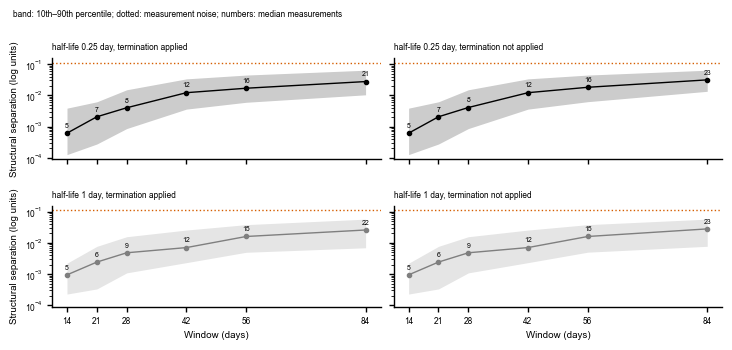

  saved outputs\figures\atlas\12_separation_by_window.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


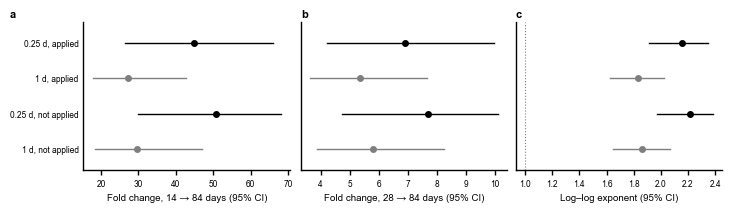

  saved outputs\figures\atlas\12_separation_growth.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


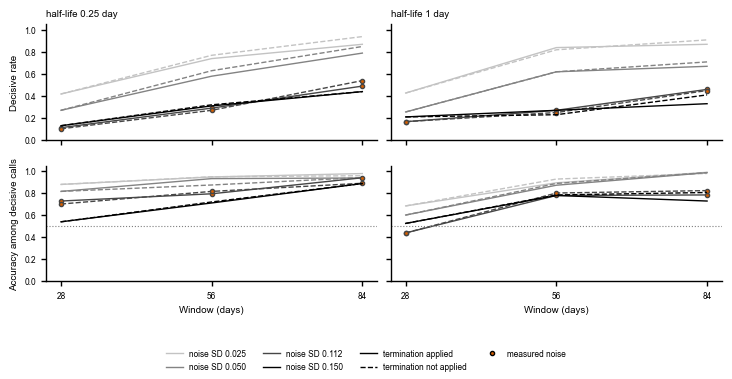

  saved outputs\figures\atlas\12_verdicts_by_noise.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


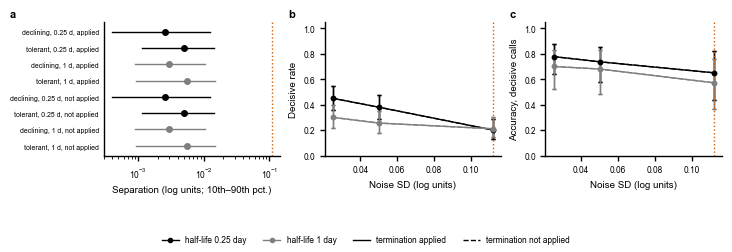

  saved outputs\figures\atlas\12_paired_simulations.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


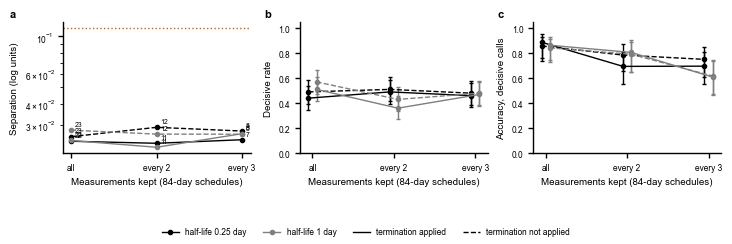

  saved outputs\figures\atlas\12_thinning.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


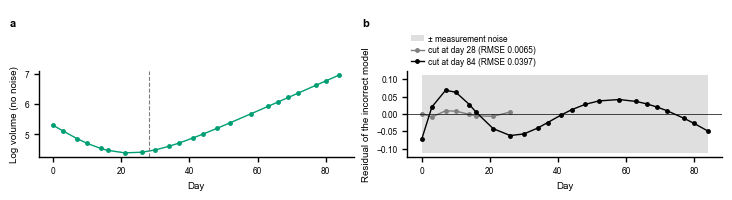

  saved outputs\figures\atlas\12_residual_example.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [22]:
# ==========================================================================
# 3.10 Atlas: drug exposure and observation span (analysis Section 12)
# ==========================================================================

HALF_LIFE_COLORS = {0.25: COLORS["ink"], 1.0: COLORS["reference"]}
RULE_STYLES = {"applied": "-", "not applied": "--"}


def exposure_key_handles():
    """Legend entries shared by the exposure panels."""
    return ([Line2D([], [], color=color, marker="o", markersize=3, label=f"half-life {half_life:g} day")
             for half_life, color in HALF_LIFE_COLORS.items()]
            + [Line2D([], [], color=COLORS["ink"], linestyle=style, label=f"termination {rule}")
               for rule, style in RULE_STYLES.items()])


def atlas_separation_by_window():
    # Structural separation (RMSE of the incorrect model on noise-free arms)
    # by window: median with its 10th–90th percentile band, one panel per
    # half-life × termination rule; dotted: measurement noise; numbers: median
    # measurements per arm.
    separation = FROZEN["exposure_separation_by_window"]
    combos = [(h, r) for h in EXPOSURE_HALF_LIVES for r in TERMINATION_RULES]
    figure, axes = atlas_figure(len(combos), ncols=2, panel_height_mm=45, sharex=True, sharey=True)
    for axis, (half_life, rule) in zip(axes, combos):
        rows = separation.loc[(separation.half_life_days == half_life) & (separation.termination == rule)].sort_values("window_days")
        axis.fill_between(rows.window_days, rows.p10, rows.p90, color=tint(HALF_LIFE_COLORS[half_life], 0.2), linewidth=0)
        axis.plot(rows.window_days, rows.median_separation, "-o", color=HALF_LIFE_COLORS[half_life], markersize=3)
        for row in rows.itertuples():
            axis.annotate(f"{row.median_measurements:.0f}", (row.window_days, row.median_separation), xytext=(0, 4),
                          textcoords="offset points", ha="center", fontsize=5)
        axis.axhline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.0)
        axis.set_yscale("log")
        axis.set_title(f"half-life {half_life:g} day, termination {rule}", loc="left", fontsize=6)
    for axis in axes[-2:]:
        axis.set_xlabel("Window (days)")
        axis.set_xticks(sorted(separation.window_days.unique()))
    for axis in axes[::2]:
        axis.set_ylabel("Structural separation (log units)")
    figure.suptitle("band: 10th–90th percentile; dotted: measurement noise; numbers: median measurements", x=0.01,
                    ha="left", fontsize=6)
    save_atlas(figure, "12_separation_by_window")


def atlas_separation_growth():
    # How fast separation grows with span (12.2): a  fold change 14 → 84 and
    # b  28 → 84 days, c  exponent of the log–log fit of separation on window,
    # each with its 95% interval, by half-life and termination rule.
    growth = FROZEN["exposure_separation_growth"]
    labels = [f"{row.half_life_days:g} d, {row.termination}" for row in growth.itertuples()]
    colors = [HALF_LIFE_COLORS.get(row.half_life_days, COLORS["reference"]) for row in growth.itertuples()]
    figure, axes = plt.subplot_mosaic([["a", "b", "c"]], figsize=(FIGURE_WIDTH["double"], 48 * MM), layout="constrained",
                                      sharey=True)
    for key, column, label in (("a", "fold_14_to_84", "Fold change, 14 → 84 days"),
                               ("b", "fold_28_to_84", "Fold change, 28 → 84 days"),
                               ("c", "log_log_exponent", "Log–log exponent")):
        low = growth[f"{column}_low" if column != "log_log_exponent" else "exponent_low"]
        high = growth[f"{column}_high" if column != "log_log_exponent" else "exponent_high"]
        forest_rows(axes[key], labels, growth[column], low, high, colors=colors)
        axes[key].set_xlabel(label + " (95% CI)")
    axes["c"].axvline(1, color=COLORS["reference"], linestyle=":", linewidth=0.8)
    label_panels([axes[k] for k in "abc"])
    save_atlas(figure, "12_separation_growth")


def atlas_verdicts_by_noise():
    # AIC verdicts on the fixed pool (12.3): decisive rate (top) and accuracy
    # among decisive calls (bottom) by window, one column per half-life; line
    # shade by noise level (light: least noise), solid: termination applied,
    # dashed: not applied; red marker: the measured noise.
    verdicts = FROZEN["exposure_verdicts_by_window"]
    # One gray per noise level, light to dark with increasing noise (an
    # ordered quantity, so a single-hue ramp).
    noise_levels = sorted(verdicts.noise_sd.unique())
    shades = dict(zip(noise_levels, mpl.colormaps["Greys"](np.linspace(0.35, 1.0, len(noise_levels)))))
    figure, axes = plt.subplots(2, len(EXPOSURE_HALF_LIVES), figsize=(FIGURE_WIDTH["double"], 95 * MM),
                                layout="constrained", sharex=True, sharey=True, squeeze=False)
    figure.get_layout_engine().set(h_pad=0.1)
    for column, half_life in enumerate(EXPOSURE_HALF_LIVES):
        for noise in noise_levels:
            measured = np.isclose(noise, MEASUREMENT_NOISE)
            for rule, style in RULE_STYLES.items():
                rows = verdicts.loc[(verdicts.half_life_days == half_life) & np.isclose(verdicts.noise_sd, noise)
                                    & (verdicts.termination == rule)].sort_values("window_days")
                for row_index, value in enumerate(("decisive_rate", "accuracy_when_decisive")):
                    axes[row_index, column].plot(rows.window_days, rows[value], style, color=shades[noise],
                                                 marker="o" if measured else None, markersize=3,
                                                 markerfacecolor=COLORS["fourth"] if measured else None, linewidth=1.0)
        axes[0, column].set_title(f"half-life {half_life:g} day", loc="left")
        axes[1, column].set_xlabel("Window (days)")
        axes[1, column].axhline(0.5, color=COLORS["reference"], linestyle=":", linewidth=0.8)
    axes[0, 0].set_ylabel("Decisive rate")
    axes[1, 0].set_ylabel("Accuracy among decisive calls")
    axes[1, 0].set_xticks(list(CONFIRM_WINDOWS))
    axes[0, 0].set_ylim(0, 1.05)
    figure.legend(handles=[Line2D([], [], color=shades[n], label=f"noise SD {n:.3f}") for n in noise_levels]
                  + [Line2D([], [], color=COLORS["ink"], linestyle=style, label=f"termination {rule}")
                     for rule, style in RULE_STYLES.items()]
                  + [Line2D([], [], marker="o", linestyle="", markerfacecolor=COLORS["fourth"],
                            markeredgecolor=COLORS["ink"], markersize=3, label="measured noise")],
                  loc="outside lower center", ncols=4, frameon=False)
    save_atlas(figure, "12_verdicts_by_noise")


def atlas_paired_simulations():
    # The paired simulations at the study window (12.1): a  separation of the
    # incorrect model by generating model (median, 10th–90th percentile);
    # b  decisive rate and c  accuracy among decisive calls against noise.
    separation, verdicts = FROZEN["exposure_paired_separation"], FROZEN["exposure_paired_verdicts"]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=60)
    labels, estimates, lows, highs, colors = [], [], [], [], []
    for row in separation.itertuples():
        labels.append(f"{row.true_mechanism.split()[0]}, {row.half_life_days:g} d, {row.termination}")
        estimates.append(row.median_separation)
        lows.append(row.p10)
        highs.append(row.p90)
        colors.append(HALF_LIFE_COLORS.get(row.half_life_days, COLORS["reference"]))
    forest_rows(axes[0], labels, estimates, lows, highs, colors=colors)
    axes[0].axvline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.0)
    axes[0].set_xscale("log")
    axes[0].tick_params(axis="y", labelsize=5)
    axes[0].set_xlabel("Separation (log units; 10th–90th pct.)")
    for axis, value, low, high, label in ((axes[1], "decisive_rate", "decisive_low", "decisive_high", "Decisive rate"),
                                          (axes[2], "accuracy_when_decisive", "accuracy_low", "accuracy_high",
                                           "Accuracy, decisive calls")):
        for (half_life, rule), rows in verdicts.groupby(["half_life_days", "termination"]):
            rows = rows.sort_values("noise_sd")
            axis.errorbar(rows.noise_sd, rows[value], yerr=interval_errors(rows[value], rows[low], rows[high]),
                          fmt=RULE_STYLES[rule] + "o", color=HALF_LIFE_COLORS.get(half_life, COLORS["reference"]),
                          markersize=3, capsize=1.5, linewidth=1.0)
        axis.axvline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.0)
        axis.set_xlabel("Noise SD (log units)")
        axis.set_ylabel(label)
        axis.set_ylim(0, 1.05)
    figure.legend(handles=exposure_key_handles(), loc="outside lower center", ncols=4, frameon=False)
    label_panels(axes)
    save_atlas(figure, "12_paired_simulations")


def atlas_thinning():
    # Thinning the 84-day schedules (12.4) to every second or third
    # measurement: a  structural separation without noise; b  decisive rate
    # and c  accuracy at the measured noise (Wilson 95% intervals), against
    # the measurements kept; numbers: median measurements per arm.
    separation, verdicts = FROZEN["exposure_thinning_separation"], FROZEN["exposure_thinning_verdicts"]
    figure, axes = atlas_figure(3, ncols=3, panel_height_mm=58)
    for (half_life, rule), rows in separation.groupby(["half_life_days", "termination"]):
        rows = rows.sort_values("keep_every")
        axes[0].plot(rows.keep_every, rows.median_separation, RULE_STYLES[rule] + "o", markersize=3,
                     color=HALF_LIFE_COLORS.get(half_life, COLORS["reference"]))
        for row in rows.itertuples():
            axes[0].annotate(f"{row.median_measurements:.0f}", (row.keep_every, row.median_separation), xytext=(3, 3),
                             textcoords="offset points", fontsize=5)
    axes[0].axhline(MEASUREMENT_NOISE, color=COLORS["fourth"], linestyle=":", linewidth=1.0)
    axes[0].set_yscale("log")
    axes[0].set_ylabel("Separation (log units)")
    for axis, value, low, high, label in ((axes[1], "decisive_rate", "decisive_low", "decisive_high", "Decisive rate"),
                                          (axes[2], "accuracy_when_decisive", "accuracy_low", "accuracy_high",
                                           "Accuracy, decisive calls")):
        for (half_life, rule), rows in verdicts.groupby(["half_life_days", "termination"]):
            rows = rows.sort_values("keep_every")
            offset = -0.05 if half_life == EXPOSURE_HALF_LIVES[0] else 0.05
            axis.errorbar(rows.keep_every + offset, rows[value], yerr=interval_errors(rows[value], rows[low], rows[high]),
                          fmt=RULE_STYLES[rule] + "o", color=HALF_LIFE_COLORS.get(half_life, COLORS["reference"]),
                          markersize=3, capsize=1.5, linewidth=1.0)
        axis.set_ylabel(label)
        axis.set_ylim(0, 1.05)
    for axis in axes:
        axis.set_xticks(sorted(separation.keep_every.unique()),
                        [f"every {int(k)}" if k > 1 else "all" for k in sorted(separation.keep_every.unique())])
        axis.set_xlabel(f"Measurements kept ({THINNING_WINDOW_DAYS}-day schedules)")
    figure.legend(handles=exposure_key_handles(), loc="outside lower center", ncols=4, frameon=False)
    label_panels(axes)
    save_atlas(figure, "12_thinning")


def atlas_residual_example():
    # The worked example of 12.4: a  the noise-free tolerant-subpopulation
    # arm (fixed parameters, 0.25-day half-life) on the typical schedule of
    # the fixed pool; b  the residual of the best declining-effect fit when
    # the arm is cut at 28 and at 84 days, against ± the measurement noise.
    example = FROZEN["exposure_residual_example"]
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=52)
    longest = example.loc[example.window_days == example.window_days.max()].sort_values("day")
    axes[0].plot(longest.day, longest.log_volume, "-o", color=COLORS["third"], markersize=2.5)
    axes[0].axvline(28, color=COLORS["reference"], linestyle="--", linewidth=0.8)
    axes[0].set_xlabel("Day")
    axes[0].set_ylabel("Log volume (no noise)")
    axes[1].fill_between([0, example.day.max()], -MEASUREMENT_NOISE, MEASUREMENT_NOISE, color=tint(COLORS["light"], 0.5),
                         linewidth=0, label="± measurement noise")
    for window, color in ((28, COLORS["reference"]), (int(example.window_days.max()), COLORS["ink"])):
        rows = example.loc[example.window_days == window].sort_values("day")
        axes[1].plot(rows.day, rows.residual, "-o", color=color, markersize=2.5,
                     label=f"cut at day {window} (RMSE {rows.rmse_incorrect_model.iloc[0]:.4f})")
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.5)
    axes[1].set_xlabel("Day")
    axes[1].set_ylabel("Residual of the incorrect model")
    legend_above(axes[1])
    label_panels(axes)
    save_atlas(figure, "12_residual_example")


if DRAW_ATLAS:
    draw("12_separation_by_window", atlas_separation_by_window, requires=("exposure_separation_by_window",))
    draw("12_separation_growth", atlas_separation_growth, requires=("exposure_separation_growth",))
    draw("12_verdicts_by_noise", atlas_verdicts_by_noise, requires=("exposure_verdicts_by_window",))
    draw("12_paired_simulations", atlas_paired_simulations, requires=("exposure_paired_separation",
                                                                      "exposure_paired_verdicts"))
    draw("12_thinning", atlas_thinning, requires=("exposure_thinning_separation", "exposure_thinning_verdicts"))
    draw("12_residual_example", atlas_residual_example, requires=("exposure_residual_example",))

### 3.11 External cohorts (analysis Section 13)

| File | Content |
|---|---|
| `13_pdxnet_animals` | PDXNet per-animal fits: growth rate by span and by number of points, residual SD against the measurement noise, slope standard error |
| `13_pdxnet_groups` | Between-animal SD of each group before and after removing slope error, against the source study's between-model SD |
| `13_external_noise_all` | Every measurement-error estimate, by cohort, arm type and set of triples |

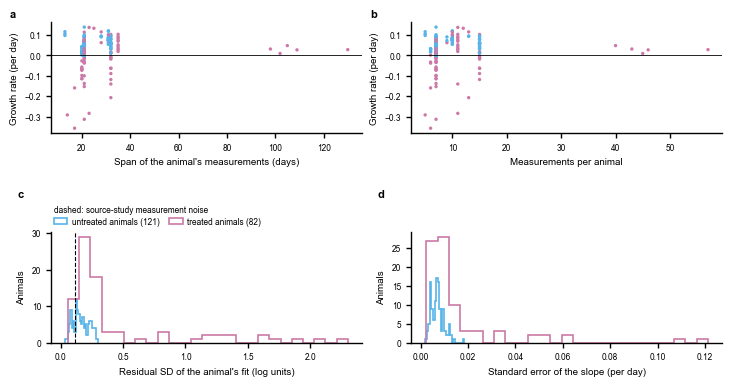

  saved outputs\figures\atlas\13_pdxnet_animals.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


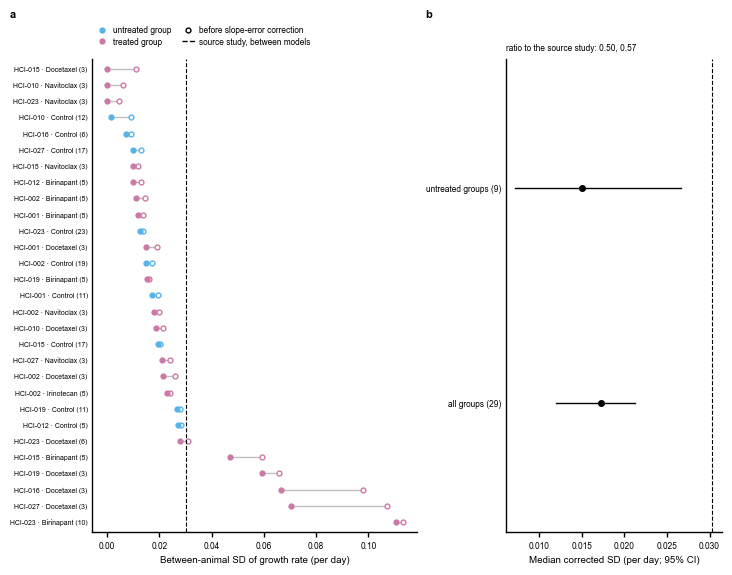

  saved outputs\figures\atlas\13_pdxnet_groups.{pdf,png}  (181 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


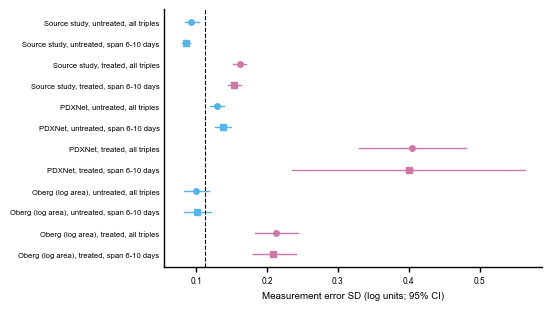

  saved outputs\figures\atlas\13_external_noise_all.{pdf,png}  (135 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


In [23]:
# ==========================================================================
# 3.11 Atlas: external cohorts (analysis Section 13)
# ==========================================================================

ARM_TYPE_COLORS = {"untreated": COLORS["sixth"], "treated": COLORS["fifth"]}


def atlas_pdxnet_animals():
    # One line fit per PDXNet animal (13.1): a  growth rate against the span
    # of its measurements; b  against the number of measurements; c  residual
    # SD of the fit (dashed: the source study's measurement noise); d  standard
    # error of the slope.
    animals = FROZEN["pdxnet_animal_growth_rates"].assign(is_control=lambda f: f.is_control.astype(bool))
    colors = np.where(animals.is_control, ARM_TYPE_COLORS["untreated"], ARM_TYPE_COLORS["treated"])
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=48)
    axes[0].scatter(animals.span_days, animals.growth_rate, s=6, c=list(colors), edgecolor="none")
    axes[0].set_xlabel("Span of the animal's measurements (days)")
    axes[1].scatter(animals.n_points, animals.growth_rate, s=6, c=list(colors), edgecolor="none")
    axes[1].set_xlabel("Measurements per animal")
    for axis in axes[:2]:
        axis.axhline(0, color=COLORS["ink"], linewidth=0.6)
        axis.set_ylabel("Growth rate (per day)")
    for population, mask in (("untreated", animals.is_control), ("treated", ~animals.is_control)):
        axes[2].hist(animals.loc[mask, "residual_sd"].dropna(), bins=25, histtype="step", color=ARM_TYPE_COLORS[population],
                     linewidth=1.2, label=f"{population} animals ({int(mask.sum())})")
        axes[3].hist(animals.loc[mask, "slope_se"].dropna(), bins=25, histtype="step", color=ARM_TYPE_COLORS[population],
                     linewidth=1.2)
    axes[2].axvline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes[2].set_xlabel("Residual SD of the animal's fit (log units)")
    axes[3].set_xlabel("Standard error of the slope (per day)")
    for axis in axes[2:]:
        axis.set_ylabel("Animals")
    legend_above(axes[2], ncols=2, title="dashed: source-study measurement noise")
    label_panels(axes)
    save_atlas(figure, "13_pdxnet_animals")


def atlas_pdxnet_groups():
    # Groups of animals of one PDX model and arm (13.1): a  between-animal SD
    # of the growth rate before (open) and after (filled) removing the slope
    # error of each animal, groups ordered by the corrected SD, with the source
    # study's between-model SD (dashed); b  the median corrected SD with its
    # 95% interval for untreated and all groups.
    groups = FROZEN["pdxnet_between_animal_groups"].assign(is_control=lambda f: f.is_control.astype(bool))
    # The corrected SD removes each animal's own slope variance from the
    # spread of growth rates (13.1).
    groups = groups.sort_values("sd_corrected").reset_index(drop=True)
    summary = TABLES.get("external_between_animal")
    figure, axes = plt.subplot_mosaic([["a", "b"]], figsize=(FIGURE_WIDTH["double"], max(60, 4 * len(groups) + 25) * MM),
                                      layout="constrained", width_ratios=[1.5, 1.0])
    for y, row in groups.iterrows():
        color = ARM_TYPE_COLORS["untreated" if row.is_control else "treated"]
        axes["a"].plot([row.sd_raw, row.sd_corrected], [y, y], color=COLORS["light"], linewidth=1.0)
        axes["a"].plot(row.sd_raw, y, "o", markerfacecolor="white", markeredgecolor=color, markersize=3.5)
        axes["a"].plot(row.sd_corrected, y, "o", color=color, markersize=3.5)
    axes["a"].axvline(RESULTS["pdxe_between_model_sd"], color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axes["a"].set_yticks(range(len(groups)), [f"{row.model_id} · {row.arm} ({row.animals})" for row in groups.itertuples()],
                         fontsize=5)
    axes["a"].set_ylim(len(groups) - 0.4, -0.6)
    axes["a"].tick_params(axis="y", length=0)
    axes["a"].set_xlabel("Between-animal SD of growth rate (per day)")
    legend_above(axes["a"], ncols=2, handles=[
        Line2D([], [], marker="o", linestyle="", color=ARM_TYPE_COLORS["untreated"], markersize=3.5, label="untreated group"),
        Line2D([], [], marker="o", linestyle="", color=ARM_TYPE_COLORS["treated"], markersize=3.5, label="treated group"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=COLORS["ink"], markersize=3.5,
               label="before slope-error correction"),
        Line2D([], [], color=COLORS["ink"], linestyle="--", label="source study, between models")])
    if summary is not None and len(summary):
        forest_rows(axes["b"], [f"{row.groups} ({row.n_groups})" for row in summary.itertuples()],
                    summary.median_sd_corrected, summary.low, summary.high)
        axes["b"].axvline(RESULTS["pdxe_between_model_sd"], color=COLORS["ink"], linestyle="--", linewidth=0.8)
        axes["b"].set_xlabel("Median corrected SD (per day; 95% CI)")
        axes["b"].set_title("ratio to the source study: " + ", ".join(f"{row.ratio_to_pdxe_between_model:.2f}"
                                                                      for row in summary.itertuples()), loc="left", fontsize=6)
    label_panels([axes["a"], axes["b"]])
    save_atlas(figure, "13_pdxnet_groups")


def atlas_external_noise_all():
    # Every measurement-error estimate of 13.3 (interpolation of the middle of
    # three consecutive measurements), by cohort and arm type, for all triples
    # (circles) and the span-matched triples (squares), with 95% intervals;
    # dashed: the source study's residual-SD noise.
    noise = FROZEN["external_noise"]
    labels = [f"{row.cohort}, {row.arm_type}, {row.triples}" for row in noise.itertuples()]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"] * 0.75, (4.5 * len(noise) + 22) * MM), layout="constrained")
    forest_rows(axis, labels, noise.sigma, noise.low, noise.high,
                colors=[ARM_TYPE_COLORS.get(row.arm_type, COLORS["reference"]) for row in noise.itertuples()],
                markers=["o" if row.triples == "all triples" else "s" for row in noise.itertuples()])
    axis.axvline(MEASUREMENT_NOISE, color=COLORS["ink"], linestyle="--", linewidth=0.8)
    axis.set_xlabel("Measurement error SD (log units; 95% CI)")
    axis.tick_params(axis="y", labelsize=5.5)
    save_atlas(figure, "13_external_noise_all")


if DRAW_ATLAS:
    draw("13_pdxnet_animals", atlas_pdxnet_animals, requires=("pdxnet_animal_growth_rates",))
    draw("13_pdxnet_groups", atlas_pdxnet_groups, requires=("pdxnet_between_animal_groups",))
    draw("13_external_noise_all", atlas_external_noise_all, requires=("external_noise",))

### 3.12 Trajectory shape and progression in patients (analysis Section 14; restricted data)

These figures are drawn only when the patient-level files of the analysis run are present on this computer. Every panel shows a summary over patients (counts, distributions, Kaplan–Meier curves, model coefficients); no patient-level value is written to any file.

| File | Content |
|---|---|
| `14_clinical_attrition` | Patients at each step from randomization to the landmark cohort and its events, by trial |
| `14_clinical_panels` | Assessments per patient, spacing of assessments, baseline diameter sum, patients with a new lesion |
| `14_clinical_predictors` | Depth at the landmark, final-interval slope, share already rising, baseline diameter sum, by trial |
| `14_clinical_kaplan_meier` | Progression-free share from the landmark by depth tertile and by the rising indicator, by trial |
| `14_clinical_coefficients` | Cox coefficients (log hazard per SD) of the depth and trajectory models in each fit |
| `14_clinical_concordance` | Concordance of the two models in every analysis, and the difference against the number of events |

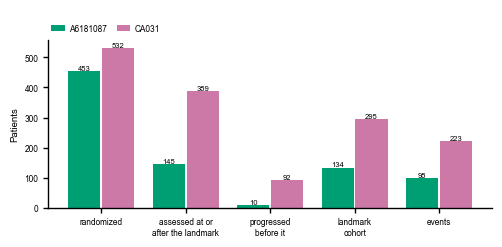

  saved outputs\figures\atlas\14_clinical_attrition.{pdf,png}  (122 mm wide; smallest text 5.5 pt, 5.5 pt at 180 mm)


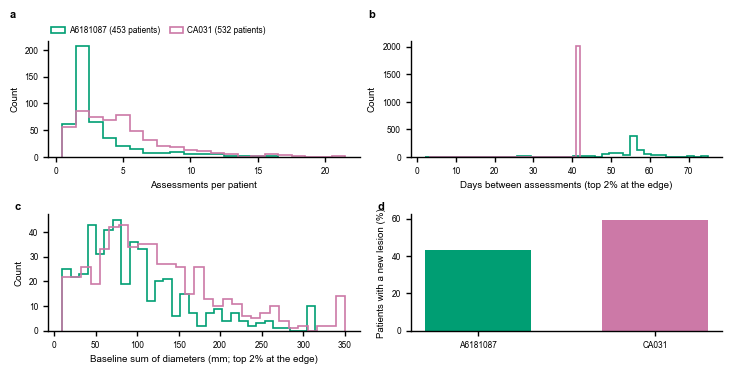

  saved outputs\figures\atlas\14_clinical_panels.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


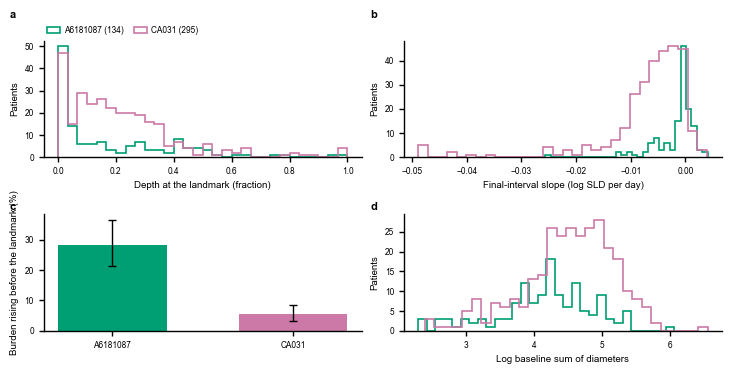

  saved outputs\figures\atlas\14_clinical_predictors.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


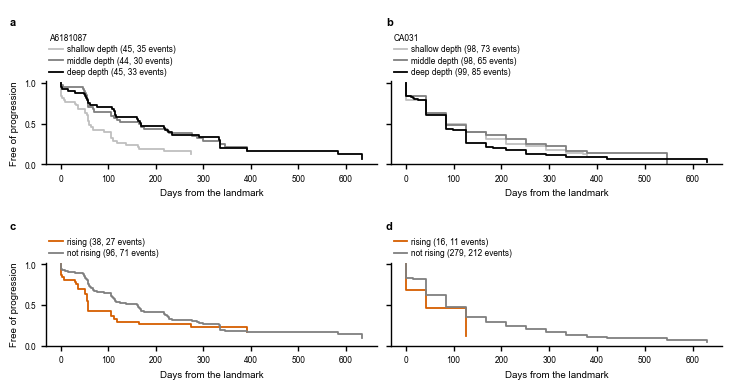

  saved outputs\figures\atlas\14_clinical_kaplan_meier.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


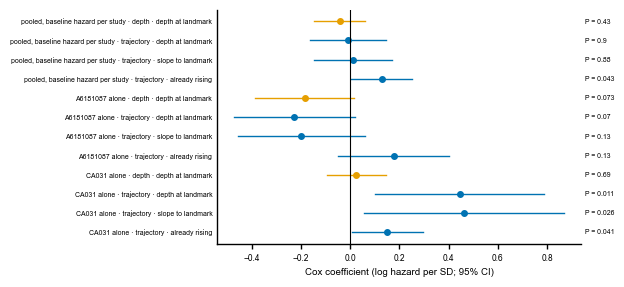

  saved outputs\figures\atlas\14_clinical_coefficients.{pdf,png}  (153 mm wide; smallest text 5.0 pt, 5.0 pt at 180 mm)


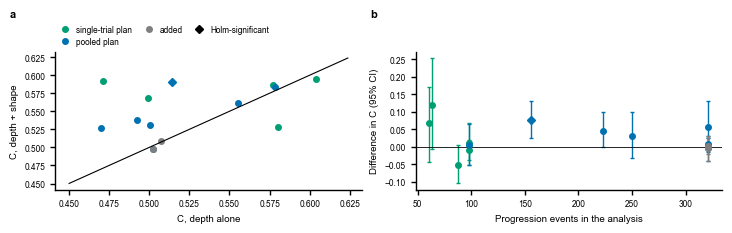

  saved outputs\figures\atlas\14_clinical_concordance.{pdf,png}  (181 mm wide; smallest text 6.0 pt, 6.0 pt at 180 mm)


In [24]:
# ==========================================================================
# 3.12 Atlas: trajectory shape and progression in patients (analysis
#      Section 14; restricted data, summaries only)
# ==========================================================================

TRIAL_COLORS = {"A6181087": COLORS["third"], "CA031": COLORS["fifth"]}


def clinical_cohort_frame():
    """Every scored patient and the landmark cohort, by the rule of 14.2."""
    scored = FROZEN["clinical_patients"]
    in_cohort = (scored.reached_landmark.astype(bool) & ~scored.progressed_before_landmark.astype(bool)
                 & scored.has_features.astype(bool))
    cohort = scored.loc[in_cohort].reset_index(drop=True)
    cohort["event"] = cohort.event.astype(bool)
    return scored, cohort


def atlas_clinical_attrition():
    # Patients randomized to the comparator arm, assessed at or after the
    # landmark, progressed before it, in the landmark cohort, and the
    # progression events in the cohort, by trial.
    scored, cohort = clinical_cohort_frame()
    steps = ["randomized", "assessed at or\nafter the landmark", "progressed\nbefore it", "landmark\ncohort", "events"]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["single"] * 1.4, 60 * MM), layout="constrained")
    for offset, study in ((-0.2, "A6181087"), (0.2, "CA031")):
        part, cohort_part = scored.loc[scored.study == study], cohort.loc[cohort.study == study]
        reached = part.loc[part.reached_landmark.astype(bool)]
        counts = [len(part), len(reached), int(reached.progressed_before_landmark.astype(bool).sum()), len(cohort_part),
                  int(cohort_part.event.sum())]
        axis.bar(np.arange(len(steps)) + offset, counts, 0.38, color=TRIAL_COLORS[study], label=study)
        for x, count in zip(np.arange(len(steps)) + offset, counts):
            axis.text(x, count, f"{count}", ha="center", va="bottom", fontsize=5.5)
    axis.set_xticks(range(len(steps)), steps, fontsize=6)
    axis.set_ylabel("Patients")
    legend_above(axis, ncols=2)
    save_atlas(figure, "14_clinical_attrition")


def atlas_clinical_panels():
    # The tumor-burden panels (14.1): a  assessments per patient; b  days
    # between consecutive assessments; c  baseline sum of diameters;
    # d  patients with a new lesion.
    panel = FROZEN["clinical_panel_restricted"].sort_values(["study", "patient", "day"])
    summary = FROZEN.get("clinical_panels")
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=48)
    for study, part in panel.groupby("study"):
        color = TRIAL_COLORS.get(study, COLORS["reference"])
        per_patient = part.groupby("patient").size()
        axes[0].hist(per_patient, bins=np.arange(0.5, per_patient.max() + 1.5), histtype="step", color=color,
                     linewidth=1.2, label=f"{study} ({len(per_patient)} patients)")
        gaps = part.groupby("patient").day.diff().dropna()
        axes[1].hist(gaps.clip(upper=gaps.quantile(0.98)), bins=40, histtype="step", color=color, linewidth=1.2)
        baseline = part.groupby("patient").sld.first()
        axes[2].hist(baseline.clip(upper=baseline.quantile(0.98)), bins=30, histtype="step", color=color, linewidth=1.2)
    axes[0].set_xlabel("Assessments per patient")
    axes[1].set_xlabel("Days between assessments (top 2% at the edge)")
    axes[2].set_xlabel("Baseline sum of diameters (mm; top 2% at the edge)")
    for axis in axes[:3]:
        axis.set_ylabel("Count")
    legend_above(axes[0], ncols=2)
    if summary is not None:
        axes[3].bar(range(len(summary)), 100 * summary.patients_with_new_lesion / summary.patients,
                    color=[TRIAL_COLORS.get(s, COLORS["reference"]) for s in summary.study], width=0.6)
        axes[3].set_xticks(range(len(summary)), summary.study)
        axes[3].set_ylabel("Patients with a new lesion (%)")
    label_panels(axes)
    save_atlas(figure, "14_clinical_panels")


def atlas_clinical_predictors():
    # The predictors of the landmark cohort, by trial: a  depth at the
    # landmark; b  final-interval slope (central 98%); c  share already rising
    # (Wilson 95% intervals); d  log baseline sum of diameters.
    _, cohort = clinical_cohort_frame()
    figure, axes = atlas_figure(4, ncols=2, panel_height_mm=48)
    slope_limits = percentile_limits(cohort.slope_to_landmark)
    for study, part in cohort.groupby("study"):
        color = TRIAL_COLORS.get(study, COLORS["reference"])
        axes[0].hist(part.depth_at_landmark, bins=30, histtype="step", color=color, linewidth=1.2,
                     label=f"{study} ({len(part)})")
        axes[1].hist(part.slope_to_landmark.clip(*slope_limits), bins=30, histtype="step", color=color, linewidth=1.2)
        axes[3].hist(part.log_baseline_sld, bins=30, histtype="step", color=color, linewidth=1.2)
    axes[0].set_xlabel("Depth at the landmark (fraction)")
    axes[1].set_xlabel("Final-interval slope (log SLD per day)")
    axes[3].set_xlabel("Log baseline sum of diameters")
    for axis in (axes[0], axes[1], axes[3]):
        axis.set_ylabel("Patients")
    legend_above(axes[0], ncols=2)
    studies = sorted(cohort.study.unique())
    shares = [share_with_interval(cohort.loc[cohort.study == s, "already_rising"].sum(), (cohort.study == s).sum())
              for s in studies]
    axes[2].bar(range(len(studies)), [100 * s[0] for s in shares], color=[TRIAL_COLORS.get(s, COLORS["reference"]) for s in studies],
                width=0.6)
    axes[2].errorbar(range(len(studies)), [100 * s[0] for s in shares],
                     yerr=100 * interval_errors([s[0] for s in shares], [s[1] for s in shares], [s[2] for s in shares]),
                     fmt="none", ecolor=COLORS["ink"], capsize=3)
    axes[2].set_xticks(range(len(studies)), studies)
    axes[2].set_ylabel("Burden rising before the landmark (%)")
    label_panels(axes)
    save_atlas(figure, "14_clinical_predictors")


def atlas_clinical_kaplan_meier():
    # Share of patients free of progression from the landmark (Kaplan–Meier;
    # primary progression definition), descriptive and in-sample: a, b  by
    # tertile of depth at the landmark; c, d  by the rising indicator; one
    # trial per column.
    _, cohort = clinical_cohort_frame()
    studies = sorted(cohort.study.unique())
    figure, axes = plt.subplots(2, len(studies), figsize=(FIGURE_WIDTH["double"], 100 * MM), layout="constrained",
                                sharey=True, squeeze=False)
    figure.get_layout_engine().set(h_pad=0.12)
    tertile_colors = {"shallow": COLORS["light"], "middle": COLORS["reference"], "deep": COLORS["ink"]}
    for column, study in enumerate(studies):
        part = cohort.loc[cohort.study == study].copy()
        # Tertiles within each trial (ties broken by order, so the groups are equal in size).
        part["tertile"] = pd.qcut(part.depth_at_landmark.rank(method="first"), 3, labels=list(tertile_colors))
        for name, color in tertile_colors.items():
            group = part.loc[part.tertile == name]
            times, values = kaplan_meier(group.duration.clip(lower=0), group.event)
            axes[0, column].step(times, values, where="post", color=color, linewidth=1.3,
                                 label=f"{name} depth ({len(group)}, {int(group.event.sum())} events)")
        for rising, color, label in ((1.0, COLORS["fourth"], "rising"), (0.0, COLORS["reference"], "not rising")):
            group = part.loc[part.already_rising == rising]
            times, values = kaplan_meier(group.duration.clip(lower=0), group.event)
            axes[1, column].step(times, values, where="post", color=color, linewidth=1.3,
                                 label=f"{label} ({len(group)}, {int(group.event.sum())} events)")
        for row in range(2):
            axes[row, column].set_ylim(0, 1.02)
            axes[row, column].set_xlabel("Days from the landmark")
            legend_above(axes[row, column], title=study if row == 0 else None)
    axes[0, 0].set_ylabel("Free of progression")
    axes[1, 0].set_ylabel("Free of progression")
    label_panels(axes.ravel())
    save_atlas(figure, "14_clinical_kaplan_meier")


def atlas_clinical_coefficients():
    # Cox models fitted on all patients (14.4): coefficient of each predictor
    # (log hazard per SD, 95% CI) in the depth model (orange) and the
    # trajectory model (blue), one block of rows per fit.
    coefficients = FROZEN["clinical_coefficients"]
    labels = [f"{row.fit} · {row.model} · {pretty(row.predictor)}" for row in coefficients.itertuples()]
    colors = [SET_COLORS["depth"] if row.model == "depth" else SET_COLORS["trajectory"] for row in coefficients.itertuples()]
    figure, axis = plt.subplots(figsize=(FIGURE_WIDTH["double"] * 0.85, (4 * len(coefficients) + 22) * MM),
                                layout="constrained")
    forest_rows(axis, labels, coefficients.coefficient, coefficients.low, coefficients.high, colors=colors, reference=0)
    for y, row in enumerate(coefficients.itertuples()):
        axis.text(1.01, y, f"P = {figure_p(row.p_value)}", transform=axis.get_yaxis_transform(), va="center", fontsize=5)
    axis.tick_params(axis="y", labelsize=5)
    axis.set_xlabel("Cox coefficient (log hazard per SD; 95% CI)")
    save_atlas(figure, "14_clinical_coefficients")


def atlas_clinical_concordance():
    # Every clinical analysis (14.3, 14.4): a  C of the trajectory model
    # against C of the depth model (on the diagonal: equal); b  the
    # difference with its 95% interval against the number of events
    # (diamonds: significant after Holm correction).
    results = FROZEN["clinical_results"]
    figure, axes = atlas_figure(2, ncols=2, panel_height_mm=60)
    family_colors = {"single-trial plan": COLORS["third"], "pooled plan": COLORS["trajectory"]}
    for row in results.itertuples():
        color = family_colors.get(row.family, COLORS["reference"]) if row.status != "added" else COLORS["reference"]
        rejected = isinstance(row.holm_rejected, (bool, np.bool_)) and bool(row.holm_rejected)
        axes[0].plot(row.c_depth, row.c_trajectory, "D" if rejected else "o", color=color, markersize=4)
        axes[1].errorbar(row.events, row.difference, yerr=interval_errors(row.difference, row.low, row.high),
                         fmt="D" if rejected else "o", color=color, markersize=4, capsize=1.5)
    limits = [min(results.c_depth.min(), results.c_trajectory.min()) - 0.02, max(results.c_depth.max(), results.c_trajectory.max()) + 0.02]
    axes[0].plot(limits, limits, color=COLORS["ink"], linewidth=0.8)
    axes[0].set_xlabel("C, depth alone")
    axes[0].set_ylabel("C, depth + shape")
    axes[1].axhline(0, color=COLORS["ink"], linewidth=0.6)
    axes[1].set_xlabel("Progression events in the analysis")
    axes[1].set_ylabel("Difference in C (95% CI)")
    legend_above(axes[0], ncols=3, handles=[Line2D([], [], marker="o", linestyle="", color=c, markersize=4, label=f)
                                            for f, c in family_colors.items()]
                 + [Line2D([], [], marker="o", linestyle="", color=COLORS["reference"], markersize=4, label="added"),
                    Line2D([], [], marker="D", linestyle="", color=COLORS["ink"], markersize=4, label="Holm-significant")])
    label_panels(axes)
    save_atlas(figure, "14_clinical_concordance")


if DRAW_ATLAS:
    if not CLINICAL_AVAILABLE:
        print("3.12 skipped: the restricted clinical files are not present")
        FIGURE_LOG.append({"figure": "14_* (clinical atlas)", "status": "skipped",
                           "detail": "restricted clinical files absent"})
    else:
        draw("14_clinical_attrition", atlas_clinical_attrition, requires=("clinical_patients",))
        draw("14_clinical_panels", atlas_clinical_panels, requires=("clinical_panel_restricted",))
        draw("14_clinical_predictors", atlas_clinical_predictors, requires=("clinical_patients",))
        draw("14_clinical_kaplan_meier", atlas_clinical_kaplan_meier, requires=("clinical_patients",))
        draw("14_clinical_coefficients", atlas_clinical_coefficients, requires=("clinical_coefficients",))
        draw("14_clinical_concordance", atlas_clinical_concordance, requires=("clinical_results",))

## 4 · Figure log and figure manifest

The log lists every figure as drawn, skipped (its saved inputs were not written by the analysis run) or failed. The manifest, `outputs/figures/figure_manifest.json`, records the analysis run the figures come from, the software versions, the figure seeds, the checks of Section 1.4, the size and SHA-256 checksum of every saved result read and every figure file written, and the run time. The cell stops the run if any figure failed, after every other figure has been drawn and the manifest written.

In [25]:
# ==========================================================================
# 4 Figure log and figure manifest
# ==========================================================================

figure_log = pd.DataFrame(FIGURE_LOG, columns=["figure", "status", "detail"])
print("FIGURE LOG")
print(figure_log.groupby("status").size().rename("figures").to_string())
for status in ("failed", "skipped"):
    rows = figure_log.loc[figure_log.status == status]
    if len(rows):
        print(f"\n  {status}")
        print(rows.to_string(index=False))


def file_entry(path, digest=None):
    """Path (relative to the project), size and SHA-256 of one file."""
    path = Path(path)
    return {"path": relative(path).replace("\\", "/"), "bytes": path.stat().st_size,
            "sha256": digest or hashlib.sha256(path.read_bytes()).hexdigest()}


# Every file written in this run (a figure redrawn twice is listed once), and
# the figure files of earlier runs left in outputs/figures, listed apart so
# that a stale file is visible.
written = sorted({Path(path) for path in WRITTEN_FIGURES})
present = sorted(path for path in FIGURE_DIR.rglob("*") if path.is_file() and path != FIGURE_MANIFEST_PATH)
not_from_this_run = [path for path in present if path not in set(written)]
figure_manifest = {
    "run_started_utc": RUN_STARTED_UTC,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 1),
    "analysis_run_started_utc": ANALYSIS_MANIFEST["run_started_utc"],
    "analysis_manifest_sha256": hashlib.sha256(ANALYSIS_MANIFEST_PATH.read_bytes()).hexdigest(),
    "pdxe_utils_sha256": UTILS_SHA256,
    "software": SOFTWARE_VERSIONS,
    "platform": f"{platform.system()} {platform.release()} {platform.machine()}",
    "figure_seeds": FIGURE_SEEDS,
    "figure_bootstrap_replicates": N_FIGURE_BOOTSTRAP,
    "options": {"manuscript_figures": list(MANUSCRIPT_FIGURES_TO_DRAW), "supplementary": DRAW_SUPPLEMENTARY_FIGURES,
                "atlas": DRAW_ATLAS, "plot_individual_patients": PLOT_INDIVIDUAL_PATIENTS,
                "copy_main_figures_to_downloads": COPY_MAIN_FIGURES_TO_DOWNLOADS,
                "figure_formats": list(FIGURE_FORMATS), "atlas_formats": list(ATLAS_FORMATS), "dpi": FIGURE_DPI},
    "checks": CHECKS,
    "figures": FIGURE_LOG,
    "inputs": [file_entry(path, digest) for path, digest in INPUT_FILES],
    "outputs": [file_entry(path) for path in written],
    "files_in_outputs_figures_not_written_by_this_run": [relative(path).replace("\\", "/") for path in not_from_this_run],
}
FIGURE_MANIFEST_PATH.write_text(json.dumps(figure_manifest, indent=1, ensure_ascii=False), encoding="utf-8")
print(f"\nFIGURE MANIFEST  {relative(FIGURE_MANIFEST_PATH)}")
print(f"  inputs read {len(figure_manifest['inputs'])}, files written {len(written)}, run time "
      f"{figure_manifest['elapsed_seconds'] / 60:.1f} minutes")
if not_from_this_run:
    print(f"  {len(not_from_this_run)} file(s) in outputs/figures were not written by this run (from an earlier run or "
          f"a renamed figure); they are listed in the manifest. Delete outputs/figures before a final run to clear them.")

failed = figure_log.loc[figure_log.status == "failed"]
assert failed.empty, f"{len(failed)} figure(s) failed; their tracebacks are printed above their cells:\n" \
                     f"{failed.to_string(index=False)}"
print(f"\n  all {int((figure_log.status == 'drawn').sum())} figures drawn")

FIGURE LOG
status
drawn    95

FIGURE MANIFEST  outputs\figures\figure_manifest.json
  inputs read 124, files written 203, run time 6.1 minutes
  39 file(s) in outputs/figures were not written by this run (from an earlier run or a renamed figure); they are listed in the manifest. Delete outputs/figures before a final run to clear them.

  all 95 figures drawn
